# CNN 파일별 1 · 02 이미지분류 강의 — 실험을 믿을 수 있게 · 구조 · 빌려 온 모델

**한 줄 요약**

- CIFAR-10 작은 CNN으로 **확신 · 흔들기 · 학습 기록 · checkpoint · 혼동행렬 · 증강 · 통제된 비교**를 익히고, AlexNet · VGG · GoogLeNet
- ResNet 구조와 **pretrained 모델 빌려 오기 · 고장 진단 · Grad-CAM**까지 이어 봄

- **원본** · `7. 딥러닝/02_CNN_이미지분류/강의자료/02_이미지분류.html (1일차 1 ~ 10장 · 2일차 1 ~ 7막)` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/07_CNN` CNN-1 (합성곱 · 크기 계산) · CNN-2 (풀링 · 구조 · ResNet)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 정확도 숫자 하나 대신 확신 · 혼동행렬 · 종류별 비율로 **어디서 어떻게 틀리는지** 읽는다
2. 입력을 조금 바꿔 넣는 **흔들기**와 학습 기록 곡선으로 모델의 약점과 과적합을 진단한다
3. checkpoint · early stopping · 증강을 넣고 **한 조건만 바꾼 비교**로 효과를 말한다
4. AlexNet · VGG · GoogLeNet · ResNet이 **무엇을 왜 바꿨는지** 코드와 숫자로 설명한다
5. pretrained 모델을 빌려 와 **어디까지 다시 배울지** 정하고, 고장 6가지와 Grad-CAM으로 점검한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **검증 정확도가 높은데 실제 사진에서 자주 틀릴 때** · 흔들기 · 확신 · 혼동행렬 (1 · 3 · 6장)
- **몇 에폭에서 멈추고 어느 모델을 쓸지 정할 때** · 학습 기록 · checkpoint · early stopping (4 · 5장)
- **증강 · 학습률 같은 조건을 바꿨을 때 효과를 말할 때** · 한 조건만 바꾼 비교 · 시작값 여러 개 (8장)
- **사진이 1,000장뿐인 새 분류 문제를 받았을 때** · pretrained · Frozen / Partial / Full · 고장 진단 (13 · 14장)

## 학습 지도

<img src="images/pfcnn1_map.png" alt="02_이미지분류 강의 학습 지도" width="800">

**예상 학습 시간** · 개념 3시간 + 실습 1시간 (전체 실행 GPU 약 10분 · CPU는 몇 배 더 걸림)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>데이터 · 작은 CNN · 기준 모델 학습</td></tr>
<tr><td>1</td><td>확신과 softmax</td><td>정확도 하나로는 무엇이 안 보이고, 모델의 확신은 어디서 나오는가?</td></tr>
<tr><td>2</td><td>모델 전에 자료부터</td><td>학습 전에 데이터에서 무엇을 확인해야 몇십 분 학습 뒤에 헤매지 않는가?</td></tr>
<tr><td>3</td><td>조금 바꾸면 답도 바뀔까</td><td>정답은 그대로인 작은 변화에도 모델은 답을 바꾸는가, 바꾼다면 어디서 많이 바뀌는가?</td></tr>
<tr><td>4</td><td>학습 기록 읽기</td><td>모델이 제대로 학습됐는지, 덜 배웠는지, 외웠는지를 무엇으로 판단하는가?</td></tr>
<tr><td>5</td><td>가장 좋았던 순간을 저장하기</td><td>검증 점수가 오르내릴 때 가장 좋았던 모델을 어떻게 잃지 않고, 언제 멈추는가?</td></tr>
<tr><td>6</td><td>틀린 사진을 종류별로</td><td>어떤 종류를 어떤 종류로 헷갈리고, 전체 정확도에 가려진 약한 종류는 무엇인가?</td></tr>
<tr><td>7</td><td>증강 — 정답을 보존하는 변화</td><td>학습 때 어떤 변화를 보여 줘야 하고, 그 변화는 코드 어디에 들어가는가?</td></tr>
<tr><td>8</td><td>한 조건만 바꿔 다시 학습한 두 모델</td><td>증강을 넣었더니 좋아졌다고 말하려면 무엇을 같게 두고 어떻게 재야 하는가?</td></tr>
<tr><td>9</td><td>그래도 남는 오류</td><td>증강을 넣어도 남는 오류는 무엇이고, 적어 둔 원인 후보는 어떻게 확인하는가?</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>10</td><td>데이터가 아니라 구조를 바꾼다면</td><td>AlexNet · VGG · GoogLeNet은 그때 어떤 문제를 보고 무엇을 바꿨는가?</td></tr>
<tr><td>11</td><td>깊이 문제와 residual block · ResNet18</td><td>더 깊게 쌓으면 왜 학습조차 어려워지고, 지름길(residual)은 그 문제를 어떻게 푸는가?</td></tr>
<tr><td>12</td><td>어떤 구조를 고를까</td><td>깊이 · 너비 · 해상도를 함께 키운 EfficientNet은 무엇이 다르고, 구조를 고를 때 정확도 말고 무엇을 같이 보는가?</td></tr>
<tr><td>13</td><td>남이 배운 눈을 빌려 오기</td><td>사진이 1,000장뿐일 때 처음부터 배우는 것과 pretrained 모델을 빌려 오는 것은 얼마나 다르고, 어디까지 다시 배우게 할까?</td></tr>
<tr><td>14</td><td>고장 진단 — 제대로 학습되고 있나</td><td>학습 곡선과 학습률이 보내는 신호는 무엇이고, 오류 메시지 없이 생기는 고장 여섯 가지는 어떻게 찾는가?</td></tr>
<tr><td>15</td><td>높은 점수 뒤 · 분류의 한계</td><td>점수가 높아도 남은 틀린 사진은 어디서 어떻게 틀렸고, 분류 모델이 못 하는 것은 무엇인가?</td></tr>
<tr><td>16</td><td>종합 실습</td><td>원본 강의의 실습처럼 변화의 세기 · 내 증강 · 가리는 크기를 바꿔 보고 결과를 세 줄로 적을 수 있는가?</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

- **셀은 위에서부터 차례로 실행** · 0장 세 셀이 데이터 · 함수 · 기준 모델을 만듦
- 원본 강의는 수업 전에 학습해 둔 모델 · 꽃 사진을 불러옴 → 이 노트북은 **직접 학습해서** 같은 장면을 만듦
- 그래서 숫자는 원본과 다름 · 읽는 법과 결론의 방향을 익히는 것이 목표

*항목 → 설정*

- **데이터** · CIFAR-10 · 학습 45,000 · 검증 5,000 (학습 파일 뒤쪽) · 테스트 10,000 · `data/` 폴더
- **모델** · SmallCNN (합성곱 6 · BatchNorm · Dropout 0.3) · Adam 학습률 0.002 · 20에폭
- **seed** · `torch.manual_seed(0)` · `cudnn.deterministic = True` → 같은 환경에서 다시 실행하면 같은 값
- **꽃 사진 대신** · 13 ~ 15장은 CIFAR 1,080장을 224칸으로 키워 씀 (원본 강의의 'CIFAR로 한 장면'과 같은 방식)
- **주의** · GPU가 없으면 0장 · 8장 · 11장 · 13장 학습이 오래 걸림

**실행 흐름**

1. 도구 · 데이터셋 불러오기 · 그림 글꼴 설정
2. seed · 장치 정하기
3. CIFAR10 내려받기(처음 한 번) · 학습 · 검증 · 테스트 준비

In [1]:
# 왜 · 가장 좋았던 순간의 모델 숫자를 따로 복사해 두기 위해
import copy  # 모델 숫자 복사 (checkpoint)
import os    # 환경 변수 · 폴더

# 왜 · 사진 · 확률 · 곡선을 그림으로 확인하기 위해
import matplotlib.pyplot as plt                    # 그래프
import numpy as np                                 # 배열 계산
import torch                                       # 텐서 · 모델
import torch.nn as nn                              # 층
import torch.nn.functional as F                    # 손실 · 보간 함수
import torchvision.transforms.v2.functional as TF  # 회전 · 자르기 같은 이미지 변환
from torchvision.datasets import CIFAR10           # 사진 10종 데이터

# 왜 · torch와 matplotlib을 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # torch · matplotlib OpenMP 충돌 방지
plt.rcParams.update({"font.family": "Malgun Gothic", "font.size": 10,    # 그림 글꼴 10pt
                     "axes.titlesize": 12, "axes.unicode_minus": False,  # 제목 12pt
                     "mathtext.fontset": "dejavusans"})                  # 로그 눈금의 수식 글꼴
torch.manual_seed(0)                                                     # 난수 고정
torch.backends.cudnn.deterministic = True                                # 같은 GPU · 같은 버전에서 합성곱도 매번 같은 값
torch.backends.cudnn.benchmark = False                                   # 계산 방법을 바꾸지 않게
DEV = "cuda" if torch.cuda.is_available() else "cpu"                     # GPU가 있으면 GPU

# 왜 · 처음 한 번만 내려받고 그다음부터는 data/에 저장된 파일을 그대로 쓰기 위해
tr = CIFAR10("data", train=True, download=True)  # 학습용 5만 장 (있으면 내려받지 않음)
te = CIFAR10("data", train=False, download=True)                  # 테스트용 1만 장
X_all = torch.from_numpy(tr.data).permute(0, 3, 1, 2)             # (N, 32, 32, 3) → (N, 3, 32, 32)
Y_all = torch.tensor(tr.targets)                                  # 정답 번호
x_train, y_train = X_all[:45000].to(DEV), Y_all[:45000].to(DEV)   # 학습 45,000장
x_val, y_val = X_all[45000:].to(DEV), Y_all[45000:].to(DEV)       # 검증 5,000장
x_test = torch.from_numpy(te.data).permute(0, 3, 1, 2).to(DEV)    # 테스트 10,000장
y_test = torch.tensor(te.targets).to(DEV)                         # 테스트 정답
CLASSES = tr.classes                                              # 종류 이름 10개
KO = dict(zip(CLASSES, ["비행기", "자동차", "새", "고양이", "사슴",  # 한글 이름
                        "개", "개구리", "말", "배", "트럭"]))
print(f"장치 {DEV} · 학습 {len(x_train)} · 검증 {len(x_val)} · "  # 준비 확인
      f"테스트 {len(x_test)} · 종류 {len(CLASSES)}")

장치 cuda · 학습 45000 · 검증 5000 · 테스트 10000 · 종류 10


**실행 흐름**

1. `SmallCNN` 정의
2. 입력 약속 `to_input()` · 예측 `predict()` · 불러오기 · 사진 보기 함수 정의

In [2]:
# 왜 · 합성곱 · 풀링 묶음을 쌓은 작은 모델로 이 권의 모든 실험을 같은 구조에서 하기 위해
class SmallCNN(nn.Module):                      # 합성곱 두 번 + 줄이기를 세 번 → 평균 → 10종 점수
    def __init__(self, n_classes=10):           # 종류 수를 받음
        super().__init__()                      # nn.Module 준비
        layers, c = [], 3                       # 층 목록 · 들어오는 채널 (RGB 3)
        for w in (32, 64, 128):                 # 묶음마다 채널을 늘림
            # 합성곱 · BN · ReLU 두 번 + MaxPool
            layers += [nn.Conv2d(c, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.Conv2d(w, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.MaxPool2d(2)]
            c = w                               # 다음 묶음의 입력 채널
        self.features = nn.Sequential(*layers)  # 무늬 찾기 부분
        # GAP → 펴기 → Dropout → 점수
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.3), nn.Linear(c, n_classes))

    def forward(self, x):                   # 사진 → 점수
        return self.head(self.features(x))  # 특징 → 분류


# 왜 · 모든 실험이 같은 입력 약속(0~255 → 실수 · 정규화)을 쓰게 하기 위해
def to_input(x):                           # 학습 때의 입력 약속
    return (x.float() / 255 - 0.5) / 0.25  # 0~255 → 대략 -2 ~ 2


@torch.no_grad()
def predict(model, x, bs=500):  # 사진 묶음 → 종류별 확률
    model.eval()                # 평가 모드 (dropout 끔 · BN은 모아 둔 평균)
    outs = [model(to_input(x[k:k + bs])).softmax(1) for k in range(0, len(x), bs)]  # 500장씩
    return torch.cat(outs)      # 한 묶음으로


# 왜 · 저장해 둔 숫자를 같은 모양의 모델에 넣어 다시 쓰기 위해
def load_model(state):                  # 저장본 → 같은 모양 모델에 채움
    m = SmallCNN(len(CLASSES)).to(DEV)  # 같은 모양
    m.load_state_dict(state)            # 숫자 채우기
    return m.eval()                     # 평가 모드


# 왜 · 여러 사진을 같은 형식으로 나란히 보여 주기 위해
def show(images, titles, cols=7, size=1.9):                           # 32칸 사진을 칸이 보이게 크게
    rows = (len(images) + cols - 1) // cols                           # 필요한 줄 수
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size + 0.5)),  # 격자 만들기
                             squeeze=False)
    for ax in axes.flat:                                              # 모든 칸
        ax.axis("off")                                                # 눈금 끄기
    for ax, im, t in zip(axes.flat, images, titles):                  # 사진 · 제목 짝
        im = (im.float().clamp(0, 255) / 255).permute(1, 2, 0).cpu()  # 0~1 · (H, W, C)
        ax.imshow(im.numpy(), interpolation="nearest")                # 최근접 = 칸이 그대로 보임
        ax.set_title(t, fontsize=10)                                  # 제목 10pt
    fig.tight_layout()                                                # 겹침 정리
    plt.show()                                                        # 그리기

**실행 흐름**

1. 한 에폭 학습 · 평가 함수 정의
2. `fit()`으로 기준 모델 학습 · 기록 · 최고 모델 저장

In [3]:
# 왜 · 섞기 → 예측 → 손실 → 갱신 한 바퀴를 한 함수로 묶어 실험마다 같은 절차를 쓰기 위해
def train_one_epoch(model, opt, x, y, bs=128, aug=None, seed=0):  # 학습 사진으로 한 바퀴
    model.train()                                                 # 학습 모드 (dropout 켬)
    g = torch.Generator().manual_seed(seed)                       # 섞는 순서 고정
    perm = torch.randperm(len(x), generator=g).to(x.device)       # ① 섞기
    total_loss, correct = 0.0, 0                                  # 에폭 동안의 합계
    for k in range(0, len(x), bs):                                # ② 묶음 꺼내기
        idx = perm[k:k + bs]                                      # 이번 묶음 번호
        xb, yb = x[idx], y[idx]                                   # 사진 · 정답
        if aug is not None:                                       # 증강이 있으면 (7장)
            xb = aug(xb)                                          # 꺼낼 때마다 새 모습
        logits = model(to_input(xb))                              # ③ 예측 (점수)
        loss = F.cross_entropy(logits, yb)                        # ④ 손실
        opt.zero_grad()                                           # 지난 기울기 지우기
        loss.backward()                                           # ⑤ 기울기
        opt.step()                                                # ⑥ 한 걸음
        total_loss += loss.item() * len(idx)                      # 손실 합 (장수만큼)
        correct += (logits.argmax(1) == yb).sum().item()          # 맞힌 수
    return total_loss / len(x), correct / len(x)                  # 평균 손실 · 정확도


@torch.no_grad()
def evaluate(model, x, y):                                 # 학습 없이 손실 · 정확도만
    p = predict(model, x)                                  # 확률
    loss = F.nll_loss(p.clamp_min(1e-9).log(), y).item()   # 정답 확률의 -log 평균
    return loss, (p.argmax(1) == y).float().mean().item()  # 손실 · 정확도


# 왜 · 증강 여부만 바꿔 같은 조건으로 학습하고 기록 · 최고 모델을 남기기 위해
def fit(aug=None, epochs=20, seed=0):                     # 학습 + 기록 + checkpoint (5장)
    torch.manual_seed(seed)                               # 시작값 고정
    m = SmallCNN(len(CLASSES)).to(DEV)                    # 새 모델
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)       # 학습률 0.002
    hist, best, keep = [], -1.0, {}                       # 기록 · 최고 검증 정확도 · 저장본
    for ep in range(1, epochs + 1):                       # 에폭 반복
        tl, ta = train_one_epoch(m, opt, x_train, y_train, aug=aug, seed=ep)  # 학습
        vl, va = evaluate(m, x_val, y_val)                # 검증 점수
        # 에폭 기록
        hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
        if va > best:                                     # 지금까지보다 좋으면 저장 (checkpoint)
            # 숫자 복사본 저장
            best, keep["best"], keep["best_epoch"] = va, copy.deepcopy(m.state_dict()), ep
        if ep == 10:                                      # 10에폭 모델도 남김 (4장)
            keep["ep10"] = copy.deepcopy(m.state_dict())  # 복사본
    keep["last"] = copy.deepcopy(m.state_dict())          # 마지막 모델
    return hist, keep                                     # 기록 · 저장본


# 왜 · 기준 모델의 학습 기록과 저장본을 한곳에 모아 뒤 장에서 다시 쓰기 위해
H, CK = {}, {}                                              # 학습 기록 · 저장본 모음
H["base"], CK["base"] = fit()                               # 증강 없이 20에폭 (GPU 약 1분 30초)
model = load_model(CK["base"]["best"])                      # 검증이 가장 좋았던 모델
p_val = predict(model, x_val)                               # 오류 진단은 검증 사진으로
pred, conf = p_val.argmax(1), p_val.max(1).values           # 답 · 확신
acc = (pred == y_val).float().mean().item() * 100           # 검증 정확도
print(f"준비 끝 · 고른 에폭 {CK['base']['best_epoch']} · "  # 고른 에폭 · 검증 정확도
      f"검증 정확도 {acc:.1f}%")

준비 끝 · 고른 에폭 18 · 검증 정확도 84.4%


### 원본 강의의 두 질문

- **질문 1** · 모델은 사진의 무엇이 바뀌면 답을 바꾸나 (1일차 오전)
- **질문 2** · 무언가를 바꿨을 때 효과였다고 어떻게 말하나 (1일차 오후)
- **2일차** · 더 깊게 쌓으면 끝일까 · 이미 잘 보는 모델을 빌려 오면
- 믿을 수 있는 실험 = 같은 조건으로 다시 해도 같은 결론 · 다른 설명이 끼어들 틈이 없음

**원본 힌트**

- 코드는 외우지 않음 → 각 칸이 **무엇을 확인하는지**와 **결과 읽는 법**만
- 오류 진단은 전부 **검증 사진** · 테스트는 마지막 확인에 한 번

---
## 1. 확신과 softmax

> **이 장의 흐름**
>
> - 사진 한 장이 SmallCNN을 지나는 모양부터 확인
> - 그다음 자신 있게 틀린 사진 → 열 가지 확률 → 점수(logit)와 softmax

<img src="images/pfcnn1_ch1.png" alt="점수에서 확신까지" width="726">

**파이프라인 위치** · ① 모델 출력 읽기 (점수 → 확률 → 확신)

### 1-1. `A` 사진 한 장이 SmallCNN을 지나는 길 · `model.features` · `AdaptiveAvgPool2d` <sub>1일차 준비</sub>

> 🎯 **사진 한 장은 층을 지나며 어떤 모양이 되고, 학습할 숫자는 어디에 몰려 있는가?**

💡 **쉽게 말하면**

- 합성곱은 **무늬를 찾는 돋보기**, MaxPool은 **사진을 반으로 줄이는 복사기**.
- 마지막에 채널마다 평균을 내서(GAP) 점수 10개를 만듦.

**실행 흐름**

1. 사진 한 장을 약속대로 변환
2. 층을 하나씩 통과하며 MaxPool 뒤마다 모양 출력
3. GAP · Linear 뒤 모양
4. 합성곱 쪽 · 분류기 쪽 숫자 세기

**먼저 예측** · 합성곱 쪽과 분류기 쪽 중 학습할 숫자가 많은 곳은? — 답은 코드 실행 결과 아래에

In [4]:
with torch.no_grad():                                               # 모양만 보므로 기울기 필요 없음
    # 왜 · 사진 한 장이 층을 지날 때 모양이 어떻게 바뀌는지 따라가 보기 위해
    t = to_input(x_val[:1])                                         # 사진 한 장 (묶음 크기 1)
    print(f"입력 사진 한 장 {tuple(t.shape)}")                      # (장수, 채널, 세로, 가로)
    for layer in model.features:                                    # 층을 하나씩 통과
        t = layer(t)                                                # 한 층 계산
        if isinstance(layer, nn.MaxPool2d):                         # 묶음 끝마다 찍음
            print(f"  합성곱 두 번 + MaxPool 뒤 {tuple(t.shape)}")  # 가로세로 절반 · 채널 늘림
    t = model.head[0](t)                                            # GAP (AdaptiveAvgPool2d)
    print(f"  GAP 뒤 {tuple(t.shape)} — 채널마다 값 하나")          # (1, 128, 1, 1)
    print(f"  Linear 뒤 {tuple(model(to_input(x_val[:1])).shape)} — 종류 10개의 점수")  # 점수
n_conv = sum(p.numel() for p in model.features.parameters())        # 합성곱 쪽 숫자
n_head = sum(p.numel() for p in model.head.parameters())            # 분류기 쪽 숫자
print(f"학습할 숫자 — 합성곱 쪽 {n_conv:,}개 · 분류기 쪽 {n_head:,}개")  # 대부분 합성곱

입력 사진 한 장 (1, 3, 32, 32)
  합성곱 두 번 + MaxPool 뒤 (1, 32, 16, 16)
  합성곱 두 번 + MaxPool 뒤 (1, 64, 8, 8)
  합성곱 두 번 + MaxPool 뒤 (1, 128, 4, 4)
  GAP 뒤 (1, 128, 1, 1) — 채널마다 값 하나
  Linear 뒤 (1, 10) — 종류 10개의 점수
학습할 숫자 — 합성곱 쪽 287,904개 · 분류기 쪽 1,290개


**결과** · 예측 정답은 합성곱 쪽 — 분류기는 1,290개뿐

- `입력 사진 한 장 (1, 3, 32, 32)` — (장수, 채널, 세로, 가로) · 한 장만 넣어도 맨 앞 묶음 크기 1
- 묶음마다 가로세로 절반 · 채널은 32 → 64 → 128
  - `합성곱 두 번 + MaxPool 뒤 (1, 32, 16, 16)`
  - `합성곱 두 번 + MaxPool 뒤 (1, 128, 4, 4)`
- `GAP 뒤 (1, 128, 1, 1)` — 채널마다 평균 하나 = 그 무늬가 사진에 얼마나 강한가
- `Linear 뒤 (1, 10)` — 종류 10개의 점수 · 확률은 여기서 나옴
- `합성곱 쪽 287,904개 · 분류기 쪽 1,290개` — 학습할 숫자는 거의 다 무늬 찾기에 씀

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>합성곱 (padding 1)</td><td>가로세로 그대로 · 채널 바꿈</td><td>무늬를 찾을 때</td></tr>
<tr><td>MaxPool2d(2)</td><td>가로세로 절반 · 숫자 없음</td><td>크기를 줄일 때</td></tr>
<tr><td>GAP + Linear</td><td>채널마다 평균 → 점수</td><td>사진 크기와 상관없이 점수로 바꿀 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 출력의 첫 숫자 1은 장수 · 사진 한 장도 묶음으로 넣어야 함
> - 크기를 줄이는 것은 MaxPool · 합성곱은 padding 1이라 크기를 유지함

> ✅ **한 줄 정리** · 사진은 32 → 16 → 8 → 4칸으로 줄며 채널이 늘고, GAP · Linear를 지나 점수 10개가 된다.

**딥러닝 코드에서는**

- `for layer in model.features: x = layer(x); print(x.shape)` — 새 모델을 받으면 먼저 모양을 찍어 봄
- `sum(p.numel() for p in m.parameters())` — 모델 크기 확인의 첫 줄

### 1-2. `A` 자신 있게 틀린 사진 · 확신 분포 · `argsort(descending=True)` · `ax.hist` <sub>1일차 1장</sub>

> 🎯 **틀린 사진도 확신이 높다면, 확신만으로 맞은 답과 틀린 답을 가를 수 있는가?**

💡 **쉽게 말하면**

- 확신은 **모델 스스로 매긴 자신감**일 뿐 정답 보증서가 아님.
- 틀린 사진 중에도 확신이 1에 가까운 사진이 많음.

**실행 흐름**

1. 틀린 검증 사진만 고르기
2. 확신이 큰 순서로 8장 보기
3. 맞힘 · 틀림 확신 분포를 겹쳐 그리기
4. 장수 세기

**먼저 예측** · 틀린 사진 중 확신 0.9 이상은 몇 장쯤일까? — 답은 코드 실행 결과 아래에

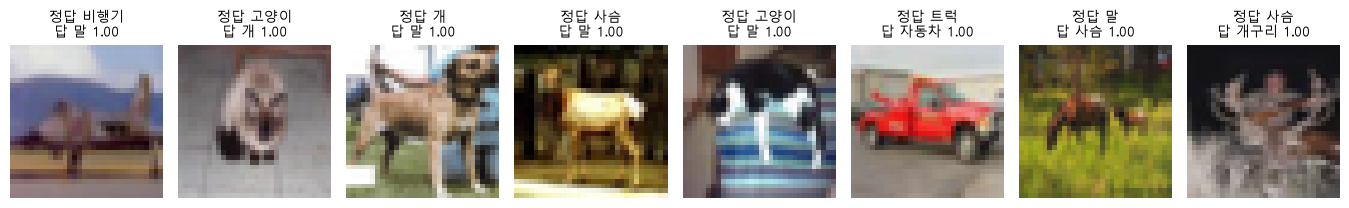

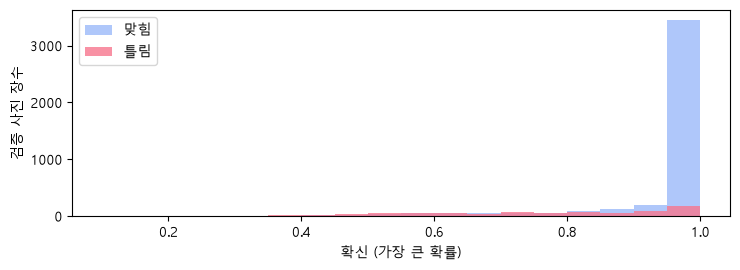

틀린 검증 사진 782장 · 그중 확신 0.9 이상 261장
맞힌 사진 4218장 · 틀린 사진 782장


In [5]:
# 왜 · 틀린 사진 가운데 확신이 높은 것부터 찾아 위험한 오류를 먼저 보기 위해
wrong = (pred != y_val).nonzero().flatten()                             # 틀린 검증 사진 번호
top = wrong[conf[wrong].argsort(descending=True)][:8]                   # 확신이 큰 순서로 8장
show([x_val[i] for i in top],                                           # 가장 자신 있게 틀린 8장
     [f"정답 {KO[CLASSES[y_val[i]]]}\n답 {KO[CLASSES[pred[i]]]} {conf[i]:.2f}" for i in top],
     cols=8, size=1.7)
ok = pred == y_val                                                      # 맞힌 사진 표시
fig, ax = plt.subplots(figsize=(7.5, 2.8))                              # 확신 분포
bins = np.linspace(0.1, 1.0, 19)                                        # 0.05 폭 구간
ax.hist(conf[ok].cpu().numpy(), bins=bins, alpha=0.6, label="맞힘", color="#7aa2f7")  # 파랑
ax.hist(conf[~ok].cpu().numpy(), bins=bins, alpha=0.8, label="틀림", color="#f7768e")  # 빨강
ax.set_xlabel("확신 (가장 큰 확률)")                                    # 가로축
ax.set_ylabel("검증 사진 장수")                                         # 세로축
ax.legend()                                                             # 범례
fig.tight_layout()                                                      # 정리
plt.show()                                                              # 그리기
n_hi = int((conf[wrong] >= 0.9).sum())                                  # 0.9 이상 확신하고 틀린 수
print(f"틀린 검증 사진 {len(wrong)}장 · 그중 확신 0.9 이상 {n_hi}장")   # 결과
print(f"맞힌 사진 {int(ok.sum())}장 · 틀린 사진 {int((~ok).sum())}장")  # 두 묶음 크기

**결과** · 예측 정답은 782장 중 261장 — 셋 중 하나꼴

- `틀린 검증 사진 782장 · 그중 확신 0.9 이상 261장` — 틀린 답도 강하게 믿는 경우가 흔함
- `맞힌 사진 4218장 · 틀린 사진 782장` — 맞힌 쪽이 훨씬 많음 → 두 분포는 높이가 아니라 모양으로 비교
- 그림 · 파랑(맞힘)은 오른쪽 끝에 몰림 · 빨강(틀림)은 넓게 퍼졌지만 오른쪽 끝 막대도 높음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정확도</td><td>맞힌 비율 숫자 하나</td><td>전체 성적을 한 줄로 말할 때</td></tr>
<tr><td>확신 (가장 큰 확률)</td><td>사진마다 모델의 자신감</td><td>망설인 사진 · 과신한 사진을 찾을 때</td></tr>
<tr><td>확신이 높은 틀림 목록</td><td>가장 위험한 실수</td><td>오류 분석을 시작할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 확신이 높다고 맞은 것이 아님 · 확률로 걸러 낼 수 없는 틀림이 있음
> - 앞의 여덟 장은 드문 예외가 아니라 빨강 오른쪽 끝 막대에서 꺼낸 사진

> ✅ **한 줄 정리** · 틀린 사진도 확신이 1에 가까울 수 있어서, 정확도와 확신만으로는 어떻게 틀렸는지 알 수 없다.

**딥러닝 코드에서는**

- `conf, pred = probs.max(1)` — 확신과 답을 한 번에
- 실제 서비스에서는 확신 기준으로 사람에게 넘기기도 함 → 과신이 있으면 그 기준이 깨짐

### 1-3. `A` 열 가지 확률 · 점수(logit)에서 확률로 · `softmax` · `logit` <sub>1일차 1장</sub>

> 🎯 **모델의 확률은 어디서 나오고, 확신이란 정확히 무엇인가?**

💡 **쉽게 말하면**

- 모델은 종류마다 **점수**(logit)를 내고, softmax가 그 점수를 **합이 1인 확률**로 바꿈.
- 가장 큰 확률이 모델의 답이고, 그 값이 확신.

**실행 흐름**

1. 가장 자신 있게 틀린 사진의 열 가지 확률 막대
2. softmax 앞 점수(logit) 다시 계산
3. 큰 세 종류의 점수 · 확률
4. 합 비교 · 정답 쪽 확률

**먼저 예측** · 점수 열 개의 합과 확률 열 개의 합은 각각 얼마일까? — 답은 코드 실행 결과 아래에

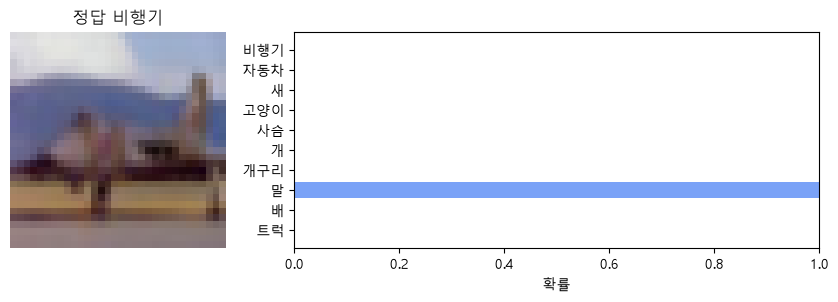

종류      점수(logit)    확률
말           11.73      1.000
비행기         -1.09      0.000
배           -1.31      0.000
점수 합 -80.83 · 확률 합 1.00
정답 비행기 쪽 확률 0.000


In [6]:
# 왜 · 가장 자신 있게 틀린 사진의 열 가지 확률을 그림으로 확인하기 위해
i0 = int(top[0])                                                    # 가장 자신 있게 틀린 사진
# 왼쪽 사진 · 오른쪽 확률
fig, ax = plt.subplots(1, 2, figsize=(8.5, 2.9), gridspec_kw={"width_ratios": [1, 2.4]})
# 사진 (칸이 보이게)
ax[0].imshow((x_val[i0].float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[0].set_title(f"정답 {KO[CLASSES[y_val[i0]]]}")                   # 사진 위 정답
ax[0].axis("off")                                                   # 눈금 끄기
ko_names = [KO[c] for c in CLASSES]                                 # 막대 이름
ax[1].barh(ko_names[::-1], p_val[i0].flip(0).cpu().numpy(), color="#7aa2f7")  # 열 가지 확률
ax[1].set_xlim(0, 1)                                                # 가로축 0~1 고정
ax[1].set_xlabel("확률")                                            # 축 이름
fig.tight_layout()                                                  # 정리
plt.show()                                                          # 그리기
with torch.no_grad():                                               # 점수(logit)만 다시 계산
    logit = model(to_input(x_val[i0:i0 + 1]))[0]                    # softmax 앞 점수 10개
prob = logit.softmax(0)                                             # 점수 → 확률
print("종류      점수(logit)    확률")                              # 표 머리줄
for k in prob.argsort(descending=True)[:3]:                         # 확률이 큰 세 종류
    print(f"{KO[CLASSES[k]]:6s} {logit[k]:10.2f} {prob[k]:10.3f}")  # 점수와 확률
print(f"점수 합 {logit.sum():.2f} · 확률 합 {prob.sum():.2f}")      # 확률만 합이 1
print(f"정답 {KO[CLASSES[y_val[i0]]]} 쪽 확률 {p_val[i0, y_val[i0]]:.3f}")  # 정답에 준 확률

**결과** · 예측 정답은 점수 합은 아무 값(-80.83) · 확률 합은 늘 1.00

- `말 11.73 1.000` — 가장 큰 점수가 가장 큰 확률 · 순위는 그대로
- `점수 합 -80.83 · 확률 합 1.00` — 점수는 범위 제한이 없고 확률만 합이 1
- `정답 비행기 쪽 확률 0.000` — 정답은 거의 0 · 틀린 답을 거의 확실하게 믿음
- 그림 · 오른쪽 막대 열 개를 더하면 1 · 가장 긴 막대 = 답 · 그 길이 = 확신

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>점수 (logit)</td><td>범위 없음 · 모델의 마지막 출력</td><td>손실 계산에 넣을 때</td></tr>
<tr><td>softmax 확률</td><td>0 ~ 1 · 합 1 · 순위 같음</td><td>사람이 읽거나 확신을 볼 때</td></tr>
<tr><td><code>CrossEntropyLoss</code></td><td>logit을 받아 안에서 softmax까지</td><td>학습 (모델 끝에 softmax 층 없음)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 모델 끝에 softmax를 넣고 CrossEntropyLoss를 쓰면 softmax가 두 번 됨
> - 확률은 모델이 계산한 값 · 정답 보증이 아님

> ✅ **한 줄 정리** · 모델은 점수(logit)를 내고 softmax가 합이 1인 확률로 바꾸며, 가장 큰 확률이 확신이다.

**딥러닝 코드에서는**

- `logits = model(x); loss = F.cross_entropy(logits, y)` — 손실에는 점수를 그대로
- `probs = logits.softmax(1)` — 보여 줄 때만 확률로

### 1-4. `B` 점수 차이가 커지면 확률은 한쪽으로 몰림 · `softmax(0)` · `np.e` <sub>1일차 1장</sub>

> 🎯 **순위는 같은데 점수 간격만 커지면 확률은 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- softmax는 점수가 1 커질 때마다 몫이 **약 2.7배**씩 불어남.
- 그래서 간격이 조금만 벌어져도 한쪽으로 급하게 쏠림.

**실행 흐름**

1. 순위는 같고 간격만 다른 점수 세 묶음 정하기
2. 각각 softmax 막대 그리기
3. 가장 큰 확률 출력

**먼저 예측** · 점수 10 · 5 · 0이면 가장 큰 확률은? — 답은 코드 실행 결과 아래에

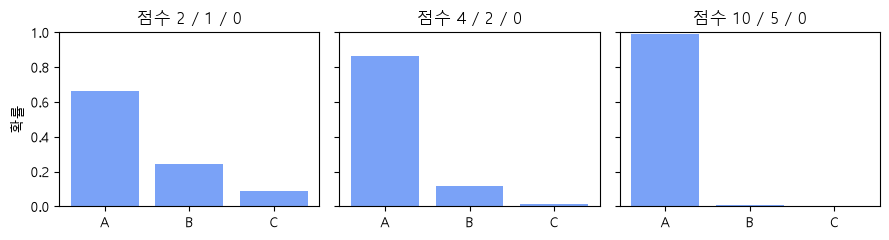

점수 2 · 1 · 0 → 가장 큰 확률 0.67
점수 4 · 2 · 0 → 가장 큰 확률 0.87
점수 10 · 5 · 0 → 가장 큰 확률 0.99
e^1 = 2.72 — 점수가 1 커질 때마다 몫이 약 2.7배


In [7]:
# 왜 · 점수 차이가 커질수록 softmax 확률이 한쪽으로 몰리는 것을 숫자로 보기 위해
scores = torch.tensor([[2.0, 1.0, 0.0], [4.0, 2.0, 0.0], [10.0, 5.0, 0.0]])  # 순위 같고 간격만 커짐
fig, ax = plt.subplots(1, 3, figsize=(9, 2.5), sharey=True)        # 세 경우 나란히
for a, s in zip(ax, scores):                                       # 경우마다
    a.bar(["A", "B", "C"], s.softmax(0).numpy(), color="#7aa2f7")  # 확률 막대
    a.set_ylim(0, 1)                                               # 세로축 0~1 고정
    a.set_title(f"점수 {s[0]:.0f} / {s[1]:.0f} / {s[2]:.0f}")      # 제목 = 점수
ax[0].set_ylabel("확률")                                           # 축 이름
fig.tight_layout()                                                 # 정리
plt.show()                                                         # 그리기
for s in scores:                                                   # 경우마다 가장 큰 확률
    print(f"점수 {s[0]:.0f} · {s[1]:.0f} · "                       # 간격이 클수록 1에 가까움
          f"{s[2]:.0f} → 가장 큰 확률 {s.softmax(0).max():.2f}")
print(f"e^1 = {np.e:.2f} — 점수가 1 커질 때마다 몫이 약 2.7배")    # 쏠림의 이유

**결과** · 예측 정답은 0.99 — 거의 한 종류가 독차지

- `점수 2 · 1 · 0 → 가장 큰 확률 0.67` — 간격 1 · 아직 나눠 가짐
- `점수 4 · 2 · 0 → 가장 큰 확률 0.87` — 간격 두 배
- `점수 10 · 5 · 0 → 가장 큰 확률 0.99` — 간격 다섯 배 · 거의 1
- `e^1 = 2.72` — 점수 1 차이 = 몫 약 2.7배 → 쏠림의 이유

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>점수 간격이 작음</td><td>확률이 고르게 나뉨</td><td>망설이는 사진</td></tr>
<tr><td>점수 간격이 큼</td><td>확률이 1에 몰림</td><td>확신이 높은 사진</td></tr>
<tr><td>학습이 길어짐</td><td>점수 간격이 계속 벌어지기 쉬움</td><td>과신이 생기는 이유 (4장)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점수는 직접 정한 값 · 사진에서 나온 값이 아님
> - 확신 0.99는 점수가 크게 벌어졌다는 뜻일 뿐 정답 보장이 아님

> ✅ **한 줄 정리** · softmax는 점수 간격이 커질수록 확률을 한 종류로 몰아주므로, 확신이 높다는 것은 점수 하나가 훨씬 크다는 뜻이다.

**딥러닝 코드에서는**

- `F.softmax(logits / T, dim=1)` — 온도 T로 쏠림을 조절하는 기법이 있음 (보정 · 지식 증류)
- 확신을 믿기 전에 신뢰도 그림(8장)으로 확인

---
## 2. 모델 전에 자료부터

> **이 장의 흐름**
>
> - 종류별 장수와 기준선 → 한 장의 모양과 값
> - 그다음 입력 약속을 어기면 → 사진 보기 → 학습 · 검증 · 테스트의 역할

<img src="images/pfcnn1_ch2.png" alt="학습 · 검증 · 테스트의 역할" width="577">

**파이프라인 위치** · ② 데이터 확인 (모델 전에)

### 2-1. `A` 종류별 장수 · 기준선 · 한 장의 모양과 값 · `bincount` · `uint8` <sub>1일차 2장</sub>

> 🎯 **종류별 장수가 고른가, 아무것도 배우지 않은 기준선은 몇 %인가?**

💡 **쉽게 말하면**

- 기준선 = **가장 많은 종류만 계속 답할 때**의 정확도.
- 정확도는 늘 기준선보다 얼마나 높은가로 읽음.

**실행 흐름**

1. 분할별 · 종류별 장수 표
2. 사진 모양 · 값 범위 · 자료형
3. 가장 많은 종류만 답할 때 검증 정확도
4. 한 장의 칸 값 · 채널 평균 · 모델에 들어가는 값

**먼저 예측** · 종류가 고르면 기준선은 몇 %쯤일까? — 답은 코드 실행 결과 아래에

In [8]:
# 왜 · 종류별 장수를 먼저 확인해 정확도의 기준선을 정하기 위해
print(f"{'종류':6s} {'학습':>6s} {'검증':>5s} {'테스트':>5s}")       # 표 머리줄
for k, name in enumerate(CLASSES):                                   # 종류마다 장수
    n_tr, n_va = int((y_train == k).sum()), int((y_val == k).sum())  # 학습 · 검증
    print(f"{KO[name]:6s} {n_tr:6d} {n_va:5d} {int((y_test == k).sum()):5d}")  # 테스트까지
# 모양 · 범위 · 자료형
print(f"사진 모양 {tuple(x_train.shape[1:])} · 값 범위 {int(x_train.min())}~{int(x_train.max())}"
      f" · 자료형 {x_train.dtype}")
TOP = int(torch.bincount(y_train).argmax())                          # 학습에서 가장 많은 종류
base_acc = (y_val == TOP).float().mean().item() * 100                # 그 종류만 답할 때
print(f"가장 많은 종류 {KO[CLASSES[TOP]]}만 답할 때 검증 정확도 {base_acc:.1f}% (기준선)")  # 기준선
one = x_train[int((y_train == 0).nonzero()[0])]                      # 학습 사진 중 첫 번째 비행기
print(f"사진 한 장 {tuple(one.shape)} · "                            # 한 칸 = 숫자 세 개
      f"왼쪽 위 한 칸 R, G, B = {one[:, 0, 0].tolist()}")
r_, g_, b_ = (one[c].float().mean().item() for c in range(3))        # 채널별 평균
print(f"채널별 평균 — R {r_:.0f} · G {g_:.0f} · B {b_:.0f}")         # 어떤 색이 많은가
x_in = to_input(one)                                                 # 학습 때의 약속으로 변환
# 변환 뒤 범위
print(f"모델에 들어가는 값 {x_in.min():.1f} ~ {x_in.max():.1f} — (값 / 255 - 0.5) / 0.25")

종류         학습    검증   테스트
비행기      4507   493  1000
자동차      4512   488  1000
새        4521   479  1000
고양이      4481   519  1000
사슴       4525   475  1000
개        4471   529  1000
개구리      4512   488  1000
말        4515   485  1000
배        4468   532  1000
트럭       4488   512  1000
사진 모양 (3, 32, 32) · 값 범위 0~255 · 자료형 torch.uint8
가장 많은 종류 사슴만 답할 때 검증 정확도 9.5% (기준선)
사진 한 장 (3, 32, 32) · 왼쪽 위 한 칸 R, G, B = [202, 204, 199]
채널별 평균 — R 148 · G 149 · B 149
모델에 들어가는 값 -2.0 ~ 2.0 — (값 / 255 - 0.5) / 0.25


**결과** · 예측 정답은 열 장 중 한 장쯤 — 9.5%

- `비행기 4507 493 1000` — 학습 · 검증 · 테스트 장수 · 종류마다 비슷함
- `사진 모양 (3, 32, 32) · 값 범위 0~255 · 자료형 torch.uint8` — 채널이 앞 · 0 ~ 255 정수
- `가장 많은 종류 사슴만 답할 때 검증 정확도 9.5% (기준선)` — 종류가 고르니 기준선은 약 10%
- `왼쪽 위 한 칸 R, G, B = [202, 204, 199]` — 한 칸 = 숫자 세 개
- `채널별 평균 — R 148 · G 149 · B 149` — 어떤 색이 많은가
- `모델에 들어가는 값 -2.0 ~ 2.0` — (값 / 255 - 0.5) / 0.25 · 가운데를 0에 두고 폭을 맞춤

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>종류별 장수</td><td>고른지 치우쳤는지</td><td>기준선 · 드문 종류 확인</td></tr>
<tr><td>값 범위 · 자료형</td><td>uint8 0 ~ 255인지 float 0 ~ 1인지</td><td>입력 약속을 정할 때</td></tr>
<tr><td>분할별 장수</td><td>학습 · 검증 · 테스트가 섞이지 않았는지</td><td>점수를 믿기 전에</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 자료 문제를 학습 뒤에 찾으면 원인을 헤맴 · 지금 확인은 몇 초
> - 이름이 같은 CIFAR-10이어도 나누는 방식이 다르면 다시 확인

> ✅ **한 줄 정리** · 학습 전에 종류별 장수 · 값 범위 · 기준선을 확인하고, 정확도는 기준선과 비교해 읽는다.

**딥러닝 코드에서는**

- `torch.bincount(labels)` — 종류별 장수 한 줄
- 불균형 데이터면 기준선이 높음 → 정확도 90%도 아무것도 안 배운 것일 수 있음

### 2-2. `A` 입력 약속을 어기면 · `to_input` · `x.float() / 255` <sub>1일차 2장</sub>

> 🎯 **모델은 그대로인데 넣는 값의 처리만 다르면 정확도는 어떻게 되는가?**

💡 **쉽게 말하면**

- 모델은 학습 때 본 **값의 범위**에 익숙해짐.
- 약속과 다른 값을 넣으면 오류 없이 엉뚱한 답을 냄.

**실행 흐름**

1. 같은 검증 사진 1000장
2. 0~255 그대로 · 255로만 나눔 · 학습 때 약속 셋으로 넣기
3. 정확도 비교

**먼저 예측** · 255로만 나누면 정확도는 얼마나 떨어질까? — 답은 코드 실행 결과 아래에

In [9]:
model.eval()                                                            # 평가 모드
# 왜 · 입력 약속을 어겼을 때 정확도가 어떻게 무너지는지 같은 1000장으로 비교하기 위해
xv, yv = x_val[:1000], y_val[:1000]                                     # 같은 검증 사진 1000장
with torch.no_grad():                                                   # 넣는 값만 셋으로 다르게
    raw = model(xv.float()).argmax(1)                                   # 0~255 그대로
    only255 = model(xv.float() / 255).argmax(1)                         # 255로만 나눔
    right = model(to_input(xv)).argmax(1)                               # 학습 때와 같은 약속
# 세 가지 결과
for name, p in (("0~255 그대로", raw), ("255로만 나눔", only255), ("같은 약속", right)):
    print(f"{name:10s} 정확도 {(p == yv).float().mean() * 100:5.1f}%")  # 오류 메시지는 없음

0~255 그대로  정확도  26.2%
255로만 나눔   정확도  29.8%
같은 약속      정확도  84.6%


**결과** · 예측 정답은 84.6% → 29.8% — 오류 메시지 없이 무너짐

- `0~255 그대로 정확도 26.2%` — 흰색보다 훨씬 밝은, 처음 보는 값
- `255로만 나눔 정확도 29.8%` — 0 ~ 1 · 모델 눈에는 어두운 칸이 없는 뿌연 사진
- `같은 약속 정확도 84.6%` — 학습 때와 같은 변환을 해야 제 실력

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>학습 때 약속 (<code>to_input</code>)</td><td>(x / 255 - 0.5) / 0.25</td><td>학습 · 평가 · 예측 모두</td></tr>
<tr><td>255로만 나눔</td><td>0 ~ 1</td><td>약속이 원래 0 ~ 1인 모델일 때만</td></tr>
<tr><td>0 ~ 255 그대로</td><td>변환 없음</td><td>거의 없음 (실수)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 모양이 같아 코드는 잘 돎 · 점수가 이상하게 낮으면 입력 약속부터 확인
> - 평가 · 예측 코드에도 같은 변환 · `predict` 안에서 `to_input`을 부름

> ✅ **한 줄 정리** · 입력 약속을 어기면 같은 모델이 오류 없이 무너지므로, 평가와 예측에도 학습 때와 같은 변환을 넣는다.

**딥러닝 코드에서는**

- `transforms.Normalize(mean, std)` — 학습 · 검증 transform에 같은 값
- 빌려 온 모델은 그 모델의 약속을 따름 (`weights.transforms()` · 13장)

### 2-3. `B` 종류별로 한 장씩 · 네 장씩 · `nonzero()` · `show` <sub>1일차 2장</sub>

> 🎯 **사진을 직접 보면 모델이 배워야 할 것과 못 본 모습이 무엇인지 보이는가?**

💡 **쉽게 말하면**

- 같은 종류도 자세 · 크기 · 배경 · 색이 제각각.
- 그래도 대부분 대상이 가운데에 적당한 크기로 찍힘.

**실행 흐름**

1. 종류마다 첫 장 하나씩
2. 종류마다 네 장 · 열 하나 = 종류 하나

**먼저 예측** · 크게 기울거나 구석에 작게 찍힌 사진은 많을까? — 답은 코드 실행 결과 아래에

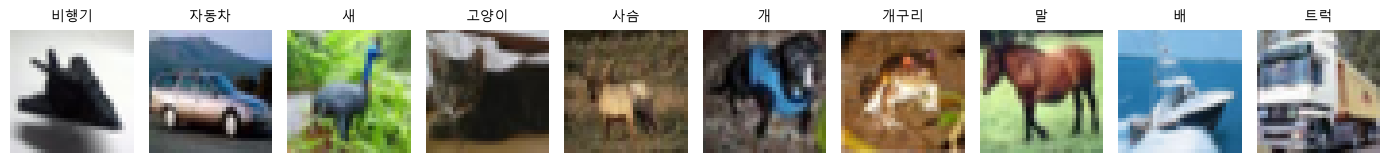

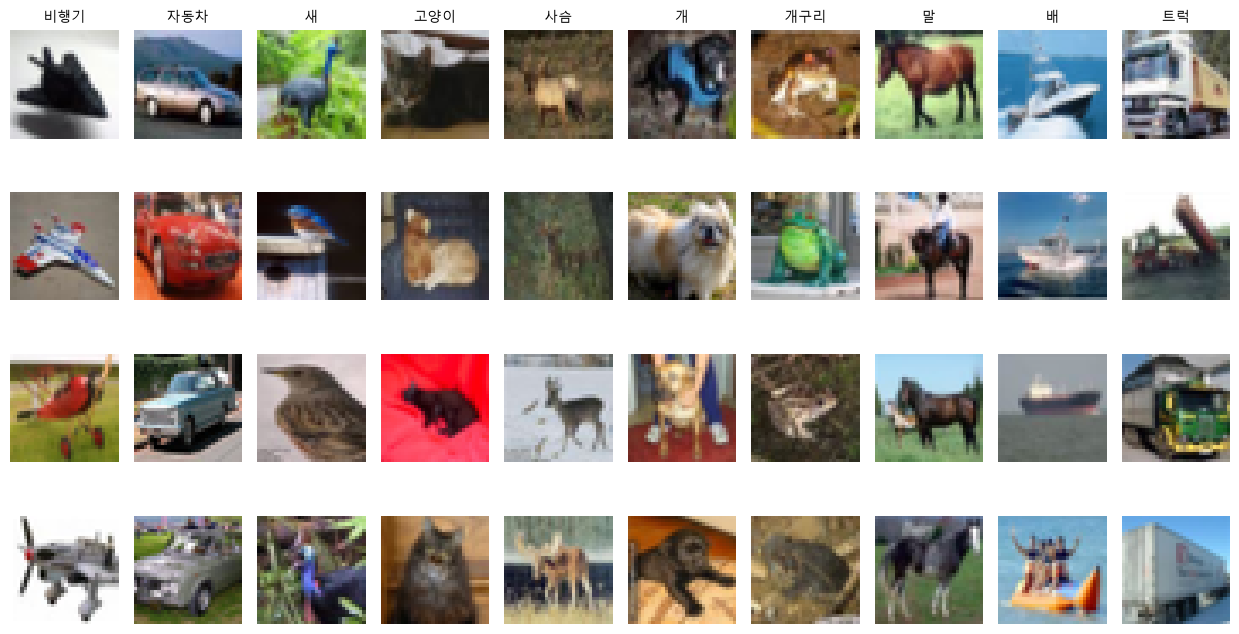

In [10]:
# 왜 · 종류마다 실제 사진을 눈으로 보고 데이터의 생김새를 이해하기 위해
first_of = [int((y_train == k).nonzero()[0]) for k in range(len(CLASSES))]  # 종류마다 첫 장
show([x_train[i] for i in first_of], [KO[c] for c in CLASSES], cols=10, size=1.4)  # 한 장씩
cols = []                                                                   # 종류마다 앞 네 장
for k in range(len(CLASSES)):                                               # 종류마다
    cols += [int(i) for i in (y_train == k).nonzero().flatten()[:4]]        # 네 장 번호
order = [cols[k * 4 + r] for r in range(4) for k in range(len(CLASSES))]    # 줄마다 종류 순서대로
titles = [KO[CLASSES[y_train[i]]] if r == 0 else "" for r in range(4)       # 첫 줄에만 이름
          for i in order[r * 10:(r + 1) * 10]]
show([x_train[i] for i in order], titles, cols=10, size=1.25)               # 종류마다 네 장

**결과** · 예측 정답은 드묾 — 사람이 찍고 골라 모은 사진

- 첫 그림 · 32×32를 칸이 보이게 키움 · 흐릿한 것은 원래 해상도가 32칸이라서
- 둘째 그림 · 같은 종류도 모습이 다양 · 모델이 배울 것은 그 속의 공통점

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>한 장씩 보기</td><td>종류 이름과 모습 짝 맞추기</td><td>데이터를 처음 받았을 때</td></tr>
<tr><td>종류마다 여러 장</td><td>같은 종류 안의 다양함</td><td>모델이 배울 공통점을 짐작할 때</td></tr>
<tr><td>전체 품질 검사</td><td>모든 사진 확인</td><td>표본 관찰로는 부족할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 열 장의 표본은 방향을 잡는 관찰 · 전체 품질 검사가 아님
> - 모델이 고른 공통점이 사람과 같다는 보장은 없음 (예: 배 대신 파란 물 배경)

> ✅ **한 줄 정리** · 사진을 직접 보면 대부분 가운데 · 반듯한 모습이라, 기울거나 밀린 사진은 모델이 연습 때 거의 못 본 문제다.

**딥러닝 코드에서는**

- `make_grid(images)` — 학습 전 한 묶음을 그려 보는 습관
- 증강을 고를 때도 이 관찰이 근거 (7장)

### 2-4. `A` 학습 · 검증 · 테스트의 역할 · 거의 같은 사진 · `torch.roll` · `TF.resize` <sub>1일차 2장</sub>

> 🎯 **세 묶음은 각각 무엇에 쓰고, 왜 거의 같은 사진까지 빼야 하는가?**

💡 **쉽게 말하면**

- 학습 = **문제집** · 검증 = **모의고사** · 테스트 = **실제 시험**.
- 같은 사진이 두 묶음에 있으면 시험 문제를 미리 본 셈.

**실행 흐름**

1. 학습 사진 한 장의 복사본 둘 만들기 (한 칸 밀기 · 조금 잘라 키우기)
2. 픽셀이 완전히 같은 칸 비율
3. 평균 차이

**먼저 예측** · 한 칸만 민 복사본은 픽셀이 몇 % 같을까? — 답은 코드 실행 결과 아래에

In [11]:
# 왜 · 한 칸만 옮겨도 숫자가 크게 달라지는데 사람에겐 같은 사진이라는 점을 확인하기 위해
a = x_train[0].float()                                           # 학습 사진 한 장
moved = torch.roll(a, shifts=1, dims=2)  # 한 칸만 옆으로 민 복사본 (거의 같은 사진)
cropped = TF.resize(a[:, 1:31, 1:31], [32, 32], antialias=True)  # 가장자리 1칸 잘라 다시 키움
for name, b in (("한 칸 민 사진", moved), ("조금 잘라 키운 사진", cropped)):  # 두 복사본
    same = (a == b.round()).all(0).float().mean().item() * 100   # 픽셀이 완전히 같은 칸 비율
    diff = (a - b).abs().mean().item()                           # 평균 차이 (0~255)
    print(f"{name:10s} — 완전히 같은 칸 {same:4.1f}% · 평균 차이 {diff:4.1f}")  # 결과
print("픽셀 완전 일치 검사로는 '거의 같은 사진'을 못 찾음 → 분할 전에 따로 찾아 빼야 함")  # 결론

한 칸 민 사진   — 완전히 같은 칸  0.0% · 평균 차이 16.3
조금 잘라 키운 사진 — 완전히 같은 칸  0.3% · 평균 차이 12.9
픽셀 완전 일치 검사로는 '거의 같은 사진'을 못 찾음 → 분할 전에 따로 찾아 빼야 함


**결과** · 예측 정답은 0% — 눈에는 같은 사진인데 픽셀은 거의 다 다름

- `한 칸 민 사진 — 완전히 같은 칸 0.0% · 평균 차이 16.3` — 한 칸만 밀어도 같은 칸이 없음
- `조금 잘라 키운 사진 — 완전히 같은 칸 0.3% · 평균 차이 12.9` — 크기만 바꿔도 거의 다 다름
- `픽셀 완전 일치 검사로는 '거의 같은 사진'을 못 찾음` — 분할 전에 비슷한 사진을 따로 찾아 빼야 함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>학습</td><td>연습 · 모델이 숫자를 고침</td><td>학습 루프</td></tr>
<tr><td>검증</td><td>선택 · 모델을 고르는 시험</td><td>에폭 · 조건 고르기 · 오류 진단</td></tr>
<tr><td>테스트</td><td>마지막 확인 · 한 번만</td><td>고른 뒤 실력 보고</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 테스트를 보고 무언가를 고르면 테스트가 더 이상 처음 보는 사진이 아님
> - 파일 이름 · 픽셀 일치 검사로는 조금 잘린 복사본을 못 찾음 · 원본 강의는 이런 사진을 검증 40장 · 테스트 101장 뺐음

> ✅ **한 줄 정리** · 학습은 연습 · 검증은 선택 · 테스트는 마지막 확인이며, 거의 같은 사진이 묶음 사이에 남으면 테스트 점수가 부풀려진다.

**딥러닝 코드에서는**

- `random_split` 전에 같은 원본에서 나온 사진을 한 묶음으로 (사람 · 환자 · 영상 단위)
- 증강본은 반드시 나눈 뒤 학습 쪽에서만 만듦

---
## 3. 조금 바꾸면 답도 바뀔까

> **이 장의 흐름**
>
> - 여섯 가지 변화로 한 장 · 맞힌 사진 전체를 흔들기
> - 그다음 종류별 · 바뀐 답 · 회전 각도 · 세 칸으로 정리

<img src="images/pfcnn1_ch3.png" alt="흔들기 실험의 틀" width="584">

**파이프라인 위치** · ③ 진단 1 — 입력만 조금 바꾸기 (모델 고정)

### 3-1. `A` 여섯 가지 변화 · 한 장 흔들기 · `TF.affine` · `TF.rotate` · `TF.center_crop` <sub>1일차 3장</sub>

> 🎯 **모델은 그대로 두고 입력만 조금 바꾸면 답이 바뀌는가?**

💡 **쉽게 말하면**

- 흔들기 = **정답은 두고 모습만 조금** 바꿔 넣는 실험.
- 모델까지 바꾸면 답이 바뀐 이유를 가를 수 없어서 모델은 고정.

**실행 흐름**

1. 여섯 변화 함수 `shake` 만들기
2. 0.9 이상으로 맞힌 사진마다 바뀐 횟수 세기
3. 네 개 이상 바뀐 사진 중 확신이 가장 높은 한 장
4. 원본 + 여섯 변화의 답 · 확률

**먼저 예측** · 확신 1.00으로 맞힌 사진도 여섯 변화 중 몇 개에서 답이 바뀔 수 있을까? — 답은 코드 실행 결과 아래에

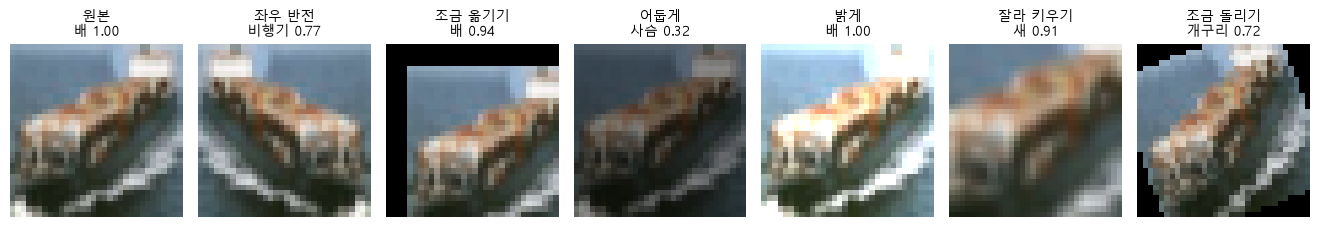

0.9 이상으로 맞힌 검증 사진 3642장 · 넷 이상 바뀐 사진 117장
고른 한 장 — 정답 배 · 원본 확신 1.00 · 여섯 중 4개에서 답이 바뀜


In [12]:
# 왜 · 흔들어 볼 변화 여섯 가지를 한곳에 정해 모든 실험에 같게 쓰기 위해
KINDS = ["hflip", "shift", "dark", "bright", "crop", "rotate"]            # 여섯 가지 변화
KIND_KO = dict(zip(KINDS, ["좌우 반전", "조금 옮기기", "어둡게", "밝게",  # 한글 이름
                           "잘라 키우기", "조금 돌리기"]))


# 왜 · 변화 종류만 바꾸면 같은 함수로 사진을 흔들 수 있게 하기 위해
def shake(x, kind):                      # 사진 묶음에 변화 하나 (정답은 그대로)
    x = x.float()                        # 계산용 실수
    if kind == "hflip":                  # 좌우 반전
        return x.flip(-1)                # 가로축 뒤집기
    if kind == "shift":                  # 4칸씩 옮기기 · 빈 자리는 검정
        # 아래 · 오른쪽으로 4칸
        return TF.affine(x, angle=0.0, translate=[4, 4], scale=1.0, shear=[0.0, 0.0])
    if kind == "dark":                   # 어둡게
        return (x * 0.55).clamp(0, 255)  # 값을 0.55배
    if kind == "bright":                 # 밝게
        return (x * 1.5).clamp(0, 255)   # 1.5배 · 255에서 자름
    if kind == "crop":                   # 가운데 22칸만 남겨 다시 32칸으로
        # 가운데 22칸 → 32칸
        return TF.resize(TF.center_crop(x, [22, 22]), [32, 32], antialias=True)
    if kind == "rotate":                 # 20도 돌리기 · 빈 자리는 검정
        return TF.rotate(x, 20.0)        # 반시계 20도
    raise ValueError(kind)               # 모르는 이름이면 오류


# 왜 · 확신 높게 맞힌 사진도 작은 변화에 답이 바뀌는지 확인하기 위해
ok_conf = ((pred == y_val) & (conf >= 0.9)).nonzero().flatten()  # 0.9 이상으로 맞힌 사진
flips = torch.zeros(len(ok_conf), dtype=torch.long, device=DEV)  # 사진마다 바뀐 횟수
for k in KINDS:                                                  # 변화마다
    # 바뀐 사진에 1씩
    flips += (predict(model, shake(x_val[ok_conf], k)).argmax(1) != pred[ok_conf]).long()
score = conf[ok_conf] + (flips >= 4).float() * 10                # 네 개 이상 바뀐 사진 중 확신 최고
ONE = int(ok_conf[score.argmax()])                               # 극단적인 한 장
imgs = [x_val[ONE].float()] + [shake(x_val[ONE:ONE + 1], k)[0] for k in KINDS]  # 원본 + 6
p_one = predict(model, torch.stack(imgs))                        # 일곱 장의 확률
show(imgs, [f"{n}\n{KO[CLASSES[p.argmax()]]} {p.max():.2f}"      # 칸 제목: 변화 · 답 · 확률
            for n, p in zip(["원본"] + [KIND_KO[k] for k in KINDS], p_one)])
print(f"0.9 이상으로 맞힌 검증 사진 {len(ok_conf)}장 · "         # 후보 수
      f"넷 이상 바뀐 사진 {int((flips >= 4).sum())}장")
print(f"고른 한 장 — 정답 {KO[CLASSES[y_val[ONE]]]} · 원본 확신 {conf[ONE]:.2f}"  # 고른 사진 요약
      f" · 여섯 중 {int(flips[score.argmax()])}개에서 답이 바뀜")

**결과** · 예측 정답은 넷 — 고른 배 사진은 여섯 중 4개에서 답이 바뀜

- `0.9 이상으로 맞힌 검증 사진 3642장 · 넷 이상 바뀐 사진 117장` — 후보 · 이 중 극단적인 한 장을 고름
- `고른 한 장 — 정답 배 · 원본 확신 1.00 · 여섯 중 4개에서 답이 바뀜` — 강하게 믿던 사진도 흔들림
- 그림 · 칸 제목 둘째 줄 = 모델의 답 · 확률 · 원본과 다르면 흔들림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>방향 (좌우 반전 · 돌리기)</td><td>무늬의 방향이 바뀜</td><td>대상이 기울어 찍힐 때</td></tr>
<tr><td>자리 (옮기기)</td><td>대상이 가운데에서 벗어남 · 빈 자리 검정</td><td>구도가 다를 때</td></tr>
<tr><td>값 (어둡게 · 밝게) · 크기 (잘라 키우기)</td><td>칸 값 · 윤곽 일부가 바뀜</td><td>조명 · 거리가 다를 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 일부러 많이 흔들린 사진 중 고른 극단적 한 장 · 한 장으로 약하다고 말할 수 없음
> - 옮기거나 돌려서 생긴 빈 자리는 검정 · 이것도 낯선 모습의 일부

> ✅ **한 줄 정리** · 흔들기는 모델을 고정하고 입력만 바꾸는 실험이며, 확신 1.00으로 맞힌 사진도 작은 변화에 답이 바뀔 수 있다.

**딥러닝 코드에서는**

- `TF.rotate · TF.affine · TF.center_crop` — 텐서 묶음에 바로 쓰는 변환 (`transforms.v2.functional`)
- 배포 전 '흔든 검증 세트'를 따로 만들어 두면 약점을 미리 봄

### 3-2. `A` 맞힌 사진 전체를 흔들면 · 분모와 바뀐 수 · `bar_label` · `any(0)` <sub>1일차 3장</sub>

> 🎯 **맞힌 검증 사진 전체에 같은 변화를 넣으면 변화마다 몇 %나 답이 바뀌는가?**

💡 **쉽게 말하면**

- 분모는 **원본에서 맞힌 사진**으로 통일 · 그래야 막대끼리 견줄 수 있음.
- 원본에서 틀린 사진은 빼 둠 (틀린 답 → 다른 틀린 답은 해석이 어려움).

**실행 흐름**

1. 원본에서 맞힌 사진 고르기
2. 변화마다 답이 바뀌었는지 표시
3. 비율 막대 · 막대 뒤의 표
4. 횟수 합과 사진 수 비교

**먼저 예측** · 여섯 변화 중 가장 많이 흔드는 것은? — 답은 코드 실행 결과 아래에

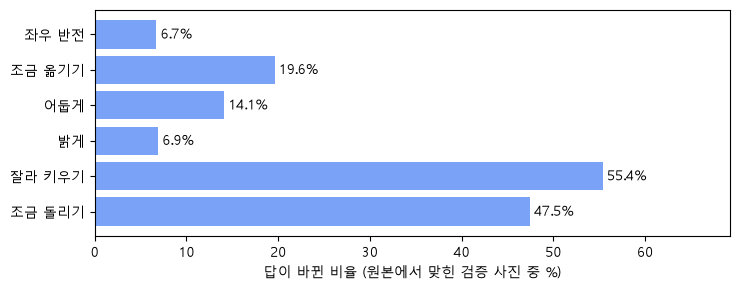

변화           분모     바뀜      비율
좌우 반전     4218    284    6.7%
조금 옮기기    4218    827   19.6%
어둡게       4218    595   14.1%
밝게        4218    292    6.9%
잘라 키우기    4218   2337   55.4%
조금 돌리기    4218   2002   47.5%
여섯 줄 바뀜 합 6337번(횟수) · 하나 이상 바뀐 사진 3267장 (77.5%)


In [13]:
# 왜 · 맞힌 사진만 분모로 삼아 변화 때문에 바뀐 비율을 정확히 재기 위해
correct = (pred == y_val).nonzero().flatten()                   # 분모: 원본에서 맞힌 검증 사진
# 변화마다 답이 바뀌었나
changed = {k: predict(model, shake(x_val[correct], k)).argmax(1) != pred[correct]
           for k in KINDS}
rates = {k: changed[k].float().mean().item() for k in KINDS}    # 변화별 바뀐 비율
fig, ax = plt.subplots(figsize=(7.5, 3.0))                      # 가로 막대
# 변화별 막대
bars = ax.barh([KIND_KO[k] for k in KINDS[::-1]], [rates[k] * 100 for k in KINDS[::-1]],
               color="#7aa2f7")
ax.bar_label(bars, fmt="%.1f%%", padding=3)                     # 막대 끝 숫자
ax.set_xlabel("답이 바뀐 비율 (원본에서 맞힌 검증 사진 중 %)")  # 축 이름
ax.set_xlim(0, max(rates.values()) * 125)                       # 숫자가 들어갈 여백
fig.tight_layout()                                              # 정리
plt.show()                                                      # 그리기
print(f"{'변화':8s} {'분모':>6s} {'바뀜':>6s} {'비율':>7s}")    # 막대 뒤의 표
for k in KINDS:                                                 # 변화마다 한 줄
    n_chg = int(changed[k].sum())                               # 바뀐 수
    # 분모 · 바뀜 · 비율
    print(f"{KIND_KO[k]:7s} {len(correct):6d} {n_chg:6d} {n_chg / len(correct) * 100:6.1f}%")
any_changed = torch.stack([changed[k] for k in KINDS]).any(0)   # 사진마다 하나라도 바뀌었나
total_n = sum(int(changed[k].sum()) for k in KINDS)             # 여섯 줄 바뀜 합 = 횟수
# 횟수 vs 사진 수
print(f"여섯 줄 바뀜 합 {total_n}번(횟수) · 하나 이상 바뀐 사진 {int(any_changed.sum())}장"
      f" ({any_changed.float().mean() * 100:.1f}%)")

**결과** · 예측 정답은 잘라 키우기 55.4% · 다음 돌리기 47.5%

- `좌우 반전 4218 284 6.7%` — 가장 적게 흔들림 · 학습 사진에도 양쪽을 보는 대상이 섞여 있음
- `잘라 키우기 4218 2337 55.4%` — 가장 많이 흔들림 · 윤곽 일부가 사라지고 확대됨
- `조금 돌리기 4218 2002 47.5%` — 방향이 바뀌면 찾던 무늬와 덜 맞음
- `여섯 줄 바뀜 합 6337번(횟수) · 하나 이상 바뀐 사진 3267장 (77.5%)` — 한 장이 두 변화에서 바뀌면 두 번 셈 → 횟수 합 > 사진 수

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>변화별 비율</td><td>분모 = 원본에서 맞힌 사진</td><td>어떤 변화에 약한지</td></tr>
<tr><td>하나 이상 바뀐 사진</td><td>사진마다 한 번만 셈</td><td>전체적으로 얼마나 흔들리는지</td></tr>
<tr><td>바뀐 수의 합</td><td>횟수 · 사진 수 아님</td><td>다음 장의 '바뀐 답' 막대 합과 맞춰 볼 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 여섯 비율을 더하면 하나 이상 바뀐 비율보다 큼 · 사진을 여러 번 셈
> - 정확도는 찍힌 그대로의 모습에서 잰 점수 · 조금 바꿔도 버티는지는 따로 확인

> ✅ **한 줄 정리** · 같은 분모(맞힌 사진)로 변화마다 바뀐 비율을 재면, 잘라 키우기 · 회전처럼 특히 약한 변화가 드러난다.

**딥러닝 코드에서는**

- 견고성(robustness) 평가 — CIFAR-10-C 같은 '흔든 테스트'로 재는 것과 같은 생각
- 비율을 견줄 때는 분모가 같은지부터 확인

### 3-3. `B` 어떤 종류가 잘 흔들리고, 어느 답으로 바뀌었나 · `sorted(key=)` · `dict.get` <sub>1일차 3장</sub>

> 🎯 **흔들림은 종류마다 다르고, 바뀐 답은 특정 종류로 몰리는가?**

💡 **쉽게 말하면**

- 종류마다 버티는 정도가 다름.
- 흔들렸을 때 가는 곳도 몇몇 종류로 몰림.

**실행 흐름**

1. 종류마다 하나 이상 바뀐 비율
2. 바뀐 경우마다 새 답 세기
3. 가장 많은 (원래 → 바뀐 답) 짝

**먼저 예측** · 흔들렸을 때 가장 많이 가는 답은 어떤 종류일까? — 답은 코드 실행 결과 아래에

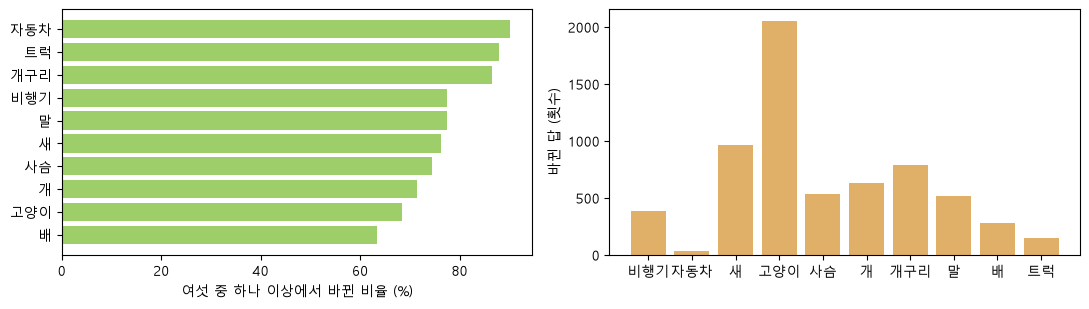

가장 잘 흔들린 종류 자동차 90.1% · 가장 덜 흔들린 종류 배 63.5%
바뀐 답으로 가장 많이 나온 종류 고양이 2056번
가장 많은 바뀜 짝 — 개 → 고양이 414번


In [14]:
# 왜 · 어떤 종류가 잘 흔들리고 어느 답으로 바뀌는지 종류별로 모으기 위해
by_class = {}                                                       # 종류별 하나 이상 바뀐 비율
for k, name in enumerate(CLASSES):                                  # 종류마다
    m = y_val[correct] == k                                         # 그 종류에서 원본을 맞힌 사진
    by_class[name] = any_changed[m].float().mean().item()           # 비율
order = sorted(CLASSES, key=by_class.get)                           # 덜 흔들린 → 잘 흔들린
dest = torch.zeros(len(CLASSES), dtype=torch.long)                  # 바뀐 답 횟수
pairs = {}                                                          # (원래 정답, 바뀐 답) 횟수
for k in KINDS:                                                     # 변화마다
    idx = correct[changed[k]]                                       # 그 변화에서 바뀐 사진
    newp = predict(model, shake(x_val[idx], k)).argmax(1)           # 바뀐 답
    for t, q in zip(y_val[idx].tolist(), newp.tolist()):            # 짝마다 셈
        dest[q] += 1                                                # 바뀐 답 쪽에 1
        pairs[(t, q)] = pairs.get((t, q), 0) + 1                    # 짝에 1
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))                     # 왼쪽 종류별 · 오른쪽 바뀐 답
# 종류별 막대
ax[0].barh([KO[c] for c in order], [by_class[c] * 100 for c in order], color="#9ece6a")
ax[0].set_xlabel("여섯 중 하나 이상에서 바뀐 비율 (%)")             # 축 이름
ax[1].bar([KO[c] for c in CLASSES], dest.numpy(), color="#e0af68")  # 바뀐 답 종류
ax[1].set_ylabel("바뀐 답 (횟수)")                                  # 사진 수가 아님
fig.tight_layout()                                                  # 정리
plt.show()                                                          # 그리기
print(f"가장 잘 흔들린 종류 {KO[order[-1]]} {by_class[order[-1]] * 100:.1f}%"  # 양 끝 종류
      f" · 가장 덜 흔들린 종류 {KO[order[0]]} {by_class[order[0]] * 100:.1f}%")
(t0, q0), n0 = max(pairs.items(), key=lambda kv: kv[1])             # 가장 많은 짝
# 몰리는 답
print(f"바뀐 답으로 가장 많이 나온 종류 {KO[CLASSES[int(dest.argmax())]]} {int(dest.max())}번")
print(f"가장 많은 바뀜 짝 — {KO[CLASSES[t0]]} → {KO[CLASSES[q0]]} {n0}번")  # 몰리는 곳

**결과** · 예측 정답은 고양이 — 바뀐 답 2056번

- `가장 잘 흔들린 종류 자동차 90.1% · 가장 덜 흔들린 종류 배 63.5%` — 종류마다 버티는 정도가 다름
- `바뀐 답으로 가장 많이 나온 종류 고양이 2056번` — 흔들리면 고양이로 몰림 (횟수 · 사진 수 아님)
- `가장 많은 바뀜 짝 — 개 → 고양이 414번` — 비슷한 종류 쪽으로 감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>종류별 흔들림</td><td>분모 = 그 종류에서 맞힌 사진</td><td>약한 종류 찾기</td></tr>
<tr><td>바뀐 답 막대</td><td>가는 곳이 고른지 몰리는지</td><td>모델이 '모를 때 고르는 답' 찾기</td></tr>
<tr><td>바뀜 짝</td><td>원래 → 바뀐 답</td><td>헷갈리는 짝 후보 (6장 혼동행렬과 비교)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 바뀐 답 막대는 횟수 · 한 장이 여러 변화에서 바뀌면 여러 번 셈
> - 몰리는 이유는 아직 후보 · 확인은 뒤의 비교로

> ✅ **한 줄 정리** · 흔들림은 종류마다 다르고 바뀐 답은 몇몇 종류로 몰리므로, 약점은 종류와 짝 단위로 찾는다.

**딥러닝 코드에서는**

- 모를 때 몰리는 답(여기서는 고양이)이 있으면 그 종류의 정밀도가 낮아짐 (6장)
- 종류별 분석은 장수가 적어 흔들림이 큼 · 비율과 장수를 함께

### 3-4. `A` 얼마나 돌리면 답이 바뀌나 · 변화마다 한 장 · 세 칸 정리 · `TF.rotate(x, a)` · `next()` <sub>1일차 3장</sub>

> 🎯 **돌리는 각도를 키우면 바뀌는 비율은 어떻게 늘고, 흔들린 이유는 어떻게 정리하는가?**

💡 **쉽게 말하면**

- 각도만 0 → 45도로 키우며 바뀐 비율을 잼.
- 본 것 · 원인 후보 · 확인할 비교를 **세 칸**으로 나눠 적음.

**실행 흐름**

1. 맞힌 사진 앞 2000장 · 각도 일곱 개
2. 각도별 바뀐 비율 곡선
3. 변화마다 바뀐 사진 한 장 (위 원본 · 아래 바뀐 답)

**먼저 예측** · 5도만 돌려도 답이 바뀌는 사진이 있을까? — 답은 코드 실행 결과 아래에

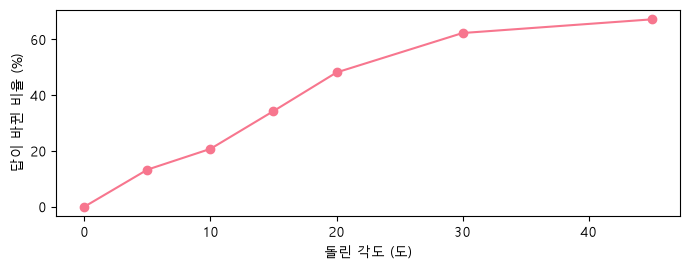

각도별 바뀐 비율 — 5도 13.3% · 20도 48.2% · 45도 67.2%


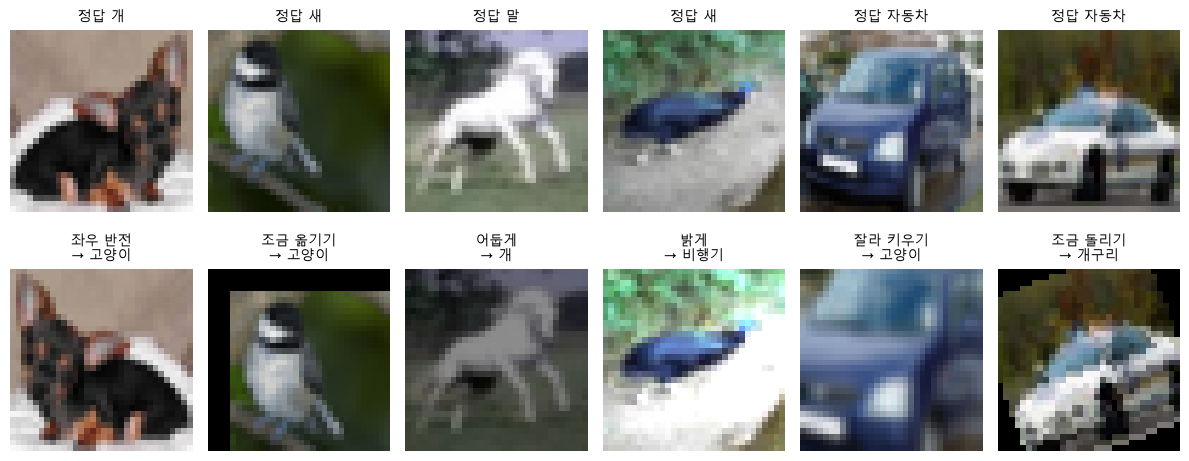

In [15]:
# 왜 · 각도를 늘려 가며 언제부터 답이 바뀌는지 같은 2000장으로 비교하기 위해
sub = correct[:2000]                                       # 맞힌 검증 사진 앞 2000장
angles = [0, 5, 10, 15, 20, 30, 45]                        # 돌리는 각도
rate = []                                                  # 각도별 바뀐 비율
for a in angles:                                           # 각도만 키움
    xs = TF.rotate(x_val[sub].float(), float(a))           # 돌린 사진
    # 각도별 바뀐 비율
    rate.append((predict(model, xs).argmax(1) != pred[sub]).float().mean().item() * 100)
fig, ax = plt.subplots(figsize=(7, 2.8))                   # 각도 곡선
ax.plot(angles, rate, "o-", color="#f7768e")               # 점과 선
ax.set_xlabel("돌린 각도 (도)")                            # 가로축
ax.set_ylabel("답이 바뀐 비율 (%)")                        # 세로축
fig.tight_layout()                                         # 정리
plt.show()                                                 # 그리기
print(f"각도별 바뀐 비율 — 5도 {rate[1]:.1f}% · "          # 세 각도
      f"20도 {rate[4]:.1f}% · 45도 {rate[6]:.1f}%")
tops, bottoms, t_top, t_bot, used = [], [], [], [], set()  # 변화마다 한 장
for k in KINDS:                                            # 변화마다 바뀐 사진 중 앞 번호 한 장
    i = next(int(correct[j]) for j in changed[k].nonzero().flatten()  # 바뀐 사진 중 앞 번호
             if int(correct[j]) not in used)
    used.add(i)                                            # 앞 칸과 겹치지 않게
    xi = shake(x_val[i:i + 1], k)                          # 바꾼 사진
    tops.append(x_val[i])                                  # 위: 원본
    t_top.append(f"정답 {KO[CLASSES[y_val[i]]]}")          # 원본 제목
    bottoms.append(xi[0])                                  # 아래: 바꾼 사진
    t_bot.append(f"{KIND_KO[k]}\n→ {KO[CLASSES[predict(model, xi).argmax()]]}")  # 바뀐 답
show(tops + bottoms, t_top + t_bot, cols=6, size=2.0)      # 위 원본 · 아래 바뀐 모습

**결과** · 예측 정답은 있음 — 5도에서 13.3%

- `5도 13.3% · 20도 48.2% · 45도 67.2%` — 작은 각도에서도 바뀌고, 각도가 커질수록 늘어남
- 둘째 그림 · 아래 사진도 같은 대상 · 바뀐 답은 그럴듯한 것도 엉뚱한 것도 있음
- 세 칸 예 · 본 것: 돌린 사진에서 답이 바뀜 · 모서리에 검은 빈칸 / 후보: 학습 사진에 돌아간 모습이 드묾 / 확인: 회전 증강 모델과 같은 흔든 사진으로 견주기

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>보이는 사실</td><td>화면에서 직접 짚을 수 있는 것만</td><td>'어둡게 하자 답이 바뀜'</td></tr>
<tr><td>원인 후보</td><td>아직 결론 아님</td><td>'학습 사진에 이만큼 어두운 모습이 드묾'</td></tr>
<tr><td>확인할 비교</td><td>무엇과 무엇을 같은 조건에서</td><td>'밝기 증강 모델과 같은 사진으로 견주기'</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 20도 값이 앞 막대와 조금 다름 · 분모가 앞 2000장이라서
> - '모델은 색만 본다'는 사실 칸이 아니라 후보 칸

> ✅ **한 줄 정리** · 작은 각도에서도 답이 바뀌며, 흔들린 이유는 보이는 사실 · 원인 후보 · 확인할 비교 세 칸으로 나눠 적는다.

**딥러닝 코드에서는**

- `RandomRotation(degrees)` 같은 증강의 세기를 정할 때 이 곡선이 근거
- 세 칸 정리는 모든 오류 분석에 그대로 씀 (6 · 9 · 15장)

---
## 4. 학습 기록 읽기

> **이 장의 흐름**
>
> - train_one_epoch · evaluate 한 에폭 시연 → 학습 모드와 평가 모드
> - 그다음 과적합을 눈앞에서 → 기준 모델의 기록 → 손실은 확신까지 봄

<img src="images/pfcnn1_ch4.png" alt="학습 한 바퀴와 곡선 세 모양" width="800">

**파이프라인 위치** · ④ 학습 과정 점검

### 4-1. `A` `train_one_epoch` · `evaluate` 한 에폭 · `opt.zero_grad` · `loss.backward` · `opt.step` <sub>1일차 4장</sub>

> 🎯 **학습 한 바퀴는 어떤 순서로 돌고, 학습 점수와 검증 점수는 어떻게 다르게 재는가?**

💡 **쉽게 말하면**

- 섞기 → 묶음 꺼내기 → 예측 → 손실 → 기울기 → 한 걸음 (0장 준비 셀의 ①~⑥).
- 학습 쪽은 에폭 동안 바뀌던 모델들의 평균, 검증 쪽은 끝난 모델 하나.

**실행 흐름**

1. 새 모델 · Adam
2. 학습 전 검증 정확도
3. 학습 사진 2000장으로 한 바퀴
4. 학습 없이 검증 점수

**먼저 예측** · 학습 전 검증 정확도는 몇 %쯤일까? — 답은 코드 실행 결과 아래에

In [16]:
torch.manual_seed(0)                                                              # 시작값 고정
demo = SmallCNN(len(CLASSES)).to(DEV)                                             # 처음부터 새 모델
opt = torch.optim.Adam(demo.parameters(), lr=2e-3)  # 한 걸음 크기 = 학습률
# 왜 · 학습 전 점수를 먼저 재어 한 에폭 학습의 효과를 비교할 출발점을 두기 위해
_, va0 = evaluate(demo, x_val, y_val)  # 학습 전 검증 정확도
tr_loss, tr_acc = train_one_epoch(demo, opt, x_train[:2000], y_train[:2000])      # 2000장 한 바퀴
va_loss, va_acc = evaluate(demo, x_val, y_val)                                    # 학습 없이 점수만
print(f"학습 전 검증 정확도 {va0 * 100:.1f}% (열 종류 중 아무거나 ≈ 10%)")        # 출발점
print(f"한 에폭 뒤 — 학습 손실 {tr_loss:.3f} · 학습 정확도 {tr_acc * 100:.1f}%")  # 에폭 평균
print(f"한 에폭 뒤 — 검증 손실 {va_loss:.3f} · 검증 정확도 {va_acc * 100:.1f}%")  # 끝난 모델 하나
print(f"묶음 128장 → 2000장은 {-(-2000 // 128)}걸음")                             # 걸음 수 (올림)

학습 전 검증 정확도 10.2% (열 종류 중 아무거나 ≈ 10%)
한 에폭 뒤 — 학습 손실 2.011 · 학습 정확도 25.6%
한 에폭 뒤 — 검증 손실 2.308 · 검증 정확도 15.9%
묶음 128장 → 2000장은 16걸음


**결과** · 예측 정답은 약 10% — 열 종류 중 아무거나

- `학습 전 검증 정확도 10.2%` — 아무것도 모르는 출발점 = 10종 중 하나
- `학습 손실 2.011 · 학습 정확도 25.6%` — 에폭 동안의 평균 · dropout 켜진 채
- `검증 손실 2.308 · 검증 정확도 15.9%` — 에폭이 끝난 모델 하나를 평가 모드로
- `2000장은 16걸음` — 2000 ÷ 128을 올림 · 걸음마다 숫자를 고침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>train_one_epoch</code></td><td>섞고 · 묶고 · 고침 · <code>model.train()</code></td><td>학습 사진</td></tr>
<tr><td><code>evaluate</code></td><td>점수만 · 모델 안 바뀜 · <code>model.eval()</code></td><td>검증 · 테스트</td></tr>
<tr><td>학습률 (한 걸음 크기)</td><td>크면 들쭉날쭉 · 작으면 느림</td><td>Adam 0.002가 이 강의 기본</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `opt.zero_grad()`를 빼면 기울기가 묶음마다 쌓임
> - 학습 정확도와 검증 정확도는 재는 방법이 달라 첫 에폭에 검증이 더 높기도 함

> ✅ **한 줄 정리** · 학습 한 바퀴는 섞기부터 한 걸음까지 여섯 단계이고, 검증은 학습 없이 평가 모드로 점수만 잰다.

**딥러닝 코드에서는**

- `for x, y in loader: opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step()` — 모든 학습 코드의 뼈대
- 에폭마다 검증 점수를 적어 두면 그것이 학습 기록(곡선)

### 4-2. `A` 학습 모드와 평가 모드 · 빼먹으면 · `model.train()` · `model.eval()` · `copy.deepcopy` <sub>1일차 4장</sub>

> 🎯 **같은 사진 · 같은 모델인데 모드에 따라 결과가 왜 달라지는가?**

💡 **쉽게 말하면**

- 학습 모드는 dropout이 **무작위로 값을 끄고**, BatchNorm이 들어온 묶음의 평균을 씀.
- 평가 모드는 늘 같은 계산 → 점수가 재현됨.

**실행 흐름**

1. 복사본 모델 · 같은 사진 한 장
2. 학습 모드로 세 번 · 평가 모드로 세 번
3. 검증 2000장 정확도를 모드별로 두 번씩

**먼저 예측** · 학습 모드로 같은 사진을 세 번 넣으면 확률이 같을까? — 답은 코드 실행 결과 아래에

In [17]:
# 왜 · 학습 모드로 평가하면 결과가 흔들린다는 것을 원본을 건드리지 않고 보기 위해
m2 = copy.deepcopy(model)                                        # 복사본 — 원래 모델은 그대로
xx = to_input(x_val[:1])                                         # 같은 검증 사진 한 장
with torch.no_grad():                                            # 기울기 필요 없음
    m2.train()                                                   # 학습 모드
    tr3 = [m2(xx).softmax(1)[0].max().item() for _ in range(3)]  # 세 번 넣기
    m2.eval()                                                    # 평가 모드
    ev3 = [m2(xx).softmax(1)[0].max().item() for _ in range(3)]  # 세 번 넣기
print("같은 사진을 세 번 넣었을 때 가장 큰 확률")                # 머리줄
print("  학습 모드 — " + " · ".join(f"{v:.3f}" for v in tr3))    # dropout이 켜져 매번 다름
print("  평가 모드 — " + " · ".join(f"{v:.3f}" for v in ev3))    # 늘 같음


# 왜 · 모드만 다른 두 모델을 같은 사진으로 채점하기 위해
def acc_on(mdl, n=2000, bs=500):                          # 모드를 바꾸지 않고 그대로 잼
    with torch.no_grad():                                 # 기울기 없음
        # 500장씩 답
        p_ = torch.cat([mdl(to_input(x_val[k:k + bs])).argmax(1) for k in range(0, n, bs)])
    return (p_ == y_val[:n]).float().mean().item() * 100  # 정확도 %


# 왜 · 평가 모드에서는 같은 사진에 항상 같은 답이 나오는지 확인하기 위해
m3 = copy.deepcopy(model)                      # 또 다른 복사본
m3.eval()                                      # 평가 모드로 두 번
e1, e2 = acc_on(m3), acc_on(m3)                # 같은 값
m3.train()                                     # 평가 모드를 빼먹으면
t1, t2 = acc_on(m3), acc_on(m3)                # dropout · 묶음 평균 BN
print(f"검증 2000장 — 평가 모드 {e1:.1f}% · "  # 모드별 두 번씩
      f"{e2:.1f}% / 학습 모드 {t1:.1f}% · {t2:.1f}%")

같은 사진을 세 번 넣었을 때 가장 큰 확률
  학습 모드 — 0.809 · 0.585 · 0.519
  평가 모드 — 1.000 · 1.000 · 1.000


검증 2000장 — 평가 모드 83.8% · 83.8% / 학습 모드 82.6% · 82.8%


**결과** · 예측 정답은 다름 — 0.809 · 0.585 · 0.519

- `학습 모드 — 0.809 · 0.585 · 0.519` — dropout이 켜져 매번 다름
- `평가 모드 — 1.000 · 1.000 · 1.000` — 늘 같음
- `평가 모드 83.8% · 83.8% / 학습 모드 82.6% · 82.8%` — 평가 모드를 빼먹으면 점수가 재현되지 않음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>model.train()</code></td><td>dropout 켬 · BN 묶음 평균 · 모아 둔 평균 갱신</td><td>학습할 때</td></tr>
<tr><td><code>model.eval()</code></td><td>dropout 끔 · BN 모아 둔 평균</td><td>평가 · 예측할 때</td></tr>
<tr><td><code>torch.no_grad()</code></td><td>기울기 기록 끔 · 모드와는 별개</td><td>평가 때 메모리 · 시간 절약</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `no_grad`만 쓰고 `eval()`을 빼먹는 실수가 흔함 · 둘은 다른 일
> - 복사본으로 실험 · 원래 모델은 건드리지 않음

> ✅ **한 줄 정리** · dropout과 BatchNorm 때문에 학습 모드는 결과가 흔들리므로, 평가와 예측 전에는 반드시 `model.eval()`을 부른다.

**딥러닝 코드에서는**

- `model.eval(); with torch.no_grad(): ...` — 평가 코드의 두 줄 짝
- 얼린 모델도 학습 모드면 BN 평균이 바뀜 (14장 고장 6)

### 4-3. `A` 과적합을 눈앞에서 · 곡선 세 모양 · `hist_s` · `ax.plot` <sub>1일차 4장</sub>

> 🎯 **사진이 적으면 학습 정확도와 검증 정확도 사이에 무슨 일이 생기는가?**

💡 **쉽게 말하면**

- 과적합 = 본 사진은 잘 맞히는데 **처음 보는 사진은 그만큼 못 맞히는** 상태.
- 사진이 적으면 외우기 쉬워 두 선이 멀리 떨어짐.

**실행 흐름**

1. 새 모델 · 학습 사진 500장만
2. 20에폭 학습하며 학습 · 검증 정확도 기록
3. 두 선 그리기

**먼저 예측** · 500장으로 20에폭 학습하면 학습과 검증 정확도는 각각 몇 %쯤일까? — 답은 코드 실행 결과 아래에

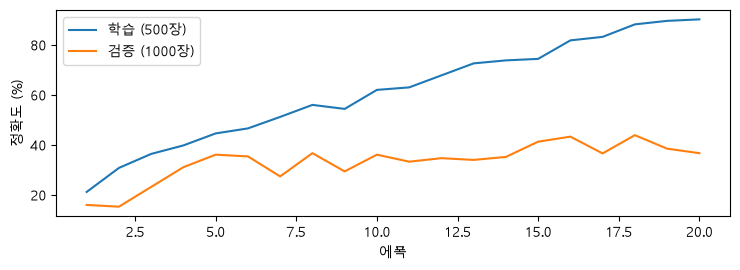

500장으로 20에폭 — 마지막 학습 정확도 90.2% · 검증 36.7%


In [18]:
torch.manual_seed(0)                                                            # 시작값 고정
# 왜 · 작은 데이터로 과적합이 생기는 과정을 눈앞에서 재현하기 위해
small = SmallCNN(len(CLASSES)).to(DEV)                                          # 새 모델
opt_s = torch.optim.Adam(small.parameters(), lr=2e-3)                           # 같은 학습률
hist_s = []  # (에폭, 학습 정확도, 검증 정확도)
for ep in range(1, 21):                                                         # 20에폭
    # 500장 한 바퀴
    _, ta = train_one_epoch(small, opt_s, x_train[:500], y_train[:500], bs=64, seed=ep)
    _, va = evaluate(small, x_val[:1000], y_val[:1000])                         # 검증 1000장
    hist_s.append((ep, ta * 100, va * 100))                                     # 기록
fig, ax = plt.subplots(figsize=(7.5, 2.8))                                      # 두 선
ax.plot([r[0] for r in hist_s], [r[1] for r in hist_s], label="학습 (500장)")   # 파랑
ax.plot([r[0] for r in hist_s], [r[2] for r in hist_s], label="검증 (1000장)")  # 주황
ax.set_xlabel("에폭")                                                           # 가로축
ax.set_ylabel("정확도 (%)")                                                     # 세로축
ax.legend()                                                                     # 범례
fig.tight_layout()                                                              # 정리
plt.show()                                                                      # 그리기
print(f"500장으로 20에폭 — 마지막 학습 정확도 {hist_s[-1][1]:.1f}% · "          # 간격 확인
      f"검증 {hist_s[-1][2]:.1f}%")

**결과** · 예측 정답은 학습 90.2% · 검증 36.7% — 간격이 크게 벌어짐

- `마지막 학습 정확도 90.2% · 검증 36.7%` — 외운 모습 · 처음 보는 사진은 못 맞힘
- 그림 · 주황 선이 들쭉날쭉 · 검증 사진이 적어 몇 장 차이에도 흔들림 → 흐름으로 읽음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>덜 배움</td><td>두 선 모두 낮고 아직 오르는 중 · 간격 작음</td><td>더 학습 · 더 큰 모델</td></tr>
<tr><td>알맞음</td><td>두 선이 함께 오름 · 간격 작음</td><td>지금 설정 유지</td></tr>
<tr><td>외움 (과적합)</td><td>학습 선만 오르고 검증 선은 멈추거나 내려감</td><td>데이터 · 증강 · 일찍 멈추기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 과적합 ≠ 학습 정확도가 높은 것 · 간격과 검증 선의 방향으로 판단
> - 손실로 보면 과적합에서 검증 손실이 다시 오름 (다음 섹션)

> ✅ **한 줄 정리** · 과적합은 학습 선만 오르고 검증 선이 멈춰 간격이 벌어지는 모습이며, 사진이 적을수록 쉽게 생긴다.

**딥러닝 코드에서는**

- TensorBoard · W&B에 학습 · 검증 곡선을 함께 그리는 이유
- `Subset(train, range(500))` — 일부러 적게 학습해 과적합을 재현해 보는 실험

### 4-4. `A` 기준 모델의 학습 기록 · 검증 손실은 오히려 오름 · `max(key=)` · `min(key=)` <sub>1일차 4장</sub>

> 🎯 **검증 정확도는 비슷한데 검증 손실이 오른다면 무슨 뜻인가?**

💡 **쉽게 말하면**

- 정확도는 **맞음 / 틀림**만 세고, 손실은 **얼마나 확신했는지**까지 봄.
- 맞히는 개수는 비슷해도 틀린 쪽에 강하게 확신하면 손실이 오름.

**실행 흐름**

1. 0장에서 학습한 20에폭 기록
2. 정확도 · 손실 곡선 나란히
3. 검증 정확도 최고 에폭 · 검증 손실 최저 에폭

**먼저 예측** · 검증 손실이 가장 낮았던 에폭과 검증 정확도가 가장 높았던 에폭은 같을까? — 답은 코드 실행 결과 아래에

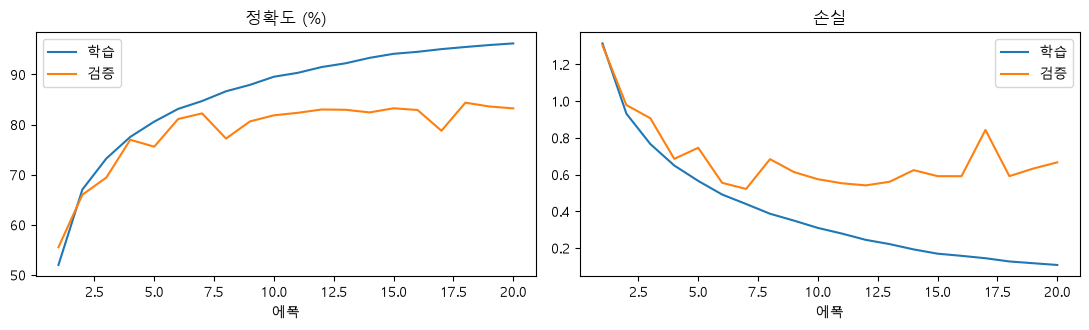

마지막 에폭 학습 정확도 96.2% · 검증 83.2%
검증 정확도 최고 에폭 18 (84.4%)
검증 손실 최저 에폭 7 (0.521) → 마지막 0.666
학습 설정 — 에폭 20 · 묶음 128 · Adam 학습률 0.002 · 시작값 0


In [19]:
# 왜 · 기준 모델의 학습 기록에서 최고 시점과 손실 흐름을 읽기 위해
h = H["base"]                                                                  # 0장에서 학습한 기록
ep = [r["epoch"] for r in h]                                                   # 가로축
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))  # 왼쪽 정확도 · 오른쪽 손실
ax[0].plot(ep, [r["train_acc"] * 100 for r in h], label="학습")                # 파랑
ax[0].plot(ep, [r["val_acc"] * 100 for r in h], label="검증")                  # 주황
ax[0].set_title("정확도 (%)")                                                  # 제목
ax[1].plot(ep, [r["train_loss"] for r in h], label="학습")                     # 손실
ax[1].plot(ep, [r["val_loss"] for r in h], label="검증")                       # 손실
ax[1].set_title("손실")                                                        # 제목
for a in ax:                                                                   # 두 그림 공통
    a.set_xlabel("에폭")                                                       # 가로축
    a.legend()                                                                 # 범례
fig.tight_layout()                                                             # 정리
plt.show()                                                                     # 그리기
b_acc = max(h, key=lambda r: r["val_acc"])                                     # 검증 정확도 최고
b_loss = min(h, key=lambda r: r["val_loss"])                                   # 검증 손실 최저
print(f"마지막 에폭 학습 정확도 {h[-1]['train_acc'] * 100:.1f}% · "            # 간격
      f"검증 {h[-1]['val_acc'] * 100:.1f}%")
# checkpoint가 고른 곳
print(f"검증 정확도 최고 에폭 {b_acc['epoch']} ({b_acc['val_acc'] * 100:.1f}%)")
print(f"검증 손실 최저 에폭 {b_loss['epoch']} ({b_loss['val_loss']:.3f})"      # 그 뒤로 오름
      f" → 마지막 {h[-1]['val_loss']:.3f}")
print(f"학습 설정 — 에폭 {len(h)} · 묶음 128 · Adam 학습률 0.002 · 시작값 0")  # 같은 절차

**결과** · 예측 정답은 다름 — 손실은 에폭 7 · 정확도는 에폭 18

- `마지막 에폭 학습 정확도 96.2% · 검증 83.2%` — 간격이 벌어짐 · 뒤쪽은 외우는 중
- `검증 정확도 최고 에폭 18 (84.4%)` — checkpoint가 고른 곳
- `검증 손실 최저 에폭 7 (0.521) → 마지막 0.666` — 에폭 7 뒤로 손실은 오르는데 정확도는 비슷
- `학습 설정 — 에폭 20 · 묶음 128 · Adam 학습률 0.002 · 시작값 0` — 같은 절차를 8장 증강 모델에도 씀

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>검증 정확도</td><td>맞힌 수만</td><td>모델을 고르는 기준 (이 강의)</td></tr>
<tr><td>검증 손실</td><td>확신까지 봄 · 과신을 먼저 알려 줌</td><td>과적합 시작을 일찍 볼 때</td></tr>
<tr><td>학습 곡선</td><td>학습 쪽 평균 · dropout 켜짐</td><td>덜 배움 · 외움 판단</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 톱니 모양이라 한 에폭이 아니라 흐름으로 읽음
> - 첫 에폭에 검증 선이 위인 것은 재는 방법의 차이 (학습 쪽은 에폭 평균)

> ✅ **한 줄 정리** · 검증 정확도는 비슷해도 검증 손실이 오르면 틀린 쪽 확신이 커지는 중이며, 손실이 과적합을 먼저 알려 준다.

**딥러닝 코드에서는**

- early stopping 기준을 `val_loss`로 둘지 `val_acc`로 둘지 정하는 근거
- 기록은 리스트에 dict로 남겨 두면 그리기 · 비교가 쉬움

### 4-5. `B` 손실은 확신까지 봄 · 학습이 길어지면 · `-np.log(p)` · `ax.hist` <sub>1일차 4장</sub>

> 🎯 **정답 쪽 확률이 작아지면 손실은 얼마나 커지고, 오래 학습한 모델은 틀린 사진에서 어떻게 변하는가?**

💡 **쉽게 말하면**

- 한 장의 손실 = **-log(정답 쪽 확률)** · 1이면 0, 0에 가까우면 가파르게 커짐.
- 오래 학습하면 틀린 사진에서도 확신이 커짐.

**실행 흐름**

1. -log p 곡선과 점 네 개
2. 10에폭 · 20에폭 모델로 틀린 사진의 확신 분포
3. 0.9 이상으로 틀린 장수 비교

**먼저 예측** · 20에폭 모델이 10에폭 모델보다 0.9 이상 확신하고 틀린 사진이 많을까? — 답은 코드 실행 결과 아래에

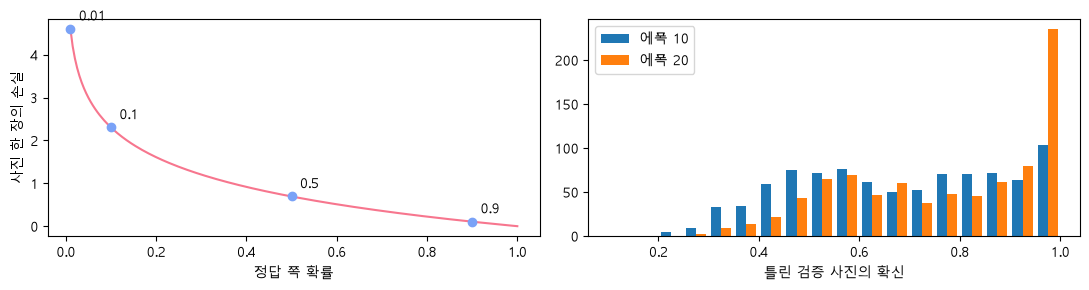

정답 쪽 확률 0.9 → 손실 0.11
정답 쪽 확률 0.5 → 손실 0.69
정답 쪽 확률 0.1 → 손실 2.30
정답 쪽 확률 0.01 → 손실 4.61
에폭 10 모델 — 틀린 사진 908장 · 그중 확신 0.9 이상 167장
에폭 20 모델 — 틀린 사진 839장 · 그중 확신 0.9 이상 315장


In [20]:
# 왜 · 손실은 맞힘 여부뿐 아니라 확신 정도까지 본다는 것을 곡선으로 확인하기 위해
p = np.linspace(0.01, 1.0, 200)                                  # 정답 쪽 확률
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0))                  # 왼쪽 -log p · 오른쪽 틀린 확신
ax[0].plot(p, -np.log(p), color="#f7768e")                       # 한 장의 손실
for q in (0.9, 0.5, 0.1, 0.01):                                  # 점 네 개
    ax[0].scatter([q], [-np.log(q)], color="#7aa2f7", zorder=3)  # 점
    ax[0].annotate(f"{q}", (q, -np.log(q)), textcoords="offset points", xytext=(6, 6))  # 점 옆 숫자
ax[0].set_xlabel("정답 쪽 확률")                                 # 가로축
ax[0].set_ylabel("사진 한 장의 손실")                            # 세로축
early, last = load_model(CK["base"]["ep10"]), load_model(CK["base"]["last"])  # 10 · 20에폭
confs = {}                                                       # 틀린 사진의 확신
for name, mdl in (("에폭 10", early), ("에폭 20", last)):        # 두 모델
    pp = predict(mdl, x_val)                                     # 확률
    confs[name] = pp.max(1).values[pp.argmax(1) != y_val].cpu()  # 틀린 사진만
ax[1].hist(list(confs.values()), bins=18, range=(0.1, 1.0), label=list(confs))  # 두 묶음
ax[1].set_xlabel("틀린 검증 사진의 확신")                        # 가로축
ax[1].legend()                                                   # 범례
fig.tight_layout()                                               # 정리
plt.show()                                                       # 그리기
for q in (0.9, 0.5, 0.1, 0.01):                                  # 손실 값
    print(f"정답 쪽 확률 {q} → 손실 {-np.log(q):.2f}")           # 0에 가까울수록 가파름
for name, c in confs.items():                                    # 모델마다
    print(f"{name} 모델 — 틀린 사진 {len(c)}장 · "               # 과신한 틀림 수
          f"그중 확신 0.9 이상 {int((c >= 0.9).sum())}장")

**결과** · 예측 정답은 많음 — 167장 → 315장

- `정답 쪽 확률 0.9 → 손실 0.11` — 거의 0
- `정답 쪽 확률 0.01 → 손실 4.61` — 틀린 쪽에 강하게 확신한 몇 장이 평균 손실을 끌어올림
- `에폭 10 모델 — 틀린 사진 908장 · 그중 확신 0.9 이상 167장` — 덜 과신
- `에폭 20 모델 — 틀린 사진 839장 · 그중 확신 0.9 이상 315장` — 틀린 수는 줄었지만 과신은 거의 두 배

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>손실 (-log p)</td><td>확신까지 반영 · 연속값</td><td>학습 신호 · 과신 감지</td></tr>
<tr><td>정확도</td><td>맞음 / 틀림 · 0 또는 1</td><td>성적 보고</td></tr>
<tr><td>틀린 사진의 확신</td><td>과신의 정도</td><td>오래 학습할지 정할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정확도가 오른다고 과신이 줄어드는 것은 아님
> - 에폭 10 · 20 비교는 한 번의 학습 · 숫자보다 방향을 봄

> ✅ **한 줄 정리** · 손실은 정답 쪽 확률이 작을수록 가파르게 커지므로, 오래 학습해 틀린 확신이 늘면 정확도가 비슷해도 손실이 오른다.

**딥러닝 코드에서는**

- `F.cross_entropy` = 정답 쪽 `-log softmax`의 평균
- label smoothing은 과신을 줄이려고 정답을 1이 아닌 0.9처럼 주는 방법

---
## 5. 가장 좋았던 순간을 저장하기

> **이 장의 흐름**
>
> - 검증이 최고일 때만 저장 · 파일 안 들여다보기 → 모양이 다르면
> - 그다음 어디서 끝내느냐 · 테스트는 한 번 → early stopping

<img src="images/pfcnn1_ch5.png" alt="checkpoint와 early stopping" width="577">

**파이프라인 위치** · ⑤ 모델 고르기 (검증 기준 · 테스트는 한 번)

### 5-1. `A` 저장 코드 · 파일 안에는 무엇이 있나 · `torch.save` · `state_dict` · `load_state_dict` <sub>1일차 5장</sub>

> 🎯 **검증이 좋아질 때만 저장하는 코드는 어떻게 생겼고, 저장 파일에는 무엇이 들어 있는가?**

💡 **쉽게 말하면**

- 모델은 메모리 안에만 있음 → 노트북을 끄면 사라짐.
- checkpoint = **검증이 지금까지보다 좋아질 때마다** 파일로 저장.

**실행 흐름**

1. 새 모델 · `best_val = -1`
2. 에폭마다 검증 → 최고면 `torch.save`
3. 같은 모양 모델을 만들어 불러오기
4. 파일 안 이름표 · 모양 보기

**먼저 예측** · 세 에폭 모두 검증이 오르면 몇 번 저장할까? — 답은 코드 실행 결과 아래에

In [21]:
# 왜 · 저장 · 불러오기 실습 파일을 따로 모아 다른 파일을 건드리지 않기 위해
os.makedirs("models_demo", exist_ok=True)                                   # 저장 폴더
torch.manual_seed(0)                                                        # 시작값 고정
demo = SmallCNN(len(CLASSES)).to(DEV)                                       # 새 모델
opt = torch.optim.Adam(demo.parameters(), lr=2e-3)                          # 학습률
best_val = -1.0  # 지금까지 최고 검증 정확도 (첫 에폭은 늘 저장)
for epoch in range(1, 4):                                                   # 세 에폭 시연
    train_one_epoch(demo, opt, x_train[:3000], y_train[:3000], seed=epoch)  # 3000장
    val_acc = evaluate(demo, x_val, y_val)[1]                               # 검증 정확도
    if val_acc > best_val:                                                  # 좋아졌을 때만
        best_val = val_acc                                                  # 최고 갱신
        torch.save(demo.state_dict(), "models_demo/best.pt")                # 같은 이름 → 덮어씀
        print(f"에폭 {epoch} · 검증 {val_acc * 100:.1f}% · 최고 → 저장")    # 저장함
    else:                                                                   # 최고가 아니면
        print(f"에폭 {epoch} · 검증 {val_acc * 100:.1f}% · 최고 아님 → 저장 안 함")  # 저장 안 함
back = SmallCNN(len(CLASSES)).to(DEV)                                       # 같은 모양의 새 모델
back.load_state_dict(torch.load("models_demo/best.pt"))                     # 숫자 채우기
print(f"불러온 모델 검증 정확도 {evaluate(back, x_val, y_val)[1] * 100:.1f}%")  # 최고와 같음
sd = torch.load("models_demo/best.pt")  # 파일 안 = 이름표 붙은 숫자 묶음
print(f"숫자 묶음 {len(sd)}개 · "                                           # 이름표 수 · 숫자 수
      f"숫자 모두 {sum(v.numel() for v in sd.values()):,}개")
for name in list(sd)[:6]:                                                   # 앞 여섯 이름표
    print(f"  {name:28s} 모양 {tuple(sd[name].shape)}")                     # 이름 · 모양

에폭 1 · 검증 28.9% · 최고 → 저장


에폭 2 · 검증 32.2% · 최고 → 저장


에폭 3 · 검증 37.7% · 최고 → 저장


불러온 모델 검증 정확도 37.7%
숫자 묶음 44개 · 숫자 모두 290,096개
  features.0.weight            모양 (32, 3, 3, 3)
  features.0.bias              모양 (32,)
  features.1.weight            모양 (32,)
  features.1.bias              모양 (32,)
  features.1.running_mean      모양 (32,)
  features.1.running_var       모양 (32,)


**결과** · 예측 정답은 세 번 — 같은 이름이라 파일에는 늘 최고 하나

- `에폭 1 · 검증 28.9% · 최고 → 저장` — 처음 값이 -1이라 첫 에폭은 늘 저장
- `에폭 3 · 검증 37.7% · 최고 → 저장` — 덮어써서 파일에는 마지막 최고만
- `불러온 모델 검증 정확도 37.7%` — 저장한 순간의 실력 그대로
- `숫자 묶음 44개 · 숫자 모두 290,096개` — 이름표 붙은 숫자 묶음 = state_dict
- `features.1.running_mean 모양 (32,)` — BN의 모아 둔 평균도 저장됨 (학습할 숫자는 아님)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>torch.save(model.state_dict(), path)</code></td><td>숫자만 저장 · 모양은 코드에</td><td>권장 방식</td></tr>
<tr><td><code>torch.save(model, path)</code></td><td>모델 객체 통째</td><td>코드가 바뀌면 못 여는 경우가 많음</td></tr>
<tr><td><code>model.load_state_dict(torch.load(path))</code></td><td>같은 모양에 숫자 채우기</td><td>불러오기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 파일에는 모델 모양 · 학습률 · 기록이 없음 · 모양은 코드로 다시 만들어야 함
> - ReLU · MaxPool은 학습할 숫자가 없어 이름표도 없음

> ✅ **한 줄 정리** · checkpoint는 검증이 최고일 때만 `state_dict`를 저장하는 규칙이고, 불러올 때는 같은 모양의 모델에 숫자를 채운다.

**딥러닝 코드에서는**

- `torch.save({'model': m.state_dict(), 'opt': opt.state_dict(), 'epoch': e}, path)` — 이어서 학습할 때
- Lightning · Keras의 ModelCheckpoint 콜백이 하는 일

### 5-2. `B` 모양이 다른 모델에 불러오면 · `size mismatch` · `try · except RuntimeError` <sub>1일차 5장</sub>

> 🎯 **종류 수가 다른 모델에 같은 파일을 불러오면 무슨 오류가 나고, 무엇을 알려 주는가?**

💡 **쉽게 말하면**

- 불러오기는 **코드의 모양과 파일의 숫자가 정확히 맞아야** 성공.
- 한 곳만 달라도 통째로 거절.

**실행 흐름**

1. 종류 수 5인 모델 만들기
2. 10종으로 저장한 파일 불러오기
3. 오류 문구에서 이름표 · 두 모양 읽기

**먼저 예측** · 어느 층에서 모양이 어긋날까? — 답은 코드 실행 결과 아래에

In [22]:
# 왜 · 모양이 다른 모델에 불러오면 어떤 에러가 나는지 미리 보기 위해
wrong_m = SmallCNN(5).to(DEV)  # 일부러 종류 수를 5로 — 마지막 층 모양이 다름
try:                                                                           # 불러오기 시도
    wrong_m.load_state_dict(sd)                                                # 같은 파일
except RuntimeError as e:  # 모양이 안 맞으면 통째로 거절
    print("불러오기 실패 — 파일의 숫자와 모델의 모양이 맞지 않음")             # 요약
    for ln in str(e).splitlines():                                             # 오류 문구 한 줄씩
        if "size mismatch" in ln:                                              # 어긋난 이름표 줄만
            name = ln.split("for ")[1].split(":")[0]                           # 이름표
            a, b = [s.split("])")[0] for s in ln.split("torch.Size([")[1:3]]   # 두 모양
            print(f"  size mismatch · {name} — 파일 ({a}) · 지금 모델 ({b})")  # 핵심만

불러오기 실패 — 파일의 숫자와 모델의 모양이 맞지 않음
  size mismatch · head.3.weight — 파일 (10, 128) · 지금 모델 (5, 128)
  size mismatch · head.3.bias — 파일 (10) · 지금 모델 (5)


**결과** · 예측 정답은 마지막 층 `head.3` — 가중치 · 편향 둘 다

- `불러오기 실패 — 파일의 숫자와 모델의 모양이 맞지 않음` — RuntimeError
- `size mismatch · head.3.weight — 파일 (10, 128) · 지금 모델 (5, 128)` — 앞 = 파일(checkpoint) · 뒤 = 지금 모델이 기대하는 모양
- `size mismatch · head.3.bias — 파일 (10) · 지금 모델 (5)` — 편향도 종류 수만큼

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>load_state_dict(sd)</code></td><td>모든 이름표 · 모양이 맞아야 함</td><td>기본</td></tr>
<tr><td><code>load_state_dict(sd, strict=False)</code></td><td>없는 이름표는 건너뜀 · 모양이 다르면 여전히 오류</td><td>일부만 채울 때</td></tr>
<tr><td>마지막 층을 빼고 불러온 뒤 새로 달기</td><td>앞부분만 재사용</td><td>종류 수가 다른 문제로 옮길 때 (13장)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 이 오류를 만나면 모델 코드가 저장 때와 같은지 · 파일이 생각한 그 파일인지부터
> - head.3 = head 묶음의 네 번째 층(0부터 셈) = 마지막 Linear

> ✅ **한 줄 정리** · `size mismatch` 오류는 어느 이름표에서 파일과 모델의 모양이 다른지 알려 주며, 한 곳만 달라도 불러오기가 거절된다.

**딥러닝 코드에서는**

- 전이학습에서 `model.fc = nn.Linear(512, 10)`처럼 마지막 층을 바꾸는 이유
- 오류 문구는 첫 줄보다 'size mismatch for ...' 줄이 핵심

### 5-3. `A` 어디서 끝내느냐에 따라 · 테스트는 한 번만 · `max(va[:e])` · `evaluate(x_test)` <sub>1일차 5장</sub>

> 🎯 **학습을 어느 에폭에서 끝내느냐에 따라 마지막 모델과 저장한 모델의 점수는 어떻게 다른가?**

💡 **쉽게 말하면**

- 마지막 모델은 끝낸 에폭에 따라 **오르락내리락**.
- 저장한 최고 모델은 **내려가지 않음** → 가장 좋았던 순간을 잃지 않는 방법.

**실행 흐름**

1. 5 ~ 20에폭 중 어디서 끝냈다고 칠지 정하기
2. 그 에폭의 점수 · 그때까지 최고 점수
3. 두 선 그리기
4. 테스트로 마지막 모델 · 고른 모델 한 번 확인

**먼저 예측** · 검증으로 고른 모델의 테스트 점수가 마지막 모델보다 높을까? — 답은 코드 실행 결과 아래에

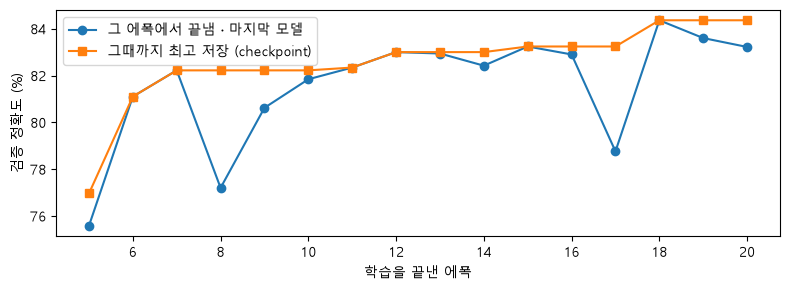

5~20에폭 중 어디서 끝내느냐에 따라 마지막 모델 75.6~84.4%
저장해 둔 최고 모델은 내려가지 않음 — 77.0% → 84.4%


테스트 한 번 — 마지막 모델 82.8% · 검증으로 고른 모델(에폭 18) 83.7%


In [23]:
# 왜 · 어디서 끝내느냐에 따라 고르는 모델이 달라진다는 것을 확인하기 위해
va = [r["val_acc"] * 100 for r in h]      # 에폭별 검증 정확도
ends = list(range(5, len(h) + 1))         # 몇 번째 에폭에서 끝냈다고 칠지
fig, ax = plt.subplots(figsize=(8, 3.0))  # 두 선
ax.plot(ends, [va[e - 1] for e in ends], "o-", label="그 에폭에서 끝냄 · 마지막 모델")  # 동그라미
ax.plot(ends, [max(va[:e]) for e in ends], "s-", label="그때까지 최고 저장 (checkpoint)")  # 네모
ax.set_xlabel("학습을 끝낸 에폭")         # 가로축
ax.set_ylabel("검증 정확도 (%)")          # 세로축
ax.legend()                               # 범례
fig.tight_layout()                        # 정리
plt.show()                                # 그리기
last_vals = [va[e - 1] for e in ends]     # 마지막 모델 점수들
lo, hi = min(last_vals), max(last_vals)   # 마지막 모델 점수의 범위
print(f"5~{len(h)}에폭 중 어디서 끝내느냐에 따라 마지막 모델 {lo:.1f}~{hi:.1f}%")  # 출렁임
print(f"저장해 둔 최고 모델은 내려가지 않음 — {max(va[:5]):.1f}% → {max(va):.1f}%")  # 늘 최고
last_m = load_model(CK["base"]["last"])   # 마지막 에폭 모델
# 고른 뒤 한 번만
print(f"테스트 한 번 — 마지막 모델 {evaluate(last_m, x_test, y_test)[1] * 100:.1f}%"
      f" · 검증으로 고른 모델(에폭 {CK['base']['best_epoch']})"
      f" {evaluate(model, x_test, y_test)[1] * 100:.1f}%")

**결과** · 예측 정답은 높음 — 82.8% → 83.7%

- `마지막 모델 75.6~84.4%` — 끝낸 에폭에 따라 크게 출렁임
- `저장해 둔 최고 모델은 내려가지 않음 — 77.0% → 84.4%` — checkpoint는 늘 그때까지 최고
- `테스트 한 번 — 마지막 모델 82.8% · 검증으로 고른 모델(에폭 18) 83.7%` — 고르는 데 안 쓴 테스트로 확인 · 이 숫자를 보고 다시 고르지 않음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>마지막 모델 (last)</td><td>끝난 순간의 숫자</td><td>학습이 충분히 안정적일 때</td></tr>
<tr><td>검증 최고 모델 (best)</td><td>가장 좋았던 순간</td><td>기본 선택</td></tr>
<tr><td>테스트 점수</td><td>고른 뒤 한 번</td><td>보고용 · 고르는 데 쓰지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 검증 최고 점수에는 운도 섞임 · 그래서 고르는 데 안 쓴 테스트로 확인
> - checkpoint는 모델을 더 좋게 만드는 방법이 아니라 좋았던 모델을 잃지 않는 방법

> ✅ **한 줄 정리** · 끝내는 에폭에 따라 마지막 모델은 출렁이지만 checkpoint는 최고를 지키며, 테스트는 고른 뒤 한 번만 본다.

**딥러닝 코드에서는**

- `ModelCheckpoint(monitor='val_acc', save_top_k=1)` — 라이브러리의 같은 기능
- 테스트를 여러 번 보면 테스트도 검증처럼 '고르는 데 쓴 시험'이 됨

### 5-4. `B` 언제 멈출까 — early stopping · 멈추는 곳과 고르는 곳 · `patience` · `axvline` <sub>1일차 5장</sub>

> 🎯 **검증이 몇 번 연속 나아지지 않으면 멈출 때, patience에 따라 멈추는 곳은 어떻게 달라지는가?**

💡 **쉽게 말하면**

- patience = **몇 번까지 기다릴지**.
- 최고를 넘으면 0으로, 못 넘으면 하나 늘림 · 연속만 셈.

**실행 흐름**

1. `stop_epoch(h, patience)` 함수
2. patience 2 · 3 · 5를 기준 모델 기록에 대입 (다시 학습 안 함)
3. 멈추는 에폭 · checkpoint 에폭을 한 그림에

**먼저 예측** · patience 2와 5 중 더 일찍 멈추는 것은? — 답은 코드 실행 결과 아래에

patience 2 → 에폭 9에서 멈춤
patience 3 → 에폭 10에서 멈춤
patience 5 → 20에폭 끝까지 감


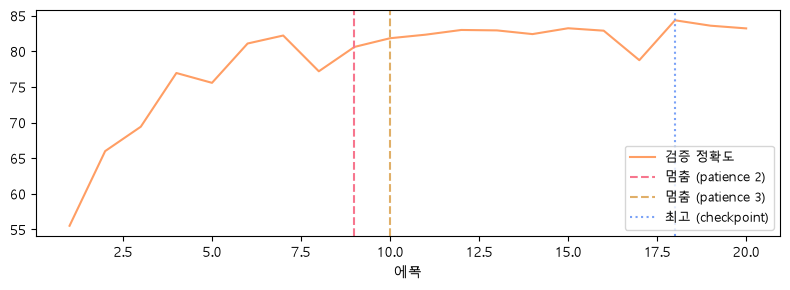

In [24]:
# 왜 · early stopping이 멈추는 곳을 규칙으로 계산하기 위해
def stop_epoch(h, patience):              # patience번 연속 안 좋아지면 멈추는 에폭 (끝까지면 None)
    best, wait = -1.0, 0                  # 최고 · 기다린 횟수
    for r in h:                           # 기록을 에폭 순서로
        if r["val_acc"] > best:           # 최고를 넘으면
            best, wait = r["val_acc"], 0  # 0으로
        else:                             # 못 넘으면
            wait += 1                     # 하나 늘림 (연속만 셈)
            if wait >= patience:          # 다 기다렸으면
                return r["epoch"]         # 멈춤
    return None                           # 끝까지 감


fig, ax = plt.subplots(figsize=(8, 3.0))                                 # 멈추는 곳 · 고르는 곳
ax.plot(ep, va, color="#ff9e64", label="검증 정확도")                    # 주황 선
for p_, c_ in ((2, "#f7768e"), (3, "#e0af68"), (5, "#9ece6a")):          # patience별 색
    s = stop_epoch(h, p_)                                                # 멈추는 에폭
    # 멈추는 에폭
    print(f"patience {p_} → " + (f"에폭 {s}에서 멈춤" if s else f"{len(h)}에폭 끝까지 감"))
    if s:                                                                # 멈추면 세로 점선
        ax.axvline(s, color=c_, ls="--", label=f"멈춤 (patience {p_})")  # 점선
ax.axvline(CK["base"]["best_epoch"], color="#7aa2f7", ls=":", label="최고 (checkpoint)")  # 파랑
ax.set_xlabel("에폭")                                                    # 가로축
ax.legend(fontsize=9)                                                    # 범례
fig.tight_layout()                                                       # 정리
plt.show()                                                               # 그리기

**결과** · 예측 정답은 patience 2 — 에폭 9에서 멈춤

- `patience 2 → 에폭 9에서 멈춤` — 잠깐 주춤에도 멈춤 · 최고 순간(18)이 오기 전
- `patience 3 → 에폭 10에서 멈춤` — 역시 최고 전에 멈춤 · 그 모델은 만들어지지 않음
- `patience 5 → 20에폭 끝까지 감` — 충분히 기다림 · checkpoint가 에폭 18을 고름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>patience 작음</td><td>빨리 멈춤 · 시간 절약</td><td>곡선이 매끄러울 때</td></tr>
<tr><td>patience 큼</td><td>멈추는 효과가 거의 없음</td><td>곡선이 들쭉날쭉할 때</td></tr>
<tr><td>early stopping + checkpoint</td><td>멈춘 뒤 저장해 둔 최고를 씀</td><td>기본 조합</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 멈추는 곳과 고르는 곳은 다를 수 있음 → 멈추는 규칙은 넉넉하게
> - 멈춘 뒤 쓰는 모델은 마지막이 아니라 그때까지 저장해 둔 최고

> ✅ **한 줄 정리** · early stopping은 검증이 patience번 연속 나아지지 않으면 멈추는 규칙이고, 멈춘 뒤에는 checkpoint의 최고 모델을 쓴다.

**딥러닝 코드에서는**

- `EarlyStopping(patience=5)` — Keras · Lightning 콜백
- 학습률을 줄이는 규칙(ReduceLROnPlateau · 14장)과 함께 쓰기도 함

---
## 6. 틀린 사진을 종류별로

> **이 장의 흐름**
>
> - 혼동행렬 만드는 법(여섯 장) → 검증 전체 표 → 칸을 열어 사진 보기
> - 그다음 가로로(재현율) · 세로로(정밀도) 읽기 → top-k · 흔들림 순위와 비교

<img src="images/pfcnn1_ch6.png" alt="혼동행렬 읽는 두 방향" width="577">

**파이프라인 위치** · ⑥ 진단 2 — 틀림을 짝과 종류로 나누기

### 6-1. `A` 혼동행렬 만드는 법 · 검증 전체 · `cm[t, q] += 1` · `fill_diagonal_` <sub>1일차 6장</sub>

> 🎯 **혼동행렬은 어떻게 만들고, 어느 칸을 봐야 헷갈린 짝이 보이는가?**

💡 **쉽게 말하면**

- 줄 = 정답 · 칸 = 모델의 답 · 사진 한 장마다 그 자리에 1을 더함.
- 대각선은 맞힌 사진, 대각선 밖은 틀린 사진.

**실행 흐름**

1. 맞힌 네 장 + 틀린 두 장으로 작은 표
2. 검증 사진 전부로 10 × 10 표
3. 대각선 합으로 정확도
4. 대각선을 지우고 가장 큰 칸 찾기

**먼저 예측** · 가장 많이 헷갈린 칸은 어떤 짝일까? — 답은 코드 실행 결과 아래에

여섯 장 — 대각선(맞힘) 4장 · 대각선 밖(틀림) 2장 · 칸 합 6


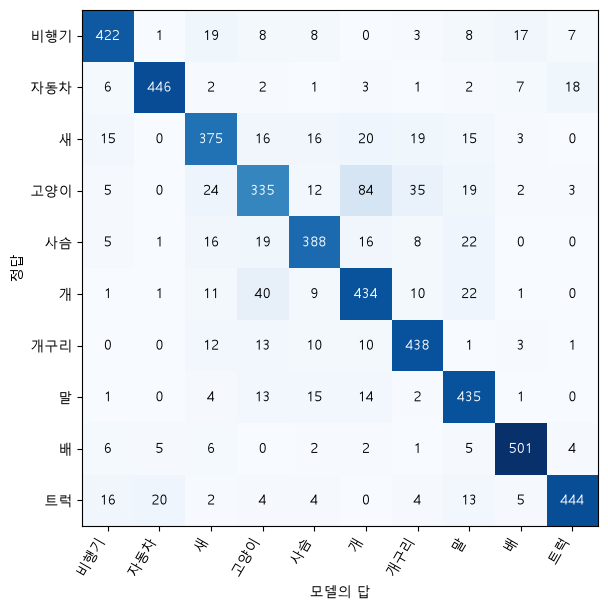

대각선 합 ÷ 전체 = 4218 ÷ 5000 = 84.4% (정확도)
가장 많이 헷갈린 칸 — 정답 고양이 → 답 개 84장
반대 방향 칸 — 정답 개 → 답 고양이 40장


In [25]:
# 왜 · 혼동행렬을 직접 채워 칸의 뜻을 이해하기 위해
ok_i, ng_i = (pred == y_val).nonzero().flatten(), (pred != y_val).nonzero().flatten()  # 맞힘 · 틀림
few = torch.cat([ok_i[:4], ng_i[:2]])                                     # 맞힌 네 장 + 틀린 두 장
mini = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long)          # 10 × 10 빈 표
for i in few:                                                             # 사진 한 장마다
    mini[y_val[i], pred[i]] += 1                                          # 정답 줄 · 답 칸에 1
print(f"여섯 장 — 대각선(맞힘) {int(mini.diagonal().sum())}장"            # 작은 표 확인
      f" · 대각선 밖(틀림) {int(mini.sum() - mini.diagonal().sum())}장 · 칸 합 {int(mini.sum())}")
cm = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long)            # 검증 사진 전부로
for t, q in zip(y_val.tolist(), pred.tolist()):                           # 정답 · 답 짝
    cm[t, q] += 1                                                         # 그 칸에 1
fig, ax = plt.subplots(figsize=(7.2, 6.2))                                # 혼동행렬
ax.imshow(cm, cmap="Blues")                                               # 진할수록 많음
ko_names = [KO[c] for c in CLASSES]                                       # 축 이름
ax.set_xticks(range(10), ko_names, rotation=60, ha="right")               # 가로 = 모델의 답
ax.set_yticks(range(10), ko_names)                                        # 세로 = 정답
ax.set_xlabel("모델의 답")                                                # 축 이름
ax.set_ylabel("정답")                                                     # 축 이름
for i in range(10):                                                       # 칸마다 숫자
    for j in range(10):                                                   # 열마다
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",            # 칸 숫자
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.tight_layout()                                                        # 정리
plt.show()                                                                # 그리기
off = cm.clone()                                                          # 대각선 밖만 보려고 복사
off.fill_diagonal_(0)                                                     # 맞힌 칸 지우기
TI, PJ = divmod(int(off.argmax()), 10)                                    # 가장 많이 헷갈린 칸
print(f"대각선 합 ÷ 전체 = {int(cm.diagonal().sum())} ÷ {int(cm.sum())}"  # = 정확도
      f" = {cm.diagonal().sum() / cm.sum() * 100:.1f}% (정확도)")
# 가장 큰 대각선 밖 칸
print(f"가장 많이 헷갈린 칸 — 정답 {KO[CLASSES[TI]]} → 답 {KO[CLASSES[PJ]]} {int(off.max())}장")
# 같은 짝 반대쪽
print(f"반대 방향 칸 — 정답 {KO[CLASSES[PJ]]} → 답 {KO[CLASSES[TI]]} {int(off[PJ, TI])}장")

**결과** · 예측 정답은 정답 고양이 → 답 개 84장

- `여섯 장 — 대각선(맞힘) 4장 · 대각선 밖(틀림) 2장 · 칸 합 6` — 칸 숫자를 모두 더하면 사진 장수
- `84.4% (정확도)` — 대각선 합(4218) ÷ 전체(5000) = 앞의 검증 정확도
- `가장 많이 헷갈린 칸 — 정답 고양이 → 답 개 84장` — 비슷한 네발 동물끼리
- `반대 방향 칸 — 정답 개 → 답 고양이 40장` — 같은 짝도 방향마다 다름 · 따로 봄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정확도</td><td>숫자 하나</td><td>전체 성적</td></tr>
<tr><td>혼동행렬</td><td>정답 × 답 짝 100칸</td><td>무엇을 무엇으로 틀렸는지</td></tr>
<tr><td>가장 큰 대각선 밖 칸</td><td>가장 많이 헷갈린 짝</td><td>오류 분석을 시작할 칸</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 고양이 → 개 · 고양이 → 트럭은 똑같이 틀린 한 장으로 셈 · 표로 나눠 봐야 정도가 보임
> - 줄과 칸을 바꿔 세면(cm[q, t]) 표가 뒤집힘 · 줄 = 정답으로 통일

> ✅ **한 줄 정리** · 혼동행렬은 정답 줄 · 답 칸에 1씩 더한 표이고, 대각선 밖의 큰 칸이 가장 많이 헷갈린 짝이다.

**딥러닝 코드에서는**

- `sklearn.metrics.confusion_matrix(y_true, y_pred)` — 같은 표 한 줄
- `ConfusionMatrixDisplay`로 그림까지

### 6-2. `B` 그 칸의 사진을 열어 보기 · 다음 칸들 · `(y_val == TI) & (pred == PJ)` · `sorted(reverse=True)` <sub>1일차 6장</sub>

> 🎯 **표의 숫자로는 알 수 없는 '왜 헷갈렸나'를 어떻게 짐작하는가?**

💡 **쉽게 말하면**

- 칸 안의 **사진을 직접 꺼내** 공통점을 봄.
- 본 것은 사실 칸, 짐작은 후보 칸에 적음.

**실행 흐름**

1. 가장 큰 칸의 사진 여덟 장 + 답 쪽 학습 사진 두 장
2. 다음으로 큰 세 칸에서 네 장씩
3. 순위 출력

**먼저 예측** · 두 번째로 많이 헷갈린 칸은? — 답은 코드 실행 결과 아래에

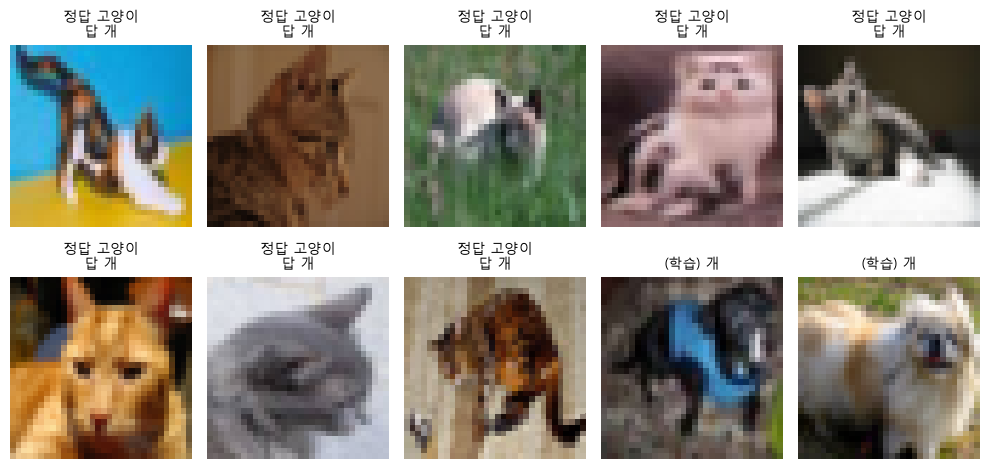

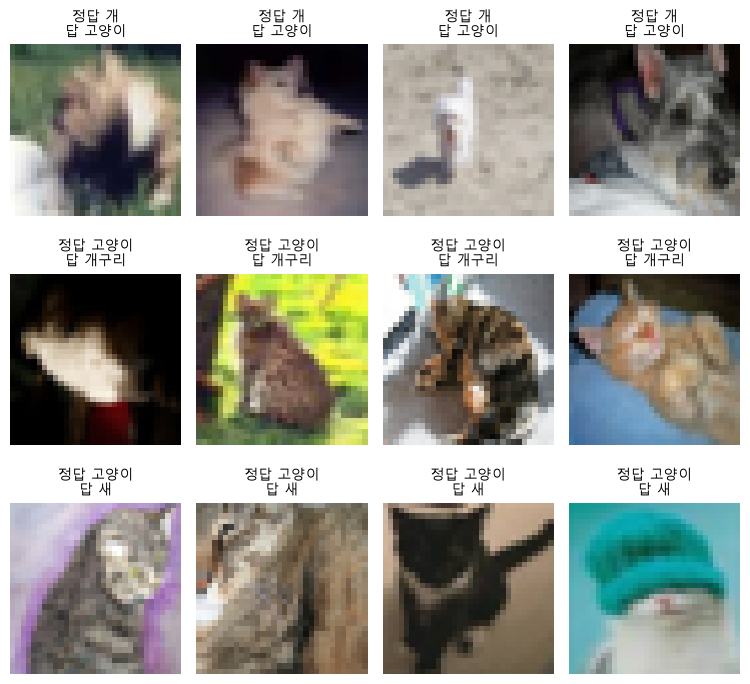

2번째로 많이 헷갈린 칸 — 개 → 고양이 40장
3번째로 많이 헷갈린 칸 — 고양이 → 개구리 35장
4번째로 많이 헷갈린 칸 — 고양이 → 새 24장


In [26]:
# 왜 · 가장 많이 헷갈린 칸의 실제 사진을 열어 원인을 짐작하기 위해
idx = ((y_val == TI) & (pred == PJ)).nonzero().flatten()[:8]    # 그 칸의 사진 여덟 장
ref = (y_train == PJ).nonzero().flatten()[:2]                   # 답 쪽 종류의 학습 사진 두 장
show([x_val[i] for i in idx] + [x_train[i] for i in ref],       # 칸 사진 + 참고 사진
     [f"정답 {KO[CLASSES[TI]]}\n답 {KO[CLASSES[PJ]]}" for _ in idx]
     + [f"(학습) {KO[CLASSES[PJ]]}" for _ in ref], cols=5, size=2.0)
# 칸을 큰 순서로 · 첫째 제외
ranked = sorted(((int(off[i, j]), i, j) for i in range(10) for j in range(10) if i != j),
                reverse=True)[1:4]
imgs, tts = [], []                                              # 다음으로 많은 세 칸
for n_, i, j in ranked:                                         # 칸마다 네 장
    sel = ((y_val == i) & (pred == j)).nonzero().flatten()[:4]  # 그 칸의 앞 네 장
    imgs += [x_val[k] for k in sel]                             # 사진
    tts += [f"정답 {KO[CLASSES[i]]}\n답 {KO[CLASSES[j]]}" for _ in sel]  # 제목
show(imgs, tts, cols=4, size=1.9)                               # 한 줄 = 한 칸
for r, (n_, i, j) in enumerate(ranked, start=2):                # 순위
    print(f"{r}번째로 많이 헷갈린 칸 — {KO[CLASSES[i]]} → {KO[CLASSES[j]]} {n_}장")  # 순위

**결과** · 예측 정답은 반대 방향 개 → 고양이 40장

- `2번째로 많이 헷갈린 칸 — 개 → 고양이 40장` — 같은 짝의 반대 방향
- `3번째로 많이 헷갈린 칸 — 고양이 → 개구리 35장` — 고양이가 다시 등장
- `4번째로 많이 헷갈린 칸 — 고양이 → 새 24장` — 고양이가 가장 약한 종류 후보 (다음 섹션)
- 그림 · 한 줄 = 한 칸 · 줄 안의 공통점(크기 · 윤곽 · 배경 색) → 줄끼리 차이

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>보이는 사실</td><td>자세 · 몸 일부만 · 배경 · 크기</td><td>'얼굴이 작게 찍힌 사진이 많음'</td></tr>
<tr><td>원인 후보</td><td>아직 결론 아님</td><td>'32칸에서 귀 · 코 모양 단서가 흐려짐'</td></tr>
<tr><td>확인 방법</td><td>하나만 바꾸는 비교</td><td>'더 큰 해상도에서 헷갈리는 정도 견주기'</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 네 장 · 여덟 장으로 본 인상 · 후보는 확인 전까지 사실이 아님
> - 윤곽이 닮은 짝과 배경이 닮은 짝은 고치는 방법이 다름

> ✅ **한 줄 정리** · 혼동행렬의 칸은 사진 묶음이므로, 칸을 열어 보이는 사실을 적고 원인은 후보로 남긴다.

**딥러닝 코드에서는**

- 오류 분석 노트북의 기본 · '가장 큰 칸 → 사진 → 세 칸 정리' 순서
- 데이터를 더 모을지 · 증강할지 정하는 근거가 됨

### 6-3. `A` 종류별로 맞힌 비율 · 세로로 읽기 · 분모 · `cm[k].sum()` · `cm[:, k].sum()` <sub>1일차 6장</sub>

> 🎯 **혼동행렬을 가로로 읽을 때와 세로로 읽을 때 무엇이 다른가?**

💡 **쉽게 말하면**

- 가로 = 정답이 X인 사진 중 X라고 맞힌 비율 (**놓치지 않는가** · 재현율).
- 세로 = X라고 답한 사진 중 실제 X인 비율 (**그 답을 믿을 수 있는가** · 정밀도).

**실행 흐름**

1. 종류마다 대각선 ÷ 줄 합 · 대각선 ÷ 열 합
2. 두 막대 그리기
3. 가장 약한 종류의 줄 합 · 열 합 직접 보기

**먼저 예측** · 전체 정확도 84.4%일 때 가장 약한 종류는 몇 %일까? — 답은 코드 실행 결과 아래에

종류      검증 장수   맞힌 비율 답한 것 중 맞음
비행기         493     85.6%       88.5%
자동차         488     91.4%       94.1%
새           479     78.3%       79.6%
고양이         519     64.5%       74.4%
사슴          475     81.7%       83.4%
개           529     82.0%       74.4%
개구리         488     89.8%       84.1%
말           485     89.7%       80.3%
배           532     94.2%       92.8%
트럭          512     86.7%       93.1%


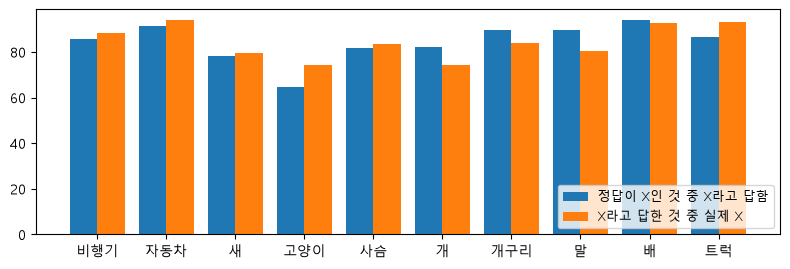

고양이 줄 합 519 · 대각선 335 → 맞힌 비율 64.5%
고양이 열 합 450 · 대각선 335 → 답한 것 중 맞음 74.4%
검증 전체 정확도 84.4% · 가장 낮은 종류 고양이 64.5%


In [27]:
# 왜 · 종류별로 맞힌 비율을 가로(재현율) · 세로(정밀도)로 나눠 읽기 위해
rec, prec = {}, {}                                   # 가로로 읽기(재현율) · 세로로 읽기(정밀도)
print(f"{'종류':6s} {'검증 장수':>6s} {'맞힌 비율':>7s} {'답한 것 중 맞음':>9s}")  # 표 머리줄
for k, name in enumerate(CLASSES):                   # 종류마다
    rec[name] = (cm[k, k] / cm[k].sum()).item()      # 대각선 ÷ 줄 합
    prec[name] = (cm[k, k] / cm[:, k].sum()).item()  # 대각선 ÷ 열 합
    # 장수 · 재현율 · 정밀도
    print(f"{KO[name]:6s} {int(cm[k].sum()):8d} {rec[name] * 100:8.1f}% {prec[name] * 100:10.1f}%")
x_ = np.arange(10)                                   # 막대 위치
fig, ax = plt.subplots(figsize=(8, 2.8))             # 두 막대
# 가로로 읽기
ax.bar(x_ - 0.2, [rec[c] * 100 for c in CLASSES], 0.4, label="정답이 X인 것 중 X라고 답함")
# 세로로 읽기
ax.bar(x_ + 0.2, [prec[c] * 100 for c in CLASSES], 0.4, label="X라고 답한 것 중 실제 X")
ax.set_xticks(x_, [KO[c] for c in CLASSES])          # 종류 이름
ax.legend(fontsize=9, loc="lower right")             # 범례
fig.tight_layout()                                   # 정리
plt.show()                                           # 그리기
LOW = min(rec, key=rec.get)                          # 가로로 읽은 값이 가장 낮은 종류
k = CLASSES.index(LOW)                               # 그 번호
row, col, diag = int(cm[k].sum()), int(cm[:, k].sum()), int(cm[k, k])  # 줄 합 · 열 합 · 대각선
print(f"{KO[LOW]} 줄 합 {row} · 대각선 {diag} → 맞힌 비율 {diag / row * 100:.1f}%")  # 분모 = 줄
print(f"{KO[LOW]} 열 합 {col} · "                    # 분모 = 열
      f"대각선 {diag} → 답한 것 중 맞음 {diag / col * 100:.1f}%")
print(f"검증 전체 정확도 {acc:.1f}% · "              # 평균에 가려짐
      f"가장 낮은 종류 {KO[LOW]} {rec[LOW] * 100:.1f}%")

**결과** · 예측 정답은 고양이 64.5% — 전체 평균에 가려짐

- `고양이 519 64.5% 74.4%` — 놓치기도 많고, 고양이라는 답도 덜 믿을 만함
- `개 529 82.0% 74.4%` — 맞힌 비율은 높지만 개라고 답한 것 중 26%는 다른 종류
- `고양이 줄 합 519 · 대각선 335 → 맞힌 비율 64.5%` — 분모 = 줄의 합
- `고양이 열 합 450 · 대각선 335 → 답한 것 중 맞음 74.4%` — 분자는 같은 칸 · 분모만 열의 합
- `검증 전체 정확도 84.4% · 가장 낮은 종류 고양이 64.5%` — 약한 종류가 평균에 가려짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>재현율 (가로 · 줄 합)</td><td>그 종류를 놓치지 않는가</td><td>놓치면 큰일인 문제 (질병 · 결함)</td></tr>
<tr><td>정밀도 (세로 · 열 합)</td><td>그 답을 믿을 수 있는가</td><td>잘못 경보가 비싼 문제</td></tr>
<tr><td>정확도</td><td>대각선 ÷ 전체</td><td>종류가 고르고 비용이 같을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 틀린 사진 한 장은 정답 쪽 재현율 한 번 + 답 쪽 정밀도 한 번에 영향
> - 장수가 비슷해서 생긴 차이가 아님 · 비슷한 짝 · 다양한 자세가 후보

> ✅ **한 줄 정리** · 혼동행렬을 가로로 읽으면 놓치지 않는지(재현율), 세로로 읽으면 그 답을 믿을 수 있는지(정밀도)가 보인다.

**딥러닝 코드에서는**

- `classification_report(y_true, y_pred)` — 종류별 precision · recall · f1 표
- 모델 비교도 종류별로 · 전체 점수가 같아도 약한 종류가 다를 수 있음

### 6-4. `B` 첫째 답만이 아니라 둘째 · 셋째 답까지 · 흔들림 순위와 오답 순위 · `topk(3)` · `set &` <sub>1일차 6장</sub>

> 🎯 **틀린 사진은 정답을 몇째 후보에 두었고, 잘 흔들리는 종류와 자주 틀리는 종류는 같은가?**

💡 **쉽게 말하면**

- 틀림에도 정도가 있음 · 정답을 **둘째에 둔 망설임**과 **후보에도 없는 큰 실수**.
- 흔들리는 약점과 원래 틀리는 약점은 다를 수 있음.

**실행 흐름**

1. 확률이 큰 세 종류 (top-3)
2. 첫째 · 둘째까지 · 셋째까지 정확도
3. 둘째 답이 정답인 틀린 사진
4. 흔들림 상위 셋 · 오답 상위 셋 나란히

**먼저 예측** · 틀린 782장 중 둘째 답이 정답인 사진은 몇 장일까? — 답은 코드 실행 결과 아래에

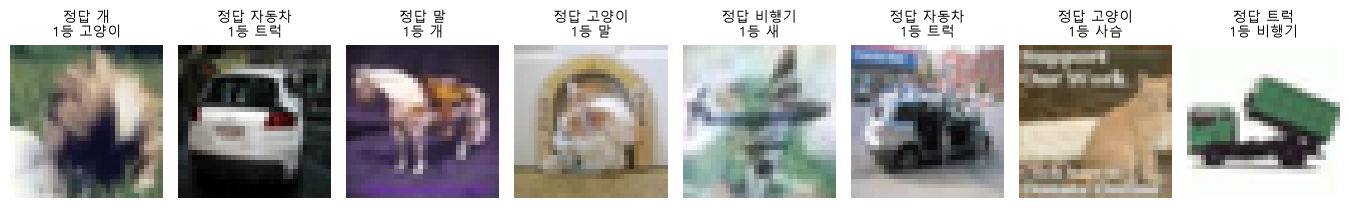

첫째 답 84.4% · 둘째까지 93.9% · 셋째까지 97.1%
틀린 782장 중 둘째 답이 정답 475장
순위  잘 흔들린 종류  자주 틀린 종류
  1   자동차        고양이       
  2   트럭         새         
  3   개구리        사슴        
상위 세 종류 중 겹치는 종류 0개


In [28]:
# 왜 · 첫째 답이 틀려도 둘째 · 셋째 답에 정답이 있는지 확인하기 위해
top3 = p_val.topk(3, dim=1).indices  # 사진마다 확률이 큰 세 종류
acc1 = (top3[:, 0] == y_val).float().mean().item() * 100                   # 첫째 답이 맞음
acc2 = (top3[:, :2] == y_val[:, None]).any(1).float().mean().item() * 100  # 둘째까지
acc3 = (top3 == y_val[:, None]).any(1).float().mean().item() * 100         # 셋째까지
sec_ok = ng_i[top3[ng_i, 1] == y_val[ng_i]]                                # 틀렸지만 둘째 답이 정답
show([x_val[i] for i in sec_ok[:8]],                                       # 망설인 틀림 여덟 장
     [f"정답 {KO[CLASSES[y_val[i]]]}\n1등 {KO[CLASSES[top3[i, 0]]]}" for i in sec_ok[:8]],
     cols=8, size=1.7)
print(f"첫째 답 {acc1:.1f}% · 둘째까지 {acc2:.1f}% · 셋째까지 {acc3:.1f}%")  # top-k 정확도
print(f"틀린 {len(ng_i)}장 중 둘째 답이 정답 {len(sec_ok)}장")             # 망설인 틀림
fr = sorted(CLASSES, key=by_class.get, reverse=True)                       # 잘 흔들린 순서 (3장)
rc = sorted(CLASSES, key=rec.get)                                          # 자주 틀린 순서 (6-3)
print("순위  잘 흔들린 종류  자주 틀린 종류")                              # 표 머리줄
for r in range(3):                                                         # 상위 셋
    print(f"{r + 1:3d}   {KO[fr[r]]:10s} {KO[rc[r]]:10s}")                 # 나란히
print(f"상위 세 종류 중 겹치는 종류 {len(set(fr[:3]) & set(rc[:3]))}개")   # 겹침

**결과** · 예측 정답은 475장 — 절반 넘게 망설인 틀림

- `첫째 답 84.4% · 둘째까지 93.9% · 셋째까지 97.1%` — 첫째 답 정확도 = 앞의 검증 정확도
- `틀린 782장 중 둘째 답이 정답 475장` — 틀린 사진의 61%는 정답을 둘째 후보로 둠
- `상위 세 종류 중 겹치는 종류 0개` — 흔들리는 종류(자동차 · 트럭 · 개구리)와 틀리는 종류(고양이 · 새 · 사슴)가 다름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>top-1 정확도</td><td>첫째 답만</td><td>기본 성적</td></tr>
<tr><td>top-k 정확도</td><td>k째 안에 정답이 있나</td><td>후보를 여러 개 보여 주는 서비스</td></tr>
<tr><td>흔들림 순위 vs 오답 순위</td><td>다른 약점</td><td>고칠 방법을 나눠 정할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 둘째 답이 정답이어도 틀린 것은 틀린 것 · 성적은 첫째 답으로
> - 새로 흔들지 않음 · 3장 결과와 앞 섹션 비율을 나란히 놓은 것

> ✅ **한 줄 정리** · top-k로 틀림의 정도를 나눠 보면 망설인 틀림이 많고, 흔들리는 약점과 원래 틀리는 약점은 다를 수 있다.

**딥러닝 코드에서는**

- ImageNet 성적은 top-1 · top-5 두 가지로 보고함
- `logits.topk(5, dim=1)` — 검색 · 추천처럼 후보를 여럿 낼 때

---
## 7. 증강 — 정답을 보존하는 변화

> **이 장의 흐름**
>
> - 정답을 지키는 변화와 해로운 변화 고르기 → 종류마다 단서가 남는지
> - 그다음 Dataset · DataLoader 안에서 꺼낼 때마다 넣기

<img src="images/pfcnn1_ch7.png" alt="증강 칸 나누기와 넣는 곳" width="584">

**파이프라인 위치** · ⑦ 데이터 쪽 처방 (학습할 때만)

### 7-1. `A` 학습에 쓴 변화와 쓰지 않은 변화 · 종류마다 단서 · `F.pad(mode='reflect')` · `torch.randint` <sub>1일차 7장</sub>

> 🎯 **증강을 해도 정답이 그대로이려면 어떤 변화를 골라야 하는가?**

💡 **쉽게 말하면**

- 증강 = 같은 사진을 꺼낼 때마다 **조금씩 다른 모습**으로 보여 주는 것 · 정답은 그대로.
- 기준은 하나 · 바뀐 뒤에도 **정답을 판단할 단서가 남는가**.

**실행 흐름**

1. `augment` 함수 (조금 옮겨 자르기 · 좌우 반전 반반 · 밝기 조금)
2. 배 사진에 다섯 번 + 쓰지 않은 변화 둘
3. 네 종류에 증강 셋 · 상하 뒤집기

**먼저 예측** · 상하 뒤집기는 왜 쓰지 않을까? — 답은 코드 실행 결과 아래에

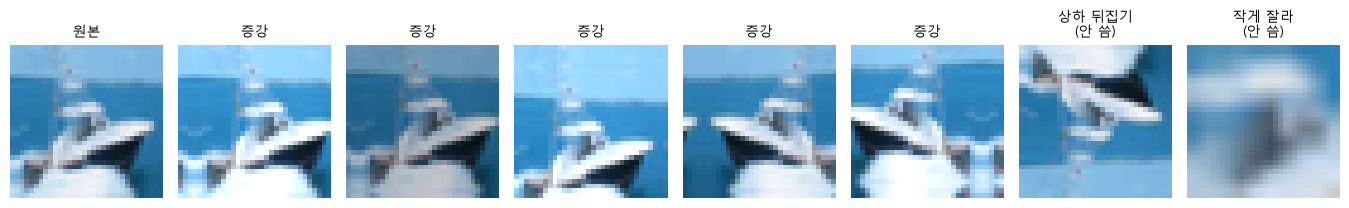

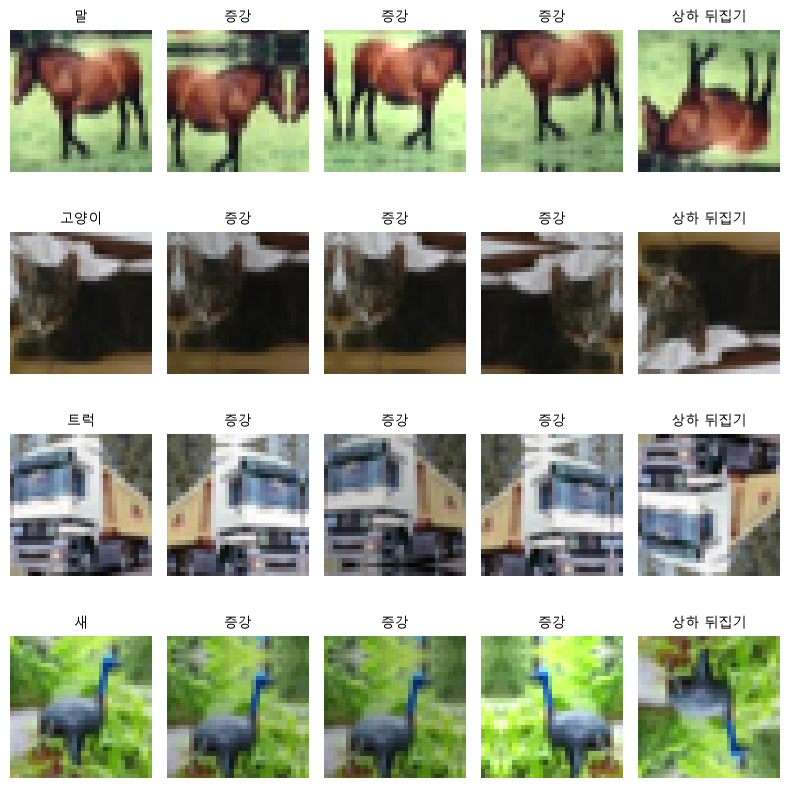

쓴 변화 — 조금 옮기기 · 좌우 반전 · 밝기 조금
안 쓴 변화 — 상하 뒤집기 · 아주 작게 잘라 키우기


In [29]:
# 왜 · 정답을 바꾸지 않는 변화만 골라 학습에 넣기 위해
def augment(x):  # 학습 때 쓸 증강: 조금 옮겨 자르기 · 좌우 반전(반반) · 밝기 조금
    n, _, hh, ww = x.shape                                      # 장수 · 세로 · 가로
    pad = max(2, hh // 8)                                       # 옮기는 폭 (32칸이면 4칸)
    xp = F.pad(x.float(), (pad,) * 4, mode="reflect")           # 가장자리를 거울처럼 늘림
    i = torch.randint(0, 2 * pad + 1, (n,))                     # 세로 자를 위치 (장마다 무작위)
    j = torch.randint(0, 2 * pad + 1, (n,))                     # 가로 자를 위치
    out = torch.stack([xp[k, :, i[k]:i[k] + hh, j[k]:j[k] + ww] for k in range(n)])  # 자르기
    flip = (torch.rand(n) < 0.5).to(x.device)                   # 반반 확률
    out[flip] = out[flip].flip(-1)                              # 좌우 반전
    gain = 0.8 + 0.4 * torch.rand(n, 1, 1, 1, device=x.device)  # 밝기 0.8 ~ 1.2배
    return (out * gain).clamp(0, 255)                           # 0~255 안으로


# 왜 · 증강 예시 그림이 같은 환경에서 매번 같게 나오도록 하기 위해
torch.manual_seed(1)                                               # 보여 주기용 난수 고정
S = int((y_train == CLASSES.index("ship")).nonzero()[0])           # 학습 사진 중 첫 번째 배
base_img = x_train[S]                                              # 원본
vflip = base_img.flip(-2)                                          # 상하 뒤집기 (쓰지 않음)
# 아주 작게 잘라 키우기 (안 씀)
tiny = TF.resize(TF.center_crop(base_img[None].float(), [10, 10]), [32, 32], antialias=True)[0]
# 원본 · 증강 5 · 안 쓴 2
names_ = ["원본"] + ["증강"] * 5 + ["상하 뒤집기\n(안 씀)", "작게 잘라\n(안 씀)"]  # 칸 제목
five = list(augment(base_img[None].repeat(5, 1, 1, 1)))            # 증강 다섯 번
show([base_img] + five + [vflip, tiny], names_, cols=8, size=1.7)  # 원본 · 증강 5 · 안 쓴 2
torch.manual_seed(2)                                               # 종류별 확인용
imgs, tts = [], []  # 종류마다 원본 · 증강 셋 · 상하 뒤집기
for c in ("horse", "cat", "truck", "bird"):                        # 네 종류
    i = int((y_train == CLASSES.index(c)).nonzero()[0])            # 그 종류 첫 장
    three = list(augment(x_train[i][None].repeat(3, 1, 1, 1)))     # 증강 세 번
    imgs += [x_train[i]] + three + [x_train[i].flip(-2)]           # 원본 · 증강 셋 · 상하 뒤집기
    tts += [KO[c], "증강", "증강", "증강", "상하 뒤집기"]          # 제목
show(imgs, tts, cols=5, size=1.6)                                  # 단서가 남는가
print("쓴 변화 — 조금 옮기기 · 좌우 반전 · 밝기 조금")             # 고른 것
print("안 쓴 변화 — 상하 뒤집기 · 아주 작게 잘라 키우기")          # 뺀 것

**결과** · 예측 정답은 단서는 남지만, 거꾸로 선 배 · 트럭은 실제로 거의 안 찍힘

- `쓴 변화 — 조금 옮기기 · 좌우 반전 · 밝기 조금` — 단서가 남고 실제 사진에도 있는 모습
- `안 쓴 변화 — 상하 뒤집기 · 아주 작게 잘라 키우기` — 만나지 않을 모습 · 대상이 잘려 사람도 판단 못 함
- 그림 · 가운데 다섯 장은 넣을 때마다 무작위라 모두 조금씩 다름 · 가장자리는 거울처럼 비춰 채움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>안전</td><td>좌우 반전 · 조금 옮기기 · 밝기 조금</td><td>대부분의 사진 분류</td></tr>
<tr><td>주의</td><td>상하 뒤집기 · 큰 회전</td><td>위아래가 의미 없는 사진(위성 · 현미경)만</td></tr>
<tr><td>해로움</td><td>아주 작게 잘라 키우기</td><td>대상이 사라지면 틀린 것을 가르침</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 많이 · 세게 넣을수록 좋은 것 아님 · 정답을 지키는 변화만 골라 넣음
> - 칸은 데이터마다 다름 · 숫자 사진의 좌우 반전은 다른 숫자처럼 보일 수 있음

> ✅ **한 줄 정리** · 증강은 정답을 판단할 단서가 남는 변화만 골라 학습할 때 넣고, 상하 뒤집기처럼 만나지 않을 모습은 뺀다.

**딥러닝 코드에서는**

- `transforms.Compose([RandomCrop(32, padding=4, padding_mode='reflect'), RandomHorizontalFlip(), ColorJitter(0.2)])`
- 30에폭 동안 같은 사진을 30번 봄 → 증강이 있으면 30번 모두 다른 모습

### 7-2. `A` 증강은 학습 코드 어디에 들어가나 · `Dataset` · `__getitem__` · `DataLoader` <sub>1일차 7장</sub>

> 🎯 **증강은 사진을 바꿔 저장하는 것인가, 꺼낼 때마다 넣는 것인가?**

💡 **쉽게 말하면**

- Dataset의 `__getitem__`이 사진을 **꺼낼 때마다 그 자리에서** 증강을 넣음.
- 학습용에만 넘기고, 검증용에는 넘기지 않음.

**실행 흐름**

1. `CifarSet(Dataset)` — 번호 → 사진 · 정답
2. 학습용(증강) · 검증용(증강 없음) 만들기
3. 같은 순서로 학습 묶음 두 번 · 검증 묶음 한 번
4. 정답 · 사진이 같은지 비교

**먼저 예측** · 같은 순서로 두 번 꺼낸 학습 묶음은 정답과 사진이 같을까? — 답은 코드 실행 결과 아래에

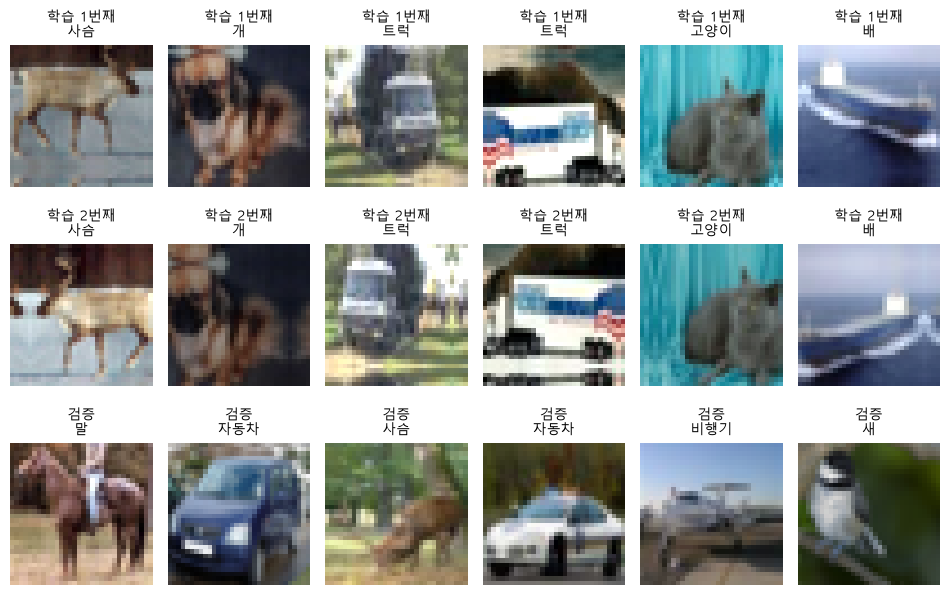

묶음 모양 (6, 3, 32, 32) · 정답 모양 (6,)
같은 순서로 두 번 — 정답 같음 True · 사진 같음 False


In [30]:
# 왜 · 증강이 실제 학습 코드에서 어디에 들어가는지 표준 구조로 보이기 위해
from torch.utils.data import DataLoader, Dataset  # 한 장씩 꺼내는 틀 · 묶는 틀


# 왜 · 사진을 꺼낼 때마다 증강을 적용하는 자리를 __getitem__에 두기 위해
class CifarSet(Dataset):                                  # 사진 · 정답 짝을 한 장씩 돌려줌
    def __init__(self, x, y, aug=None):                   # 증강 함수는 선택
        self.x, self.y, self.aug = x.cpu(), y.cpu(), aug  # 사진 · 정답 · 증강

    def __len__(self):      # 전체 장수
        return len(self.x)  # DataLoader가 씀

    def __getitem__(self, i):             # 번호 → 사진 한 장 · 정답
        img = self.x[i].float()           # 실수로
        if self.aug is not None:          # 증강이 있으면
            img = self.aug(img[None])[0]  # 꺼낼 때마다 새로
        return img, self.y[i]             # 짝으로 돌려줌


# 왜 · 학습 데이터에만 증강을 걸고 검증은 원본 그대로 두기 위해
train_ds = CifarSet(x_train, y_train, aug=augment)                         # 학습용 = 증강 있음
val_ds = CifarSet(x_val, y_val)                                            # 검증용 = 증강 없음
g1, g2 = torch.Generator().manual_seed(0), torch.Generator().manual_seed(0)  # 같은 순서 두 번
b1 = next(iter(DataLoader(train_ds, batch_size=6, shuffle=True, generator=g1)))  # 첫 번째
b2 = next(iter(DataLoader(train_ds, batch_size=6, shuffle=True, generator=g2)))  # 두 번째
v1 = next(iter(DataLoader(val_ds, batch_size=6)))                          # 검증 묶음
show(list(b1[0]) + list(b2[0]) + list(v1[0]),                              # 세 줄
     [f"학습 1번째\n{KO[CLASSES[t]]}" for t in b1[1]]
     + [f"학습 2번째\n{KO[CLASSES[t]]}" for t in b2[1]]
     + [f"검증\n{KO[CLASSES[t]]}" for t in v1[1]], cols=6, size=1.6)
print(f"묶음 모양 {tuple(b1[0].shape)} · 정답 모양 {tuple(b1[1].shape)}")  # 모델에 넣는 모양
print(f"같은 순서로 두 번 — 정답 같음 {torch.equal(b1[1], b2[1])}"         # 정답은 같고 사진은 다름
      f" · 사진 같음 {torch.equal(b1[0], b2[0])}")

**결과** · 예측 정답은 정답은 같고 사진은 다름

- `묶음 모양 (6, 3, 32, 32) · 정답 모양 (6,)` — 사진 여섯 장 × 색 세 겹 × 32칸 = 모델에 넣는 모양 그대로
- `같은 순서로 두 번 — 정답 같음 True · 사진 같음 False` — 같은 사진을 꺼내도 모습은 매번 새로
- 그림 · 위 두 줄 = 학습 묶음 두 번 · 아래 줄 = 검증 묶음 (늘 같음)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>학습 Dataset</td><td><code>aug=augment</code></td><td>꺼낼 때마다 다른 모습</td></tr>
<tr><td>검증 · 테스트 Dataset</td><td>증강 없음</td><td>같은 사진 · 같은 점수</td></tr>
<tr><td>미리 증강해 파일로 저장</td><td>모습이 고정됨 · 분할 누수 위험</td><td>거의 쓰지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 검증 · 테스트에 무작위 증강을 넣으면 잴 때마다 점수가 달라짐 (14장 고장 2)
> - 증강본을 먼저 만들고 나누면 같은 원본이 양쪽에 들어감

> ✅ **한 줄 정리** · 증강은 Dataset이 사진을 꺼낼 때마다 그 자리에서 넣으며, 학습용에만 넘기고 검증 · 테스트는 늘 원래 사진이다.

**딥러닝 코드에서는**

- `ImageFolder(root, transform=train_tf)` · `ImageFolder(root, transform=val_tf)` — 두 transform을 따로
- DataLoader의 `num_workers`가 증강을 여러 프로세스로 나눠 빠르게 함

---
## 8. 한 조건만 바꿔 다시 학습한 두 모델

> **이 장의 흐름**
>
> - 증강 하나만 바꿔 학습 · 두 기록 → 똑같은 시험 두 가지
> - 그다음 한 모델만 틀린 사진 · 종류별 → 시작값을 바꿔 다시 → 확신을 믿어도 되나

<img src="images/pfcnn1_ch8.png" alt="통제된 비교 — 바꾼 것 하나" width="577">

**파이프라인 위치** · ⑧ 효과 확인 (통제된 비교)

### 8-1. `A` 증강 모델 학습 · 두 모델의 학습 기록 · `fit(aug=augment)` · `best_epoch` <sub>1일차 8장</sub>

> 🎯 **증강 하나만 바꿔 학습하면 학습 정확도와 검증 정확도는 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 같게 둔 것 · 사진 · 모델 모양 · 시작값 · 에폭 · 묶음 · 학습률 · 입력 약속 · 평가 방법.
- 바꾼 것 하나 · **학습할 때 증강을 넣었는가**.

**실행 흐름**

1. 0장과 같은 `fit`에 `aug=augment`만 넘김
2. 두 모델의 학습 · 검증 곡선
3. 최고 에폭 점선 · 숫자

**먼저 예측** · 증강 모델의 마지막 학습 정확도는 증강 없는 모델보다 높을까 낮을까? — 답은 코드 실행 결과 아래에

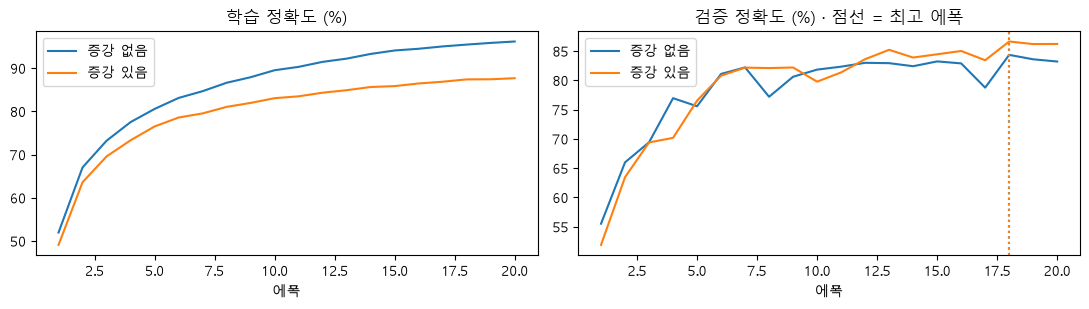

증강 없음 — 마지막 학습 96.2% · 최고 검증 84.4% (에폭 18)
증강 있음 — 마지막 학습 87.7% · 최고 검증 86.6% (에폭 18)


In [31]:
# 왜 · 증강만 바꾸고 나머지는 같은 조건으로 두 번째 모델을 학습하기 위해
H["aug"], CK["aug"] = fit(aug=augment)  # 바꾼 것 하나 = 증강 (나머지 조건 같음 · 약 1분 30초)
aug_m = load_model(CK["aug"]["best"])                  # 검증이 가장 좋았던 순간
ha = H["aug"]                                          # 증강 모델 기록
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))        # 왼쪽 학습 · 오른쪽 검증
for name, hh, key in (("증강 없음", h, "base"), ("증강 있음", ha, "aug")):  # 두 모델
    # 학습 정확도
    ax[0].plot([r["epoch"] for r in hh], [r["train_acc"] * 100 for r in hh], label=name)
    # 검증 정확도
    ax[1].plot([r["epoch"] for r in hh], [r["val_acc"] * 100 for r in hh], label=name)
    ax[1].axvline(CK[key]["best_epoch"], ls=":", color=ax[1].lines[-1].get_color())  # 최고 에폭
ax[0].set_title("학습 정확도 (%)")                     # 증강 쪽은 더 어려운 사진으로 잰 값
ax[1].set_title("검증 정확도 (%) · 점선 = 최고 에폭")  # 같은 시험
for a in ax:                                           # 공통
    a.set_xlabel("에폭")                               # 가로축
    a.legend()                                         # 범례
fig.tight_layout()                                     # 정리
plt.show()                                             # 그리기
for name, hh, key in (("증강 없음", h, "base"), ("증강 있음", ha, "aug")):  # 숫자로
    print(f"{name} — 마지막 학습 {hh[-1]['train_acc'] * 100:.1f}%"  # 두 모델 숫자
          f" · 최고 검증 {max(r['val_acc'] for r in hh) * 100:.1f}% (에폭 {CK[key]['best_epoch']})")

**결과** · 예측 정답은 낮음(87.7%) — 그런데 검증은 더 높음(86.6%)

- `증강 없음 — 마지막 학습 96.2% · 최고 검증 84.4% (에폭 18)` — 학습 사진을 거의 외움
- `증강 있음 — 마지막 학습 87.7% · 최고 검증 86.6% (에폭 18)` — 학습 점수는 낮아도 처음 보는 사진은 더 맞힘
- 그림 · 증강 쪽 학습 정확도는 증강된(더 어려운) 사진으로 잰 값 → 두 학습 정확도는 같은 시험이 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>통제된 비교</td><td>하나만 바꿈</td><td>차이를 그 하나 때문이라고 말할 때</td></tr>
<tr><td>여러 개를 한꺼번에</td><td>증강 + 에폭 + 학습률 …</td><td>무엇 덕인지 가릴 수 없음</td></tr>
<tr><td>같은 고르기 규칙</td><td>두 모델 모두 검증 최고 순간</td><td>고르는 방법도 같게 둔 조건</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 효과 판단은 같은 조건으로 잰 검증 · 테스트 점수로 · 학습 정확도로 비교하지 않음
> - 한 번씩 학습한 결과 · 최고 에폭 점선은 우연에 따라 몇 에폭씩 움직임

> ✅ **한 줄 정리** · 증강 하나만 바꾼 두 모델은 학습 점수는 낮아져도 검증 점수가 오를 수 있으며, 효과는 같은 조건의 검증 · 테스트로 판단한다.

**딥러닝 코드에서는**

- 실험 기록에 '바꾼 것 · 같게 둔 것'을 적어 두는 습관 (config 파일 · W&B)
- 증강 · 학습률 · 모델을 한꺼번에 바꾸면 다음 실험의 방향을 못 정함

### 8-2. `A` 두 모델에 똑같은 시험 · 어떤 변화에 강해졌나 · `generator=manual_seed(123)` · `%p` <sub>1일차 8장</sub>

> 🎯 **원래 테스트와 흔든 테스트에서 증강 모델은 얼마나 나아졌고, 어떤 변화에 강해졌는가?**

💡 **쉽게 말하면**

- 흔든 테스트 = 사진마다 여섯 변화 중 하나를 **미리 정해 한 번만** 만들고 고정.
- 두 모델에 똑같은 사진 → 점수 차이 = 모델 차이.

**실행 흐름**

1. 흔든 테스트 고정해 만들기
2. 두 모델 · 두 시험 점수 · 차이(%p)
3. 둘 다 맞힌 같은 검증 사진에 변화별로 넣기
4. 넣은 변화 · 안 넣은 변화 평균

**먼저 예측** · 증강에 넣지 않은 변화(잘라 키우기 · 돌리기)도 크게 좋아질까? — 답은 코드 실행 결과 아래에

증강 없음 — 원래 테스트 83.7% · 흔든 테스트 66.4%


증강 있음 — 원래 테스트 85.9% · 흔든 테스트 69.2%
차이(있음 - 없음) — 원래 +2.1%p · 흔든 +2.8%p


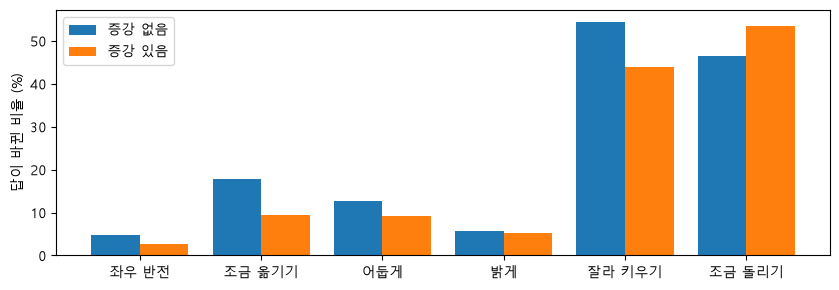

둘 다 맞힌 검증 3955장 · 넣은 변화 10.3% → 6.7% · 안 넣은 변화 50.4% → 48.7%


In [32]:
# 왜 · 두 모델이 똑같이 흔든 사진으로 시험을 보게 하기 위해
g123 = torch.Generator().manual_seed(123)                              # 흔든 테스트를 고정할 난수
pick = torch.randint(0, 6, (len(x_test),), generator=g123)             # 사진마다 변화 번호
x_shaken = torch.empty(x_test.shape, dtype=torch.float32, device=DEV)  # 흔든 테스트 (한 번만 만듦)
for i, k in enumerate(KINDS):                                          # 사진마다 미리 정한 변화
    m = (pick == i).to(DEV)                                            # 그 변화를 받을 사진
    x_shaken[m] = shake(x_test[m], k)                                  # 고정
rows = {}                                                              # 모델별 (원래, 흔든)
for name, mdl in (("증강 없음", model), ("증강 있음", aug_m)):         # 두 모델에 똑같은 시험
    # 원래 · 흔든 정확도
    rows[name] = (evaluate(mdl, x_test, y_test)[1], evaluate(mdl, x_shaken, y_test)[1])
    print(f"{name} — 원래 테스트 {rows[name][0] * 100:.1f}% · "        # 두 시험 점수
          f"흔든 테스트 {rows[name][1] * 100:.1f}%")
d_clean = (rows["증강 있음"][0] - rows["증강 없음"][0]) * 100          # 차이 (반올림 전)
d_shaken = (rows["증강 있음"][1] - rows["증강 없음"][1]) * 100         # 차이
print(f"차이(있음 - 없음) — 원래 {d_clean:+.1f}%p · 흔든 {d_shaken:+.1f}%p")  # 퍼센트포인트
p_aug = predict(aug_m, x_val).argmax(1)                                # 증강 모델의 검증 답
both_ok = ((pred == y_val) & (p_aug == y_val)).nonzero().flatten()     # 둘 다 맞힌 같은 사진
r_base, r_aug = {}, {}                                                 # 변화별 바뀐 비율
for k in KINDS:                                                        # 같은 사진 · 같은 변화
    xs = shake(x_val[both_ok], k)                                      # 흔든 사진
    # 증강 없음 바뀐 비율
    r_base[k] = (predict(model, xs).argmax(1) != y_val[both_ok]).float().mean().item()
    # 증강 있음 바뀐 비율
    r_aug[k] = (predict(aug_m, xs).argmax(1) != y_val[both_ok]).float().mean().item()
pos = np.arange(6)                                                     # 막대 위치
fig, ax = plt.subplots(figsize=(8.5, 3.0))                             # 두 막대
ax.bar(pos - 0.2, [r_base[k] * 100 for k in KINDS], 0.4, label="증강 없음")  # 파랑
ax.bar(pos + 0.2, [r_aug[k] * 100 for k in KINDS], 0.4, label="증강 있음")  # 주황
ax.set_xticks(pos, [KIND_KO[k] for k in KINDS])                        # 변화 이름
ax.set_ylabel("답이 바뀐 비율 (%)")                                    # 낮을수록 덜 흔들림
ax.legend()                                                            # 범례
fig.tight_layout()                                                     # 정리
plt.show()                                                             # 그리기
USED, UNUSED = ["hflip", "shift", "dark", "bright"], ["crop", "rotate"]  # 증강에 넣은 · 안 넣은


# 왜 · 변화 종류별 결과를 묶어 평균으로 비교하기 위해
def mean(d, ks):                              # 변화 묶음의 평균 바뀐 비율 %
    return np.mean([d[k] for k in ks]) * 100  # 평균


print(f"둘 다 맞힌 검증 {len(both_ok)}장"  # 같은 사진만 분모
      f" · 넣은 변화 {mean(r_base, USED):.1f}% → {mean(r_aug, USED):.1f}%"
      f" · 안 넣은 변화 {mean(r_base, UNUSED):.1f}% → {mean(r_aug, UNUSED):.1f}%")

**결과** · 예측 정답은 거의 아님 — 50.4% → 48.7%

- `증강 없음 — 원래 테스트 83.7% · 흔든 테스트 66.4%` — 흔든 사진에서 크게 떨어짐
- `증강 있음 — 원래 테스트 85.9% · 흔든 테스트 69.2%` — 두 시험 모두 나음
- `차이(있음 - 없음) — 원래 +2.1%p · 흔든 +2.8%p` — %p = 두 퍼센트를 뺀 값 (반올림 전 값으로 계산)
- `넣은 변화 10.3% → 6.7% · 안 넣은 변화 50.4% → 48.7%` — 보여 준 변화에 특히 강해짐 · 안 보여 준 변화는 거의 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>원래 테스트</td><td>찍힌 그대로</td><td>기본 성적</td></tr>
<tr><td>흔든 테스트 (고정)</td><td>변화 하나씩 · 두 모델에 같은 사진</td><td>견고성 비교</td></tr>
<tr><td>변화별 바뀐 비율</td><td>둘 다 맞힌 같은 사진만 분모</td><td>어떤 변화에 강해졌는지</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 흔든 사진을 모델마다 따로 만들면 사진이 달라져 비교가 깨짐 · 한 번 만들어 고정
> - 밝기는 흔들 때 학습 때보다 크게 바꿨지만 같은 종류로 묶음

> ✅ **한 줄 정리** · 같은 흔든 시험으로 재면 증강은 보여 준 변화에 특히 강해지게 하고, 보여 주지 않은 변화까지 저절로 해결하지는 않는다.

**딥러닝 코드에서는**

- `torch.Generator().manual_seed(123)` — 무작위 시험도 다시 만들 수 있게 고정
- 회전 · 자르기에 약하면 그 변화를 증강에 넣는 것이 다음 실험 (8-5)

### 8-3. `B` 한 모델만 틀린 흔든 사진 · 종류별로 두 모델 · `(pb != y) & (pa == y)` · `gains` <sub>1일차 8장</sub>

> 🎯 **더 나은 모델은 모든 사진에서 더 나은가, 종류마다 효과가 같은가?**

💡 **쉽게 말하면**

- 더 낫다 = 모든 사진에서 낫다가 아님 · 맞히는 사진과 틀리는 사진이 **서로 바뀌는** 가운데 합이 더 나음.
- 종류마다 효과가 다름.

**실행 흐름**

1. 흔든 검증 사진 고정
2. A(증강 없음)만 틀림 · B(증강 있음)만 틀림 세기 · 그림
3. 종류별 맞힌 비율 두 모델

**먼저 예측** · 증강 모델만 틀린 사진도 있을까? — 답은 코드 실행 결과 아래에

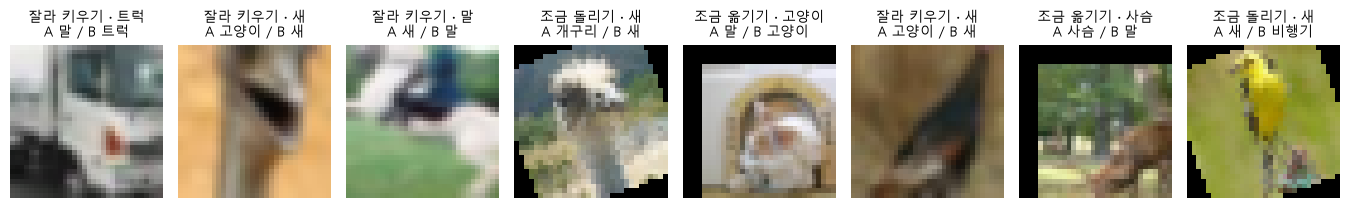

흔든 검증에서 A(증강 없음)만 틀림 539장 · B(증강 있음)만 틀림 444장


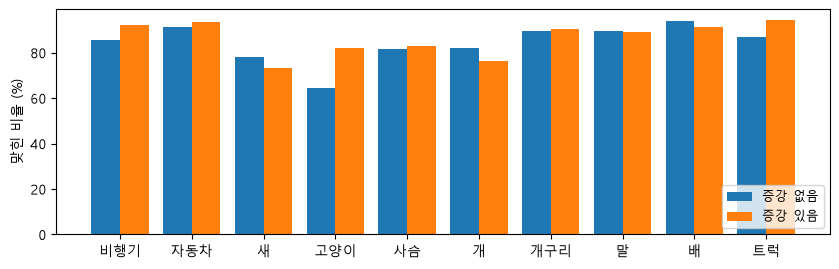

가장 많이 나아진 종류 고양이 +17.7%p · 가장 적게 나아진 종류 개 -5.9%p


In [33]:
# 왜 · 한 모델만 틀린 흔든 사진을 같은 조건에서 찾기 위해
g7 = torch.Generator().manual_seed(7)                                      # 흔든 검증을 고정할 난수
pick_v = torch.randint(0, 6, (len(x_val),), generator=g7)                  # 사진마다 변화 번호
xv_shaken = torch.empty(x_val.shape, dtype=torch.float32, device=DEV)      # 흔든 검증 사진
for i, k in enumerate(KINDS):                                              # 사진마다 변화 하나
    m = (pick_v == i).to(DEV)                                              # 그 변화를 받을 사진
    xv_shaken[m] = shake(x_val[m], k)                                      # 고정
pb, pa = predict(model, xv_shaken).argmax(1), predict(aug_m, xv_shaken).argmax(1)  # 두 모델의 답
only_aug_ok = ((pb != y_val) & (pa == y_val)).nonzero().flatten()          # A만 틀림
only_base_ok = ((pb == y_val) & (pa != y_val)).nonzero().flatten()         # B만 틀림
sel = list(only_aug_ok[:6]) + list(only_base_ok[:2])                       # 앞 여섯 · 뒤 두 장
show([xv_shaken[i] for i in sel],  # 제목: 변화 · 정답 / A의 답 · B의 답
     [f"{KIND_KO[KINDS[pick_v[i]]]} · {KO[CLASSES[y_val[i]]]}\n"
      f"A {KO[CLASSES[pb[i]]]} / B {KO[CLASSES[pa[i]]]}" for i in sel], cols=8, size=1.7)
print(f"흔든 검증에서 A(증강 없음)만 틀림 {len(only_aug_ok)}장 · "         # 서로 바뀐 사진 수
      f"B(증강 있음)만 틀림 {len(only_base_ok)}장")
# 증강 모델 종류별 재현율
rec_aug = {c: (p_aug[y_val == k] == k).float().mean().item() for k, c in enumerate(CLASSES)}
gains = {c: rec_aug[c] - rec[c] for c in CLASSES}                          # 종류별 차이
fig, ax = plt.subplots(figsize=(8.5, 2.8))                                 # 종류별 두 모델
ax.bar(x_ - 0.2, [rec[c] * 100 for c in CLASSES], 0.4, label="증강 없음")  # 파랑
ax.bar(x_ + 0.2, [rec_aug[c] * 100 for c in CLASSES], 0.4, label="증강 있음")  # 주황
ax.set_xticks(x_, [KO[c] for c in CLASSES])                                # 종류 이름
ax.set_ylabel("맞힌 비율 (%)")                                             # 원래 검증 사진
ax.legend(fontsize=9, loc="lower right")                                   # 범례
fig.tight_layout()                                                         # 정리
plt.show()                                                                 # 그리기
g_hi, g_lo = max(gains, key=gains.get), min(gains, key=gains.get)          # 가장 많이 · 적게
print(f"가장 많이 나아진 종류 {KO[g_hi]} {gains[g_hi] * 100:+.1f}%p"       # 종류별 차이 양 끝
      f" · 가장 적게 나아진 종류 {KO[g_lo]} {gains[g_lo] * 100:+.1f}%p")

**결과** · 예측 정답은 있음 — 444장 (A만 틀림은 539장)

- `A(증강 없음)만 틀림 539장 · B(증강 있음)만 틀림 444장` — 서로 바뀌는 가운데 B가 더 많이 맞힘
- `가장 많이 나아진 종류 고양이 +17.7%p · 가장 적게 나아진 종류 개 -5.9%p` — 전체 점수로는 안 보이는 종류별 차이
- 첫 그림 · 앞 여섯 장 A만 틀림 · 뒤 두 장 B만 틀림 · 변화 이름은 사실 · 그 변화 때문이라는 것은 후보

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>전체 점수 차이</td><td>합의 차이</td><td>한 줄 결론</td></tr>
<tr><td>한쪽만 틀린 사진</td><td>서로 바뀐 사진</td><td>개선이 어디서 왔는지</td></tr>
<tr><td>종류별 차이</td><td>효과가 다른 종류</td><td>다음 처방을 종류별로</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 여덟 장은 앞에서부터 고른 예 · 경향은 전체를 센 숫자로 말함
> - 종류 하나의 사진은 적고 한 번씩 학습 → 차이가 작은 종류는 우연과 구별 어려움

> ✅ **한 줄 정리** · 더 나은 모델도 일부 사진은 새로 틀리며, 효과는 종류마다 달라서 전체 점수만으로는 보이지 않는다.

**딥러닝 코드에서는**

- 모델 교체 전 '새로 틀리게 된 사진' 목록을 꼭 확인 (회귀 검사)
- 종류별 개선은 막대 두 개를 나란히 그려 봄

### 8-4. `A` 작은 데이터로 직접 다시 해 보기 — 시작값 세 개 · `mini_run(seed, use_aug)` · `torch.manual_seed(seed)` <sub>1일차 8장</sub>

> 🎯 **한 번의 비교 결과는 시작값만 바꿔도 뒤집힐 수 있는가?**

💡 **쉽게 말하면**

- 같은 조건이라도 **시작값**(처음 숫자 · 증강 모습)이 다르면 결과가 흔들림.
- 두 범위가 겹치면 한 번의 비교로 결론 내리지 않음.

**실행 흐름**

1. 학습 1000장 · 10에폭 · 시작값 0 · 1 · 2
2. 증강 없음 / 있음 × 3 = 여섯 번 학습
3. 시작값마다 선 하나

**먼저 예측** · 시작값 세 개 모두에서 증강이 더 높을까? — 답은 코드 실행 결과 아래에

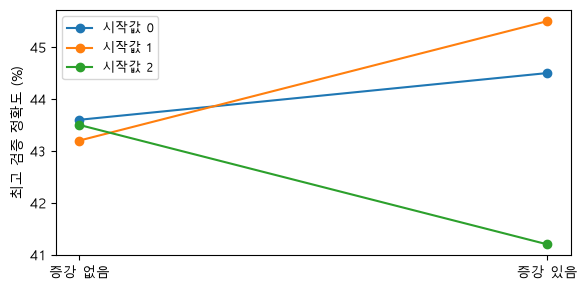

학습 1000장 · 10에폭 · 시작값 3개 — 증강 있음이 더 높은 경우 2개
범위 — 증강 없음 43.2~43.6% · 증강 있음 41.2~45.5%


In [34]:
# 왜 · 작은 데이터로 시작값만 바꿔 증강 효과가 우연이 아닌지 확인하기 위해
def mini_run(seed, use_aug, n=1000, epochs=10):  # n장으로 처음부터 짧게 → 최고 검증 정확도
    torch.manual_seed(seed)                                              # 시작값만 바꿈
    m_ = SmallCNN(len(CLASSES)).to(DEV)                                  # 새 모델
    o_ = torch.optim.Adam(m_.parameters(), lr=2e-3)                      # 같은 학습률
    best_ = -1.0                                                         # 최고 검증
    for e in range(1, epochs + 1):                                       # 에폭
        train_one_epoch(m_, o_, x_train[:n], y_train[:n], bs=64,         # 증강 여부만 다르게
                        aug=augment if use_aug else None, seed=e + 100 * seed)
        best_ = max(best_, evaluate(m_, x_val[:1000], y_val[:1000])[1])  # 최고 갱신
    return best_ * 100                                                   # %


# 왜 · 시작값 세 개 × 증강 유무 결과를 한 표에 모으기 위해
res_mini = {(sd, a): mini_run(sd, a) for sd in (0, 1, 2) for a in (False, True)}  # 여섯 번 학습
fig, ax = plt.subplots(figsize=(6, 3.0))  # 시작값마다 선 하나
for sd in (0, 1, 2):                                                              # 시작값
    # 시작값마다 선
    ax.plot([0, 1], [res_mini[(sd, False)], res_mini[(sd, True)]], "o-", label=f"시작값 {sd}")
ax.set_xticks([0, 1], ["증강 없음", "증강 있음"])                                 # 왼쪽 · 오른쪽
ax.set_ylabel("최고 검증 정확도 (%)")                                             # 세로축
ax.legend(fontsize=9)                                                             # 범례
fig.tight_layout()                                                                # 정리
plt.show()                                                                        # 그리기
up_n = sum(res_mini[(sd, True)] > res_mini[(sd, False)] for sd in (0, 1, 2))      # 증강이 높은 수
nb_ = [res_mini[(sd, False)] for sd in (0, 1, 2)]                                 # 증강 없음 세 값
na_ = [res_mini[(sd, True)] for sd in (0, 1, 2)]                                  # 증강 있음 세 값
print(f"학습 1000장 · 10에폭 · 시작값 3개 — 증강 있음이 더 높은 경우 {up_n}개")   # 방향
print(f"범위 — 증강 없음 {min(nb_):.1f}~{max(nb_):.1f}% · "                       # 두 범위가 겹치나
      f"증강 있음 {min(na_):.1f}~{max(na_):.1f}%")

**결과** · 예측 정답은 아님 — 셋 중 둘만 더 높음

- `시작값 3개 — 증강 있음이 더 높은 경우 2개` — 하나는 반대로 기욺
- `범위 — 증강 없음 43.2~43.6% · 증강 있음 41.2~45.5%` — 두 범위가 겹침 → 이 작은 실험만으로는 결론 보류

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>한 번 비교</td><td>시작값 하나</td><td>빠른 방향 확인</td></tr>
<tr><td>시작값 여러 개</td><td>흔들림의 폭이 보임</td><td>효과라고 말하기 전</td></tr>
<tr><td>범위가 겹침</td><td>우연과 구별 어려움</td><td>더 많은 데이터 · 더 긴 학습으로 다시</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 저장한 두 모델을 다시 확인한 것이 아님 · 따로 한 작은 실험
> - 1000장 · 10에폭은 짧음 · 큰 실험에서도 같은지는 다시 봐야 함

> ✅ **한 줄 정리** · 같은 조건이라도 시작값만 바꾸면 결과가 흔들리므로, 한 번의 비교는 다시 해 보고 범위가 겹치면 결론을 보류한다.

**딥러닝 코드에서는**

- 논문의 '평균 ± 표준편차 (3 seeds)' 표기가 이 이유
- `for seed in (0, 1, 2): set_seed(seed); train()` — 비교 실험의 기본 틀

### 8-5. `B` 확신을 믿어도 되나 · 다음 비교 설계 · `reliability` · `augment_next` <sub>1일차 8장</sub>

> 🎯 **모델이 0.9라고 말하면 실제로도 90%를 맞히는가, 다음에는 무엇을 바꿔 볼 것인가?**

💡 **쉽게 말하면**

- 확신 구간마다 **실제로 맞힌 비율**을 그리면 과신이 보임 (대각선 아래 = 과신).
- 다음 비교도 바꿀 것 하나 · 그대로 둘 것 · 예상 · 시험을 먼저 정함.

**실행 흐름**

1. 확신 0.1 폭 구간 · 30장 미만 구간은 뺌
2. 두 모델의 신뢰도 그림
3. 평균 확신 - 실제 정확도
4. 다음 증강 후보(회전 · 잘라 키우기 추가) 모양만 보기

**먼저 예측** · 증강 모델은 과신이 줄었을까? — 답은 코드 실행 결과 아래에

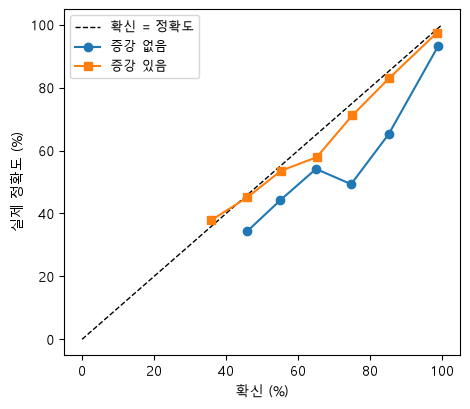

평균 확신 - 실제 정확도 — 증강 없음 +8.0%p · 증강 있음 +1.8%p


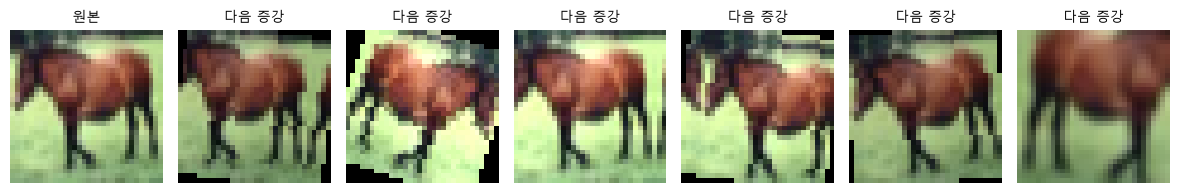

In [35]:
# 왜 · 확신 구간별 실제 정답률을 계산해 확신을 믿어도 되는지 판단하기 위해
def reliability(p, y, bins=10):                                       # 확신 구간별 실제 정확도
    c_, pr_ = p.max(1).values, p.argmax(1)                            # 확신 · 답
    xs_, ac_ = [], []                                                 # 구간 평균 확신 · 실제 정확도
    for b in range(bins):                                             # 0.1 폭 구간
        m = (c_ > b / bins) & (c_ <= (b + 1) / bins)                  # 이 구간의 사진
        if m.sum() >= 30:                                             # 30장보다 적은 구간은 뺌
            xs_.append(c_[m].mean().item() * 100)                     # 평균 확신
            ac_.append((pr_[m] == y[m]).float().mean().item() * 100)  # 실제 정확도
    return xs_, ac_, (c_.mean() - (pr_ == y).float().mean()).item() * 100  # + 과신 정도


xb_, yb_, gb = reliability(p_val, y_val)                                           # 증강 없음
xa_, ya_, ga = reliability(predict(aug_m, x_val), y_val)                           # 증강 있음
fig, ax = plt.subplots(figsize=(4.8, 4.2))                                         # 신뢰도 그림
ax.plot([0, 100], [0, 100], "k--", lw=1, label="확신 = 정확도")                    # 대각선
ax.plot(xb_, yb_, "o-", label="증강 없음")                                         # 파랑
ax.plot(xa_, ya_, "s-", label="증강 있음")                                         # 주황
ax.set_xlabel("확신 (%)")                                                          # 가로축
ax.set_ylabel("실제 정확도 (%)")                                                   # 세로축
ax.legend(fontsize=9)                                                              # 범례
fig.tight_layout()                                                                 # 정리
plt.show()                                                                         # 그리기
print(f"평균 확신 - 실제 정확도 — 증강 없음 {gb:+.1f}%p · 증강 있음 {ga:+.1f}%p")  # 양수 = 과신


# 왜 · 다음 실험에서 바꿀 조건을 함수로 먼저 설계해 두기 위해
def augment_next(x):  # 다음 비교 후보: 지금 증강 + 조금 돌리기 + 가끔 잘라 키우기
    out = augment(x)                                    # 지금 증강
    ang = (torch.rand(len(out)) * 40 - 20).tolist()     # ±20도
    out = torch.stack([TF.rotate(out[k:k + 1], ang[k])[0] for k in range(len(out))])  # 돌리기
    crop = (torch.rand(len(out)) < 0.5).to(out.device)  # 절반만
    if crop.any():                                      # 고른 사진이 있으면
        # 가운데 24칸 → 32칸
        out[crop] = TF.resize(TF.center_crop(out[crop], [24, 24]), [32, 32], antialias=True)
    return out                                          # 학습은 하지 않고 모양만 봄


torch.manual_seed(4)                                                    # 보여 주기용
horse = x_train[int((y_train == CLASSES.index("horse")).nonzero()[0])]  # 첫 번째 말
# 모양만 확인
show([horse] + list(augment_next(horse[None].repeat(6, 1, 1, 1))), ["원본"] + ["다음 증강"] * 6,
     cols=7, size=1.7)

**결과** · 예측 정답은 줄었음 — +8.0%p → +1.8%p

- `증강 없음 +8.0%p · 증강 있음 +1.8%p` — 양수 = 과신 · 0 근처 = 확신만큼 맞힘
- 첫 그림 · 오른쪽 끝(확신이 가장 높은 구간)을 봄 · 자신 있게 틀린 사진이 들어가는 쪽
- 둘째 그림 · 다음 증강 여섯 장 모두 말이라고 알아볼 수 있는지 확인 · 학습은 하지 않음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>신뢰도 그림</td><td>확신 vs 실제 정확도</td><td>확신을 믿어도 되는지</td></tr>
<tr><td>평균 확신 - 정확도</td><td>과신 정도 숫자 하나</td><td>모델끼리 견줄 때</td></tr>
<tr><td>다음 비교 설계</td><td>바꿀 것 하나 · 그대로 · 예상 · 시험</td><td>실험 전에 미리 적음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 다음 증강은 회전 · 잘라 키우기를 한꺼번에 넣음 → 좋아져도 둘 중 무엇 덕인지는 못 가림
> - 효과였다고 말하려면 · 하나만 바꿈 · 같은 시험 · 고르기는 검증 · 다시 해 보고 믿음

> ✅ **한 줄 정리** · 신뢰도 그림으로 확신과 실제 정확도를 견주면 과신이 보이며, 다음 비교도 바꿀 것 하나와 시험을 먼저 정한다.

**딥러닝 코드에서는**

- ECE(Expected Calibration Error) · temperature scaling — 확신 보정 방법
- 오늘 실험 기록 세 줄 · 바꾼 것과 유지한 것 · 예상과 실제 · 남은 한계와 다음 비교

---
## 9. 그래도 남는 오류

> **이 장의 흐름**
>
> - 두 모델이 모두 틀린 사진 · 같은 답으로 틀렸나
> - 그다음 해상도를 낮춰 보기 → 가려 보기 → 합성곱 층이 실제로 보는 것

<img src="images/pfcnn1_ch9.png" alt="원인 후보를 확인하는 비교" width="577">

**파이프라인 위치** · ⑨ 원인 후보 확인 (한 조건만 바꾸기)

### 9-1. `A` 두 모델이 모두 틀린 사진 · 같은 답으로 틀렸나 · `Counter` · `most_common(3)` <sub>1일차 9장</sub>

> 🎯 **증강을 넣어도 여전히 틀리는 사진은 몇 장이고, 두 모델은 같은 답으로 틀리는가?**

💡 **쉽게 말하면**

- 나아진 쪽만 보면 증강이 다 푼 것처럼 보임.
- **남는 오류**가 다음에 바꿀 방향을 알려 줌.

**실행 흐름**

1. 두 모델이 모두 틀린 사진 열여섯 장
2. 같은 답으로 틀림 / 다른 답으로 틀림 세기
3. 같은 답 쪽의 많은 짝 세 개

**먼저 예측** · 같은 답으로 틀린 사진과 다른 답으로 틀린 사진 중 어느 쪽이 많을까? — 답은 코드 실행 결과 아래에

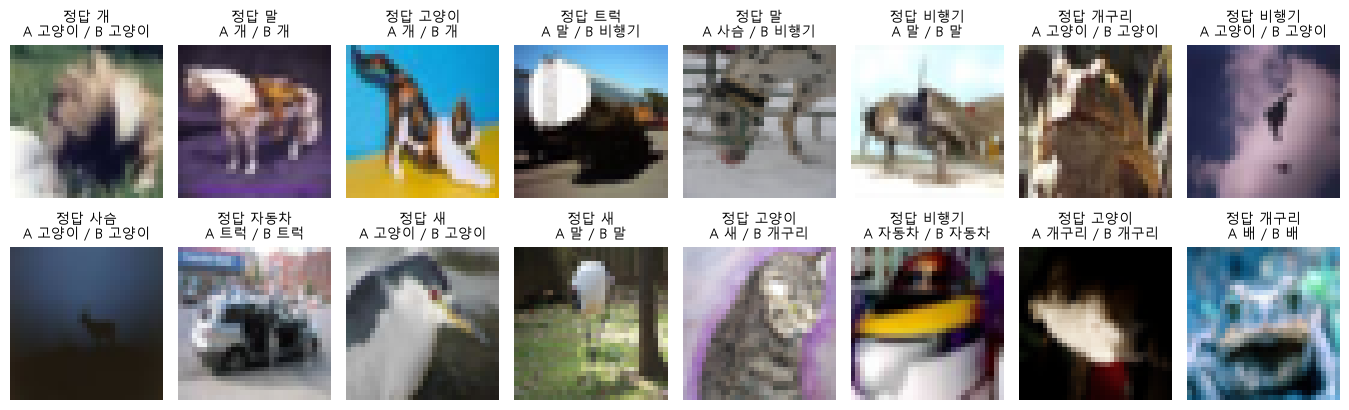

두 모델이 모두 틀린 검증 사진 405장
같은 답으로 틀림 273장 · 서로 다른 답으로 틀림 132장
같은 답으로 틀린 짝 — 개 → 고양이 31장 · 고양이 → 개 26장 · 새 → 비행기 13장


In [36]:
from collections import Counter  # 짝 세기

# 왜 · 두 모델이 모두 틀린 사진에서 같은 실수를 하는지 확인하기 위해
both = ((pred != y_val) & (p_aug != y_val)).nonzero().flatten()               # 두 모델이 모두 틀림
show([x_val[i] for i in both[:16]],                                           # 앞 열여섯 장
     [f"정답 {KO[CLASSES[y_val[i]]]}\nA {KO[CLASSES[pred[i]]]} / B {KO[CLASSES[p_aug[i]]]}"
      for i in both[:16]], cols=8, size=1.7)
rm_s = [int(i) for i in both if pred[i] == p_aug[i]]                          # 같은 답으로 틀림
rm_d = [int(i) for i in both if pred[i] != p_aug[i]]                          # 다른 답으로 틀림
print(f"두 모델이 모두 틀린 검증 사진 {len(both)}장")                         # 남는 오류
print(f"같은 답으로 틀림 {len(rm_s)}장 · 서로 다른 답으로 틀림 {len(rm_d)}장")  # 둘로 나눔
rm_pairs = Counter((CLASSES[y_val[i]], CLASSES[pred[i]]) for i in rm_s).most_common(3)  # 많은 짝
txt = " · ".join(f"{KO[t_]} → {KO[p_]} {n_}장" for (t_, p_), n_ in rm_pairs)  # 짝 글자
print("같은 답으로 틀린 짝 — " + txt)                                         # 많은 짝 셋

**결과** · 예측 정답은 같은 답 273장 · 다른 답 132장

- `두 모델이 모두 틀린 검증 사진 405장` — 데이터 쪽 변화만으로는 풀리지 않은 것
- `같은 답으로 틀림 273장 · 서로 다른 답으로 틀림 132장` — 같은 답이 많음 → 모습 변화가 아닌 다른 데서 온 헷갈림 후보
- `개 → 고양이 31장 · 고양이 → 개 26장 · 새 → 비행기 13장` — 닮은 종류 사이에 몰림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>같은 답으로 틀림</td><td>두 모델이 같은 착각</td><td>데이터 · 구조 쪽 원인 후보</td></tr>
<tr><td>다른 답으로 틀림</td><td>모델마다 다른 착각</td><td>학습 조건 차이 후보</td></tr>
<tr><td>보이는 모습으로 묶기</td><td>작음 · 일부만 · 흔치 않은 각도 · 사람도 애매</td><td>다음에 확인할 후보</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 모습으로 나눈 묶음 · 원인으로 나눈 묶음이 아님
> - 한 장이 두 묶음에 걸치거나 어느 묶음에도 안 드는 사진도 있음

> ✅ **한 줄 정리** · 두 모델이 같은 답으로 틀리는 사진이 많고 닮은 종류 사이에 몰리면, 데이터가 아니라 모델 구조를 바꿔 볼 방향이다.

**딥러닝 코드에서는**

- 앙상블이 효과적인 경우 = 모델마다 다른 답으로 틀릴 때
- 같은 답으로 틀리는 짝은 라벨 오류일 수도 있음 → 사진을 직접 확인

### 9-2. `B` 해상도를 낮추면 · `F.interpolate(mode='area')` · `invert_xaxis` <sub>1일차 9장</sub>

> 🎯 **해상도가 낮아서 고양이와 개를 헷갈린다는 후보는 해상도를 더 낮춰 보면 확인되는가?**

💡 **쉽게 말하면**

- 더 큰 사진이 없으니 **반대로 더 낮춰** 봄 (32 → 24 → 16 → 12 → 8칸).
- 줄였다가 다시 32칸으로 키움 · 칸 수는 같고 정보만 줄어듦.

**실행 흐름**

1. 해상도마다 같은 모델 · 같은 검증 사진
2. 정확도 · 고양이 → 개 장수
3. 말 사진의 해상도별 모습

**먼저 예측** · 해상도를 낮추면 고양이 → 개 헷갈림은 늘까? — 답은 코드 실행 결과 아래에

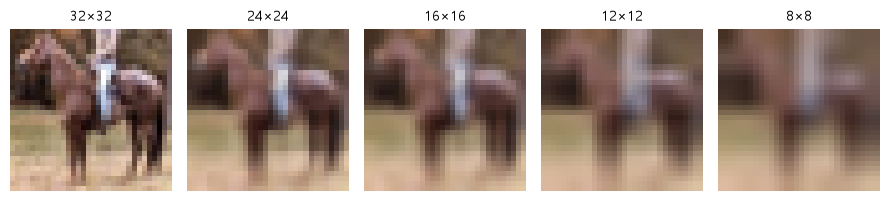

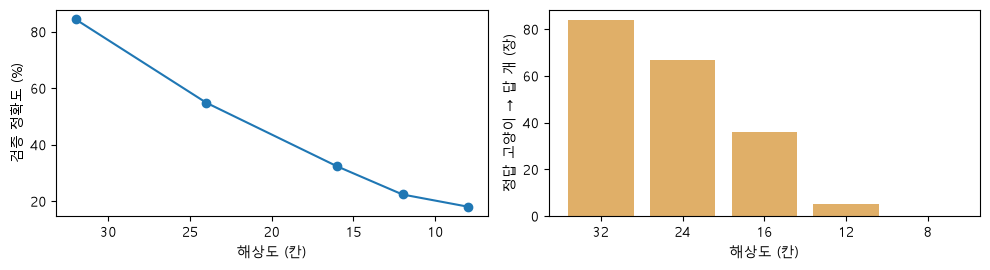

해상도별 정확도 — 32칸 84.4% · 16칸 32.3% · 8칸 18.0%
고양이 → 개 — 32칸 84장 · 16칸 36장 · 8칸 0장


In [37]:
# 왜 · 해상도를 낮추면 어느 크기에서 답이 바뀌는지 한 장으로 확인하기 위해
LOOK = int((y_val == CLASSES.index("horse")).nonzero()[0])    # 검증 사진 중 첫 번째 말
sizes = [32, 24, 16, 12, 8]                                   # 줄일 칸 수
ci, di = CLASSES.index("cat"), CLASSES.index("dog")           # 고양이 · 개
accs_r, cd_r, look_r = [], [], []                             # 정확도 · 고양이→개 · 보여 줄 사진
for sz in sizes:                                              # 해상도마다 (같은 모델 · 같은 사진)
    xs = x_val.float()                                        # 원본
    if sz < 32:  # 줄였다가 다시 32칸으로 키움 (칸 수는 같고 정보만 줄어듦)
        xs = F.interpolate(F.interpolate(xs, size=sz, mode="area"), size=32,  # 줄였다가 32로
                           mode="bilinear", align_corners=False)
    pp = predict(model, xs).argmax(1)                         # 답
    accs_r.append((pp == y_val).float().mean().item() * 100)  # 정확도
    cd_r.append(int(((y_val == ci) & (pp == di)).sum()))      # 고양이 → 개
    look_r.append(xs[LOOK])                                   # 말 사진
show(look_r, [f"{s}×{s}" for s in sizes], cols=5, size=1.8)   # 해상도별 모습
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))               # 정확도 · 헷갈림
ax[0].plot(sizes, accs_r, "o-")                               # 정확도
ax[0].invert_xaxis()                                          # 왼쪽이 원래 해상도
ax[0].set_xlabel("해상도 (칸)")                               # 가로축
ax[0].set_ylabel("검증 정확도 (%)")                           # 세로축
ax[1].bar([str(z) for z in sizes], cd_r, color="#e0af68")     # 고양이 → 개
ax[1].set_xlabel("해상도 (칸)")                               # 가로축
ax[1].set_ylabel("정답 고양이 → 답 개 (장)")                  # 세로축
fig.tight_layout()                                            # 정리
plt.show()                                                    # 그리기
print(f"해상도별 정확도 — 32칸 {accs_r[0]:.1f}% · "           # 세 해상도
      f"16칸 {accs_r[2]:.1f}% · 8칸 {accs_r[4]:.1f}%")
print(f"고양이 → 개 — 32칸 {cd_r[0]}장 · 16칸 {cd_r[2]}장 · 8칸 {cd_r[4]}장")  # 잣대가 맞나

**결과** · 예측 정답은 오히려 줄어듦 (84장 → 0장) · 잣대가 질문에 맞지 않았음

- `32칸 84.4% · 16칸 32.3% · 8칸 18.0%` — 정확도는 크게 무너짐
- `고양이 → 개 — 32칸 84장 · 16칸 36장 · 8칸 0장` — 고양이 사진이 다른 종류로 흩어진 탓일 수 있음
- 결론 · 이 비교로는 해상도 후보를 확인 못 함 → 고양이 · 개 둘 중 고르기로 다시 잴 것

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>해상도 낮추기</td><td>정보를 줄임</td><td>더 큰 사진이 없을 때의 대체 실험</td></tr>
<tr><td>해상도 높이기</td><td>더 큰 원본 필요</td><td>실제 처방 (이 데이터로는 불가)</td></tr>
<tr><td>질문에 맞춘 잣대</td><td>고양이 · 개만 두고 둘 중 고르기</td><td>짝 하나의 헷갈림을 잴 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 뭉갠 사진으로 학습한 적 없음 · 낯선 입력이라 정확도가 무너진 것일 수도
> - 낮추면 나빠짐 ≠ 높이면 좋아짐

> ✅ **한 줄 정리** · 해상도를 낮추는 비교는 정확도를 무너뜨렸지만 고양이 → 개 질문에는 맞지 않는 잣대였으므로, 확인은 질문에 맞춘 측정으로 다시 한다.

**딥러닝 코드에서는**

- 입력 해상도는 모델 선택의 큰 축 (12장 EfficientNet 입력 크기)
- 확인 ≠ 증명 · 비교 하나는 후보를 지지하거나 약하게 할 뿐

### 9-3. `A` 가려 보기 — 원리와 지도 · `occlusion` · `x[:, r:r + 8, c:c + 8] = 128` <sub>1일차 9장</sub>

> 🎯 **모델이 대상이 아니라 배경을 본다는 후보는 사진 일부를 가려 보면 확인되는가?**

💡 **쉽게 말하면**

- 가려 보기 = 한 자리를 **회색 네모로 가리고** 정답 확률이 얼마나 떨어지는지 봄.
- 판단에 쓰는 자리를 가리면 확률이 떨어지고, 안 쓰는 자리는 그대로.

**실행 흐름**

1. 확신 높게 맞힌 말 한 장 · 네 자리를 하나씩 가림
2. 8칸 네모를 4칸씩 옮기며 7 × 7 자리 지도
3. 네 종류 사진에 지도 겹치기

**먼저 예측** · 가리는 자리는 모두 몇 군데일까? — 답은 코드 실행 결과 아래에

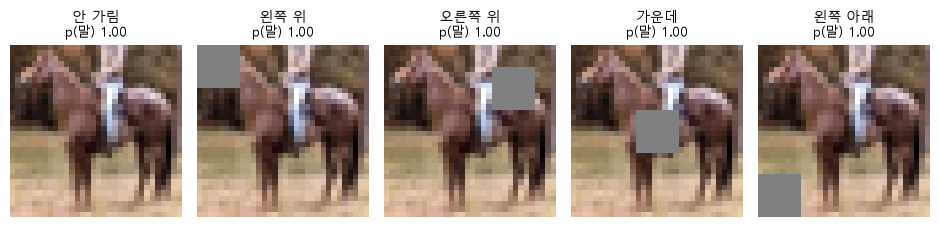

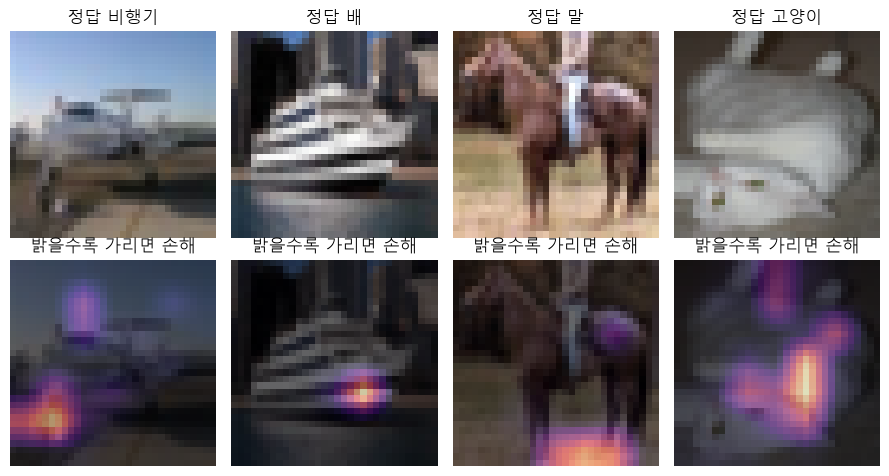

자리 7×7 = 49번 다시 계산 · 사진마다 밝기를 따로 맞춤


In [38]:
# 왜 · 가려 보기 실험에 쓸 사진을 정해 두기 위해
H_I = CLASSES.index("horse")                                                 # 말 번호
h_occ = int(((y_val == H_I) & (pred == y_val) & (conf > 0.9)).nonzero()[0])  # 확신 높게 맞힌 말
# 가릴 자리 (세로, 가로)
spots = {"안 가림": None, "왼쪽 위": (0, 0), "오른쪽 위": (4, 20), "가운데": (12, 12),
         "왼쪽 아래": (24, 0)}
imgs_o, titles_o = [], []                                                    # 가린 사진 · 제목
for name, pos in spots.items():                                              # 네 자리 + 안 가림
    x_o = x_val[h_occ].float().clone()                                       # 원본 복사
    if pos is not None:                                                      # 가릴 자리
        x_o[:, pos[0]:pos[0] + 8, pos[1]:pos[1] + 8] = 128.0                 # 8칸 회색 네모
    p_o = predict(model, x_o[None])[0, H_I].item()                           # 말일 확률
    imgs_o.append(x_o)                                                       # 사진
    titles_o.append(f"{name}\np(말) {p_o:.2f}")                              # 제목
show(imgs_o, titles_o, cols=5, size=1.9)                                     # 원리 한 장


# 왜 · 어느 자리를 가리면 확신이 떨어지는지 지도로 만들어 모델이 본 곳을 짐작하기 위해
def occlusion(img, label, patch=8, stride=4):          # 자리마다 가렸을 때 정답 확률이 떨어진 폭
    base = predict(model, img[None])[0, label].item()  # 안 가렸을 때
    n_ = (32 - patch) // stride + 1                    # 한 변 자리 수 (7)
    batch = []                                         # 가린 사진들
    for i in range(n_):                                # 세로 자리
        for j in range(n_):                            # 가로 자리
            x = img.float().clone()                    # 복사
            x[:, i * stride:i * stride + patch, j * stride:j * stride + patch] = 128.0  # 가림
            batch.append(x)                            # 모음
    return (base - predict(model, torch.stack(batch))[:, label]).view(n_, n_)  # 7 × 7 지도


# 왜 · 종류마다 모델이 기대는 자리가 다른지 비교하기 위해
names_o = ["airplane", "ship", "horse", "cat"]                                 # 네 종류
# 종류마다 확신 높게 맞힌 첫 장
picks_o = [int(((y_val == CLASSES.index(c)) & (pred == y_val) & (conf > 0.9)).nonzero()[0])
           for c in names_o]
fig, ax = plt.subplots(2, 4, figsize=(9, 4.8))                                 # 위 원본 · 아래 겹침
for k, i in enumerate(picks_o):                                                # 사진마다
    img = (x_val[i].float() / 255).permute(1, 2, 0).cpu().numpy()              # 그릴 사진
    heat = occlusion(x_val[i], int(y_val[i]))                                  # 7 × 7
    # 7 → 32칸으로 키움
    up = F.interpolate(heat[None, None], size=(32, 32), mode="bilinear")[0, 0].cpu().numpy()
    ax[0, k].imshow(img, interpolation="nearest")                              # 원본
    ax[0, k].set_title(f"정답 {KO[CLASSES[y_val[i]]]}")                        # 제목
    ax[1, k].imshow(img, interpolation="nearest")                              # 바탕
    # 지도 겹치기
    ax[1, k].imshow(up.clip(0), cmap="magma", alpha=0.6, vmin=0, vmax=max(float(heat.max()), 1e-3))
    ax[1, k].set_title("밝을수록 가리면 손해")                                 # 제목
    for a in ax[:, k]:                                                         # 두 칸
        a.axis("off")                                                          # 눈금 끄기
fig.tight_layout()                                                             # 정리
plt.show()                                                                     # 그리기
print(f"자리 {heat.shape[0]}×{heat.shape[1]} = {heat.numel()}번 다시 계산 · "  # 계산 횟수
      f"사진마다 밝기를 따로 맞춤")

**결과** · 예측 정답은 가로 7 × 세로 7 = 49자리

- `자리 7×7 = 49번 다시 계산` — 자리마다 모델을 다시 돌림 · 15장 Grad-CAM은 한 번의 계산
- 첫 그림 · 칸 제목의 p(말) = 그 자리를 가렸을 때 말일 확률
- 둘째 그림 · 밝을수록 가렸을 때 정답 확률이 크게 떨어짐 · 밝기는 사진마다 따로 맞춤

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>밝은 곳이 대상 위</td><td>대상을 보고 판단</td><td>배경 후보를 약하게 함</td></tr>
<tr><td>밝은 곳이 배경 위</td><td>배경에 기댐</td><td>배경 후보를 지지함</td></tr>
<tr><td>경계에 걸침</td><td>판단 보류</td><td>더 많은 사진 · 다른 가리기로 다시</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 네 장뿐 · 가리는 방법 하나 · 회색 네모 자체가 낯선 입력일 수 있음
> - 사진끼리 밝기를 견주지 않음 · 사진마다 따로 맞춘 색

> ✅ **한 줄 정리** · 가려 보기는 자리마다 가렸을 때 정답 확률이 떨어진 폭을 지도로 그려, 모델이 대상과 배경 중 어디에 기대는지 후보를 확인한다.

**딥러닝 코드에서는**

- Captum의 `Occlusion` — 같은 방법의 라이브러리
- 확인한 것과 아직 모르는 것을 나눠 적음 · 데이터로 안 풀리면 구조를 볼 차례

### 9-4. `B` 합성곱 층이 실제로 보는 것 · `features[0].weight` · `features[:3]` <sub>1일차 9장</sub>

> 🎯 **첫 층 필터와 특징 지도는 어떻게 생겼고, 깊은 층은 무엇이 다른가?**

💡 **쉽게 말하면**

- 필터 = 사진 위를 옮겨 가며 곱하고 더하는 **작은 숫자 판**.
- 특징 지도 = 그 계산 결과 · 밝은 곳이 강하게 반응한 자리.

**실행 흐름**

1. 첫 층 필터 여덟 개를 색으로
2. 말 사진의 첫 층 특징 지도 여덟 장
3. 셋째 묶음 첫 합성곱 뒤 지도 여덟 장

**먼저 예측** · 깊은 층 특징 지도는 몇 칸일까? — 답은 코드 실행 결과 아래에

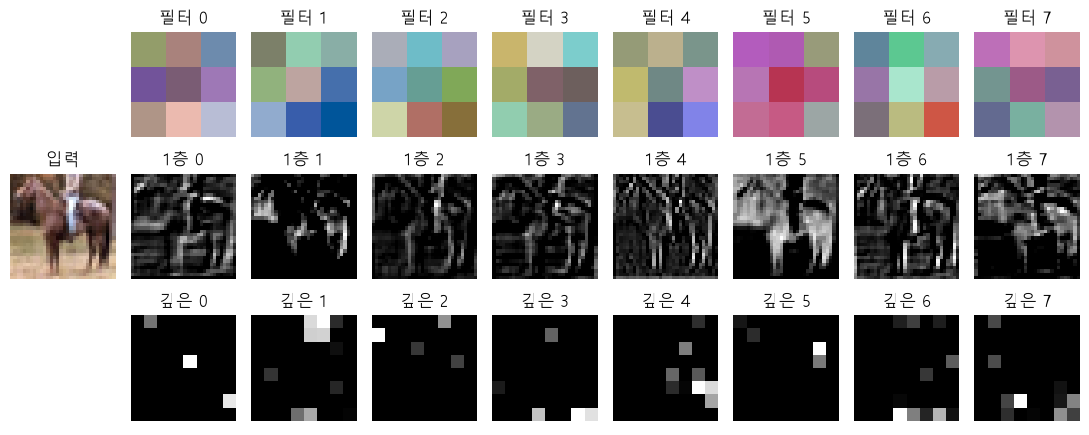

첫 층 필터 (32, 3, 3, 3) · 첫 층 특징 지도 (32, 32, 32) · 깊은 층 (128, 8, 8)


In [39]:
# 왜 · 첫 합성곱 층이 배운 필터 모양을 직접 보기 위해
w1 = model.features[0].weight.detach()           # 첫 층 필터 (32, 3, 3, 3)
wn = (w1 - w1.min()) / (w1.max() - w1.min())     # 0~1로 맞춰 색으로 그림
with torch.no_grad():                            # 특징 지도만 계산
    t_ = to_input(x_val[LOOK:LOOK + 1])          # 말 사진
    a1 = model.features[:3](t_)[0]               # 첫 합성곱 + BN + ReLU 뒤
    a3 = model.features[:17](t_)[0]              # 셋째 묶음 첫 합성곱 뒤
fig, ax = plt.subplots(3, 9, figsize=(11, 4.4))  # 세 줄
for a in ax.flat:                                # 모든 칸
    a.axis("off")                                # 눈금 끄기
# 입력 사진
ax[1, 0].imshow((x_val[LOOK].float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[1, 0].set_title("입력")                       # 사진
for k in range(8):                               # 여덟 개씩
    ax[0, k + 1].imshow(wn[k].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")  # 필터
    ax[0, k + 1].set_title(f"필터 {k}")          # 제목
    ax[1, k + 1].imshow(a1[k].cpu().numpy(), cmap="gray", interpolation="nearest")  # 첫 층 지도
    ax[1, k + 1].set_title(f"1층 {k}")           # 제목
    ax[2, k + 1].imshow(a3[k].cpu().numpy(), cmap="gray", interpolation="nearest")  # 깊은 층 지도
    ax[2, k + 1].set_title(f"깊은 {k}")          # 제목
fig.tight_layout()                               # 정리
plt.show()                                       # 그리기
print(f"첫 층 필터 {tuple(w1.shape)} · 첫 층 특징 지도 {tuple(a1.shape)} · "  # 세 가지 모양
      f"깊은 층 {tuple(a3.shape)}")

**결과** · 예측 정답은 8 × 8 — 줄이기 두 번 (32 → 16 → 8)

- `첫 층 필터 (32, 3, 3, 3)` — (개수, 채널, 세로, 가로) · 3×3 칸 × RGB 작은 컬러 조각
- `첫 층 특징 지도 (32, 32, 32)` — 사진과 같은 32칸 · 자리를 맞대어 볼 수 있음
- `깊은 층 (128, 8, 8)` — 넓은 범위를 섞은 추상적인 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>첫 층</td><td>색 · 밝기 경계 같은 단순한 무늬처럼 보임</td><td>필터 모양을 볼 때</td></tr>
<tr><td>깊은 층</td><td>작은 칸 · 많은 채널 · 해석이 어려움</td><td>무늬의 조합</td></tr>
<tr><td>가려 보기 · Grad-CAM</td><td>사진 위 어디가 중요한가</td><td>판단 근거 후보를 볼 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 첫 층이 경계에 반응하는 것처럼 보여도 단정은 못 함
> - 필터 값은 사람이 정한 것이 아니라 학습이 정함

> ✅ **한 줄 정리** · 첫 층 필터는 작은 컬러 조각이고 특징 지도는 반응한 자리를 보여 주며, 깊은 층일수록 칸은 작고 채널은 많아진다.

**딥러닝 코드에서는**

- `model.layer1.register_forward_hook(...)` — 중간 특징 지도를 꺼내는 방법 (15장)
- pretrained 모델의 첫 층 필터는 정리된 무늬 (13장)

---
## 10. 데이터가 아니라 구조를 바꾼다면

> **이 장의 흐름**
>
> - 모델 크기표와 숫자 세는 법 → ReLU와 AlexNet
> - 그다음 VGG 묶음 · 인셉션 블록 → 보는 범위 · 1×1 · 계산량 → 깊이와 기울기

<img src="images/pfcnn1_ch10.png" alt="세 구조가 바꾼 것" width="584">

**파이프라인 위치** · ⑩ 구조 바꾸기 (성능 비교가 아니라 차이만)

### 10-1. `A` 깊게 쌓는 것과 크게 만드는 것 · 숫자 세는 법 · `weights=None` · `n_params` · `print(model)` <sub>1일차 10장</sub>

> 🎯 **세 구조와 우리 작은 CNN은 층 수와 학습할 숫자가 얼마나 다르고, 그 숫자는 어떻게 세는가?**

💡 **쉽게 말하면**

- 합성곱 숫자 = 입력 채널 × 3 × 3 × 필터 개수 + 편향(필터 개수).
- 사진 크기와는 무관 · 같은 필터를 자리마다 다시 씀.

**실행 흐름**

1. 가중치 없이 모양만 만든 세 구조
2. 합성곱 · 선형 모듈 수와 파라미터
3. 첫 합성곱 · 다른 층 · 마지막 Linear 숫자 직접 세기
4. 우리 모델과 VGG16 첫 묶음 출력

**먼저 예측** · VGG16과 GoogLeNet 중 모듈이 많은 쪽과 숫자가 많은 쪽은? — 답은 코드 실행 결과 아래에

In [40]:
# 왜 · 유명한 구조들을 직접 만들어 크기를 비교하기 위해
from torchvision import models  # 유명한 구조 (가중치 없이 모양만)


def n_params(m):                                   # 학습할 숫자 개수
    return sum(p.numel() for p in m.parameters())  # 가중치 · 편향 전부


def n_layers(m, kinds=(nn.Conv2d, nn.Linear)):             # 합성곱 · 선형 모듈 개수
    return sum(isinstance(x, kinds) for x in m.modules())  # 안쪽까지 셈


# 왜 · 구조마다 가중치 수 · 층 수를 같은 방법으로 세기 위해
nets = {"AlexNet (2012)": models.alexnet(weights=None),       # 모양만 · 숫자는 무작위
        "VGG16 (2014)": models.vgg16(weights=None),
        "GoogLeNet (2014)": models.googlenet(weights=None, aux_logits=False, init_weights=False)}
print(f"{'모델':16s} {'합성곱·선형':>8s} {'파라미터':>13s}")  # 표 머리줄
for name, m in nets.items():                                  # 세 구조
    print(f"{name:16s} {n_layers(m):8d} {n_params(m):13,d}")  # 모듈 수 · 숫자 수
print(f"{'우리 작은 CNN':14s} {n_layers(model):8d} {n_params(model):13,d}")  # 비교
conv1 = model.features[0]                                     # 첫 합성곱
w_ = conv1.weight                                             # (32, 3, 3, 3)
# 직접 센 숫자
print(f"첫 합성곱 가중치 {w_.shape[1]}×{w_.shape[2]}×{w_.shape[3]}×{w_.shape[0]} = {w_.numel():,}"
      f" + 편향 {conv1.bias.numel()} = {n_params(conv1):,}개")
for i in (3, 7, 17):                                          # 다른 합성곱들
    c_ = model.features[i]                                    # 그 층
    print(f"  features[{i:2d}] Conv2d({c_.in_channels}→{c_.out_channels}) — "  # 층별 숫자
          f"{c_.in_channels}×3×3×{c_.out_channels} + {c_.out_channels} = {n_params(c_):,}개")
lin = model.head[3]                                           # 마지막 Linear
print(f"마지막 Linear({lin.in_features}→{lin.out_features}) = {n_params(lin):,}개")  # 128×10+10
print(model.features[:7])  # 첫 묶음 (Conv · BN · ReLU 두 번 + MaxPool)
print(nets["VGG16 (2014)"].features[:5])                      # VGG16 첫 묶음 (BN 없음 · 채널 64)

모델                 합성곱·선형          파라미터
AlexNet (2012)          8    61,100,840
VGG16 (2014)           16   138,357,544
GoogLeNet (2014)       58     6,624,904
우리 작은 CNN             7       289,194
첫 합성곱 가중치 3×3×3×32 = 864 + 편향 32 = 896개
  features[ 3] Conv2d(32→32) — 32×3×3×32 + 32 = 9,248개
  features[ 7] Conv2d(32→64) — 32×3×3×64 + 64 = 18,496개
  features[17] Conv2d(128→128) — 128×3×3×128 + 128 = 147,584개
마지막 Linear(128→10) = 1,290개
Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): C

**결과** · 예측 정답은 모듈은 GoogLeNet(58) · 숫자는 VGG16(1억 3천만)

- `AlexNet (2012) 8 61,100,840` — 숫자 6천만 · 대부분 끝의 Linear
- `VGG16 (2014) 16 138,357,544` — 모듈 16개인데 숫자가 가장 많음
- `GoogLeNet (2014) 58 6,624,904` — 모듈은 많아도 숫자는 적음 · 모듈 개수 ≠ 깊이
- `우리 작은 CNN 7 289,194` — 29만 개
- `첫 합성곱 가중치 3×3×3×32` — 필터 32개 × 필터 하나 27칸 + 편향 32 = 896개
- `마지막 Linear(128→10) = 1,290개` — 128 × 10 + 10

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AlexNet</td><td>큰 필터 · 끝에 큰 Linear 3개</td><td>깊은 CNN이 큰 사진 분류에서 통함을 보임</td></tr>
<tr><td>VGG16</td><td>3×3만 반복 · BN 없음 · 채널 64부터</td><td>단순하고 깊게</td></tr>
<tr><td>GoogLeNet</td><td>여러 갈래 · 1×1로 줄임</td><td>넓고 깊게 하되 가볍게</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 채널이 두 배면 합성곱 하나의 숫자는 대략 네 배 (입력 · 출력 채널이 둘 다 곱해짐)
> - `weights=None`은 모양만 · 학습된 숫자를 받지 않음

> ✅ **한 줄 정리** · 합성곱 숫자는 입력 채널 × 필터 크기 × 필터 개수로 정해지고 사진 크기와 무관하며, 모듈 개수가 많다고 숫자가 많지는 않다.

**딥러닝 코드에서는**

- `torchinfo.summary(model, (1, 3, 224, 224))` — 층별 모양 · 숫자 표
- 모델 크기는 파라미터 수 × 4바이트(float32)로 대략 계산

### 10-2. `A` AlexNet이 통한 이유 하나 — ReLU · 층마다 따라가기 · `torch.sigmoid` · `torch.relu` · `alex.features` <sub>1일차 10장</sub>

> 🎯 **sigmoid 대신 ReLU를 쓰면 왜 깊게 쌓아도 학습 신호가 덜 줄고, AlexNet의 숫자는 어디에 몰려 있는가?**

💡 **쉽게 말하면**

- 학습 신호는 층마다 활성화 함수의 **기울기가 곱해지며** 앞으로 전달됨.
- sigmoid 기울기는 최대 0.25 · ReLU는 양수 쪽에서 1.

**실행 흐름**

1. 두 함수와 기울기 그림
2. 기울기를 10번 곱한 값
3. 224 빈 사진으로 AlexNet 층마다 모양
4. Linear 층마다 숫자 · 합성곱 부분과 비교

**먼저 예측** · AlexNet 학습할 숫자 중 합성곱 부분은 몇 %쯤일까? — 답은 코드 실행 결과 아래에

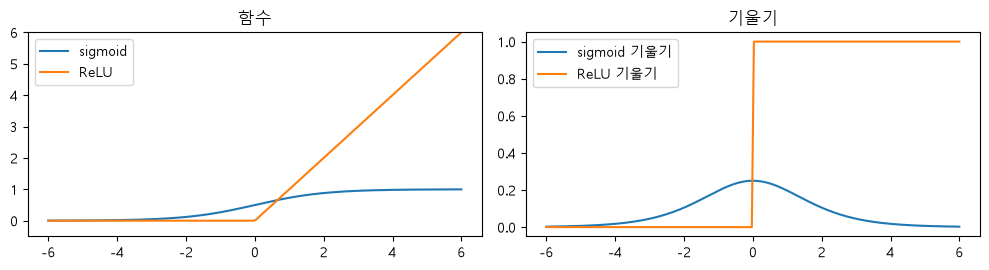

sigmoid 기울기 최댓값 0.25 · ReLU 양수 쪽 1
기울기를 10번 곱하면 — sigmoid 가장 좋은 경우 9.5e-07 · ReLU 1
입력 (1, 3, 224, 224)
  Conv2d    필터 11×11 · 보폭 4 → (1, 64, 55, 55)
  MaxPool2d 필터 3×3 · 보폭 2 → (1, 64, 27, 27)
  Conv2d    필터 5×5 · 보폭 1 → (1, 192, 27, 27)
  MaxPool2d 필터 3×3 · 보폭 2 → (1, 192, 13, 13)
  Conv2d    필터 3×3 · 보폭 1 → (1, 384, 13, 13)
  Conv2d    필터 3×3 · 보폭 1 → (1, 256, 13, 13)
  Conv2d    필터 3×3 · 보폭 1 → (1, 256, 13, 13)
  MaxPool2d 필터 3×3 · 보폭 2 → (1, 256, 6, 6)
끝 (256, 6, 6) → 펼치면 256×6×6 = 9,216개 값
  Linear(9,216→4,096) — 37,752,832개
  Linear(4,096→4,096) — 16,781,312개
  Linear(4,096→1,000) — 4,097,000개
AlexNet 합성곱 부분 2,469,696개 · 전체 61,100,840개


In [41]:
# 왜 · sigmoid와 ReLU의 기울기 차이를 곡선으로 비교하기 위해
z = torch.linspace(-6, 6, 200)                                      # 들어가는 값
sig = torch.sigmoid(z)                                              # sigmoid
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))                     # 왼쪽 함수 · 오른쪽 기울기
ax[0].plot(z, sig, label="sigmoid")                                 # 0~1로 누름
ax[0].plot(z, torch.relu(z), label="ReLU")                          # 음수 0 · 양수 그대로
ax[0].set_ylim(-0.5, 6)                                             # 세로 범위
ax[0].set_title("함수")                                             # 제목
ax[0].legend()                                                      # 범례
ax[1].plot(z, sig * (1 - sig), label="sigmoid 기울기")              # 최대 0.25
ax[1].plot(z, (z > 0).float(), label="ReLU 기울기")                 # 양수 쪽 1
ax[1].set_title("기울기")                                           # 제목
ax[1].legend()                                                      # 범례
fig.tight_layout()                                                  # 정리
plt.show()                                                          # 그리기
print(f"sigmoid 기울기 최댓값 {(sig * (1 - sig)).max():.2f} · ReLU 양수 쪽 1")  # 비교
print(f"기울기를 10번 곱하면 — sigmoid 가장 좋은 경우 {0.25 ** 10:.1e} · ReLU 1")  # 층마다 곱해짐
alex = nets["AlexNet (2012)"]                                       # AlexNet
with torch.no_grad():                                               # 모양만
    t = torch.zeros(1, 3, 224, 224)                                 # 224 × 224 빈 사진
    print(f"입력 {tuple(t.shape)}")                                 # 시작
    for layer in alex.features:                                     # 층마다
        t = layer(t)                                                # 통과
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):            # 합성곱 · 풀링만 찍음
            # 필터 크기 숫자 하나
            k_ = layer.kernel_size if isinstance(layer.kernel_size, int) else layer.kernel_size[0]
            # 보폭 숫자 하나
            s_ = layer.stride if isinstance(layer.stride, int) else layer.stride[0]
            print(f"  {type(layer).__name__:9s} 필터 {k_}×{k_} · "  # 층 · 필터 · 보폭 · 모양
                  f"보폭 {s_} → {tuple(t.shape)}")
print(f"끝 (256, 6, 6) → 펼치면 256×6×6 = {256 * 6 * 6:,}개 값")    # Linear 입력
for m in alex.classifier:                                           # Linear 층마다
    if isinstance(m, nn.Linear):                                    # 학습할 숫자가 몰린 곳
        print(f"  Linear({m.in_features:,}→{m.out_features:,}) — {n_params(m):,}개")  # Linear 숫자
print(f"AlexNet 합성곱 부분 {n_params(alex.features):,}개 · 전체 {n_params(alex):,}개")  # 비율

**결과** · 예측 정답은 약 4% — 나머지는 끝의 Linear

- `sigmoid 기울기 최댓값 0.25 · ReLU 양수 쪽 1` — 곱할수록 차이가 커짐
- `sigmoid 가장 좋은 경우 9.5e-07 · ReLU 1` — 0.25를 10번 곱하면 백만분의 1
- `Conv2d 필터 11×11 · 보폭 4 → (1, 64, 55, 55)` — 보폭 4 = 네 칸씩 건너뜀 → 가로세로 약 4분의 1
- `Linear(9,216→4,096) — 37,752,832개` — 펼친 값 9,216개를 모두 이어서 숫자가 많음
- `AlexNet 합성곱 부분 2,469,696개 · 전체 61,100,840개` — 숫자는 대부분 Linear에 몰림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>sigmoid</td><td>0 ~ 1로 누름 · 기울기 최대 0.25</td><td>출력 확률 (이진 분류 끝)</td></tr>
<tr><td>ReLU</td><td>음수 0 · 양수 그대로 · 기울기 1</td><td>은닉층 기본</td></tr>
<tr><td>GAP (우리 모델)</td><td>채널마다 평균 → 작은 Linear 하나</td><td>Linear 숫자를 크게 줄임</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 가로세로는 줄이고 채널은 늘림 · 우리 SmallCNN과 같은 원칙
> - Linear 앞 가로세로가 크면 펼친 값이 많아져 Linear 숫자가 크게 늘어남

> ✅ **한 줄 정리** · ReLU는 양수 쪽 기울기가 1이라 깊게 쌓아도 신호가 덜 줄고, AlexNet의 숫자는 펼친 값을 모두 잇는 끝의 Linear에 몰려 있다.

**딥러닝 코드에서는**

- `nn.ReLU()`가 거의 모든 CNN의 기본 활성화
- AlexNet이 함께 쓴 것 · ReLU · GPU · dropout · 증강

### 10-3. `A` VGG를 코드로 · GoogLeNet 인셉션 블록 · `vgg_block` · `torch.cat(dim=1)` <sub>1일차 10장</sub>

> 🎯 **VGG는 필터 크기 고민을 어떻게 풀었고, GoogLeNet은 넓고 깊게 하면서 어떻게 가볍게 했는가?**

💡 **쉽게 말하면**

- VGG · 필터를 **3×3 하나로 통일**하고 묶음을 반복해 깊게.
- GoogLeNet · 같은 입력을 **네 갈래로 나눠** 계산하고 채널 방향으로 이어 붙임.

**실행 흐름**

1. `vgg_block` · VGG16 묶음 다섯 개 통과
2. 묶음마다 모양 · 숫자
3. `MiniInception` 네 갈래 모양
4. 1×1로 줄인 5×5 갈래 vs 바로 5×5

**먼저 예측** · 5×5 갈래 앞에 1×1로 채널을 줄이면 숫자는 몇 분의 1이 될까? — 답은 코드 실행 결과 아래에

In [42]:
# 왜 · VGG의 반복 구조를 함수 하나로 만들기 위해
def vgg_block(c_in, c_out, n_conv):                 # 3×3 합성곱 + ReLU를 n번, 끝에 MaxPool
    layers = []                                     # 층 목록
    for i in range(n_conv):                         # n번 반복
        # 3×3 + ReLU
        layers += [nn.Conv2d(c_in if i == 0 else c_out, c_out, 3, padding=1), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2))  # 가로세로 절반


cfg = [(3, 64, 2), (64, 128, 2), (128, 256, 3), (256, 512, 3), (512, 512, 3)]  # VGG16 묶음 다섯
total = 0                                                                      # 합성곱 부분 합계
with torch.no_grad():                                                          # 모양만
    t = torch.zeros(1, 3, 224, 224)                                            # 빈 사진
    for k, (ci_, co_, n_) in enumerate(cfg, 1):                                # 묶음마다
        blk = vgg_block(ci_, co_, n_)                                          # 묶음 만들기
        t = blk(t)                                                             # 통과
        total += n_params(blk)                                                 # 숫자 합
        print(f"  {k}번째 묶음 — 3×3 {n_}번 + 줄이기 → {tuple(t.shape)} · "    # 모양 · 숫자
              f"{n_params(blk):,}개")
print(f"합성곱 부분 {total:,}개 · "                                            # 나머지는 Linear
      f"VGG16 전체 {n_params(nets['VGG16 (2014)']):,}개")


# 왜 · 여러 크기의 필터를 나란히 쓰는 인셉션 블록을 직접 만들어 보기 위해
class MiniInception(nn.Module):           # GoogLeNet 첫 인셉션 블록(3a) 모양
    def __init__(self, c_in):             # 네 갈래
        super().__init__()                # 준비
        self.b1 = nn.Conv2d(c_in, 64, 1)  # 1×1
        # 1×1로 줄인 뒤 3×3
        self.b2 = nn.Sequential(nn.Conv2d(c_in, 96, 1), nn.ReLU(), nn.Conv2d(96, 128, 3, padding=1))
        # 1×1로 줄인 뒤 5×5
        self.b3 = nn.Sequential(nn.Conv2d(c_in, 16, 1), nn.ReLU(), nn.Conv2d(16, 32, 5, padding=2))
        # 풀링 → 1×1
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), nn.Conv2d(c_in, 32, 1))

    def forward(self, x):                    # 나란히 계산 → 채널 방향으로 이어 붙임
        outs = [self.b1(x), self.b2(x), self.b3(x), self.b4(x)]  # 네 결과
        return torch.cat(outs, dim=1), outs  # 가로세로가 같아야 붙음


blk = MiniInception(192)                                                     # 입력 채널 192
with torch.no_grad():                                                        # 모양만
    y_, parts = blk(torch.zeros(1, 192, 28, 28))                             # (1, 192, 28, 28)
for name, o in zip(["1×1", "1×1 → 3×3", "1×1 → 5×5", "풀링 → 1×1"], parts):  # 갈래마다
    print(f"  갈래 {name:10s} → {tuple(o.shape)}")                           # 가로세로 그대로
print(f"이어 붙인 결과 {tuple(y_.shape)} — 채널 64 + 128 + 32 + 32")         # 256
direct = nn.Conv2d(192, 32, 5, padding=2)                                    # 줄이지 않고 바로 5×5
print(f"5×5 갈래 숫자 — 1×1로 먼저 줄이면 {n_params(blk.b3):,}개 · "         # 줄이기 효과
      f"바로 5×5면 {n_params(direct):,}개")

  1번째 묶음 — 3×3 2번 + 줄이기 → (1, 64, 112, 112) · 38,720개
  2번째 묶음 — 3×3 2번 + 줄이기 → (1, 128, 56, 56) · 221,440개
  3번째 묶음 — 3×3 3번 + 줄이기 → (1, 256, 28, 28) · 1,475,328개
  4번째 묶음 — 3×3 3번 + 줄이기 → (1, 512, 14, 14) · 5,899,776개
  5번째 묶음 — 3×3 3번 + 줄이기 → (1, 512, 7, 7) · 7,079,424개
합성곱 부분 14,714,688개 · VGG16 전체 138,357,544개
  갈래 1×1        → (1, 64, 28, 28)
  갈래 1×1 → 3×3  → (1, 128, 28, 28)
  갈래 1×1 → 5×5  → (1, 32, 28, 28)
  갈래 풀링 → 1×1   → (1, 32, 28, 28)
이어 붙인 결과 (1, 256, 28, 28) — 채널 64 + 128 + 32 + 32
5×5 갈래 숫자 — 1×1로 먼저 줄이면 15,920개 · 바로 5×5면 153,632개


**결과** · 예측 정답은 약 10분의 1 — 153,632개 → 15,920개

- `5번째 묶음 — 3×3 3번 + 줄이기 → (1, 512, 7, 7)` — 가로세로가 줄어도 합성곱 숫자는 줄지 않음 (채널이 늘어서)
- `합성곱 부분 14,714,688개 · VGG16 전체 138,357,544개` — 나머지는 끝의 큰 Linear 층 · 16 = 합성곱 13 + Linear 3
- `이어 붙인 결과 (1, 256, 28, 28) — 채널 64 + 128 + 32 + 32` — 가로세로는 모두 28 · 하나라도 다르면 오류
- `1×1로 먼저 줄이면 15,920개 · 바로 5×5면 153,632개` — 채널을 줄이는 요령

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>VGG 묶음</td><td>3×3 두세 번 + MaxPool</td><td>단순 반복으로 깊게</td></tr>
<tr><td>인셉션 블록</td><td>1×1 · 3×3 · 5×5 · 풀링 나란히</td><td>크고 작은 무늬를 함께</td></tr>
<tr><td>1×1 합성곱</td><td>옆 칸은 안 보고 채널만 섞음</td><td>채널을 줄여 계산을 아낌</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - padding은 3×3이면 1 · 5×5면 2 · 풀링은 보폭 1 + padding 1 → 모두 가로세로 유지
> - 모듈은 많아도 입력에서 출력까지 거치는 단계는 몇 개뿐 → 모듈 개수 ≠ 깊이

> ✅ **한 줄 정리** · VGG는 3×3 묶음을 반복해 깊게 쌓았고, GoogLeNet은 여러 갈래를 이어 붙이며 1×1 합성곱으로 채널을 줄여 가볍게 했다.

**딥러닝 코드에서는**

- `torch.cat([a, b], dim=1)` — 채널 방향 이어 붙이기 (U-Net 스킵 연결도 같음)
- `models.vgg16().features` — 묶음 구조 그대로

### 10-4. `B` 3×3을 쌓으면 보는 범위가 넓어짐 · 1×1 · 계산량 · `receptive field` · `jump` <sub>1일차 10장</sub>

> 🎯 **3×3을 여러 번 쌓으면 한 칸은 원래 사진의 몇 칸을 보고, 7×7 한 층과는 무엇이 다른가?**

💡 **쉽게 말하면**

- 보는 범위 = 특징 지도 한 칸이 원래 사진에서 영향을 받은 영역.
- 3×3 세 층 = 7×7 한 층과 같은 범위인데 숫자는 더 적음.

**실행 흐름**

1. 우리 SmallCNN 층 설정으로 보는 범위 계산
2. 7×7 한 층 vs 3×3 세 층 가중치
3. 1×1 256→64
4. 곱셈 수 = 가중치 수 × 자리 수

**먼저 예측** · 우리 SmallCNN 마지막 칸은 원래 사진 32칸을 다 볼까? — 답은 코드 실행 결과 아래에

In [43]:
# 왜 · 층을 지날 때마다 한 칸이 보는 범위가 얼마나 넓어지는지 계산하기 위해
rf, jump = 1, 1  # 보는 범위 · 옆 칸 간격 (원래 사진 기준)
for i, layer in enumerate(model.features):                               # 층 설정만으로 계산
    if isinstance(layer, nn.Conv2d):                                     # 3×3 합성곱
        rf += (layer.kernel_size[0] - 1) * jump                          # (3 - 1) × jump만큼 넓어짐
        print(f"  features[{i:2d}] 3×3 합성곱 뒤 — 보는 범위 {rf}×{rf}")  # 결과
    elif isinstance(layer, nn.MaxPool2d):                                # 줄이기
        rf += (layer.kernel_size - 1) * jump                             # 2칸 창도 넓힘
        jump *= layer.stride                                             # 옆 칸 간격 두 배
        print(f"  features[{i:2d}] MaxPool 뒤 — 보는 범위 {rf}×{rf} · "  # 범위 · 간격
              f"옆 칸 = 원래 {jump}칸")
c = 64                                                                   # 채널
one_7 = nn.Conv2d(c, c, 7, padding=3, bias=False)                        # 7×7 한 층
three_3 = nn.Sequential(*[nn.Conv2d(c, c, 3, padding=1, bias=False) for _ in range(3)])  # 3×3 세 층
print(f"7×7 한 층 {n_params(one_7):,} · "                                # 같은 범위 · 다른 숫자
      f"3×3 세 층 {n_params(three_3):,} · 둘 다 보는 범위 7×7")
one_1 = nn.Conv2d(256, 64, 1, bias=False)                                # 1×1 합성곱
print(f"1×1 256→64 가중치 {n_params(one_1):,} · "                        # 채널만 줄임
      f"모양 {tuple(one_1(torch.zeros(1, 256, 16, 16)).shape)}")
HW = 28 * 28                                                             # 자리 수
m_direct = 192 * 32 * 25 * HW                                            # 바로 5×5: 가중치 × 자리
m_red = (192 * 16 + 16 * 32 * 25) * HW                                   # 1×1로 줄인 뒤 5×5
print(f"곱셈 수 — 바로 5×5 {m_direct:,}번 · 1×1 뒤 5×5 {m_red:,}번 · "   # 계산량 비교
      f"약 {m_direct / m_red:.0f}분의 1")

  features[ 0] 3×3 합성곱 뒤 — 보는 범위 3×3
  features[ 3] 3×3 합성곱 뒤 — 보는 범위 5×5
  features[ 6] MaxPool 뒤 — 보는 범위 6×6 · 옆 칸 = 원래 2칸
  features[ 7] 3×3 합성곱 뒤 — 보는 범위 10×10
  features[10] 3×3 합성곱 뒤 — 보는 범위 14×14
  features[13] MaxPool 뒤 — 보는 범위 16×16 · 옆 칸 = 원래 4칸
  features[14] 3×3 합성곱 뒤 — 보는 범위 24×24
  features[17] 3×3 합성곱 뒤 — 보는 범위 32×32
  features[20] MaxPool 뒤 — 보는 범위 36×36 · 옆 칸 = 원래 8칸
7×7 한 층 200,704 · 3×3 세 층 110,592 · 둘 다 보는 범위 7×7
1×1 256→64 가중치 16,384 · 모양 (1, 64, 16, 16)
곱셈 수 — 바로 5×5 120,422,400번 · 1×1 뒤 5×5 12,443,648번 · 약 10분의 1


**결과** · 예측 정답은 봄 — 마지막 합성곱 뒤 32×32 · MaxPool 뒤 36×36

- `features[ 3] 3×3 합성곱 뒤 — 보는 범위 5×5` — 3×3을 두 번 → 5×5
- `features[ 6] MaxPool 뒤 — 보는 범위 6×6 · 옆 칸 = 원래 2칸` — 줄이면 옆 칸이 원래 사진에서 두 칸 떨어짐
- `features[17] 3×3 합성곱 뒤 — 보는 범위 32×32` — 넓어지는 폭 · 첫 묶음 2칸씩 · 둘째 4칸씩 · 셋째 8칸씩
- `7×7 한 층 200,704 · 3×3 세 층 110,592` — 같은 범위 · 숫자는 약 절반 · 꺾는 곳(ReLU)은 세 번
- `1×1 256→64 가중치 16,384` — 256 × 64 · 9나 25를 곱하지 않음
- `약 10분의 1` — 1×1로 먼저 줄이면 곱셈이 크게 줄어듦

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>3×3 여러 층</td><td>범위는 같고 숫자 적음 · 비선형 많음</td><td>VGG · ResNet 기본</td></tr>
<tr><td>큰 필터 한 층</td><td>숫자 많음</td><td>첫 층에서 빨리 줄일 때 (AlexNet · ResNet stem)</td></tr>
<tr><td>학습할 숫자 vs 계산량</td><td>숫자는 사진 크기와 무관 · 계산은 자리 수만큼</td><td>모델 고를 때 둘 다</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 학습할 숫자가 같아도 사진이 크면 계산량이 커짐
> - 1×1로 채널을 줄이면 일부 정보는 버려짐 · 어떻게 요약할지는 학습이 정함

> ✅ **한 줄 정리** · 3×3을 쌓을수록 한 칸이 보는 범위가 넓어지고, 큰 필터 한 층보다 숫자가 적으며, 계산량은 가중치 수 × 자리 수로 따로 본다.

**딥러닝 코드에서는**

- MobileNet의 depthwise + 1×1(pointwise) — 계산을 줄이는 같은 생각
- 보는 범위가 대상 크기보다 작으면 큰 물체를 한눈에 못 봄

### 10-5. `B` 깊게 쌓으면 기울기는 · 더 보기 CutMix · `first_grad` · `set_yscale('log')` <sub>1일차 10장 · 더 보기</sub>

> 🎯 **층을 많이 쌓으면 첫 층에 닿는 학습 신호는 어떻게 되고, 두 사진을 섞는 증강은 무엇인가?**

💡 **쉽게 말하면**

- 층이 깊을수록 첫 층에 닿는 기울기가 작아짐 · sigmoid는 훨씬 빨리.
- CutMix = 한 사진의 네모 칸을 다른 사진 조각으로 바꾸고 **정답도 넓이만큼 섞음**.

**실행 흐름**

1. Linear 64→64 + 활성화를 층 수만큼 · 무작위 입력으로 한 번 backward
2. 첫 층 기울기 크기 (로그 눈금)
3. 고양이 사진 가운데 12칸을 개 조각으로
4. 모델의 답

**먼저 예측** · 층 40개 sigmoid의 첫 층 기울기는 10의 몇 제곱쯤일까? — 답은 코드 실행 결과 아래에

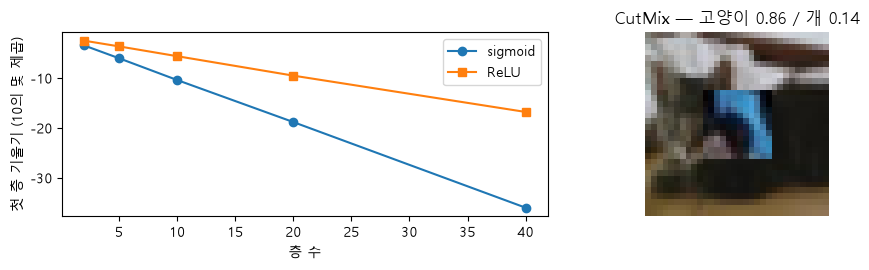

층 2개 — sigmoid 3.4e-04 · ReLU 3.1e-03 / 층 40개 — sigmoid 1.0e-36 · ReLU 1.6e-17
섞은 사진의 정답 비율 — 고양이 0.86 · 개 0.14 / 모델의 답 — 말 0.95 · 트럭 0.02


In [44]:
# 왜 · 깊이와 활성화 함수에 따라 첫 층 기울기가 얼마나 줄어드는지 재기 위해
def first_grad(depth, act):  # 층 depth개 · 한 번 backward 뒤 첫 층 기울기 크기
    torch.manual_seed(0)                             # 같은 시작값
    layers = []                                      # 층 목록
    for _ in range(depth):                           # 층 수만큼
        layers += [nn.Linear(64, 64), act()]         # Linear + 활성화
    net = nn.Sequential(*layers, nn.Linear(64, 10))  # 끝에 점수 10개
    loss = F.cross_entropy(net(torch.randn(32, 64)), torch.randint(0, 10, (32,)))  # 무작위 입력
    loss.backward()                                  # 기울기 (학습은 안 함)
    return net[0].weight.grad.abs().mean().item()    # 첫 층 신호 크기


# 왜 · 깊이를 늘려 가며 기울기 소실을 숫자로 비교하기 위해
depths = [2, 5, 10, 20, 40]                                           # 층 수
g_sig = [first_grad(d, nn.Sigmoid) for d in depths]                   # sigmoid
g_relu = [first_grad(d, nn.ReLU) for d in depths]                     # ReLU
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))                       # 왼쪽 기울기 · 오른쪽 CutMix
ax[0].plot(depths, np.log10(g_sig), "o-", label="sigmoid")            # 빠르게 작아짐
ax[0].plot(depths, np.log10(g_relu), "s-", label="ReLU")              # 천천히
ax[0].set_xlabel("층 수")                                             # 가로축
ax[0].set_ylabel("첫 층 기울기 (10의 몇 제곱)")                       # -10이면 100억분의 1
ax[0].legend()                                                        # 범례
a = int((y_train == CLASSES.index("cat")).nonzero()[0])               # 고양이 한 장
b = int((y_train == CLASSES.index("dog")).nonzero()[0])               # 개 한 장
mixed = x_train[a].clone()                                            # 고양이 복사
mixed[:, 10:22, 10:22] = x_train[b][:, 10:22, 10:22]                  # 12칸 네모를 개 조각으로
share = 12 * 12 / (32 * 32)                                           # 개 조각 넓이 비율
# 섞은 사진
ax[1].imshow((mixed.float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[1].set_title(f"CutMix — 고양이 {1 - share:.2f} / 개 {share:.2f}")  # 정답도 섞음
ax[1].axis("off")                                                     # 눈금 끄기
fig.tight_layout()                                                    # 정리
plt.show()                                                            # 그리기
print(f"층 2개 — sigmoid {g_sig[0]:.1e} · ReLU {g_relu[0]:.1e}"       # 얕을 때 · 깊을 때
      f" / 층 40개 — sigmoid {g_sig[-1]:.1e} · ReLU {g_relu[-1]:.1e}")
pm = predict(model, mixed[None])[0]                                   # 섞은 사진에 낸 답
t2 = pm.argsort(descending=True)[:2]                                  # 가장 큰 두 확률
print(f"섞은 사진의 정답 비율 — 고양이 {1 - share:.2f} · 개 {share:.2f}"  # 정답 비율 · 모델의 답
      f" / 모델의 답 — {KO[CLASSES[t2[0]]]} {pm[t2[0]]:.2f} · {KO[CLASSES[t2[1]]]} {pm[t2[1]]:.2f}")

**결과** · 예측 정답은 10의 -36제곱 — 사실상 0

- `층 2개 — sigmoid 3.4e-04 · ReLU 3.1e-03` — 얕으면 둘 다 신호가 닿음
- `층 40개 — sigmoid 1.0e-36 · ReLU 1.6e-17` — 깊어지면 둘 다 작아지고 sigmoid는 사실상 0
- `섞은 사진의 정답 비율 — 고양이 0.86 · 개 0.14` — 12 × 12 ÷ (32 × 32) ≈ 0.14 = 개 조각 넓이
- `모델의 답 — 말 0.95 · 트럭 0.02` — 섞은 사진은 처음 보는 모습 · 엉뚱한 답을 강하게 확신

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>sigmoid 깊게</td><td>신호가 거의 0</td><td>학습이 안 됨</td></tr>
<tr><td>ReLU 깊게</td><td>덜 줄지만 여전히 작아짐</td><td>깊이 문제가 남음 → 11장 지름길</td></tr>
<tr><td>CutMix</td><td>부분만 보고 강하게 확신하는 버릇을 줄이려는 증강</td><td>더 보기 · 이 노트북 모델에는 안 씀</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - BatchNorm 없는 단순 Linear · 한 가지 시작값 · 한 번 잰 결과 → 숫자보다 방향
> - 로그 눈금은 위아래 같은 거리 = 같은 배수 · 지수를 읽을 것

> ✅ **한 줄 정리** · 층을 많이 쌓으면 첫 층에 닿는 기울기가 급격히 작아지며, 이 깊이 문제를 푼 방법이 다음 장의 지름길(residual)이다.

**딥러닝 코드에서는**

- 기울기 소실 · 폭발을 확인하려면 층별 `p.grad.abs().mean()`을 찍어 봄
- `timm`의 CutMix · Mixup — 학습 때 정답까지 섞어 줌

---
## 11. 깊이 문제와 residual block · ResNet18

> **이 장의 흐름**
>
> - 얕은 망 · 깊은 망 · 지름길 있는 깊은 망의 학습 선 비교 → BN · residual block · F(x) = 0
> - 그다음 실제 블록과 같은지 · 모양이 다를 때 지름길 맞추기 → ResNet18 전체 읽기

<img src="images/pfcnn1_ch11.png" alt="residual block — 출력 = F(x) + x" width="726">

**파이프라인 위치** · ⑪ 구조 — 깊이 문제의 해결 (2일차 1막)

### 11-1. `A` 깊게 쌓으면 끝일까 — 학습 사진에서조차 · `DepthNet` · `residual` <sub>2일차 1막</sub>

> 🎯 **같은 조건에서 깊이만 늘리면 학습 사진 정확도는 어떻게 되고, 지름길을 더하면 달라지는가?**

💡 **쉽게 말하면**

- 학습 사진조차 못 맞히면 외운 것도 아님 → **배우는 과정(최적화) 자체가 막힌 것**.
- 그래서 볼 곳은 검증 선이 아니라 **학습 선**.

**실행 흐름**

1. 3×3 두 층 묶음을 n개 쌓는 망 (지름길 선택)
2. 합성곱 7층 · 19층 · 19층 + 지름길 세 모델
3. 학습 1만 장 · 10에폭 · 같은 조건
4. 평가 모드로 다시 잰 학습 정확도 비교

**먼저 예측** · 깊은 plain(19층)이 얕은 plain(7층)보다 학습 사진을 더 잘 맞힐까? — 답은 코드 실행 결과 아래에

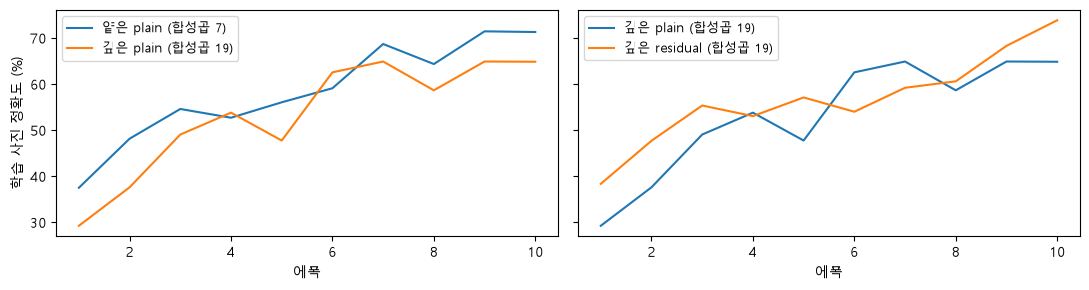

얕은 plain (합성곱 7) — 마지막 학습 71.3% · 검증 63.0%
깊은 plain (합성곱 19) — 마지막 학습 64.9% · 검증 58.3%
깊은 residual (합성곱 19) — 마지막 학습 73.9% · 검증 64.3%


In [45]:
# 왜 · 같은 깊이에서 지름길 유무만 다른 모델을 만들어 공정하게 비교하기 위해
class DepthNet(nn.Module):  # 3×3 합성곱 두 층짜리 묶음을 n개 쌓은 망 (지름길은 선택)
    def __init__(self, n_blocks, residual):                      # 묶음 수 · 지름길 여부
        super().__init__()                                       # 준비
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False),  # 첫 합성곱
                                  nn.BatchNorm2d(32), nn.ReLU())
        self.blocks = nn.ModuleList([nn.Sequential(              # 두 층짜리 묶음 n개
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32))
            for _ in range(n_blocks)])
        self.pools = {n_blocks // 3 - 1, 2 * n_blocks // 3 - 1}  # 1/3 · 2/3 지점에서 줄이기
        self.residual = residual                                 # 지름길 여부
        # 평균 → 점수
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32, 10))

    def forward(self, x):                                            # 묶음을 차례로 통과
        x = self.stem(x)                                             # 첫 합성곱
        for k, b in enumerate(self.blocks):                          # 묶음마다
            x = F.relu(b(x) + x) if self.residual else F.relu(b(x))  # 지름길이면 x를 더함
            if k in self.pools:                                      # 줄이는 자리
                x = F.max_pool2d(x, 2)                               # 가로세로 절반
        return self.head(x)                                          # 점수


# 왜 · 깊이 · residual만 바꾸고 나머지는 같은 조건으로 학습하기 위해
def depth_run(n_blocks, residual, epochs=10):  # 같은 조건으로 학습 → 에폭별 학습 · 검증 정확도
    torch.manual_seed(0)                                                 # 시작값 하나
    m = DepthNet(n_blocks, residual).to(DEV)                             # 새 모델
    o = torch.optim.Adam(m.parameters(), lr=1e-3)                        # 같은 학습률
    rows = []                                                            # 기록
    for e in range(1, epochs + 1):                                       # 에폭
        train_one_epoch(m, o, x_train[:10000], y_train[:10000], seed=e)  # 1만 장
        tra = evaluate(m, x_train[:2000], y_train[:2000])[1] * 100       # 평가 모드로 다시 잰 학습
        rows.append((tra, evaluate(m, x_val, y_val)[1] * 100))           # 검증
    return rows                                                          # [(학습, 검증), ...]


# 왜 · 깊이 · residual 조합별 결과를 한 표에 모으기 위해
D = {}                                                        # 세 모델 기록 (GPU 약 2분)
D["얕은 plain (합성곱 7)"] = depth_run(3, False)              # 기준
D["깊은 plain (합성곱 19)"] = depth_run(9, False)             # 깊이만 바꿈
D["깊은 residual (합성곱 19)"] = depth_run(9, True)           # 지름길만 더함
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)  # 왼쪽 깊이 · 오른쪽 지름길
for a, keys in zip(ax, (list(D)[:2], list(D)[1:])):           # 두 비교
    for k in keys:                                            # 모델마다
        a.plot(range(1, 11), [r[0] for r in D[k]], label=k)   # 학습 정확도
    a.set_xlabel("에폭")                                      # 가로축
    a.legend(fontsize=9)                                      # 범례
ax[0].set_ylabel("학습 사진 정확도 (%)")                      # 세로축
fig.tight_layout()                                            # 정리
plt.show()                                                    # 그리기
for k, rows in D.items():                                     # 숫자로
    print(f"{k} — 마지막 학습 {rows[-1][0]:.1f}% · 검증 {rows[-1][1]:.1f}%")  # 학습 · 검증

**결과** · 예측 정답은 아님 — 71.3% → 64.9% (깊어졌는데 학습 정확도가 낮음)

- `얕은 plain (합성곱 7) — 마지막 학습 71.3% · 검증 63.0%` — 기준
- `깊은 plain (합성곱 19) — 마지막 학습 64.9% · 검증 58.3%` — 깊어졌는데 학습 사진조차 덜 맞힘 = 최적화 문제
- `깊은 residual (합성곱 19) — 마지막 학습 73.9% · 검증 64.3%` — 같은 깊이에 지름길만 더하자 가장 잘 배움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>과적합</td><td>학습은 높고 검증만 낮음</td><td>1일차 4장 · 데이터 · 증강으로</td></tr>
<tr><td>깊이 문제 (최적화)</td><td>학습 정확도부터 낮음</td><td>지름길 · BN</td></tr>
<tr><td>지름길 (residual)</td><td>층이 차이만 배움</td><td>깊은 망을 학습할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 시작값 하나 · 1만 장 · 10에폭 기록 · 숫자보다 방향을 봄
> - 원본 강의 기록은 8층 · 20층 · 20에폭이었음 · 여기서는 직접 학습해 7층 · 19층 · 10에폭

> ✅ **한 줄 정리** · 깊게 쌓기만 하면 학습 사진조차 덜 맞히는 최적화 문제가 생기고, 같은 깊이에 지름길을 더하면 학습이 쉬워진다.

**딥러닝 코드에서는**

- `torchvision.models.resnet18` · `resnet50` — 지름길이 들어간 표준 깊은 망
- 학습 정확도가 낮으면 과적합이 아니라 최적화부터 의심

### 11-2. `A` BN · residual block · F(x) = 0이면 · `nn.BatchNorm2d` · `F.relu(f + x)` <sub>2일차 1막</sub>

> 🎯 **residual block은 어떻게 생겼고, F(x)가 0이면 왜 입력이 그대로 나오는가?**

💡 **쉽게 말하면**

- 출력 = **F(x) + x** · 층은 x 전체가 아니라 x에 더할 **차이만** 배움.
- 바꿀 게 없으면 F(x) = 0만 배우면 됨 → 쌓아도 앞의 결과를 지키기 쉬움.

**실행 흐름**

1. 말 사진을 ResNet18 stem까지 통과 → x (1, 64, 56, 56)
2. BN 전후 채널 평균 · 표준편차
3. ResidualBlock · PlainBlock 만들기
4. 마지막 BN을 0으로 → 두 블록 출력 비교

**먼저 예측** · 마지막 BN을 0으로 만들면 지름길 없는 두 층의 출력은? — 답은 코드 실행 결과 아래에

In [46]:
from torchvision.models import ResNet18_Weights, resnet18  # 빌려 올 ResNet18

# 왜 · 미리 학습된 가중치와 그 입력 약속(평균 · 표준편차)을 함께 가져오기 위해
W = ResNet18_Weights.IMAGENET1K_V1  # ImageNet으로 미리 학습한 숫자 (13장)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)  # 그 모델의 약속
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)   # 채널별 표준편차


# 왜 · 빌려 온 모델이 배운 것과 같은 크기 · 정규화로 사진을 맞추기 위해
def norm(x):  # 빌려 온 모델의 입력 약속: 224로 키움 · 0~1 · 평균 빼고 표준편차로 나눔
    x = F.interpolate(x.float(), size=224, mode="bilinear", align_corners=False)  # 32 → 224
    return (x / 255 - MEAN) / STD                                                 # 채널마다


net = resnet18(weights=W).to(DEV).eval()  # pretrained ResNet18
with torch.no_grad():                     # 첫 stage 앞까지만 통과 → 블록에 들어갈 특징 지도
    # stem 통과 = (1, 64, 56, 56)
    x = net.maxpool(net.relu(net.bn1(net.conv1(norm(x_val[LOOK:LOOK + 1])))))
print(f"말 사진 → 첫 stage 입력 x {tuple(x.shape)} · 가장 작은 값 {x.min().item():.1f}")  # 0 이상
bn = nn.BatchNorm2d(64).train()           # BN (학습 모드 = 묶음 평균)
t = torch.randn(8, 64, 56, 56) * 5 + 3    # 평균 3 · 표준편차 5로 흩어진 값
o = bn(t)                                 # 채널마다 고르게
print(f"BN 전 채널 평균 {t.mean((0, 2, 3)).mean():.2f} · "  # 흩어진 값
      f"표준편차 {t.std((0, 2, 3)).mean():.2f}")
# 평균 0 · 표준편차 1
print(f"BN 뒤 채널 평균 {o.mean((0, 2, 3)).mean():.2f} · 표준편차 {o.std((0, 2, 3)).mean():.2f}"
      f" · 모양 {tuple(o.shape)} 그대로")


# 왜 · ResNet의 핵심 블록을 직접 만들어 F(x) + x의 뜻을 확인하기 위해
class ResidualBlock(nn.Module):                                 # 출력 = ReLU(F(x) + x)
    def __init__(self, c):                                      # 채널 수 (들어오고 나가는 수 같음)
        super().__init__()                                      # 준비
        self.conv1 = nn.Conv2d(c, c, 3, padding=1, bias=False)  # 편향은 BN이 지움
        self.bn1 = nn.BatchNorm2d(c)                            # 값 고르게
        self.conv2 = nn.Conv2d(c, c, 3, padding=1, bias=False)  # 둘째 합성곱
        self.bn2 = nn.BatchNorm2d(c)                            # 값 고르게

    def forward(self, x):                                          # F(x)를 계산하고 x를 더함
        f = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))  # F(x)
        return F.relu(f + x)                                       # 지름길로 온 x를 더함


# 왜 · 지름길만 뺀 블록과 비교해 residual의 효과를 보기 위해
class PlainBlock(ResidualBlock):  # 같은 두 층 · 지름길 없음
    def forward(self, x):         # 출력 = ReLU(F(x))
        return F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x))))))  # x를 안 더함


block, plain = ResidualBlock(64).to(DEV).eval(), PlainBlock(64).to(DEV).eval()    # 두 블록
print(f"residual block 출력 {tuple(block(x).shape)} · "                           # 모양 그대로
      f"학습할 숫자 {n_params(block):,}개")
with torch.no_grad():  # 마지막 BN을 0으로 → F(x) = 0
    for b in (block, plain):                                                      # 두 블록 모두
        b.bn2.weight.zero_()                                                      # 배율 0
        b.bn2.bias.zero_()                                                        # 이동 0
print("residual block — 출력이 입력 x와 똑같은가:", torch.allclose(block(x), x))  # ReLU(0 + x) = x
print("지름길 없는 두 층 — 출력이 전부 0인가:", bool((plain(x) == 0).all()))      # ReLU(0) = 0

말 사진 → 첫 stage 입력 x (1, 64, 56, 56) · 가장 작은 값 0.0
BN 전 채널 평균 3.00 · 표준편차 5.00
BN 뒤 채널 평균 -0.00 · 표준편차 1.00 · 모양 (8, 64, 56, 56) 그대로
residual block 출력 (1, 64, 56, 56) · 학습할 숫자 73,984개
residual block — 출력이 입력 x와 똑같은가: True
지름길 없는 두 층 — 출력이 전부 0인가: True


**결과** · 예측 정답은 전부 0 — residual block은 입력 그대로

- `첫 stage 입력 x (1, 64, 56, 56) · 가장 작은 값 0.0` — 앞 층 ReLU를 지나 0 이상
- `BN 뒤 채널 평균 -0.00 · 표준편차 1.00 · 모양 (8, 64, 56, 56) 그대로` — 값의 크기만 고르게 · 모양은 그대로
- `residual block 출력 (1, 64, 56, 56) · 학습할 숫자 73,984개` — 가로세로 · 채널 그대로 → 더할 수 있음
- `residual block — 출력이 입력 x와 똑같은가: True` — ReLU(0 + x) = x (x가 0 이상이라서)
- `지름길 없는 두 층 — 출력이 전부 0인가: True` — ReLU(0) = 0 · 입력이 사라짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>PlainBlock</td><td>출력 = ReLU(F(x))</td><td>'아무것도 안 하기'도 새로 배워야 함</td></tr>
<tr><td>ResidualBlock</td><td>출력 = ReLU(F(x) + x)</td><td>F(x) = 0이면 그대로 통과</td></tr>
<tr><td>BatchNorm</td><td>채널마다 평균 빼고 표준편차로 나눔 + 배율 · 이동</td><td>층 사이 값 크기를 고르게</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - BN이 평균을 빼므로 바로 앞 합성곱의 편향은 지워짐 → `bias=False`
> - 더하기는 마지막 ReLU 앞에서 · 학습 때 BN은 묶음 평균, 평가 때는 모아 둔 평균

> ✅ **한 줄 정리** · residual block은 출력 = F(x) + x라서 F(x) = 0만 배우면 입력을 그대로 지키고, BN은 층 사이 값의 크기를 고르게 맞춘다.

**딥러닝 코드에서는**

- `nn.Conv2d(..., bias=False)` 뒤에 `nn.BatchNorm2d` — ResNet의 기본 짝
- 블록 마지막 BN 배율을 0으로 시작하는 기법(zero-init residual)도 같은 생각

### 11-3. `A` 실제 블록과 같은가 · 모양이 다르면 지름길도 맞춤 · `load_state_dict` · `downsample` <sub>2일차 1막</sub>

> 🎯 **우리가 만든 블록은 ResNet18 안의 블록과 같은가, 가로세로가 줄어드는 곳에서는 지름길을 어떻게 맞추는가?**

💡 **쉽게 말하면**

- 실제 블록의 숫자를 우리 블록에 채워 **같은 출력**인지 확인.
- 모양이 다르면 더할 수 없음 → 지름길에 **1×1 합성곱(stride 2)**.

**실행 흐름**

1. layer1[0]의 state_dict를 우리 블록에 채우기
2. 같은 입력에 출력 비교
3. F(x)만 절반 · 두 배로 바꿔 더하기 실패
4. DownBlock (지름길 1×1 stride 2 + BN) · 실제 downsample

**먼저 예측** · F(x)만 (128, 28, 28)로 바꾸면 무슨 일이 생길까? — 답은 코드 실행 결과 아래에

In [47]:
# 왜 · 직접 만든 블록이 실제 ResNet18 블록과 같은 계산인지 숫자로 검증하기 위해
real = net.layer1[0]                     # ResNet18 첫 stage의 첫 블록
mine = ResidualBlock(64).to(DEV).eval()  # 우리가 만든 블록
print(f"학습할 숫자 — 우리 블록 {n_params(mine):,}개 · "  # 같은 숫자 개수
      f"ResNet18 layer1[0] {n_params(real):,}개")
mine.load_state_dict(real.state_dict())  # 실제 블록의 숫자를 그대로 채움 (이름표 · 모양 같음)
with torch.no_grad():                    # 같은 입력
    # 같은 출력
    print("같은 입력에 두 블록 출력이 똑같은가:", torch.allclose(mine(x), real(x), atol=1e-5))
bad = ResidualBlock(64).to(DEV)          # 가로세로 절반 · 채널 두 배로 바꾼 블록
bad.conv1 = nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False).to(DEV)  # F(x) 쪽만 바뀜
bad.bn1 = nn.BatchNorm2d(128).to(DEV)    # 128채널
bad.conv2 = nn.Conv2d(128, 128, 3, padding=1, bias=False).to(DEV)  # 128 → 128
bad.bn2 = nn.BatchNorm2d(128).to(DEV)    # 128채널
try:                                     # 더하기 시도
    bad(x)                               # F(x) (1, 128, 28, 28) + x (1, 64, 56, 56)
except RuntimeError as e:                # 모양이 달라 실패
    print("더하기 실패 —", str(e).split("\n")[0])  # 어느 차원이 다른지


# 왜 · 모양이 바뀌는 블록에서는 지름길도 모양을 맞춰야 한다는 것을 확인하기 위해
class DownBlock(nn.Module):               # 가로세로 절반 · 채널 두 배 · 지름길도 모양을 맞춤
    def __init__(self, c_in, c_out):      # 들어오는 · 나가는 채널
        super().__init__()                # 준비
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=2, padding=1, bias=False)  # 절반 · 두 배
        self.bn1 = nn.BatchNorm2d(c_out)  # 값 고르게
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)  # 크기 유지
        self.bn2 = nn.BatchNorm2d(c_out)  # 값 고르게
        # 지름길 1×1 stride 2 + BN
        self.short = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=2, bias=False),
                                   nn.BatchNorm2d(c_out))

    def forward(self, x):                                          # F(x) + 모양 맞춘 x
        f = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))  # F(x)
        return F.relu(f + self.short(x))                           # 지름길도 (128, 28, 28)


down = DownBlock(64, 128).to(DEV).eval()                                              # 64 → 128
print(f"모양을 맞춘 블록 출력 {tuple(down(x).shape)}")                                # 성공
print(f"지름길 쪽 숫자 {n_params(down.short):,}개 · 블록 전체 {n_params(down):,}개")  # 1×1 + BN
print("실제 ResNet18 layer2[0].downsample:", net.layer2[0].downsample)                # 같은 구성

학습할 숫자 — 우리 블록 73,984개 · ResNet18 layer1[0] 73,984개
같은 입력에 두 블록 출력이 똑같은가: True
더하기 실패 — The size of tensor a (28) must match the size of tensor b (56) at non-singleton dimension 3


모양을 맞춘 블록 출력 (1, 128, 28, 28)
지름길 쪽 숫자 8,448개 · 블록 전체 230,144개
실제 ResNet18 layer2[0].downsample: Sequential(
  (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
  (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


**결과** · 예측 정답은 더하기 실패 — x는 (64, 56, 56)

- `학습할 숫자 — 우리 블록 73,984개 · ResNet18 layer1[0] 73,984개` — 이름표 · 모양이 같아 채울 수 있음
- `같은 입력에 두 블록 출력이 똑같은가: True` — 열 줄 남짓의 코드가 ResNet18의 블록 그 자체
- `더하기 실패 — The size of tensor a (28) must match the size of tensor b (56)` — 어느 차원이 다른지 알려 줌
- `모양을 맞춘 블록 출력 (1, 128, 28, 28)` — 지름길도 같은 모양으로
- `지름길 쪽 숫자 8,448개 · 블록 전체 230,144개` — 1×1 (64 × 128) + BN
- 마지막 출력 · 실제 layer2[0].downsample도 Conv2d(64, 128, 1×1, stride 2) + BatchNorm2d

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>모양이 같은 블록</td><td>x를 그대로 더함</td><td>ResNet18 블록 대부분</td></tr>
<tr><td>모양이 바뀌는 블록</td><td>지름길에 1×1 stride 2 + BN</td><td>stage가 바뀌는 세 곳</td></tr>
<tr><td>1×1 합성곱 쓰임</td><td>GoogLeNet은 줄이기 · ResNet은 모양 맞추기</td><td>채널 수를 바꿀 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - stage가 바뀔 때 가로세로 절반 · 채널 두 배 → F(x)와 x 둘 다 맞춰야 함
> - `load_state_dict`는 이름표와 모양이 정확히 같아야 성공 (1일차 5장)

> ✅ **한 줄 정리** · 우리 블록에 실제 숫자를 채우면 ResNet18 블록과 같은 출력이 나오고, 모양이 바뀌는 곳은 지름길에 1×1 합성곱(stride 2)을 넣어 맞춘다.

**딥러닝 코드에서는**

- `net.layer2[0].downsample` — torchvision 이름
- 직접 정해 보기 · (256, 14, 14) → (512, 7, 7)이면 F(x) 첫 합성곱 stride 2 · 512채널, 지름길 1×1 stride 2 · 512채널

### 11-4. `A` ResNet18 전체 읽기 · `named_children` · `named_modules` <sub>2일차 1막</sub>

> 🎯 **ResNet18은 어떤 부분으로 되어 있고, 18은 무엇을 센 것이며, 숫자는 어디에 몰려 있는가?**

💡 **쉽게 말하면**

- stem → stage 넷(블록 2개씩) → GAP → fc.
- 18 = 학습하는 층 수 · 합성곱 1 + 블록 8 × 2 + fc 1.

**실행 흐름**

1. 맨 위 이름표 읽기
2. 사진 한 장이 층을 지날 때 모양 · 숫자
3. downsample 제외 합성곱 세기
4. 부분별 숫자와 비율

**먼저 예측** · 학습할 숫자가 가장 많이 몰린 stage는? — 답은 코드 실행 결과 아래에

In [48]:
for name, m in net.named_children():                                            # 맨 위 이름표
    # stage면 안쪽 블록 수
    # 왜 · ResNet18의 큰 덩어리와 안쪽 블록 수를 차례로 읽기 위해
    inner = f" · 안에 {type(m[0]).__name__} {len(m)}개" if name.startswith("layer") else ""
    print(f"{name:8s} {type(m).__name__}{inner}")                               # stem · stage · 끝
x_ = norm(x_val[LOOK:LOOK + 1])  # 사진 한 장 (1, 3, 224, 224)
print(f"{'입력':8s} {tuple(x_.shape)}")                                         # 시작
with torch.no_grad():                                                           # 큰 층마다 모양
    for name, m in net.named_children():                                        # 층 차례로
        if name == "fc":                                                        # fc 앞에서 한 줄로
            x_ = torch.flatten(x_, 1)                                           # (1, 512)
        x_ = m(x_)                                                              # 통과
        print(f"{name:8s} {str(tuple(x_.shape)):18s} 학습할 숫자 {n_params(m):,}")  # 모양 · 숫자
# 합성곱 모으기
convs = [m for n, m in net.named_modules() if isinstance(m, nn.Conv2d) and "downsample" not in n]
print(f"합성곱(downsample 제외) {len(convs)}개 + fc 1개 = {len(convs) + 1}")    # 18의 뜻
total = n_params(net)                                                           # 전체
parts = {"stem": ["conv1", "bn1"], "layer1": ["layer1"], "layer2": ["layer2"],  # 부분별 이름
         "layer3": ["layer3"], "layer4": ["layer4"], "fc": ["fc"]}
for k, names in parts.items():                                                  # 부분별
    n = sum(n_params(getattr(net, nm)) for nm in names)                         # 그 부분의 숫자
    print(f"{k:7s} {n:>10,}  {n / total * 100:5.1f}%")                          # 비율
print(f"전체 {total:,}")                                                        # 합

conv1    Conv2d
bn1      BatchNorm2d
relu     ReLU
maxpool  MaxPool2d
layer1   Sequential · 안에 BasicBlock 2개
layer2   Sequential · 안에 BasicBlock 2개
layer3   Sequential · 안에 BasicBlock 2개
layer4   Sequential · 안에 BasicBlock 2개
avgpool  AdaptiveAvgPool2d
fc       Linear
입력       (1, 3, 224, 224)
conv1    (1, 64, 112, 112)  학습할 숫자 9,408
bn1      (1, 64, 112, 112)  학습할 숫자 128
relu     (1, 64, 112, 112)  학습할 숫자 0
maxpool  (1, 64, 56, 56)    학습할 숫자 0
layer1   (1, 64, 56, 56)    학습할 숫자 147,968
layer2   (1, 128, 28, 28)   학습할 숫자 525,568
layer3   (1, 256, 14, 14)   학습할 숫자 2,099,712
layer4   (1, 512, 7, 7)     학습할 숫자 8,393,728
avgpool  (1, 512, 1, 1)     학습할 숫자 0
fc       (1, 1000)          학습할 숫자 513,000
합성곱(downsample 제외) 17개 + fc 1개 = 18
stem         9,536    0.1%
layer1     147,968    1.3%
layer2     525,568    4.5%
layer3   2,099,712   18.0%
layer4   8,393,728   71.8%
fc         513,000    4.4%
전체 11,689,512


**결과** · 예측 정답은 layer4 — 71.8%

- `layer1 Sequential · 안에 BasicBlock 2개` — BasicBlock = 우리가 만든 residual block
- `conv1 (1, 64, 112, 112)` — stem · 7×7 stride 2로 224 → 112 (AlexNet의 큰 첫 필터와 같은 생각)
- `layer4 (1, 512, 7, 7)` — stage마다 가로세로 절반 · 채널 두 배
- `fc (1, 1000)` — ImageNet 1000종 점수 · 우리 문제에 맞게 바꿀 자리 (13장)
- `합성곱(downsample 제외) 17개 + fc 1개 = 18` — downsample의 1×1 세 개는 세지 않는 관례
- `layer4 8,393,728 71.8%` — 뒤 stage일수록 채널이 넓어 숫자가 큼

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>stem</td><td>7×7 stride 2 + MaxPool</td><td>크게 줄이며 시작</td></tr>
<tr><td>layer1 ~ layer4</td><td>블록 2개씩 · stage마다 절반 · 두 배</td><td>특징 뽑기 (backbone)</td></tr>
<tr><td>avgpool + fc</td><td>GAP 뒤 점수</td><td>종류 점수 (head)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 숫자는 대부분 뒤쪽 stage · 앞쪽만 풀면 학습할 숫자가 적음 (13장 Partial)
> - fc 앞에서 `flatten` 필요 · (1, 512, 1, 1) → (1, 512)

> ✅ **한 줄 정리** · ResNet18은 stem · 블록 두 개씩인 stage 넷 · GAP · fc로 되어 있고, 18은 학습하는 층 수이며 숫자는 대부분 layer4에 있다.

**딥러닝 코드에서는**

- `for name, m in model.named_children()` — 처음 보는 모델의 큰 구조 읽기
- backbone(특징)과 head(점수)를 나눠 생각하면 전이학습이 쉬워짐

---
## 12. 어떤 구조를 고를까

> **이 장의 흐름**
>
> - EfficientNet B0 ~ B3 크기표
> - 그다음 ResNet18과 학습할 숫자 · 파일 크기 · 한 장 시간 비교 → 세 상황에서 고르기

<img src="images/pfcnn1_ch12.png" alt="구조를 고를 때 같이 보는 것" width="726">

**파이프라인 위치** · ⑫ 구조 고르기 (2일차 2막)

### 12-1. `B` EfficientNet B0 ~ B3 · 고를 때 같이 보는 비용 · `efficientnet_b0` · `transforms().crop_size` <sub>2일차 2막</sub>

> 🎯 **번호가 커질수록 무엇이 함께 커지고, 숫자가 적은 모델은 늘 빠른가?**

💡 **쉽게 말하면**

- 깊이(층) · 너비(채널) · 해상도(입력 크기)를 **함께** 키움 · 하나만 키우면 금방 한계.
- 고를 때는 정확도와 함께 **숫자 · 파일 크기 · 입력 크기 · 시간**을 봄.

**실행 흐름**

1. B0 ~ B3 모양만 만들어 숫자 세기 · 기본 입력 크기 · 배율
2. ResNet18 · B0 비용 함수 (숫자 · 파일 · 한 장 시간)
3. 숫자 · 파일은 출력 · 시간은 그림으로 (실행마다 달라짐)

**먼저 예측** · B0는 ResNet18보다 숫자가 적은데, 한 장 시간도 늘 짧을까? — 답은 코드 실행 결과 아래에

모델                    학습할 숫자    입력    너비    깊이


EfficientNet-B0    5,288,548   224   1.0   1.0


EfficientNet-B1    7,794,184   240   1.0   1.1


EfficientNet-B2    9,109,994   288   1.1   1.2


EfficientNet-B3   12,233,232   300   1.2   1.4


ResNet18         학습할 숫자 11,689,512개 · 파일 46.8MB · 입력 224
EfficientNet-B0  학습할 숫자 5,288,548개 · 파일 21.4MB · 입력 224


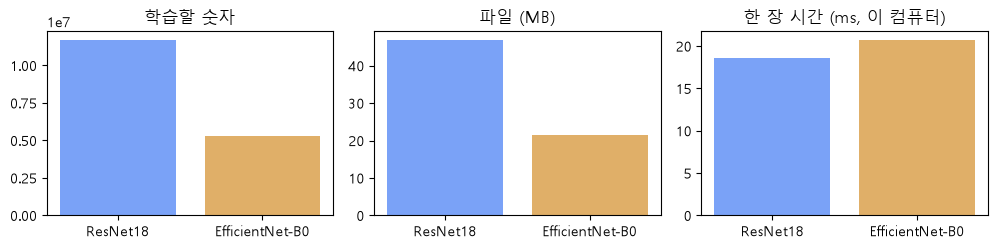

In [49]:
# 왜 · 모델 크기를 파일로 저장하지 않고 메모리에서 재기 위해
import io    # 파일 크기를 메모리에서 잼
import time  # 시간 재기

from torchvision.models import EfficientNet_B0_Weights, EfficientNet_B1_Weights  # 입력 크기 정보
from torchvision.models import EfficientNet_B2_Weights, EfficientNet_B3_Weights  # B2 · B3 정보
from torchvision.models import efficientnet_b0, efficientnet_b1                  # 모양 만들기
from torchvision.models import efficientnet_b2, efficientnet_b3                  # 모양 만들기

# (이름, 만들기, 가중치, 너비 배율, 깊이 배율) · 배율은 torchvision 설정값
EFF = [("B0", efficientnet_b0, EfficientNet_B0_Weights, 1.0, 1.0),  # 기준 모델
       ("B1", efficientnet_b1, EfficientNet_B1_Weights, 1.0, 1.1),
       ("B2", efficientnet_b2, EfficientNet_B2_Weights, 1.1, 1.2),
       ("B3", efficientnet_b3, EfficientNet_B3_Weights, 1.2, 1.4)]
print(f"{'모델':16s} {'학습할 숫자':>11s} {'입력':>5s} {'너비':>5s} {'깊이':>5s}")  # 표 머리줄
for name, make, wts, wm, dm in EFF:                     # 모양만 만들어 셈 (가중치 받지 않음)
    crop = wts.IMAGENET1K_V1.transforms().crop_size[0]  # 그 가중치의 기본 입력 크기
    # 숫자 · 입력 · 배율
    print(f"EfficientNet-{name:3s} {n_params(make(weights=None)):>11,} {crop:>5} {wm:>5} {dm:>5}")


# 왜 · 정확도 말고도 구조를 고를 때 보는 비용(가중치 · 크기 · 시간)을 같은 방법으로 재기 위해
def cost(make, size=224):  # 학습할 숫자 · 파일 크기(MB) · 한 장 시간(ms, CPU · 10번 중 가운데)
    m = make(weights=None).eval()                                        # 모양만
    buf = io.BytesIO()                                                   # 메모리 파일
    torch.save(m.state_dict(), buf)                                      # 저장해 보기
    x = torch.randn(1, 3, size, size)                                    # 사진 한 장
    with torch.no_grad():                                                # 추론만
        for _ in range(3):                                               # 몸풀기
            m(x)                                                         # 첫 실행은 느림
        ts = []                                                          # 시간 기록
        for _ in range(10):                                              # 10번
            t0 = time.perf_counter()                                     # 시작
            m(x)                                                         # 한 장
            ts.append(time.perf_counter() - t0)                          # 걸린 시간
    return n_params(m), len(buf.getvalue()) / 1e6, sorted(ts)[5] * 1000  # 가운데 값


C = {"ResNet18": cost(resnet18), "EfficientNet-B0": cost(efficientnet_b0)}    # 두 모델 비용
for name, (n, mb, _) in C.items():  # 숫자 · 파일 (실행마다 같음)
    print(f"{name:16s} 학습할 숫자 {n:,}개 · 파일 {mb:.1f}MB · 입력 224")     # 비교
fig, ax = plt.subplots(1, 3, figsize=(10, 2.6))                               # 숫자 · 파일 · 시간
# 그림 세 칸
for a, j, title in zip(ax, range(3), ["학습할 숫자", "파일 (MB)", "한 장 시간 (ms, 이 컴퓨터)"]):
    a.bar(list(C), [v[j] for v in C.values()], color=["#7aa2f7", "#e0af68"])  # 두 막대
    a.set_title(title)                                                        # 제목
fig.tight_layout()                                                            # 정리
plt.show()  # 시간은 실행마다 달라지므로 그림으로만

**결과** · 예측 정답은 아닐 수 있음 — 원본 강의 CPU에서는 B0가 더 오래 걸림 · 기기마다 다름

- `EfficientNet-B0 5,288,548 224 1.0 1.0` — 기준 · 입력 224
- `EfficientNet-B3 12,233,232 300 1.2 1.4` — 너비 1.2배 · 깊이 1.4배 · 입력 300
- `ResNet18 학습할 숫자 11,689,512개 · 파일 46.8MB · 입력 224` — 숫자는 B0의 두 배 이상 · 파일 47MB
- `EfficientNet-B0 학습할 숫자 5,288,548개 · 파일 21.4MB · 입력 224` — 숫자 · 파일은 절반 이하
- 그림 오른쪽 · 한 장 시간은 이 컴퓨터에서 잰 값 · 실행할 때마다 달라 비교의 방향만 봄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정확도가 가장 중요</td><td>서버 · 하루 한 번</td><td>같은 조건 정확도 차이가 흔들림보다 큰지</td></tr>
<tr><td>속도가 가장 중요</td><td>초당 여러 장</td><td>그 기기에서 직접 잰 한 장 시간</td></tr>
<tr><td>작은 기기</td><td>저장 · 메모리 빠듯</td><td>파일 크기 · 숫자</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 숫자가 적다고 늘 빠른 것은 아님 · 기기 · 구현에 따라 달라짐
> - 원본 강의 기록 · 같은 조건(Frozen · 43에폭)에서 두 모델 테스트 정확도가 같았고 비용은 B0가 큼 (시드 하나 · 데이터 하나)

> ✅ **한 줄 정리** · EfficientNet은 깊이 · 너비 · 해상도를 함께 키우며, 구조는 정확도와 함께 숫자 · 파일 크기 · 입력 크기 · 그 기기에서의 시간을 보고 고른다.

**딥러닝 코드에서는**

- `weights.transforms()`의 `crop_size` — 모델마다 기본 입력 크기가 다름
- 배포 전 대상 기기에서 `time.perf_counter()`로 직접 재 봄

---
## 13. 남이 배운 눈을 빌려 오기

> **이 장의 흐름**
>
> - 첫 층 필터 · 가까운 사진 → fc 바꾸기 · 입력 약속 → 처음부터 vs 빌려 온 모델
> - 그다음 약속을 어기면 · 고친 사진 → 층별 표현 · 바뀐 정도 → Frozen / Partial / Full · 두 단계

<img src="images/pfcnn1_ch13.png" alt="남이 배운 눈을 빌려 오기" width="577">

**파이프라인 위치** · ⑬ 전이학습 (2일차 3 ~ 4막 · 꽃 사진 대신 CIFAR 1,080장)

### 13-1. `A` 첫 층 필터 · 가장 가까운 사진 찾기 · `ResNet18_Weights.IMAGENET1K_V1` · `F.normalize` <sub>2일차 3막</sub>

> 🎯 **학습을 전혀 하지 않아도 pretrained 특징은 같은 종류끼리 가깝게 모으는가?**

💡 **쉽게 말하면**

- pretrained = ImageNet(백만 장 넘게 · 1000종)으로 **미리 학습해 둔 숫자**.
- fc 앞 512개 숫자(특징)가 비슷한 사진이 같은 종류인지 봄.

**실행 흐름**

1. CIFAR 학습 1,080 · 검증 360 · 테스트 360 (종류마다 같게)
2. 무작위 · pretrained 첫 층 필터 16개
3. fc 앞 특징 512개 · 코사인 유사도
4. 가장 가까운 사진이 같은 종류인 비율

**먼저 예측** · pretrained 특징으로 찾은 가장 가까운 사진은 몇 %가 같은 종류일까? — 답은 코드 실행 결과 아래에

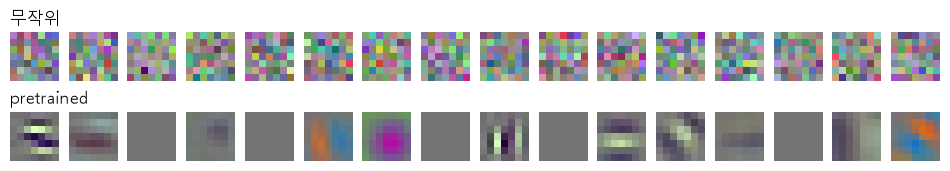

첫 층 필터 모양 (64, 3, 7, 7)
가장 가까운 사진이 같은 종류인 비율 — 무작위 23.9% · pretrained 66.1%


In [50]:
# 왜 · 종류마다 같은 장수를 골라 비교가 한쪽 종류에 치우치지 않게 하기 위해
def take(x, y, per):       # 종류마다 per장씩 (종류 구성을 고르게)
    idx = torch.cat([(y == c).nonzero().flatten()[:per] for c in range(10)])  # 번호 모음
    return x[idx], y[idx]  # 사진 · 정답


xtr, ytr = take(x_train, y_train, 108)            # 학습 1,080장 (강의의 꽃 사진 수와 같게)
xva, yva = take(x_val, y_val, 36)                 # 검증 360장
xte, yte = take(x_test, y_test, 36)               # 테스트 360장
torch.manual_seed(0)                              # 무작위 가중치 고정
rand = resnet18(weights=None).to(DEV).eval()      # 무작위로 시작한 ResNet18
pre = net                                         # pretrained ResNet18 (11장에서 불러옴)
fig, ax = plt.subplots(2, 16, figsize=(12, 1.9))  # 위 무작위 · 아래 pretrained
for row, m in ((0, rand), (1, pre)):              # 두 모델
    f = m.conv1.weight[:16].detach().cpu()        # 첫 층 필터 16개 (7×7 × RGB)
    g = (f - f.min()) / (f.max() - f.min())       # 같은 방식으로 색 범위 맞춤
    for i in range(16):                           # 필터마다
        ax[row, i].imshow(g[i].permute(1, 2, 0))  # 작은 컬러 조각
        ax[row, i].axis("off")                    # 눈금 끄기
    ax[row, 0].set_title(["무작위", "pretrained"][row], loc="left")  # 줄 이름
plt.show()                                        # 그리기


# 왜 · 모델이 사진을 어떤 숫자로 바꾸는지 마지막 층 직전 특징을 꺼내기 위해
def features(m, x, bs=60):                          # fc 앞(avgpool 뒤)까지 통과시킨 512개 숫자
    out = []                                        # 묶음별 결과
    with torch.no_grad():                           # 계산만
        for i in range(0, len(x), bs):              # 묶음마다
            h = norm(x[i:i + bs])                   # 약속대로
            for name, layer in m.named_children():  # 층 차례로
                if name == "fc":                    # fc 앞에서 멈춤
                    break                           # 특징만
                h = layer(h)                        # 통과
            out.append(torch.flatten(h, 1))         # (묶음, 512)
    return F.normalize(torch.cat(out), dim=1)       # 길이 1로 → 내적 = 코사인 유사도


# 왜 · 가장 비슷한 사진이 같은 종류인 비율로 특징의 질을 재기 위해
def nearest_rate(f, y):   # 가장 비슷한 다른 사진이 같은 종류인 비율
    s = f @ f.T           # 모든 짝의 유사도
    s.fill_diagonal_(-1)  # 자기 자신은 빼고
    return (y[s.argmax(1)] == y).float().mean().item() * 100  # %


r_rand = nearest_rate(features(rand, xva), yva)                         # 무작위 특징
r_pre = nearest_rate(features(pre, xva), yva)                           # pretrained 특징
print(f"첫 층 필터 모양 {tuple(pre.conv1.weight.shape)}")               # (64, 3, 7, 7)
print(f"가장 가까운 사진이 같은 종류인 비율 — 무작위 {r_rand:.1f}% · "  # 무작위 vs pretrained
      f"pretrained {r_pre:.1f}%")

**결과** · 예측 정답은 66.1% — 무작위는 23.9%

- `첫 층 필터 모양 (64, 3, 7, 7)` — 7×7 칸 × RGB · 64개
- `무작위 23.9% · pretrained 66.1%` — 학습 없이도 같은 종류끼리 모음 → 이 숫자를 빌려 쓰는 이유
- 그림 · 무작위 필터는 잡음 · pretrained 필터는 가장자리 방향 · 색 덩어리 같은 정리된 무늬

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>무작위 시작</td><td>숫자가 아무 값</td><td>데이터가 많을 때만</td></tr>
<tr><td>pretrained 시작</td><td>기본 무늬를 이미 배움</td><td>데이터가 적을 때</td></tr>
<tr><td>가까운 사진 찾기</td><td>학습 없이 특징 품질 확인</td><td>빌려 오기 전 점검</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원본 강의는 꽃 10종 1,080장 · 여기서는 같은 수의 CIFAR를 224칸으로 키워 씀
> - 이 비율만으로 학습 뒤 정확도를 말할 수는 없음

> ✅ **한 줄 정리** · pretrained 특징은 학습 없이도 같은 종류끼리 가깝게 모으므로, 사진이 적을 때 기본 무늬를 처음부터 배우는 대신 빌려 쓴다.

**딥러닝 코드에서는**

- `resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)` — 옛 코드의 `pretrained=True`와 같은 뜻
- 특징 + 가까운 사진 찾기 = 이미지 검색의 기본 생각

### 13-2. `A` head만 우리 문제에 맞게 — fc 바꾸기 · 입력 약속 · `net.fc = nn.Linear(512, 10)` · `W.transforms()` <sub>2일차 3막</sub>

> 🎯 **빌려 온 모델을 우리 10종 문제에 쓰려면 무엇을 바꾸고, 입력은 어떤 약속을 따라야 하는가?**

💡 **쉽게 말하면**

- fc만 512 → 10으로 **한 줄** 바꿈 · backbone은 빌려 온 숫자 그대로.
- 입력은 **그 모델이 학습 때 쓴 약속**(`weights.transforms()`)을 그대로.

**실행 흐름**

1. 바꾸기 전 점수 모양 (1000)
2. fc를 Linear(512, 10)으로
3. 바꾼 뒤 점수 모양 (10)
4. 가중치의 입력 약속 출력

**먼저 예측** · ImageNet 가중치의 입력 약속은 어떤 크기 · 어떤 평균일까? — 답은 코드 실행 결과 아래에

In [51]:
# 왜 · 빌려 온 모델의 head를 우리 문제에 맞게 바꾸기 전 원래 출력을 확인하기 위해
m_ = resnet18(weights=W).to(DEV).eval()                               # pretrained 그대로
x1 = norm(xva[:1])                                                    # 사진 한 장
with torch.no_grad():                                                 # 모양 확인
    print("바꾸기 전 점수 모양", tuple(m_(x1).shape), "· fc", m_.fc)  # 1000종
m_.fc = nn.Linear(512, 10).to(DEV)                                    # 우리 10종으로 (= 한 줄)
with torch.no_grad():                                                 # 다시 확인
    print("바꾼 뒤 점수 모양", tuple(m_(x1).shape), "· fc", m_.fc)    # 10종
print(W.transforms())  # 이 가중치가 학습 때 쓴 입력 약속


# 왜 · fc만 10종으로 바꾼 같은 구조에 저장한 숫자를 넣어 다시 쓰기 위해
def tl_model(state):            # 저장본 → ResNet18(10종)
    m = resnet18(weights=None)  # 같은 모양
    m.fc = nn.Linear(512, 10)   # 10종
    m.load_state_dict(state)    # 숫자 채우기
    return m.to(DEV).eval()     # 평가 모드

바꾸기 전 점수 모양 (1, 1000) · fc Linear(in_features=512, out_features=1000, bias=True)
바꾼 뒤 점수 모양 (1, 10) · fc Linear(in_features=512, out_features=10, bias=True)
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


**결과** · 예측 정답은 256으로 줄인 뒤 가운데 224 · 평균 [0.485, 0.456, 0.406]

- `바꾸기 전 점수 모양 (1, 1000)` — ImageNet 1000종
- `바꾼 뒤 점수 모양 (1, 10)` — 새 fc는 새로 시작하는 숫자
- `crop_size=[224]` — 가운데 224 잘라 내기
- `resize_size=[256]` — 먼저 256으로 줄임
- `mean=[0.485, 0.456, 0.406]` — 채널마다 평균을 빼고 표준편차로 나눔

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>우리가 정한 약속</td><td>(x / 255 - 0.5) / 0.25</td><td>처음부터 학습한 SmallCNN</td></tr>
<tr><td>빌려 온 모델의 약속</td><td>ImageNet 평균 · 표준편차 · 224</td><td>pretrained 모델</td></tr>
<tr><td>CIFAR 32칸</td><td>224로 키워 넣음 (256 → 224 자르기 대신)</td><td>이 노트북의 <code>norm</code></td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 모델마다 마지막 층 이름이 다름 · ResNet은 `fc` · VGG · EfficientNet은 `classifier`
> - 흑백 사진이면 채널을 3개로 복사해 넣음

> ✅ **한 줄 정리** · 빌려 온 모델은 fc만 우리 종류 수로 바꾸고, 입력은 그 가중치의 `weights.transforms()` 약속을 그대로 따른다.

**딥러닝 코드에서는**

- `model.classifier[-1] = nn.Linear(in_f, n)` — VGG · EfficientNet에서
- `tf = weights.transforms(); x = tf(img)` — 약속을 코드로 받아 씀

### 13-3. `A` 처음부터 대 빌려 온 모델 — 한 조건만 바꾼 비교 · `run_tl` · `requires_grad` <sub>2일차 3 ~ 4막</sub>

> 🎯 **같은 사진 · 같은 학습 조건에서 시작 숫자만 다르면 결과는 얼마나 다른가?**

💡 **쉽게 말하면**

- 바꾼 것 하나 · **시작 가중치**(무작위 대 pretrained).
- 같이 · Frozen(fc만) · Full 두 학습률도 학습해 다음 섹션들에서 씀.

**실행 흐름**

1. 학습 함수 (방식 · 학습률 · 8에폭 · 묶음 32 · checkpoint)
2. scratch · frozen · full 1e-3 · full 1e-4 네 번 학습
3. scratch vs full 1e-3 곡선 (같은 학습률)
4. 검증으로 고른 모델의 테스트

**먼저 예측** · 처음부터 배운 모델과 빌려 온 모델(전부 학습)의 테스트 정확도 차이는? — 답은 코드 실행 결과 아래에

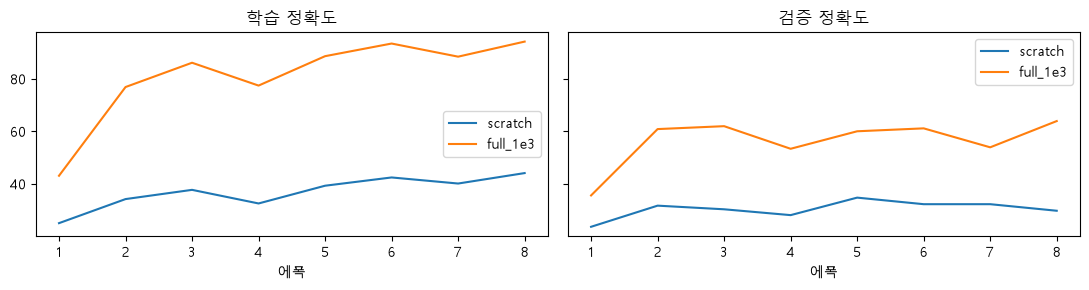

scratch   — 최고 검증 34.7% (에폭 5) · 테스트 31.9%
frozen    — 최고 검증 82.2% (에폭 6) · 테스트 79.4%
full_1e3  — 최고 검증 63.9% (에폭 8) · 테스트 56.7%
full_1e4  — 최고 검증 82.5% (에폭 6) · 테스트 79.2%


In [52]:
@torch.no_grad()
def eval_tl(m, x, y):                                         # 손실 · 정확도 · 확률
    m.eval()                                                  # 평가 모드
    p = torch.cat([m(norm(x[i:i + 60])).softmax(1) for i in range(0, len(x), 60)])  # 확률
    loss = F.nll_loss(p.clamp_min(1e-9).log(), y).item()      # 정답 확률의 -log 평균
    return loss, (p.argmax(1) == y).float().mean().item(), p  # 손실 · 정확도 · 확률


# 왜 · 처음부터 · 얼림 · 전부 학습을 같은 절차로 돌려 한 조건만 바꾼 비교를 하기 위해
def run_tl(mode, lr, epochs=8):  # mode: scratch(무작위 전부) · frozen(fc만) · full(전부)
    torch.manual_seed(0)                                          # 같은 시작값 · 같은 섞기
    m = resnet18(weights=None if mode == "scratch" else W)        # 시작 숫자만 다름
    m.fc = nn.Linear(512, 10)                                     # 10종
    m = m.to(DEV)                                                 # 장치로
    for n, p in m.named_parameters():                             # 얼릴 곳
        p.requires_grad = mode != "frozen" or n.startswith("fc")  # frozen이면 fc만 학습
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=lr)  # 학습할 숫자만
    R_ = {"hist": [], "best_acc": -1.0}                           # 기록
    for e in range(1, epochs + 1):                                # 에폭
        m.eval() if mode == "frozen" else m.train()               # 얼렸으면 BN 평균도 지킴 (고장 6)
        # 에폭마다 섞기
        perm = torch.randperm(len(xtr), generator=torch.Generator().manual_seed(e)).to(DEV)
        for k in range(0, len(xtr), 32):                          # 묶음 32
            i = perm[k:k + 32]                                    # 번호
            loss = F.cross_entropy(m(norm(xtr[i])), ytr[i])       # 손실
            opt.zero_grad()                                       # 지우기
            loss.backward()                                       # 기울기
            opt.step()                                            # 한 걸음
        tra = eval_tl(m, xtr, ytr)[1]                             # 평가 모드 학습 정확도
        vl, va, _ = eval_tl(m, xva, yva)                          # 검증
        R_["hist"].append(dict(train_acc=tra, val_acc=va, val_loss=vl))  # 기록
        if va > R_["best_acc"]:                                   # checkpoint
            R_.update(best_acc=va, best_epoch=e, best=copy.deepcopy(m.state_dict()))  # 저장
    R_["last"] = copy.deepcopy(m.state_dict())                    # 마지막
    return R_                                                     # 기록 · 저장본


# 왜 · 비교할 학습 방식과 학습률을 한곳에 정해 두기 위해
RUNS = {"scratch": ("scratch", 1e-3), "frozen": ("frozen", 1e-3),  # 이름: (방식, 학습률)
        "full_1e3": ("full", 1e-3), "full_1e4": ("full", 1e-4)}
R = {k: run_tl(*v) for k, v in RUNS.items()}                       # 네 번 학습 (GPU 약 2분)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)       # 학습 · 검증
# 학습 · 검증 그림
for a, key, title in ((ax[0], "train_acc", "학습 정확도"), (ax[1], "val_acc", "검증 정확도")):
    for k in ("scratch", "full_1e3"):  # 바꾼 것 = 시작 숫자 (같은 학습률 1e-3)
        a.plot(range(1, 9), [e[key] * 100 for e in R[k]["hist"]], label=k)  # 곡선
    a.set_title(title)                                             # 제목
    a.set_xlabel("에폭")                                           # 가로축
    a.legend()                                                     # 범례


fig.tight_layout()                                                # 정리
plt.show()                                                        # 그리기
TEST = {k: eval_tl(tl_model(R[k]["best"]), xte, yte) for k in R}  # 검증으로 고른 모델의 테스트
for k in R:                                                       # 네 방식
    # 방식별 결과
    print(f"{k:9s} — 최고 검증 {R[k]['best_acc'] * 100:.1f}% (에폭 {R[k]['best_epoch']})"
          f" · 테스트 {TEST[k][1] * 100:.1f}%")

**결과** · 예측 정답은 31.9% vs 56.7% (같은 학습률 1e-3) · Frozen · 작은 학습률이면 79%대

- `scratch — 최고 검증 34.7% (에폭 5) · 테스트 31.9%` — 학습 사진이 적어 처음부터는 크게 부족
- `frozen — 최고 검증 82.2% (에폭 6) · 테스트 79.4%` — backbone 그대로 · fc만 학습
- `full_1e3 — 최고 검증 63.9% (에폭 8) · 테스트 56.7%` — 같은 학습률로 전부 풀면 빌려 온 숫자가 망가짐
- `full_1e4 — 최고 검증 82.5% (에폭 6) · 테스트 79.2%` — 학습률을 낮추면 Frozen 수준으로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>scratch</td><td>무작위 시작 · 전부 학습</td><td>데이터가 아주 많을 때</td></tr>
<tr><td>pretrained + Frozen</td><td>fc만 학습 · 학습할 가중치가 적음</td><td>데이터가 적고 비슷한 사진</td></tr>
<tr><td>pretrained + Full</td><td>전부 학습 · 작은 학습률</td><td>데이터가 많거나 사진이 많이 다를 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 시작값 하나 · 8에폭 · CIFAR 1,080장 · 차이의 정확한 크기는 말할 수 없음
> - 원본 강의 꽃 사진에서는 세 방식 모두 거의 다 맞혔음 · CIFAR 장면에서 1e-3 Full이 크게 떨어진 것과 같은 결과

> ✅ **한 줄 정리** · 같은 조건에서 시작 숫자만 바꾸면 빌려 온 모델이 훨씬 낫지만, 전부 풀 때 학습률이 크면 빌려 온 숫자가 망가진다.

**딥러닝 코드에서는**

- `[p for p in m.parameters() if p.requires_grad]` — optimizer에는 학습할 숫자만
- 얼린 backbone은 평가 모드로 두어 BN 평균을 지킴 (14장 고장 6)

### 13-4. `A` 약속을 어기면 · 빌려 온 모델이 고친 사진 · `val_acc(make)` · `only_sc` <sub>2일차 3 ~ 4막</sub>

> 🎯 **같은 Frozen 모델에 입력 약속만 어기면 어떻게 되고, 빌려 온 모델은 어떤 사진을 고쳤는가?**

💡 **쉽게 말하면**

- 모델은 그대로 · **넣는 값의 처리만** 셋으로.
- 처음부터 모델만 틀린 사진 = 빌려 온 모델이 고친 사진.

**실행 흐름**

1. 약속대로 · 255로만 · 0 ~ 255 그대로 검증 정확도
2. 처음부터만 틀림 · 빌려 온 모델만 틀림 세기
3. 고친 사진 여덟 장

**먼저 예측** · 0 ~ 255 그대로 넣으면 정확도는? — 답은 코드 실행 결과 아래에

약속대로 82.2% · 255로만 나눔 40.3% · 0~255 그대로 8.1%
처음부터만 틀림 132장 · 빌려 온 모델만 틀림 43장


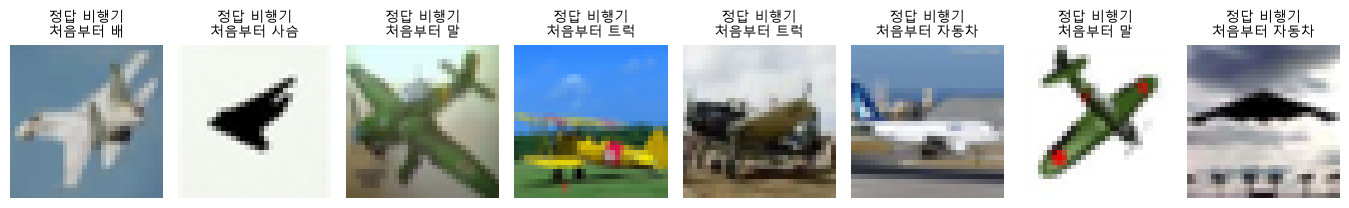

In [53]:
frozen = tl_model(R["frozen"]["best"])  # backbone은 그대로 · fc만 학습한 모델


# 왜 · 입력 약속만 바꿔 같은 모델의 정확도를 비교하기 위해
def val_acc(make):                                 # 같은 모델 · 넣는 값만 다르게
    with torch.no_grad():                          # 계산만
        # 넣는 값만 다르게
        p = torch.cat([frozen(make(xva[i:i + 60])).argmax(1) for i in range(0, len(xva), 60)])
    return (p == yva).float().mean().item() * 100  # 정확도


def up(x):  # 224로 키우기만 (약속의 나머지는 빼고)
    return F.interpolate(x.float(), size=224, mode="bilinear", align_corners=False)  # 32 → 224


a_ok, a_255 = val_acc(norm), val_acc(lambda x: up(x) / 255)    # 약속대로 · 255로만
# 세 결과
print(f"약속대로 {a_ok:.1f}% · 255로만 나눔 {a_255:.1f}% · 0~255 그대로 {val_acc(up):.1f}%")
p_sc, p_pf = TEST["scratch"][2].argmax(1), TEST["full_1e3"][2].argmax(1)  # 두 모델의 테스트 답
only_sc = ((p_sc != yte) & (p_pf == yte)).nonzero().flatten()  # 처음부터만 틀림
only_pf = ((p_pf != yte) & (p_sc == yte)).nonzero().flatten()  # 빌려 온 모델만 틀림
print(f"처음부터만 틀림 {len(only_sc)}장 · 빌려 온 모델만 틀림 {len(only_pf)}장")  # 고친 사진 수
show([xte[i] for i in only_sc[:8]],                            # 빌려 온 모델이 고친 여덟 장
     [f"정답 {KO[CLASSES[yte[i]]]}\n처음부터 {KO[CLASSES[p_sc[i]]]}" for i in only_sc[:8]],
     cols=8, size=1.7)

**결과** · 예측 정답은 8.1% — 찍는 것보다 못함 · 오류 메시지는 없음

- `약속대로 82.2% · 255로만 나눔 40.3% · 0~255 그대로 8.1%` — 1일차 2장과 같은 교훈 · 모델마다 약속을 확인
- `처음부터만 틀림 132장 · 빌려 온 모델만 틀림 43장` — 빌려 온 쪽이 훨씬 많이 고침 · 새로 틀린 사진도 있음
- 그림 · 처음부터 모델은 비슷한 색 · 작은 대상에서 자주 틀림 (모양 · 결을 배울 사진이 부족했을 후보)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>약속대로</td><td>평균 · 표준편차 · 224</td><td>늘</td></tr>
<tr><td>255로만</td><td>평균을 안 뺌</td><td>다른 모델의 약속을 섞을 때 생기는 실수</td></tr>
<tr><td>0 ~ 255 그대로</td><td>변환 없음</td><td>전처리 빠뜨림</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점수가 이상하게 낮으면 입력 약속부터 확인 · 오류가 나지 않음
> - 다른 모델도 같은 약속이라고 가정하지 않음 · 모델마다 `weights.transforms()`

> ✅ **한 줄 정리** · 빌려 온 모델은 약속을 어기면 오류 없이 무너지고, 약속을 지키면 처음부터 모델이 틀린 사진을 많이 고친다.

**딥러닝 코드에서는**

- `timm.data.resolve_data_config(model)` — timm 모델의 약속 확인
- 예측 서비스 코드에 학습 때 transform을 그대로 복사해 씀

### 13-5. `B` 층마다 무엇이 달라지나 · 전부 풀면 어디가 바뀌나 · `layer_feats` · `change(model, stage)` <sub>2일차 4막</sub>

> 🎯 **pretrained의 층별 표현은 뒤로 갈수록 종류를 잘 가르는가, 전부 풀어 학습하면 어느 층이 많이 바뀌는가?**

💡 **쉽게 말하면**

- layer1 ~ layer4 출력마다 가까운 사진이 같은 종류인 비율을 봄.
- 학습 뒤 가중치가 빌려 온 값에서 **얼마나 움직였는지** stage별로 잼.

**실행 흐름**

1. 층별 특징 · 가까운 사진 비율 (pretrained · 무작위 · 전부 학습 뒤)
2. stage별 가중치 변화 (학습률 1e-4 · 1e-3)
3. 두 그림

**먼저 예측** · 전부 풀어 학습(1e-4)하면 가장 많이 바뀌는 stage는? — 답은 코드 실행 결과 아래에

층별 가까운 사진 같은 종류 — pretrained layer1 24.4% · layer2 33.9% · layer3 42.5% · layer4 66.1%
층별 가까운 사진 같은 종류 — 무작위 layer1 18.9% · layer2 21.1% · layer3 23.1% · layer4 23.9%
층별 가까운 사진 같은 종류 — 전부 풀어 학습(1e-4) layer1 26.7% · layer2 30.6% · layer3 46.1% · layer4 80.6%


가중치 변화(학습률 1e-4) — conv1 0.5% · layer1 1.9% · layer2 3.1% · layer3 4.8% · layer4 8.3%
가중치 변화(학습률 1e-3) — conv1 5.1% · layer1 20.1% · layer2 29.8% · layer3 46.6% · layer4 60.6%


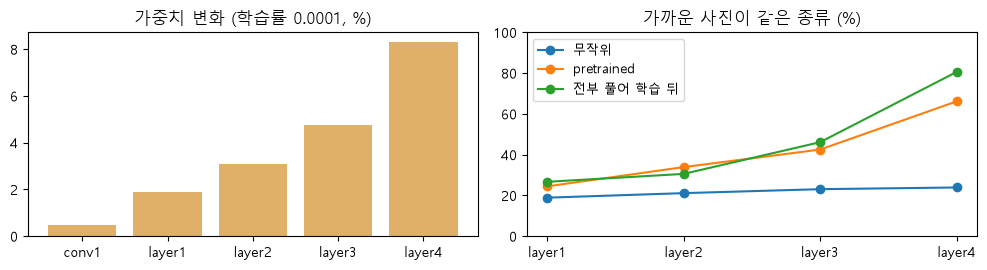

In [54]:
# 왜 · 층마다 특징이 얼마나 쓸모 있는지 같은 기준으로 비교하기 위해
def layer_feats(m, x, bs=60):  # layer1 ~ layer4 출력을 칸마다 평균 → 층마다 사진 요약
    out = {k: [] for k in ("layer1", "layer2", "layer3", "layer4")}       # 층별 결과
    with torch.no_grad():                                                 # 계산만
        for i in range(0, len(x), bs):                                    # 묶음마다
            h = norm(x[i:i + bs])                                         # 약속대로
            for name, layer in m.named_children():                        # 층 차례로
                if name == "avgpool":                                     # 그 앞까지
                    break                                                 # 멈춤
                h = layer(h)                                              # 통과
                if name in out:                                           # stage 출력이면
                    out[name].append(h.mean((2, 3)))                      # 칸마다 평균
    return {k: F.normalize(torch.cat(v), dim=1) for k, v in out.items()}  # 길이 1


r_pre = {k: nearest_rate(v, yva) for k, v in layer_feats(pre, xva).items()}   # pretrained
r_rnd = {k: nearest_rate(v, yva) for k, v in layer_feats(rand, xva).items()}  # 무작위
full4 = tl_model(R["full_1e4"]["best"])  # 전부 풀어 학습(1e-4)한 모델
r_ft = {k: nearest_rate(v, yva) for k, v in layer_feats(full4, xva).items()}  # 학습 뒤
# 세 경우
for name, d in (("pretrained", r_pre), ("무작위", r_rnd), ("전부 풀어 학습(1e-4)", r_ft)):
    txt = " · ".join(f"{k} {v:.1f}%" for k, v in d.items())                   # 층별 비율
    print(f"층별 가까운 사진 같은 종류 — {name} {txt}")                       # 한 줄씩
P0 = pre.state_dict()                                                         # 빌려 온 값


# 왜 · 전부 학습한 뒤 어느 층이 가장 많이 바뀌었는지 재기 위해
def change(model, stage):  # 그 stage 합성곱 가중치가 빌려 온 값에서 바뀐 정도(%)
    S_ = model.state_dict()                                                     # 학습 뒤 값
    keys = [k for k in P0 if k.startswith(stage + ".") and P0[k].dim() == 4]    # 합성곱 가중치만
    moved = sum(((S_[k] - P0[k]) ** 2).sum() for k in keys)                     # 바뀐 양
    return (moved / sum((P0[k] ** 2).sum() for k in keys)).sqrt().item() * 100  # 원래 크기 대비


STAGES = ("conv1", "layer1", "layer2", "layer3", "layer4")              # 앞 → 뒤
full3 = tl_model(R["full_1e3"]["best"])                                 # 같은 학습 · 학습률 1e-3
for name, mm in (("1e-4", full4), ("1e-3", full3)):                     # 두 학습률
    txt = " · ".join(f"{s} {change(mm, s):.1f}%" for s in STAGES)       # stage별 변화
    print(f"가중치 변화(학습률 {name}) — " + txt)                       # 뒤 층일수록 큼
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))                         # 변화량 · 층별 비율
ax[0].bar(STAGES, [change(full4, s) for s in STAGES], color="#e0af68")  # 뒤 층일수록
ax[0].set_title("가중치 변화 (학습률 0.0001, %)")                       # 제목
for d, lab in ((r_rnd, "무작위"), (r_pre, "pretrained"), (r_ft, "전부 풀어 학습 뒤")):  # 세 선
    ax[1].plot(list(d), list(d.values()), "o-", label=lab)              # 층별
ax[1].set_ylim(0, 100)                                                  # 0~100
ax[1].set_title("가까운 사진이 같은 종류 (%)")                          # 제목
ax[1].legend(fontsize=9)                                                # 범례
fig.tight_layout()                                                      # 정리
plt.show()                                                              # 그리기

**결과** · 예측 정답은 layer4 — 8.3% (conv1은 0.5%)

- `pretrained layer1 24.4% · layer2 33.9% · layer3 42.5% · layer4 66.1%` — 뒤 층일수록 같은 종류끼리 가까움
- `무작위 layer1 18.9% · layer2 21.1% · layer3 23.1% · layer4 23.9%` — 층이 깊어져도 그대로
- `전부 풀어 학습(1e-4) layer1 26.7% · layer2 30.6% · layer3 46.1% · layer4 80.6%` — 크게 오른 곳은 layer4
- `conv1 0.5% · layer1 1.9% · layer2 3.1% · layer3 4.8% · layer4 8.3%` — 뒤 층일수록 많이 바뀜
- `conv1 5.1% · layer1 20.1% · layer2 29.8% · layer3 46.6% · layer4 60.6%` — 학습률 1e-3은 앞 층까지 크게 흔듦

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>앞 층 (conv1 · layer1)</td><td>적게 바뀜 · 일반적인 무늬 후보</td><td>얼려 두기 쉬운 곳</td></tr>
<tr><td>뒤 층 (layer4)</td><td>많이 바뀜 · 종류를 가르는 표현</td><td>먼저 풀어 볼 곳</td></tr>
<tr><td>학습률 크게</td><td>앞 층까지 크게 바뀜</td><td>빌려 온 숫자 망가짐 주의</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - '앞 층은 어디에나 통하는 표현'의 증명이 아님 · 이 데이터 · 이 학습의 결과
> - 뒤쪽만 풀면 전부 푼 것만큼 좋은지는 따로 비교해야 앎

> ✅ **한 줄 정리** · pretrained 표현은 뒤 층일수록 종류를 잘 가르고, 전부 풀어도 뒤 층이 더 많이 바뀌므로 뒤쪽부터 푸는 것이 합리적인 출발점이다.

**딥러닝 코드에서는**

- `model.layer4.parameters()`만 optimizer에 넣는 Partial 학습
- 층별 학습률(discriminative lr) — 뒤 층 크게 · 앞 층 작게

### 13-6. `A` 어디까지 다시 배우게 할까 — Frozen · Partial · Full · 두 단계 · `requires_grad = False` · `param_groups` <sub>2일차 4막</sub>

> 🎯 **얼리는 범위마다 학습할 숫자는 몇 개이고, 안전하게 시작하는 흔한 방법은 무엇인가?**

💡 **쉽게 말하면**

- `requires_grad = False` = 그 숫자는 학습에서 **안 바뀜**(얼림).
- 두 단계 · ① fc만 크게 ② 전부 풀고 작게.

**실행 흐름**

1. Frozen · Partial(layer4 + fc) · Full 학습할 숫자
2. 1단계 · backbone 얼리고 fc만 · 학습률 1e-3
3. 2단계 · 전부 풀고 backbone 1e-5 · fc 1e-4

**먼저 예측** · Partial(layer4 + fc)은 Full의 몇 %쯤일까? — 답은 코드 실행 결과 아래에

In [55]:
# 왜 · 방식마다 실제로 학습하는 숫자의 수를 세어 비용 차이를 보기 위해
def trainable(mode):                                                  # 얼리는 방식별 학습할 숫자
    m = resnet18(weights=None)                                        # 모양만 (숫자는 세기만)
    m.fc = nn.Linear(512, 10)                                         # 10종
    for name, p in m.named_parameters():                              # 이름표마다
        if mode == "frozen":                                          # fc만
            p.requires_grad = name.startswith("fc")                   # 나머지 얼림
        elif mode == "partial":                                       # layer4 + fc
            p.requires_grad = name.startswith(("layer4", "fc"))       # 뒤쪽만
        else:                                                         # full
            p.requires_grad = True                                    # 전부
    return sum(p.numel() for p in m.parameters() if p.requires_grad)  # 학습할 숫자


print(f"학습할 숫자 — Frozen {trainable('frozen'):,}"                         # 세 방식 숫자
      f" · Partial {trainable('partial'):,}"
      f" · Full {trainable('full'):,}")
m = resnet18(weights=W)                                                       # 두 단계로 시작하기
m.fc = nn.Linear(512, 10)                                                     # 새 fc
for p in m.parameters():                                                      # 1단계 — 전부 얼림
    p.requires_grad = False                                                   # 기울기 끔
for p in m.fc.parameters():                                                   # fc만 다시 켬
    p.requires_grad = True                                                    # 학습
opt1 = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3)  # 크게
n1 = sum(p.numel() for p in m.parameters() if p.requires_grad)                # 1단계 숫자
print(f"1단계 — 학습할 숫자 {n1:,}개 · 학습률 {opt1.param_groups[0]['lr']}")  # fc만
for p in m.parameters():                                                      # 2단계 — 전부 풂
    p.requires_grad = True                                                    # 기울기 켬
backbone = [p for n, p in m.named_parameters() if not n.startswith("fc")]     # fc 말고 전부
opt2 = torch.optim.Adam([{"params": backbone, "lr": 1e-5},                    # 작게 다듬기
                         {"params": m.fc.parameters(), "lr": 1e-4}])
print(f"2단계 — 학습할 숫자 {sum(p.numel() for p in m.parameters()):,}개"     # 2단계 설정
      f" · 학습률 backbone {opt2.param_groups[0]['lr']} · fc {opt2.param_groups[1]['lr']}")

학습할 숫자 — Frozen 5,130 · Partial 8,398,858 · Full 11,181,642
1단계 — 학습할 숫자 5,130개 · 학습률 0.001
2단계 — 학습할 숫자 11,181,642개 · 학습률 backbone 1e-05 · fc 0.0001


**결과** · 예측 정답은 약 75% — 숫자 대부분이 layer4에 있어서 (11-4)

- `Frozen 5,130 · Partial 8,398,858 · Full 11,181,642` — fc 512 × 10 + 10 = 5130
- `1단계 — 학습할 숫자 5,130개 · 학습률 0.001` — 새 fc가 먼저 자리를 잡음
- `2단계 — 학습할 숫자 11,181,642개 · 학습률 backbone 1e-05 · fc 0.0001` — 이미 좋은 숫자를 조금만 다듬음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>Frozen</td><td>fc만</td><td>사진 적음 · 비슷한 사진 (상황 A · 500장 일상 사진)</td></tr>
<tr><td>Partial</td><td>layer4 + fc</td><td>중간 · 뒤쪽부터 하나씩 늘리며 검증</td></tr>
<tr><td>Full</td><td>전부 · 작은 학습률</td><td>사진 많음 · 많이 다른 사진 (상황 B · 의료 · 위성)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 처음부터 전부 풀면 아무것도 모르는 fc의 큰 기울기가 backbone까지 흔듦 → 두 단계
> - 두 단계가 항상 낫다는 뜻은 아님 · 고르는 기준은 검증

> ✅ **한 줄 정리** · 얼리는 범위는 Frozen · Partial · Full로 정하며, 흔한 안전한 출발은 fc만 먼저 학습한 뒤 전부 풀고 학습률을 낮추는 두 단계다.

**딥러닝 코드에서는**

- `torch.optim.Adam([{'params': backbone, 'lr': 1e-5}, {'params': head, 'lr': 1e-4}])` — 층마다 다른 학습률
- 상황 C(두 종류만 계속 틀림) → 먼저 그 짝의 사진 · 오류부터 확인 (15장)

---
## 14. 고장 진단 — 제대로 학습되고 있나

> **이 장의 흐름**
>
> - 곡선과 checkpoint · 학습률 신호 · 학습률을 줄이는 규칙
> - 그다음 고장 1 ~ 3 → 고장 4 ~ 6

<img src="images/pfcnn1_ch14.png" alt="고장 진단 여섯 가지" width="577">

**파이프라인 위치** · ⑭ 학습 점검 (2일차 5막)

### 14-1. `A` 곡선 · checkpoint · 학습률 신호 · 줄이는 규칙 · `ReduceLROnPlateau` · `axvline` <sub>2일차 5막</sub>

> 🎯 **마지막 모델을 그대로 써도 되는가, 검증이 크게 출렁이면 무엇부터 의심하는가?**

💡 **쉽게 말하면**

- 학습 곡선은 오르는데 검증은 출렁이면 **마지막 순간이 가장 좋은 순간이 아님**.
- 빌려 온 모델인데 검증이 크게 오르내리면 **학습률부터** 의심.

**실행 흐름**

1. 처음부터 모델 곡선 + 최고 에폭
2. 전부 풀기 학습률 1e-3 vs 1e-4 검증 곡선
3. 기록된 검증 손실에 ReduceLROnPlateau 규칙만 적용
4. best vs last 테스트

**먼저 예측** · 처음부터 모델은 마지막 모델과 검증 최고 모델 중 어느 쪽 테스트가 높을까? — 답은 코드 실행 결과 아래에

학습률 0.001 · 3에폭 이후 검증 — 가장 낮음 53.3% · 가장 높음 63.9%
학습률 0.0001 · 3에폭 이후 검증 — 가장 낮음 81.1% · 가장 높음 82.5%


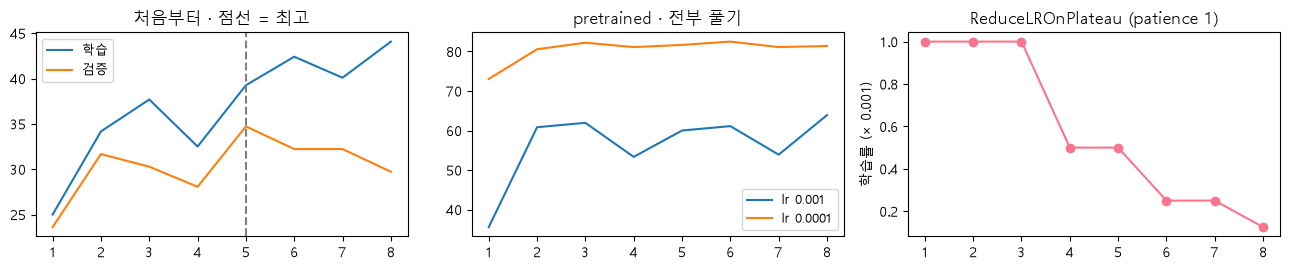

처음부터 — 최고 에폭 5 검증 34.7% · 테스트: 최고 순간 31.9% · 마지막 28.6%
학습률이 줄어든 에폭 [4, 6, 8] · 마지막 학습률 0.000125


In [56]:
# 왜 · 학습 곡선 · checkpoint · 학습률 신호로 고장 여부를 진단하기 위해
sc = R["scratch"]                                                     # 처음부터 배운 모델의 기록
b = sc["best_epoch"]                                                  # 검증 최고 에폭
fig, ax = plt.subplots(1, 3, figsize=(13, 2.8))                       # 곡선 · 학습률 · 줄이는 규칙
ax[0].plot(range(1, 9), [e["train_acc"] * 100 for e in sc["hist"]], label="학습")  # 계속 오름
ax[0].plot(range(1, 9), [e["val_acc"] * 100 for e in sc["hist"]], label="검증")  # 출렁임
ax[0].axvline(b, color="gray", ls="--")                               # 최고 에폭
ax[0].set_title("처음부터 · 점선 = 최고")                             # 제목
ax[0].legend(fontsize=9)                                              # 범례
for k, lab in (("full_1e3", "lr 0.001"), ("full_1e4", "lr 0.0001")):  # 학습률만 다름
    v = [e["val_acc"] * 100 for e in R[k]["hist"]]                    # 검증 곡선
    ax[1].plot(range(1, 9), v, label=lab)                             # 선
    print(f"학습률 {lab[3:]} · 3에폭 이후 검증 — 가장 낮음 {min(v[2:]):.1f}% · "  # 출렁임 범위
          f"가장 높음 {max(v[2:]):.1f}%")
ax[1].set_title("pretrained · 전부 풀기")                             # 제목
ax[1].legend(fontsize=9)                                              # 범례
dummy = torch.zeros(1, requires_grad=True)                            # 학습 없이 규칙만 돌려 봄
opt = torch.optim.SGD([dummy], lr=1e-3)                               # 시작 학습률
# 1번 안 좋아지면 절반
sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=1)
lrs = []                                                              # 에폭별 학습률
for e in R["full_1e3"]["hist"]:                                       # 기록된 검증 손실을 그대로
    sch.step(e["val_loss"])                                           # 규칙 적용
    lrs.append(opt.param_groups[0]["lr"])                             # 기록
ax[2].plot(range(1, 9), [v * 1000 for v in lrs], "o-", color="#f7768e")  # 학습률 (× 0.001)
ax[2].set_ylabel("학습률 (× 0.001)")                                  # 1 → 0.5 → 0.25 …
ax[2].set_title("ReduceLROnPlateau (patience 1)")                     # 제목
fig.tight_layout()                                                    # 정리
plt.show()                                                            # 그리기
last_t = eval_tl(tl_model(sc["last"]), xte, yte)[1] * 100             # 마지막 모델 테스트
print(f"처음부터 — 최고 에폭 {b} 검증 {sc['hist'][b - 1]['val_acc'] * 100:.1f}%"  # best vs last
      f" · 테스트: 최고 순간 {TEST['scratch'][1] * 100:.1f}% · 마지막 {last_t:.1f}%")
drops = [i + 1 for i in range(1, len(lrs)) if lrs[i] < lrs[i - 1]]    # 줄어든 에폭
print(f"학습률이 줄어든 에폭 {drops} · 마지막 학습률 {lrs[-1]:.6f}")  # 규칙 결과

**결과** · 예측 정답은 최고 순간 31.9% · 마지막 28.6%

- `학습률 0.001 · 3에폭 이후 검증 — 가장 낮음 53.3% · 가장 높음 63.9%` — 출렁임이 큼 (10%p 넘게)
- `학습률 0.0001 · 3에폭 이후 검증 — 가장 낮음 81.1% · 가장 높음 82.5%` — 안정적
- `처음부터 — 최고 에폭 5 검증 34.7% · 테스트: 최고 순간 31.9% · 마지막 28.6%` — checkpoint가 마지막보다 나음
- `학습률이 줄어든 에폭 [4, 6, 8] · 마지막 학습률 0.000125` — 안 좋아질 때마다 절반 (다시 학습한 것은 아님)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>checkpoint</td><td>검증 최고 순간 저장</td><td>늘</td></tr>
<tr><td>학습률 낮추기</td><td>출렁임 줄이기</td><td>빌려 온 모델을 전부 풀 때</td></tr>
<tr><td>ReduceLROnPlateau</td><td>나아지지 않으면 자동으로 줄임</td><td>언제 줄일지 모를 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 규칙을 기록에 대입만 함 · 줄였다면 성능이 좋아졌을지는 다시 학습해야 앎
> - patience 1은 8에폭 기록에 맞춘 값 · 보통은 3 ~ 5

> ✅ **한 줄 정리** · 마지막 모델보다 검증 최고 순간을 저장해 쓰고, 빌려 온 모델의 검증이 크게 출렁이면 학습률부터 낮춘다.

**딥러닝 코드에서는**

- `sch = ReduceLROnPlateau(opt, factor=0.5, patience=3); sch.step(val_loss)` — 에폭 끝마다
- 학습 점검표 · 기록 · 학습률 · 바꾼 곳 · 모드 · 평가

### 14-2. `A` 고장 1 ~ 3 — 마지막 층 · 평가 증강 · 섞은 순서 · `==` · `v2.Compose` · `randperm` <sub>2일차 5막</sub>

> 🎯 **오류 메시지 없이 생기는 세 고장은 각각 어떻게 드러나는가?**

💡 **쉽게 말하면**

- 고장 1 · `=` 대신 `==` → fc가 안 바뀜.
- 고장 2 · 평가에 무작위 증강 → 잴 때마다 점수가 다름 · 고장 3 · 섞은 순서로 사진을 잘못 꺼냄.

**실행 흐름**

1. `m.fc == nn.Linear(...)` 뒤 점수 수
2. 평가에 무작위 자르기 · 뒤집기를 넣고 여덟 번
3. 섞어 평가한 뒤 원본 번호로 꺼내기

**먼저 예측** · `==`로 쓰면 점수는 몇 개일까? — 답은 코드 실행 결과 아래에

고장 1 — == 로 쓰면 점수 1000 개
        제대로 바꾸면 점수 10 개


고장 2 — 증강을 넣고 잼 66.7% · 61.5% · 증강 없이 77.1% · 77.1%


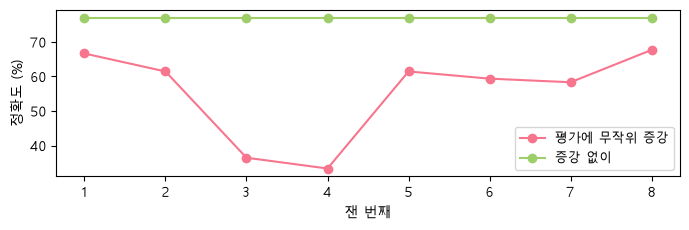

고장 3 — 섞인 순서 1번 틀림 · 답 고양이 · 원본 1번 정답 비행기(잘못) · 순서표 거친 정답 사슴


In [57]:
# 왜 · 평가 때 증강을 켜는 고장을 재현하기 위해
from torchvision.transforms import v2  # 무작위 변환 묶음 (고장 2)

torch.manual_seed(0)                                                           # 무작위 변환 고정
m = resnet18(weights=W).to(DEV).eval()                                         # 고장 1
m.fc == nn.Linear(512, 10)  # = 가 아니라 == · 비교만 하고 버림 (오류 없음)
with torch.no_grad():                                                          # 점수 모양 확인
    print("고장 1 — == 로 쓰면 점수", m(norm(xte[:1])).shape[1], "개")         # 여전히 1000
m.fc = nn.Linear(512, 10).to(DEV)                                              # 제대로 바꾸면
with torch.no_grad():                                                          # 다시 확인
    print("        제대로 바꾸면 점수", m(norm(xte[:1])).shape[1], "개")       # 10
aug = v2.Compose([v2.RandomResizedCrop(32, scale=(0.5, 1.0), antialias=True),  # 고장 2
                  v2.RandomHorizontalFlip()])
xx, yy = xte[:96], yte[:96]                                                    # 같은 사진 96장


# 왜 · 같은 사진에 대한 정확도를 여러 번 재서 흔들림을 확인하기 위해
def acc(t):                                                                   # frozen 모델 정확도
    with torch.no_grad():                                                     # 계산만
        return (frozen(norm(t)).argmax(1) == yy).float().mean().item() * 100  # %


with_aug = [acc(aug(xx)) for _ in range(8)]  # 평가에 증강을 넣고 여덟 번
without = [acc(xx) for _ in range(8)]                                     # 증강 없이 여덟 번
print(f"고장 2 — 증강을 넣고 잼 {with_aug[0]:.1f}% · {with_aug[1]:.1f}%"  # 흔들림
      f" · 증강 없이 {without[0]:.1f}% · {without[1]:.1f}%")              # 같은 값
fig, ax = plt.subplots(figsize=(7, 2.4))                                  # 여덟 번 잰 값
ax.plot(range(1, 9), with_aug, "o-", color="#f7768e", label="평가에 무작위 증강")  # 흩어짐
ax.plot(range(1, 9), without, "o-", color="#9ece6a", label="증강 없이")   # 한 값
ax.set_xlabel("잰 번째")                                                  # 가로축
ax.set_ylabel("정확도 (%)")                                               # 세로축
ax.legend(fontsize=9)                                                     # 범례
fig.tight_layout()                                                        # 정리
plt.show()                                                                # 그리기
order = torch.randperm(len(xte), generator=torch.Generator().manual_seed(0)).to(DEV)  # 고장 3
xs, ys = xte[order], yte[order]                                           # 섞어서 평가
with torch.no_grad():                                                     # 답
    # 섞인 순서의 답
    p3 = torch.cat([frozen(norm(xs[i:i + 60])).argmax(1) for i in range(0, len(xs), 60)])
j = int((p3 != ys).nonzero()[0])                                          # 섞인 순서에서 틀린 자리
print(f"고장 3 — 섞인 순서 {j}번 틀림 · 답 {KO[CLASSES[p3[j]]]}"          # 잘못 꺼냄 vs 제대로
      f" · 원본 {j}번 정답 {KO[CLASSES[yte[j]]]}(잘못) · 순서표 거친 정답 {KO[CLASSES[ys[j]]]}")

**결과** · 예측 정답은 1000개 — 바뀌지 않음

- `고장 1 — == 로 쓰면 점수 1000 개` — 비교만 하고 버림 · 오류 없음
- `제대로 바꾸면 점수 10 개` — 바꾼 뒤 점수 모양을 한 번 찍어 보면 찾음
- `고장 2 — 증강을 넣고 잼 66.7% · 61.5%` — 같은 사진 · 같은 모델인데 점수가 다름
- `증강 없이 77.1% · 77.1%` — 무작위 변환은 학습에만
- `원본 1번 정답 비행기(잘못) · 순서표 거친 정답 사슴` — 섞었으면 순서표를 거쳐 꺼냄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>고장 1</td><td>fc가 그대로</td><td>바꾼 뒤 출력 모양 확인</td></tr>
<tr><td>고장 2</td><td>평가 점수가 흔들림</td><td>평가 transform에 무작위 없음</td></tr>
<tr><td>고장 3</td><td>오류 분석이 엉뚱한 사진 위에서</td><td>평가는 섞지 않거나 순서표 사용</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 세 고장 모두 오류 메시지가 없음 · 숫자만 이상함
> - 모델마다 마지막 층 이름이 다름 · 없는 이름에 대입하면 새 속성만 생김

> ✅ **한 줄 정리** · `==` 대입 · 평가 증강 · 섞은 순서는 오류 없이 결과만 망가뜨리므로, 바꾼 뒤 모양 · 두 번 잰 점수 · 꺼낸 사진의 정답을 확인한다.

**딥러닝 코드에서는**

- `DataLoader(val_ds, shuffle=False)` — 평가는 섞지 않는 것이 기본
- `assert model(x).shape[1] == n_classes` — 한 줄 점검

### 14-3. `A` 고장 4 ~ 6 — 학습 사진으로 평가 · optimizer · 얼려도 BN · `opt = Adam(m.fc.parameters())` · `running_mean` <sub>2일차 5막</sub>

> 🎯 **학습 사진으로 재기 · optimizer에 fc만 넘기기 · 얼린 모델을 학습 모드로 두기는 각각 무엇을 망가뜨리는가?**

💡 **쉽게 말하면**

- 고장 4 · 학습 사진 점수는 **외운 정도**.
- 고장 5 · optimizer에 fc만 넘겨도 기울기는 전부 계산 · 고장 6 · 얼려도 학습 모드면 BN 평균이 바뀜.

**실행 흐름**

1. 같은 모델로 학습 사진 200 · 처음 보는 사진 200
2. fc만 optimizer · 한 걸음 뒤 conv1 · fc 변화 · 기울기 계산 수
3. 전부 얼리고 학습 모드로 한 묶음 통과 → BN 평균 변화

**먼저 예측** · 모든 숫자를 얼렸는데 학습 모드로 한 묶음을 넣으면 BN 평균이 바뀔까? — 답은 코드 실행 결과 아래에

In [58]:
scratch = tl_model(R["scratch"]["best"])  # 고장 4 — 처음부터 배운 모델


# 왜 · 종류마다 같은 장수로 학습 · 테스트 사진을 골라 비교하기 위해
def pick(y, k=20):  # 종류마다 k장씩 — 두 묶음의 종류 구성을 같게
    return torch.cat([(y == c).nonzero().flatten()[:k] for c in range(10)])  # 번호


# 왜 · 고장 사례마다 같은 방법으로 정확도를 재기 위해
def acc_of(x, y, idx):                                # 그 묶음에서 정확도
    with torch.no_grad():                             # 계산만
        # 60장씩 답
        p = torch.cat([scratch(norm(x[idx][i:i + 60])).argmax(1) for i in range(0, len(idx), 60)])
    return (p == y[idx]).float().mean().item() * 100  # %


# 왜 · 학습에 쓴 사진으로 평가하면 점수가 부풀려지는 고장을 처음 보는 사진과 비교해 드러내기 위해
a_tr, a_te = acc_of(xtr, ytr, pick(ytr)), acc_of(xte, yte, pick(yte))   # 학습 사진 · 처음 보는 사진
print(f"고장 4 — 같은 모델 · 학습에 쓴 사진 200장 {a_tr:.1f}% · "       # 외운 정도
      f"처음 보는 사진 200장 {a_te:.1f}%")
m = resnet18(weights=W)                                                 # 고장 5
m.fc = nn.Linear(512, 10)                                               # 새 fc
m = m.to(DEV).train()                                                   # 학습 모드
opt = torch.optim.Adam(m.fc.parameters(), lr=1e-3)  # fc만 넘김 · requires_grad는 전부 켜짐
c0, f0 = m.conv1.weight.detach().clone(), m.fc.weight.detach().clone()  # 걸음 전 값
loss = F.cross_entropy(m(norm(xtr[:16])), ytr[:16])                     # 손실
opt.zero_grad()                                                         # 지우기
loss.backward()  # 기울기 (backbone까지 전부 계산됨)
opt.step()                                                              # 한 걸음 (fc만 고침)
print(f"고장 5 — conv1 변화 {(m.conv1.weight - c0).abs().max().item():.4f}"  # conv1 그대로 · fc만
      f" · fc 변화 {(m.fc.weight - f0).abs().max().item():.4f}")
n_grad = sum(p.numel() for p in m.parameters() if p.grad is not None)   # 기울기가 계산된 숫자
print(f"        기울기 계산 {n_grad:,}개 · "                            # 계산 낭비
      f"그중 optimizer가 고친 것 fc {n_params(m.fc):,}개")
m2 = resnet18(weights=W).to(DEV)                                        # 고장 6
for p in m2.parameters():                                               # 전부 얼림
    p.requires_grad = False                                             # 기울기 끔
rm0 = m2.bn1.running_mean.clone()                                       # 모아 둔 평균
m2.train()                                                              # 학습 모드로
with torch.no_grad():                                                   # 학습 없이 한 묶음 통과
    m2(norm(xtr[:16]))  # BN이 묶음 평균으로 모아 둔 평균을 고침
moved = (m2.bn1.running_mean - rm0).abs().max().item()                  # 가장 크게 바뀐 값
print(f"고장 6 — 얼렸는데도 BN running_mean 변화 {moved:.4f}")          # 얼려도 평균이 바뀜

고장 4 — 같은 모델 · 학습에 쓴 사진 200장 41.5% · 처음 보는 사진 200장 33.0%


고장 5 — conv1 변화 0.0000 · fc 변화 0.0010
        기울기 계산 11,181,642개 · 그중 optimizer가 고친 것 fc 5,130개


고장 6 — 얼렸는데도 BN running_mean 변화 0.1379


**결과** · 예측 정답은 바뀜 — 0.1379

- `학습에 쓴 사진 200장 41.5% · 처음 보는 사진 200장 33.0%` — 두 점수 차이가 곧 외운 정도
- `고장 5 — conv1 변화 0.0000 · fc 변화 0.0010` — 결과만 보면 Frozen과 같음
- `기울기 계산 11,181,642개 · 그중 optimizer가 고친 것 fc 5,130개` — 쓰지도 않을 계산에 시간 · 메모리
- `고장 6 — 얼렸는데도 BN running_mean 변화 0.1379` — BN은 학습 모드에서 묶음 평균으로 모아 둔 평균을 고침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>고장 4</td><td>점수가 부풀려짐</td><td>고르기는 검증 · 확인은 테스트 · 원본 단위로 나누기</td></tr>
<tr><td>고장 5</td><td>계산 낭비</td><td>requires_grad = False + optimizer에 학습할 숫자만</td></tr>
<tr><td>고장 6</td><td>얼린 모델이 몰래 바뀜</td><td>backbone을 eval()로 (13장 학습 함수처럼)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 고장 4의 더 조용한 형태 · 같은 사진의 복사본 · 증강본이 학습과 검증에 나뉨
> - 고장 6은 Frozen 학습에서 특히 흔함 · `model.train()`이 BN까지 학습 모드로 만듦

> ✅ **한 줄 정리** · 학습 사진 평가는 외운 정도를 재고, optimizer만 줄이면 계산이 낭비되며, 얼린 모델도 학습 모드면 BN 평균이 바뀌므로 셋 다 점검한다.

**딥러닝 코드에서는**

- `for m in backbone.modules(): if isinstance(m, nn.BatchNorm2d): m.eval()` — BN만 평가 모드
- 학습 점검 · 돌린 뒤 매번 · 기록 · 학습률 · 바꾼 곳 · 모드 · 평가

---
## 15. 높은 점수 뒤 · 분류의 한계

> **이 장의 흐름**
>
> - 틀린 사진 모아 보기 · 종류별 오류율 · 헷갈린 짝 · 확신하며 틀림 → Grad-CAM
> - 그다음 두 대상이 있는 사진 → 창문을 옮겨 대 보기 → 비용

<img src="images/pfcnn1_ch15.png" alt="높은 점수 뒤 · 분류의 한계" width="584">

**파이프라인 위치** · ⑮ 오류 감사 · 다음 과목으로 (2일차 6 ~ 7막)

### 15-1. `A` 틀린 사진 모아 보기 · 종류별 · 헷갈린 짝 · 확신 · `Counter` · `max(1)` <sub>2일차 6막</sub>

> 🎯 **네 방식이 틀린 사진은 몇 장이고, 어느 종류 · 어떤 짝에서 · 얼마나 확신하며 틀렸는가?**

💡 **쉽게 말하면**

- 몇 %가 아니라 **어디서** 틀렸나 · 종류별로 나누고 장수로 나눔.
- 확신하며 틀린 사진이 가장 위험.

**실행 흐름**

1. 네 방식의 틀림 · 0.9 이상 확신하고 틀림
2. Frozen 종류별 틀린 개수 · 오류율
3. 헷갈린 짝 상위 셋
4. 전부 풀기(1e-3)가 0.9 이상으로 틀린 사진

**먼저 예측** · 확신하며 틀린 사진이 가장 많은 방식은? — 답은 코드 실행 결과 아래에

모아 볼 테스트 사진 360장
scratch   — 틀림 245장 · 0.9 이상 확신하고 틀림 1장
frozen    — 틀림 74장 · 0.9 이상 확신하고 틀림 1장
full_1e3  — 틀림 156장 · 0.9 이상 확신하고 틀림 50장
full_1e4  — 틀림 75장 · 0.9 이상 확신하고 틀림 6장


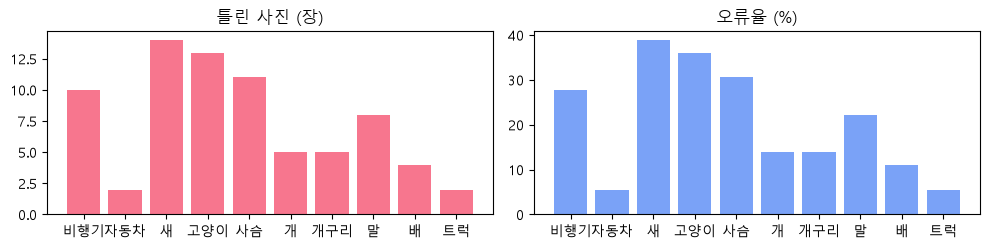

frozen 오류율이 가장 높은 종류 새 — 36장 중 14장 (38.9%)
헷갈린 짝 상위 셋 — 고양이 → 개 9장 · 새 → 개구리 6장 · 사슴 → 고양이 6장


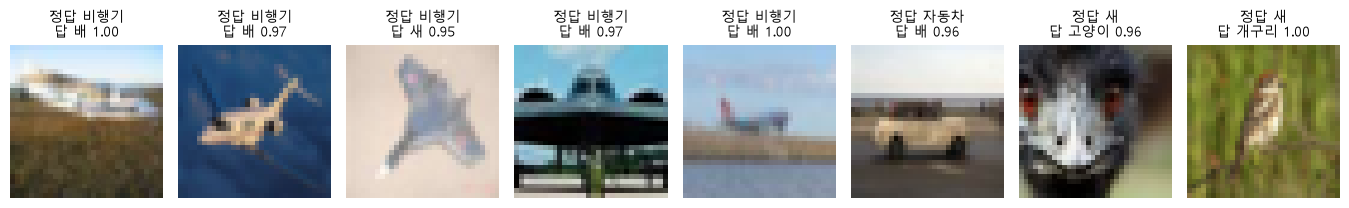

In [59]:
from collections import Counter  # 짝 세기

# 왜 · 높은 점수 뒤에 남은 오류를 종류 · 짝 · 확신별로 모아 보기 위해
print(f"모아 볼 테스트 사진 {len(yte)}장")                               # 같은 360장
for k in R:                                                              # 네 방식
    cf, pr = TEST[k][2].max(1)                                           # 확신 · 답
    w = pr != yte                                                        # 틀린 사진
    print(f"{k:9s} — 틀림 {int(w.sum())}장 · "                           # 틀림 · 과신
          f"0.9 이상 확신하고 틀림 {int((w & (cf >= 0.9)).sum())}장")
fz = TEST["frozen"][2].argmax(1)                                         # frozen 모델의 답
rows = []  # 종류별 (이름, 장수, 틀림, 오류율)
for c in range(10):                                                      # 종류마다
    n, w = int((yte == c).sum()), int(((yte == c) & (fz != yte)).sum())  # 장수 · 틀림
    rows.append((KO[CLASSES[c]], n, w, w / n * 100))                     # 한 줄
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6))                          # 개수 · 비율
ax[0].bar([r[0] for r in rows], [r[2] for r in rows], color="#f7768e")   # 틀린 개수
ax[0].set_title("틀린 사진 (장)")                                        # 제목
ax[1].bar([r[0] for r in rows], [r[3] for r in rows], color="#7aa2f7")   # 오류율
ax[1].set_title("오류율 (%)")                                            # 제목
fig.tight_layout()                                                       # 정리
plt.show()                                                               # 그리기
top_r = max(rows, key=lambda r: r[3])                                    # 오류율 최고
# 가장 약한 종류
print(f"frozen 오류율이 가장 높은 종류 {top_r[0]} — {top_r[1]}장 중 {top_r[2]}장 ({top_r[3]:.1f}%)")
pairs = Counter((int(yte[i]), int(fz[i])) for i in (fz != yte).nonzero().flatten().tolist())  # 짝
# 상위 셋
pair_txt = [f"{KO[CLASSES[t]]} → {KO[CLASSES[q]]} {n}장" for (t, q), n in pairs.most_common(3)]
print("헷갈린 짝 상위 셋 — " + " · ".join(pair_txt))                     # 많은 짝  # 많은 짝
cf, pr = TEST["full_1e3"][2].max(1)  # 확신하며 틀린 사진 (전부 풀기 1e-3)
wr = ((pr != yte) & (cf >= 0.9)).nonzero().flatten()[:8]                 # 0.9 이상 틀림 앞 여덟 장
show([xte[i] for i in wr],                                               # 정답 / 답 확률
     [f"정답 {KO[CLASSES[yte[i]]]}\n답 {KO[CLASSES[pr[i]]]} {cf[i]:.2f}" for i in wr],
     cols=8, size=1.7)

**결과** · 예측 정답은 full_1e3 — 50장 (큰 학습률로 망가진 모델이 과신까지)

- `모아 볼 테스트 사진 360장` — 종류마다 36장
- `frozen — 틀림 74장 · 0.9 이상 확신하고 틀림 1장` — 적게 틀리고 과신도 거의 없음
- `full_1e3 — 틀림 156장 · 0.9 이상 확신하고 틀림 50장` — 많이 틀리고 강하게 확신
- `frozen 오류율이 가장 높은 종류 새 — 36장 중 14장 (38.9%)` — 개수와 장수를 함께
- `고양이 → 개 9장 · 새 → 개구리 6장 · 사슴 → 고양이 6장` — 1일차와 같은 닮은 짝

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>전체 오류 수</td><td>몇 장</td><td>한 줄 요약</td></tr>
<tr><td>종류별 오류율</td><td>틀림 ÷ 그 종류 장수</td><td>약한 종류 찾기 (1일차 재현율)</td></tr>
<tr><td>확신하며 틀림</td><td>0.9 이상 틀림</td><td>자동 처리 기준이 위험한 곳</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 장수가 적은 종류는 한 장이 여러 % · 비율의 흔들림이 큼
> - 여기까지는 후보 · 모델이 정말 그것 때문에 틀렸는지는 아직 모름 → Grad-CAM

> ✅ **한 줄 정리** · 높은 점수 뒤의 오류는 종류별 오류율 · 헷갈린 짝 · 확신 순서로 모아 보고, 확신하며 틀린 사진부터 살핀다.

**딥러닝 코드에서는**

- `classification_report` + 혼동 짝 상위 목록 — 오류 감사 보고서의 기본
- 다음 처방 후보 · 약한 종류 사진 더 모으기 · 짝을 가려 보기로 확인 · 정답 유지 증강

### 15-2. `A` 빌려 온 모델은 어디를 보나 — Grad-CAM · `register_forward_hook` · `register_full_backward_hook` <sub>2일차 6막</sub>

> 🎯 **한 번의 계산으로 모델이 점수에 기여한 자리를 어떻게 지도로 그리고, 그 지도의 한계는 무엇인가?**

💡 **쉽게 말하면**

- layer4 특징 지도 512장 × 그 종류 점수의 **기울기 평균**(중요도) → 가중합 → 음수는 0.
- 7×7을 224로 키워 사진에 겹침 · **대략적인 자리**만.

**실행 흐름**

1. layer4에 앞으로 · 뒤로 갈 때 값을 저장하는 hook
2. `gradcam` · 점수 하나 backward → 지도
3. 종류마다 처음 맞힌 사진 열 장
4. 틀린 사진 여덟 장 (모델이 고른 답 기준)

**먼저 예측** · Grad-CAM 지도는 몇 칸을 키운 것일까? — 답은 코드 실행 결과 아래에

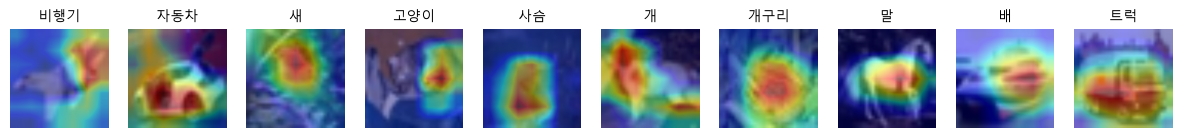

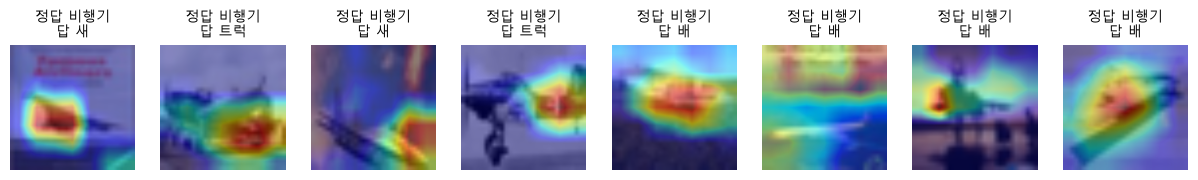

맞힌 사진 10장 · 틀린 사진 8장 · 지도는 7×7을 224로 키운 것


In [60]:
# 왜 · Grad-CAM에 필요한 특징 · 기울기를 hook으로 받아 두기 위해
feats, grads = {}, {}  # layer4 특징 지도 · 기울기 저장소
frozen.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))  # 앞으로 갈 때 저장
frozen.layer4.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))  # 뒤로


# 왜 · 빌려 온 모델이 답을 낼 때 기댄 자리를 지도로 만들기 위해
def gradcam(x, cls=None):                                # 사진 한 장 → (답, 224 × 224 지도 0~1)
    for p in frozen.parameters():                        # 기울기가 layer4까지 오도록
        p.requires_grad = True                           # 켬
    out = frozen(norm(x[None]))                          # 점수
    c = int(out.argmax()) if cls is None else cls        # 기준 종류 (기본 = 모델의 답)
    frozen.zero_grad()                                   # 지우기
    out[0, c].backward()                                 # 그 종류 점수의 기울기
    w = grads["g"].mean((2, 3), keepdim=True)            # 지도 512장마다 중요도
    cam = F.relu((w * feats["a"]).sum(1, keepdim=True))  # 가중합 · 음수는 0
    cam = F.interpolate(cam, size=224, mode="bilinear", align_corners=False)[0, 0]  # 7 → 224
    return c, (cam / (cam.max() + 1e-8)).detach().cpu()  # 0~1


# 왜 · 지도를 사진 위에 겹쳐 사람이 읽기 쉽게 보여 주기 위해
def overlay(ax, x, cam, title):                        # 사진 위에 지도를 겹침
    img = F.interpolate(x[None].float(), size=224, mode="bilinear")[0] / 255  # 224로 키운 사진
    ax.imshow(img.permute(1, 2, 0).cpu().clamp(0, 1))  # 바탕
    ax.imshow(cam, cmap="jet", alpha=0.45)             # 겹침
    ax.set_title(title, fontsize=10)                   # 제목
    ax.axis("off")                                     # 눈금 끄기


picks = [int(((yte == k) & (fz == yte)).nonzero()[0]) for k in range(10)]  # 종류마다 처음 맞힌 사진
fig, ax = plt.subplots(1, 10, figsize=(15, 1.9))                     # 한 줄
for a, i in zip(ax, picks):                                          # 사진마다
    overlay(a, xte[i], gradcam(xte[i])[1], KO[CLASSES[yte[i]]])      # 맞힌 사진
plt.show()                                                           # 그리기
wrong_cam = (fz != yte).nonzero().flatten()[:8].tolist()             # 틀린 사진 앞 여덟 장
fig, ax = plt.subplots(1, len(wrong_cam), figsize=(1.9 * len(wrong_cam), 2.2))  # 한 줄
for a, i in zip(np.atleast_1d(ax), wrong_cam):                       # 사진마다
    c, cam = gradcam(xte[i])                                         # 모델이 고른(틀린) 답 기준
    overlay(a, xte[i], cam, f"정답 {KO[CLASSES[yte[i]]]}\n답 {KO[CLASSES[c]]}")  # 겹침
plt.show()                                                           # 그리기
print(f"맞힌 사진 {len(picks)}장 · 틀린 사진 {len(wrong_cam)}장 · "  # 그린 장수
      f"지도는 7×7을 224로 키운 것")

**결과** · 예측 정답은 7×7 — layer4 출력 크기

- `맞힌 사진 10장 · 틀린 사진 8장 · 지도는 7×7을 224로 키운 것` — 작은 부분을 정확히 가리키지는 못함
- 첫 그림 · 밝은 곳이 대상 위면 '대상을 보고 판단' 후보 지지 · 배경 위면 '배경에 기댐' 후보
- 둘째 그림 · 배경이 밝은 틀림은 배경이 답과 닮았을 후보 · 대상 위가 밝은 틀림은 닮은 종류와 헷갈렸을 후보

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>가려 보기 (1일차 9장)</td><td>자리마다 다시 계산 (49번)</td><td>느리지만 직관적</td></tr>
<tr><td>Grad-CAM</td><td>한 번의 계산 · 기울기 사용</td><td>계산 한 번 · 대략적인 자리</td></tr>
<tr><td>둘 함께</td><td>같은 곳을 가리키면 더 믿을 만함</td><td>결론 전에</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점수에 기여한 자리 ≠ 모델의 이유 · 정답 위치 지도도 없어 눈으로 판단
> - 틀린 사진이 적음 · 사진 몇 장 · 방법 하나 → 경향이 아니라 사례로만

> ✅ **한 줄 정리** · Grad-CAM은 마지막 합성곱 특징 지도를 점수의 기울기로 가중합해 기여한 자리를 대략 보여 주지만, 모델의 이유를 증명하지는 않는다.

**딥러닝 코드에서는**

- `pytorch-grad-cam` 라이브러리 — 같은 계산을 여러 모델에
- hook은 쓰고 나면 `handle.remove()`로 지우는 것이 안전

### 15-3. `B` 두 대상이 한 사진에 · 창문을 옮겨 대 보면 · 비용 · `torch.cat(dim=2)` · `sliding window` <sub>2일차 7막</sub>

> 🎯 **한 사진에 두 대상이 있으면 분류 모델은 무엇이라고 답하고, 어디에 있는지는 어떻게 알 수 있는가?**

💡 **쉽게 말하면**

- 분류 모델의 답은 **하나** · '둘 다' 칸도 위치 출력도 없음.
- 사진을 창문처럼 잘라 같은 분류기를 여러 자리에 대 보면 대략 위치를 알 수 있음.

**실행 흐름**

1. 비행기 · 말 사진을 반씩 이어 붙임 → 큰 두 확률
2. 두 사진을 가로로 이어 32칸 창문을 16칸씩 옮김
3. 창문마다 답 · 확률
4. 촘촘히 · 크기 두 가지면 창문 수

**먼저 예측** · 왼쪽 비행기 · 오른쪽 말 사진에 모델은 무엇이라고 답할까? — 답은 코드 실행 결과 아래에

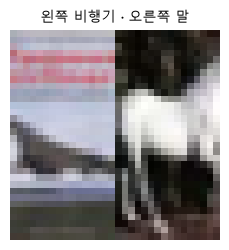

가장 큰 두 확률 — 고양이 0.34 · 말 0.22
모델의 답은 하나 — 고양이
  가로  0~32 → 새 0.37
  가로 16~48 → 고양이 0.39
  가로 32~64 → 말 0.71
창문 3개 → 촘촘히(4칸씩) · 크기 두 가지면 20개 · 계산은 약 7배 · 사진 1,000장이면 20,000번 분류


In [61]:
# 왜 · 한 사진에 두 대상이 있을 때 분류 모델의 한계를 확인하기 위해
a_i = int((yte == CLASSES.index("airplane")).nonzero()[0])               # 비행기 한 장
b_i = int((yte == CLASSES.index("horse")).nonzero()[0])                  # 말 한 장
two = torch.cat([xte[a_i][:, :, 8:24], xte[b_i][:, :, 8:24]], dim=2)     # 가운데 반씩 이어 붙임
with torch.no_grad():                                                    # 답
    prob = frozen(norm(two[None])).softmax(1)[0]                         # 열 가지 확률
t2 = prob.topk(2)                                                        # 가장 큰 두 확률
show([two], ["왼쪽 비행기 · 오른쪽 말"], cols=1, size=2.4)               # 한 사진에 두 대상
two_p = " · ".join(f"{KO[CLASSES[int(k)]]} {float(v):.2f}"               # 이름 확률 두 개
                   for v, k in zip(t2.values, t2.indices))
print("가장 큰 두 확률 — " + two_p)                                      # 두 종류로 나뉨
print("모델의 답은 하나 —", KO[CLASSES[int(t2.indices[0])]])             # '둘 다' 칸이 없음
wide = torch.cat([xte[a_i], xte[b_i]], dim=2)  # 가로로 이어 붙임 (3, 32, 64)
res = []                                                                 # 창문마다 (시작, 답, 확률)
with torch.no_grad():                                                    # 32칸 창문을 16칸씩 옮김
    for x0 in range(0, 33, 16):                                          # 시작 0 · 16 · 32
        pr_ = frozen(norm(wide[:, :, x0:x0 + 32][None])).softmax(1)[0]   # 그 창문만 분류
        res.append((x0, KO[CLASSES[int(pr_.argmax())]], float(pr_.max())))  # 기록
for x0, name, p in res:                                                  # 창문마다
    print(f"  가로 {x0:2d}~{x0 + 32:2d} → {name} {p:.2f}")               # 어디에 무엇이 있는지 대략
wins = [(x0, sz) for sz in (32, 24) for x0 in range(0, 64 - sz + 1, 4)]  # 촘촘히 · 크기 두 가지
print(f"창문 {len(res)}개 → 촘촘히(4칸씩) · 크기 두 가지면 {len(wins)}개"  # 비용이 창문 수만큼
      f" · 계산은 약 {len(wins) / len(res):.0f}배 · 사진 1,000장이면 {len(wins) * 1000:,}번 분류")

**결과** · 예측 정답은 고양이 0.34 — 둘 중 하나도 아닌 답 하나

- `가장 큰 두 확률 — 고양이 0.34 · 말 0.22` — 확률이 나뉠 뿐 '둘 다'는 없음
- `모델의 답은 하나 — 고양이` — 어디에 있는지도 모름
- `가로 32~64 → 말 0.71` — 오른쪽 창문은 말을 찾음
- `창문 3개 → 촘촘히(4칸씩) · 크기 두 가지면 20개 · 계산은 약 7배` — 창문 수만큼 분류를 다시 함
- `사진 1,000장이면 20,000번 분류` — 물체 크기를 모르면 크기마다 또 반복

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류</td><td>사진 하나 → 답 하나</td><td>대상이 하나일 때</td></tr>
<tr><td>창문 옮기기</td><td>자리마다 분류 · 비용 큼 · 겹친 답 정리 필요</td><td>위치를 대략 알고 싶을 때</td></tr>
<tr><td>탐지 (다음 과목)</td><td>후보 자리를 먼저 고르고 그 자리만 분류 (R-CNN)</td><td>여러 대상 · 위치까지</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 창문은 네모 · 물체 크기를 모름 · 같은 물체가 여러 창문에 걸림 → 남는 세 문제
> - 원본 강의는 꽃 두 송이 · 여기서는 CIFAR 비행기 · 말 (32칸)

> ✅ **한 줄 정리** · 분류 모델은 사진 하나에 답 하나만 내고 위치를 모르며, 창문을 옮겨 대 보면 위치를 짐작할 수 있지만 비용이 커서 다음 과목(탐지)의 출발점이 된다.

**딥러닝 코드에서는**

- 객체탐지 · R-CNN → Fast · Faster R-CNN → YOLO (다음 과목 03)
- 겹친 창문의 답 정리 = NMS (다음 과목)

---
## 16. 종합 실습 · 실습 네 개 · 세기 · 증강 · 가리기 · 세 줄 기록

> **이 장의 흐름**
>
> - 실습 1 · 밝기 세기를 바꾸며 바뀐 비율 → 실습 2 · 내 증강을 여덟 번
> - 그다음 실습 3 · 가리는 네모 크기 4 · 8 · 12 → 실습 4 · 한 종류만 흔들고 세 줄 기록

<img src="images/pfcnn1_practice.png" alt="실습 네 개" width="584">

**파이프라인 위치** · ① ~ ⑮ 전체 (흔들기 · 증강 · 가려 보기 · 세 칸 · 세 줄)

> 🎯 **◆ 표시 줄을 바꿔 보며 무엇을 확인하고, 결과를 어떻게 기록하는가?**

💡 **쉽게 말하면**

- ◆ 줄이 **고쳐 볼 줄** · 나머지는 그대로 두고 그 줄만 바꿔 다시 실행.
- 결과는 바꾼 것 · 예상과 실제 · 다음 비교 **세 줄**로 적음.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>실습 1</td><td>밝기 세기 1.0 → 0.25 · 바뀐 비율</td><td><code>change</code> · <code>strengths</code> (◆ 두 줄을 같은 변화로)</td></tr>
<tr><td>실습 2</td><td>좌우 반전 + ±3칸 옮기기 · 같은 사진에 여덟 번</td><td><code>my_augment</code> · <code>torch.roll</code></td></tr>
<tr><td>실습 3</td><td>가리는 네모 4 · 8 · 12칸 · 고양이 사진</td><td><code>occlusion(patch=...)</code></td></tr>
<tr><td>실습 4</td><td>한 종류(고양이)만 흔들기 · 세 줄 기록</td><td><code>kind</code> · <code>changed[k][mask]</code></td></tr>
</tbody></table>

**먼저 예측** · 밝기를 0.25배로 하면 맞힌 사진의 몇 %가 답이 바뀔까? — 답은 코드 실행 결과 아래에

In [62]:
# 실습 1 — 변화 하나의 세기를 바꿔 보기 (◆ 두 줄을 같은 변화에 맞게 함께 바꿈)
# 왜 · 변화의 세기에 따라 답이 바뀌는 비율이 어떻게 달라지는지 직접 확인하기 위해
def change(x, s):                         # ◆ 밝기: 값을 s배
    return (x.float() * s).clamp(0, 255)  # 0~255 안으로


strengths = [1.0, 0.9, 0.7, 0.55, 0.4, 0.25]           # ◆ 세기 목록 (1.0 = 원본)
sub2 = correct[:2000]                                  # 원본에서 맞힌 검증 사진 앞 2000장
# 세기별 바뀐 비율
rates_s = [(predict(model, change(x_val[sub2], s)).argmax(1) != pred[sub2]).float().mean().item()
           * 100 for s in strengths]
for s, r in zip(strengths, rates_s):                   # 세기마다
    print(f"밝기 ×{s:<4} → 답이 바뀐 비율 {r:5.1f}%")  # 어디서 가파른가

밝기 ×1.0  → 답이 바뀐 비율   0.0%
밝기 ×0.9  → 답이 바뀐 비율   1.4%
밝기 ×0.7  → 답이 바뀐 비율   6.2%
밝기 ×0.55 → 답이 바뀐 비율  14.0%
밝기 ×0.4  → 답이 바뀐 비율  36.6%
밝기 ×0.25 → 답이 바뀐 비율  78.8%


**실행 흐름**

1. 좌우 반전 + 조금 옮기는 증강 함수 만들기
2. 트럭 사진 한 장에 여덟 번 적용해 보기
3. 서로 다른 그림 수 확인

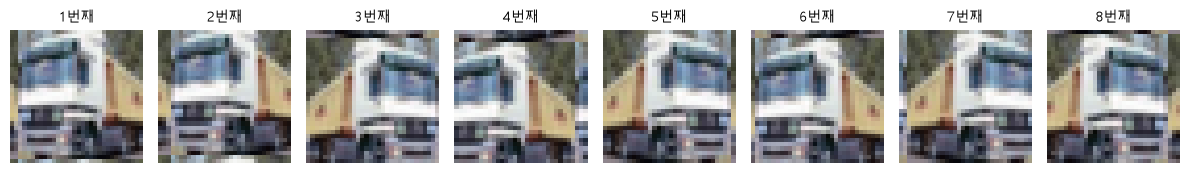

서로 다른 그림 8가지 / 8번


In [63]:
# 실습 2 — 내가 쓸 증강을 직접 만들어 보기 (같은 사진에 여덟 번)
# 왜 · 직접 만든 증강이 정답 단서를 남기는지 같은 사진으로 확인하기 위해
def my_augment(x):                                        # 좌우 반전(반반) + 조금 옮기기(±3칸)
    n = len(x)                                            # 장수
    out = x.float().clone()                               # 복사
    flip = (torch.rand(n) < 0.5).to(x.device)             # 반반
    out[flip] = out[flip].flip(-1)                        # 좌우 반전
    dx, dy = torch.randint(-3, 4, (2,)).tolist()          # 옮길 칸 (묶음 공통)
    return torch.roll(out, shifts=(dy, dx), dims=(2, 3))  # 옮기기


torch.manual_seed(5)                                                      # 보여 주기용
one_img = x_train[int((y_train == CLASSES.index("truck")).nonzero()[0])]  # 트럭 한 장
eight = [my_augment(one_img[None])[0] for _ in range(8)]                  # 넣을 때마다 다름
show(eight, [f"{k + 1}번째" for k in range(8)], cols=8, size=1.5)         # 단서가 남는가
print(f"서로 다른 그림 {len({e.cpu().numpy().tobytes() for e in eight})}가지 / 8번")  # 무작위인가

**실행 흐름**

1. 9장의 고양이 사진 고르기
2. 가리는 네모 크기 4 · 8 · 12로 지도 그리기
3. 밝은 자리가 같은지 비교

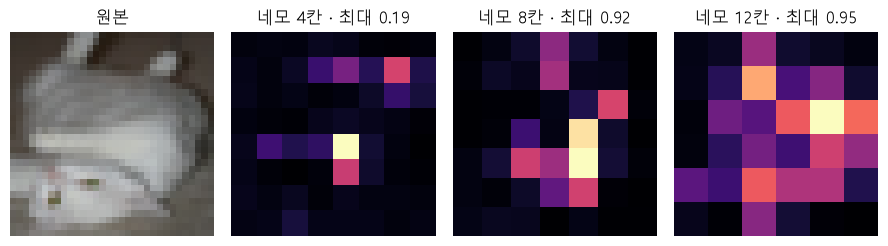

In [64]:
# 실습 3 — 가려서 확인하기: 가리는 네모 크기를 바꿔도 밝은 곳이 같은가
# 왜 · 가리는 크기를 바꿔도 같은 자리가 중요하게 나오는지 확인하기 위해
i_cat = picks_o[3]                                                            # 9장의 고양이 사진
fig, ax = plt.subplots(1, 4, figsize=(9, 2.4))                                # 원본 + 크기 셋
# 원본 사진
ax[0].imshow((x_val[i_cat].float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[0].set_title("원본")                                                       # 제목
for a, patch in zip(ax[1:], (4, 8, 12)):                                      # ◆ 네모 크기
    heat = occlusion(x_val[i_cat], int(y_val[i_cat]), patch=patch, stride=4)  # 지도
    a.imshow(heat.cpu().numpy(), cmap="magma")                                # 밝을수록 가리면 손해
    a.set_title(f"네모 {patch}칸 · 최대 {heat.max():.2f}")                    # 제목
for a in ax:                                                                  # 공통
    a.axis("off")                                                             # 눈금 끄기
fig.tight_layout()                                                            # 정리
plt.show()                                                                    # 그리기

**실행 흐름**

1. 한 종류(cat) 고르기
2. 여섯 변화마다 그 종류 · 전체의 바뀐 비율 출력
3. 세 줄 기록

In [65]:
# 실습 4 — 한 종류만 골라 흔들고, 세 줄로 적기
# 왜 · 한 종류만 골라 결과를 기록하는 실험 습관을 연습하기 위해
kind = "cat"                                                                  # ◆ 종류 하나
k_id = CLASSES.index(kind)                                                    # 번호
mask = y_val[correct] == k_id  # 그 종류에서 원본을 맞힌 사진
print(f"{KO[kind]} — 분모 {int(mask.sum())}장 (전체 {len(correct)}장)")       # 분모가 작음
for k in KINDS:                                                               # 여섯 변화
    print(f"  {KIND_KO[k]:6s} {changed[k][mask].float().mean() * 100:5.1f}%"  # 그 종류 · 전체
          f" (전체 {changed[k].float().mean() * 100:5.1f}%)")
print("① 바꾼 것 · 그대로 둔 것 — 종류 하나만 골라 봄 · 모델 · 사진 · 변화는 그대로")  # 세 줄 기록
print("② 예상 · 실제 — 위 숫자와 전체를 견줘 적음")                           # 예상과 실제
# 한계
print("③ 아직 모르는 것 · 다음 비교 — 분모가 작아 몇 장 차이로도 크게 움직임 → 시작값을 바꿔 다시")

고양이 — 분모 335장 (전체 4218장)
  좌우 반전   16.7% (전체   6.7%)
  조금 옮기기  15.2% (전체  19.6%)
  어둡게      6.9% (전체  14.1%)
  밝게      17.6% (전체   6.9%)
  잘라 키우기   8.7% (전체  55.4%)
  조금 돌리기  53.7% (전체  47.5%)
① 바꾼 것 · 그대로 둔 것 — 종류 하나만 골라 봄 · 모델 · 사진 · 변화는 그대로
② 예상 · 실제 — 위 숫자와 전체를 견줘 적음
③ 아직 모르는 것 · 다음 비교 — 분모가 작아 몇 장 차이로도 크게 움직임 → 시작값을 바꿔 다시


**결과** · 예측 정답은 78.8% — 0.9배에서는 1.4%

- `밝기 ×0.9 → 답이 바뀐 비율 1.4%` — 가장 약한 세기에서도 조금 바뀜
- `밝기 ×0.4 → 답이 바뀐 비율 36.6%` — 0.55 → 0.4 구간이 가장 가파름
- `밝기 ×0.25 → 답이 바뀐 비율 78.8%` — 아주 어두우면 대부분 바뀜
- `서로 다른 그림 8가지 / 8번` — 넣을 때마다 무작위로 다름 · 단서가 남는지 그림으로 확인
- `고양이 — 분모 335장 (전체 4218장)` — 분모가 작아 몇 장 차이로도 비율이 크게 움직임
- `조금 돌리기 53.7% (전체 47.5%)` — 고양이는 돌리기 · 밝게 · 좌우 반전에 전체보다 약함
- `잘라 키우기 8.7% (전체 55.4%)` — 고양이는 잘라 키우기에 오히려 강함 (가운데 얼굴이 남아서일 수 있음 · 후보)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>세기 곡선 (실습 1)</td><td>어디서 가파르게 늘어나나</td><td>증강 세기 정하기</td></tr>
<tr><td>내 증강 확인 (실습 2)</td><td>여덟 장 모두 단서가 남나</td><td>학습 전에</td></tr>
<tr><td>가리는 크기 (실습 3)</td><td>크기를 바꿔도 밝은 곳이 같나</td><td>가려 보기 결론을 믿기 전에</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 실습 3 · 네모가 크면 대상 전체가 가려져 지도가 뭉개짐 · 결론이 아니라 후보를 지지하거나 약하게 할 뿐
> - 실습 4 · 종류 하나는 분모가 작음 · 시작값을 바꿔 다시 확인

> ✅ **한 줄 정리** · 실습은 ◆ 줄 하나만 바꿔 세기 · 증강 · 가리는 크기의 효과를 보고, 결과는 바꾼 것 · 예상과 실제 · 다음 비교 세 줄로 적는다.

**딥러닝 코드에서는**

- 세 줄 기록 예 · 바꾼 것: 밝기 세기만 / 예상: 0.5 아래에서 급증 / 실제: 0.55 → 0.4에서 14.0% → 36.6% / 다음: 밝기 증강 모델로 같은 곡선
- 새 프로젝트 정할 것 여덟 가지 · 빌려 올 모델 · 처음부터 vs 빌림 · 어디까지 풀까 · 학습률 · 쓸 순간 · 결과 볼 순서 · Grad-CAM · 다음 실험

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>어디서 어떻게 틀리는지 읽기</td><td>확신 · softmax · 혼동행렬 · 재현율 · 정밀도 · top-k</td><td>1 · 6 · 15장</td></tr>
<tr><td>흔들기 · 학습 기록으로 진단</td><td>여섯 변화 · 분모 · 과적합 곡선 · 손실은 확신까지</td><td>3 · 4장</td></tr>
<tr><td>checkpoint · 증강 · 통제된 비교</td><td>검증 최고 저장 · 정답 보존 증강 · 하나만 바꾸고 시작값 여러 개</td><td>5 · 7 · 8장</td></tr>
<tr><td>구조가 바꾼 것</td><td>ReLU · 3×3 · 1×1 · 지름길 · ResNet18 · EfficientNet 비용</td><td>10 ~ 12장</td></tr>
<tr><td>빌려 오기 · 고장 진단</td><td>pretrained · 입력 약속 · Frozen / Partial / Full · 고장 6가지 · Grad-CAM</td><td>13 ~ 15장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td>A</td><td>확신 · softmax</td><td>점수 간격이 크면 확률이 한쪽으로 몰림 · 확신 ≠ 정답</td><td><code>logits.softmax(1).max(1)</code></td></tr>
<tr><td>A</td><td>흔들기</td><td>모델 고정 · 입력만 바꿈 · 분모는 맞힌 사진</td><td>흔든 검증 세트</td></tr>
<tr><td>A</td><td>학습 기록</td><td>간격 · 검증 선의 방향 · 손실이 과신을 먼저 알려 줌</td><td>학습 · 검증 곡선 함께</td></tr>
<tr><td>A</td><td>checkpoint</td><td>검증 최고 순간 저장 · 테스트는 한 번</td><td><code>torch.save(state_dict)</code></td></tr>
<tr><td>A</td><td>혼동행렬</td><td>줄 = 정답 · 칸 = 답 · 가로 재현율 · 세로 정밀도</td><td><code>confusion_matrix</code></td></tr>
<tr><td>A</td><td>증강</td><td>단서가 남는 변화만 · 학습할 때만 · 꺼낼 때마다</td><td>train transform</td></tr>
<tr><td>A</td><td>통제된 비교</td><td>하나만 바꿈 · 같은 시험 · 시작값 여러 개</td><td>실험 기록 세 줄</td></tr>
<tr><td>A</td><td>residual</td><td>출력 = F(x) + x · 모양이 다르면 1×1 stride 2</td><td><code>torchvision.models.resnet18</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td>A</td><td>pretrained</td><td>fc 바꾸기 · 입력 약속 · 얼리는 범위</td><td><code>weights.transforms()</code> · <code>requires_grad</code></td></tr>
<tr><td>B</td><td>Grad-CAM</td><td>기여한 자리 후보 · 이유가 아님</td><td>hook + 기울기</td></tr>
<tr><td>B</td><td>구조 비용</td><td>숫자 · 파일 · 입력 · 기기별 시간</td><td>대상 기기에서 직접 재기</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-2** · 틀린 사진도 확신이 높을 수 있는가?
- **1-4** · 점수 간격이 커지면 확률은?
- **2-2** · 입력 약속을 어기면?
- **3-2** · 흔들기 비율의 분모는?
- **4-3** · 과적합은 무엇으로 판단하나?
- **4-4** · 검증 정확도는 비슷한데 손실이 오르면?
- **5-3** · checkpoint는 무엇을 하는 방법인가?
- **6-3** · 혼동행렬을 세로로 읽으면?
- **7-1** · 증강을 고르는 기준은?
- **8-2** · 증강은 보여 주지 않은 변화에도 강해지게 하나?
- **8-4** · 한 번의 비교를 믿기 전에 할 일은?
- **10-4** · 3×3 세 층과 7×7 한 층의 차이는?
- **11-2** · residual block에서 F(x) = 0이면?
- **13-3** · 사진이 적을 때 처음부터 vs 빌려 오기?
- **14-3** · 얼린 모델을 학습 모드로 두면?
- **15-3** · 분류 모델이 못 하는 것은?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**10-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**11-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**13-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**14-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**15-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 점수 `[3.0, 1.0, 0.0]`의 softmax 확률과 가장 큰 확률을 출력
2. 정답 `[0, 0, 1, 1, 2]` · 예측 `[0, 1, 1, 1, 0]`로 3 × 3 혼동행렬을 만들고 종류 1의 재현율 · 정밀도 출력
3. `Conv2d(64, 128, 3)`의 학습할 숫자를 공식으로 계산하고 실제 값과 비교

In [66]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 1번 점수를 모두 두 배로 하면 가장 큰 확률은 커질까?
2. 2번에서 종류 0의 재현율 · 정밀도는?
3. 3번을 `bias=False`로 바꾸면 몇 개?

In [67]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-2** · 있음 · 782장 중 261장이 0.9 이상 · 확신만으로 맞고 틀림을 못 가름
- **1-4** · 가장 큰 확률이 1에 가까워짐 · 점수 1 차이 = 몫 약 2.7배
- **2-2** · 오류 없이 정확도가 무너짐 (84.6% → 26.2%)
- **3-2** · 원본에서 맞힌 검증 사진 · 여섯 변화 모두 같음
- **4-3** · 학습 · 검증 간격과 검증 선의 방향
- **4-4** · 틀린 쪽 확신이 커지는 중 (과신)
- **5-3** · 검증 최고 순간을 잃지 않는 방법 · 더 좋게 만드는 방법이 아님
- **6-3** · 그 답을 믿을 수 있는가 (정밀도) · 분모 = 열 합
- **7-1** · 바뀐 뒤에도 정답을 판단할 단서가 남고 실제로 만날 모습인가
- **8-2** · 거의 아님 · 넣은 변화 10.3% → 6.7% · 안 넣은 변화 50.4% → 48.7%
- **8-4** · 시작값을 바꿔 다시 · 범위가 겹치면 결론 보류
- **10-4** · 보는 범위는 같고 숫자는 3×3 세 층이 적음
- **11-2** · 출력 = 입력 그대로 · 쌓아도 앞의 결과를 지킴
- **13-3** · 빌려 온 쪽이 크게 나음 · 전부 풀 때는 학습률을 작게
- **14-3** · BN의 모아 둔 평균이 바뀜 → backbone은 eval()
- **15-3** · 답이 하나뿐 · 위치를 모름 → 탐지(다음 과목)

#### 코드 문제 답

```python
import torch  # 텐서
import torch.nn as nn  # 층

s = torch.tensor([3.0, 1.0, 0.0])  # 점수
p = s.softmax(0)  # 합이 1인 확률
print([round(v, 3) for v in p.tolist()], round(p.max().item(), 3))  # [0.844, 0.114, 0.042] 0.844
y, q = torch.tensor([0, 0, 1, 1, 2]), torch.tensor([0, 1, 1, 1, 0])  # 정답 · 예측
cm = torch.zeros(3, 3, dtype=torch.long)  # 빈 표
for t, a in zip(y.tolist(), q.tolist()):  # 짝마다
    cm[t, a] += 1  # 정답 줄 · 답 칸
rec1, prec1 = cm[1, 1] / cm[1].sum(), cm[1, 1] / cm[:, 1].sum()  # 줄 합 · 열 합
print(round(rec1.item(), 3), round(prec1.item(), 3))  # 1.0 0.667
conv = nn.Conv2d(64, 128, 3)  # 3×3 합성곱
print(64 * 3 * 3 * 128 + 128, sum(x.numel() for x in conv.parameters()))  # 73856 73856
```

#### 변형 문제 답

*문제 → 답*

- **1번 두 배** · 커짐 · 점수 [6, 2, 0] → 가장 큰 확률 0.980 (간격이 커져서)
- **2번 종류 0** · 재현율 0.5 (정답 0 두 장 중 하나) · 정밀도 0.5 (0이라고 답한 두 장 중 하나)
- **3번 bias=False** · 64 × 9 × 128 = 73728개

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>예: 흔들기 비율을 여섯 개 더해 '흔들린 사진 비율'로 씀</td><td>한 장이 여러 변화에서 바뀌면 여러 번 셈</td><td>사진 수와 횟수를 구분</td><td>이 숫자의 분모는 무엇이고, 한 장을 몇 번 세는가?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 검증 정확도가 높은데 실제로는 자주 틀린다면 무엇부터 봅니까?**
> - 입력 약속부터 확인합니다.
> - 그다음 정답은 그대로인 작은 변화로 흔들어 보고 변화별로 답이 바뀐 비율을 봅니다.
> - 혼동행렬로 어떤 짝을 헷갈리는지, 확신하며 틀린 사진이 얼마나 되는지도 봅니다.

**Q2. 과적합은 어떻게 판단하고 어떤 모델을 씁니까?**
> - 학습과 검증 곡선의 간격과 검증 선의 방향으로 판단합니다.
> - 검증 정확도가 비슷해도 검증 손실이 오르면 과신이 시작된 것입니다.
> - 모델은 마지막이 아니라 검증이 가장 좋았던 순간을 checkpoint로 저장해 쓰고, 테스트는 고른 뒤 한 번만 봅니다.

**Q3. 증강이 효과 있었다고 어떻게 말합니까?**
> - 증강 하나만 바꾸고 사진 · 모델 · 시작값 · 에폭 · 평가는 같게 둡니다.
> - 두 모델에 같은 원래 테스트와 같은 흔든 테스트를 넣어 비교합니다.
> - 시작값을 바꿔 다시 해서 범위가 겹치지 않을 때 효과라고 말합니다.

**Q4. ResNet의 지름길은 왜 필요합니까?**
> - 깊게 쌓기만 하면 학습 사진조차 덜 맞히는 최적화 문제가 생깁니다.
> - 출력을 F(x) + x로 만들면 층은 차이만 배우면 되고 F(x)가 0이면 입력이 그대로 나옵니다.
> - 모양이 바뀌는 곳은 지름길에 1×1 합성곱을 넣어 맞춥니다.

**Q5. 사진이 1,000장뿐인 분류 문제는 어떻게 시작합니까?**
> - ImageNet pretrained 모델을 빌려 fc만 종류 수에 맞게 바꾸고, 그 모델의 입력 약속을 그대로 씁니다.
> - fc만 먼저 학습한 뒤 필요하면 뒤쪽부터 풀고 학습률을 낮춥니다.
> - 얼린 backbone은 평가 모드로 두고 검증으로 고릅니다.

**Q6. Grad-CAM 결과는 어떻게 읽습니까?**
> - 마지막 합성곱 지도를 점수의 기울기로 가중합한 것이라 점수에 기여한 대략적인 자리 후보입니다.
> - 모델의 이유를 증명하지는 않으므로 가려 보기 같은 다른 방법과 함께 보고 사례로만 말합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>softmax</code> · <code>max(1)</code> · <code>topk</code></td><td>torch</td><td>확률 · 확신 · top-k</td><td>1-3 · 1-2 · 6-4</td></tr>
<tr><td><code>TF.affine</code> · <code>TF.rotate</code> · <code>TF.center_crop</code></td><td>torchvision.transforms.v2.functional</td><td>흔들기 변화</td><td>3-1</td></tr>
<tr><td><code>model.train()</code> · <code>model.eval()</code></td><td>torch.nn</td><td>dropout · BN 모드</td><td>4-2 · 14-3</td></tr>
<tr><td><code>torch.save</code> · <code>load_state_dict</code></td><td>torch</td><td>checkpoint 저장 · 불러오기</td><td>5-1 · 5-2</td></tr>
<tr><td><code>cm[t, q] += 1</code></td><td>torch</td><td>혼동행렬</td><td>6-1</td></tr>
<tr><td><code>F.pad(mode='reflect')</code> · <code>Dataset.__getitem__</code></td><td>torch</td><td>증강 · 꺼낼 때마다</td><td>7-1 · 7-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>torch.Generator().manual_seed</code></td><td>torch</td><td>흔든 시험 고정</td><td>8-2 · 8-3</td></tr>
<tr><td><code>models.alexnet</code> · <code>vgg16</code> · <code>googlenet</code></td><td>torchvision.models</td><td>구조 비교 (weights=None)</td><td>10-1 ~ 10-3</td></tr>
<tr><td><code>F.relu(f + x)</code> · 1×1 stride 2</td><td>torch.nn</td><td>residual block · 모양 맞추기</td><td>11-2 · 11-3</td></tr>
<tr><td><code>resnet18(weights=W)</code> · <code>net.fc = nn.Linear</code></td><td>torchvision.models</td><td>빌려 오기 · head 바꾸기</td><td>11-2 · 13-2</td></tr>
<tr><td><code>W.transforms()</code></td><td>torchvision.models</td><td>빌려 온 모델의 입력 약속</td><td>13-2</td></tr>
<tr><td><code>requires_grad = False</code></td><td>torch</td><td>얼리기 (Frozen · Partial)</td><td>13-3 · 13-6</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>ReduceLROnPlateau</code></td><td>torch.optim.lr_scheduler</td><td>나아지지 않으면 학습률 줄이기</td><td>14-1</td></tr>
<tr><td><code>register_forward_hook</code> · <code>register_full_backward_hook</code></td><td>torch.nn</td><td>Grad-CAM 재료</td><td>15-2</td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>확신 · 혼동행렬 · 종류별 비율로 어디서 틀렸는지</td><td>정확도 숫자 하나로 판단</td></tr>
<tr><td>고르기 · 진단은 검증 · 테스트는 마지막 한 번</td><td>테스트를 보고 다시 고르기</td></tr>
<tr><td>하나만 바꾸고 같은 시험 · 시작값 여러 개</td><td>증강 · 학습률 · 모델을 한꺼번에 바꾸기</td></tr>
<tr><td>빌려 온 모델의 입력 약속 · 얼린 backbone은 eval()</td><td>약속 무시 · 큰 학습률로 전부 풀기</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>logit vs 확률</td><td>범위 없음 · 합 1</td><td>손실에는 logit · 보여 줄 때 확률</td></tr>
<tr><td>재현율 vs 정밀도</td><td>줄 합 · 열 합</td><td>놓치면 큰일 → 재현율 · 경보가 비싸면 → 정밀도</td></tr>
<tr><td>checkpoint vs early stopping</td><td>저장 규칙 · 멈춤 규칙</td><td>함께 쓰고 멈춘 뒤 저장한 최고를 씀</td></tr>
<tr><td>과적합 vs 깊이 문제</td><td>검증만 낮음 · 학습부터 낮음</td><td>데이터 · 증강 vs 지름길</td></tr>
<tr><td>Frozen vs Full</td><td>fc만 · 전부</td><td>사진 적고 비슷하면 Frozen · 많고 다르면 Full(작은 학습률)</td></tr>
<tr><td>가려 보기 vs Grad-CAM</td><td>자리마다 다시 계산 · 한 번의 기울기</td><td>둘이 같은 곳을 가리키면 더 믿을 만함</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1 · 오답 노트 재발 방지 질문</td><td>20분</td></tr>
<tr><td>3일 뒤</td><td>3 · 6 · 8장 코드를 보지 않고 흐름만 다시 작성</td><td>40분</td></tr>
<tr><td>1주 뒤</td><td>11 · 13장을 파일별 2 · CNN-2와 연결해 읽기</td><td>40분</td></tr>
<tr><td>2주 뒤</td><td>종합 실습을 다른 변화 · 다른 종류로 다시 · 세 줄 기록</td><td>30분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 강의 HTML(1일차 1 ~ 10장 · 2일차 1 ~ 7막) 125개 코드 칸의 순서와 질문을 따라 15장 · 55섹션으로 묶음 · 원본은 수정하지 않음
- 원본은 수업 전에 학습한 모델 · 기록 · 꽃 사진을 불러옴 → 이 노트북은 같은 장면을 **직접 학습해서** 만듦 (숫자는 원본과 다름)
- 꽃 사진 장면(13 ~ 15장)은 원본 강의의 'CIFAR로 한 장면'처럼 CIFAR 1,080장을 224칸으로 키워 씀
- 실행마다 달라지는 시간은 그림으로만 보여 주고 출력하지 않음 · seed와 cudnn 설정으로 같은 환경에서 다시 실행하면 같은 숫자
- 생성 도구 · `notebook-tools/파일별정리/cnn/` (cnn1_code_*.py · cnn1_spec_*.py · cnn_figures.py · build_cnn.py · verify_cnn.py)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>1일차 준비</td><td>CIFAR-10 · 저장 모델 · SmallCNN을 지나는 길</td><td>0장 · 1-1</td></tr>
<tr><td>1일차 1장</td><td>자신 있게 틀린 사진 · 확신 · softmax</td><td>1장</td></tr>
<tr><td>1일차 2장</td><td>자료부터 · 기준선 · 입력 약속 · 분할</td><td>2장</td></tr>
<tr><td>1일차 3장</td><td>조금 바꾸면 답도 바뀔까 · 세 칸</td><td>3장</td></tr>
<tr><td>1일차 4장</td><td>학습 기록 · 모드 · 과적합 · 손실</td><td>4장</td></tr>
<tr><td>1일차 5장</td><td>checkpoint · early stopping · 오전 정리</td><td>5장</td></tr>
<tr><td>1일차 6장 · 실습 1 ~ 3</td><td>혼동행렬 · 재현율 · 정밀도 · top-k</td><td>6장 · 16장</td></tr>
<tr><td>1일차 7장</td><td>증강 · Dataset 안의 증강</td><td>7장</td></tr>
<tr><td>1일차 8장</td><td>한 조건만 바꾼 두 모델 · 시작값 · 신뢰도</td><td>8장</td></tr>
<tr><td>1일차 9장</td><td>남는 오류 · 해상도 · 가려 보기 · 합성곱이 보는 것</td><td>9장</td></tr>
<tr><td>1일차 10장 · 더 보기</td><td>AlexNet · VGG · GoogLeNet · 보는 범위 · 1×1 · 기울기 · CutMix</td><td>10장</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>어제 마무리 · 실습 1 ~ 4</td><td>흔들기 → 세 칸 → 한 조건 비교 → 세 줄</td><td>16장 종합 실습</td></tr>
<tr><td>2일차 1막</td><td>깊이 문제 · residual block · ResNet18</td><td>11장</td></tr>
<tr><td>2일차 2막</td><td>EfficientNet · 비용 · 세 상황</td><td>12장</td></tr>
<tr><td>2일차 3 ~ 4막</td><td>pretrained · 입력 약속 · Frozen / Partial / Full · 두 단계</td><td>13장</td></tr>
<tr><td>2일차 5막</td><td>곡선 · 학습률 · 고장 1 ~ 6 · 학습 점검</td><td>14장</td></tr>
<tr><td>2일차 6 ~ 7막</td><td>오류 감사 · Grad-CAM · 분류의 한계 · 창문 · 정리</td><td>15장</td></tr>
</tbody></table>

### 전체 코드

0. 준비 ~ 16장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 0. 준비 1 — 도구 · 데이터 불러오기

In [68]:
# ---------- 0. 준비 1 ----------
# 왜 · 가장 좋았던 순간의 모델 숫자를 따로 복사해 두기 위해
import copy  # 모델 숫자 복사 (checkpoint)
import os    # 환경 변수 · 폴더

# 왜 · 사진 · 확률 · 곡선을 그림으로 확인하기 위해
import matplotlib.pyplot as plt                    # 그래프
import numpy as np                                 # 배열 계산
import torch                                       # 텐서 · 모델
import torch.nn as nn                              # 층
import torch.nn.functional as F                    # 손실 · 보간 함수
import torchvision.transforms.v2.functional as TF  # 회전 · 자르기 같은 이미지 변환
from torchvision.datasets import CIFAR10           # 사진 10종 데이터

# 왜 · torch와 matplotlib을 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # torch · matplotlib OpenMP 충돌 방지
plt.rcParams.update({"font.family": "Malgun Gothic", "font.size": 10,    # 그림 글꼴 10pt
                     "axes.titlesize": 12, "axes.unicode_minus": False,  # 제목 12pt
                     "mathtext.fontset": "dejavusans"})                  # 로그 눈금의 수식 글꼴
torch.manual_seed(0)                                                     # 난수 고정
torch.backends.cudnn.deterministic = True                                # 같은 GPU · 같은 버전에서 합성곱도 매번 같은 값
torch.backends.cudnn.benchmark = False                                   # 계산 방법을 바꾸지 않게
DEV = "cuda" if torch.cuda.is_available() else "cpu"                     # GPU가 있으면 GPU

# 왜 · 처음 한 번만 내려받고 그다음부터는 data/에 저장된 파일을 그대로 쓰기 위해
tr = CIFAR10("data", train=True, download=True)  # 학습용 5만 장 (있으면 내려받지 않음)
te = CIFAR10("data", train=False, download=True)                  # 테스트용 1만 장
X_all = torch.from_numpy(tr.data).permute(0, 3, 1, 2)             # (N, 32, 32, 3) → (N, 3, 32, 32)
Y_all = torch.tensor(tr.targets)                                  # 정답 번호
x_train, y_train = X_all[:45000].to(DEV), Y_all[:45000].to(DEV)   # 학습 45,000장
x_val, y_val = X_all[45000:].to(DEV), Y_all[45000:].to(DEV)       # 검증 5,000장
x_test = torch.from_numpy(te.data).permute(0, 3, 1, 2).to(DEV)    # 테스트 10,000장
y_test = torch.tensor(te.targets).to(DEV)                         # 테스트 정답
CLASSES = tr.classes                                              # 종류 이름 10개
KO = dict(zip(CLASSES, ["비행기", "자동차", "새", "고양이", "사슴",  # 한글 이름
                        "개", "개구리", "말", "배", "트럭"]))
print(f"장치 {DEV} · 학습 {len(x_train)} · 검증 {len(x_val)} · "  # 준비 확인
      f"테스트 {len(x_test)} · 종류 {len(CLASSES)}")

장치 cuda · 학습 45000 · 검증 5000 · 테스트 10000 · 종류 10


**실행 흐름**

1. 0. 준비 2 — 모델 · 입력 약속 · 보조 함수 정의

In [69]:
# ---------- 0. 준비 2 ----------
# 왜 · 합성곱 · 풀링 묶음을 쌓은 작은 모델로 이 권의 모든 실험을 같은 구조에서 하기 위해
class SmallCNN(nn.Module):                      # 합성곱 두 번 + 줄이기를 세 번 → 평균 → 10종 점수
    def __init__(self, n_classes=10):           # 종류 수를 받음
        super().__init__()                      # nn.Module 준비
        layers, c = [], 3                       # 층 목록 · 들어오는 채널 (RGB 3)
        for w in (32, 64, 128):                 # 묶음마다 채널을 늘림
            # 합성곱 · BN · ReLU 두 번 + MaxPool
            layers += [nn.Conv2d(c, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.Conv2d(w, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.MaxPool2d(2)]
            c = w                               # 다음 묶음의 입력 채널
        self.features = nn.Sequential(*layers)  # 무늬 찾기 부분
        # GAP → 펴기 → Dropout → 점수
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.3), nn.Linear(c, n_classes))

    def forward(self, x):                   # 사진 → 점수
        return self.head(self.features(x))  # 특징 → 분류


# 왜 · 모든 실험이 같은 입력 약속(0~255 → 실수 · 정규화)을 쓰게 하기 위해
def to_input(x):                           # 학습 때의 입력 약속
    return (x.float() / 255 - 0.5) / 0.25  # 0~255 → 대략 -2 ~ 2


@torch.no_grad()
def predict(model, x, bs=500):  # 사진 묶음 → 종류별 확률
    model.eval()                # 평가 모드 (dropout 끔 · BN은 모아 둔 평균)
    outs = [model(to_input(x[k:k + bs])).softmax(1) for k in range(0, len(x), bs)]  # 500장씩
    return torch.cat(outs)      # 한 묶음으로


# 왜 · 저장해 둔 숫자를 같은 모양의 모델에 넣어 다시 쓰기 위해
def load_model(state):                  # 저장본 → 같은 모양 모델에 채움
    m = SmallCNN(len(CLASSES)).to(DEV)  # 같은 모양
    m.load_state_dict(state)            # 숫자 채우기
    return m.eval()                     # 평가 모드


# 왜 · 여러 사진을 같은 형식으로 나란히 보여 주기 위해
def show(images, titles, cols=7, size=1.9):                           # 32칸 사진을 칸이 보이게 크게
    rows = (len(images) + cols - 1) // cols                           # 필요한 줄 수
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size + 0.5)),  # 격자 만들기
                             squeeze=False)
    for ax in axes.flat:                                              # 모든 칸
        ax.axis("off")                                                # 눈금 끄기
    for ax, im, t in zip(axes.flat, images, titles):                  # 사진 · 제목 짝
        im = (im.float().clamp(0, 255) / 255).permute(1, 2, 0).cpu()  # 0~1 · (H, W, C)
        ax.imshow(im.numpy(), interpolation="nearest")                # 최근접 = 칸이 그대로 보임
        ax.set_title(t, fontsize=10)                                  # 제목 10pt
    fig.tight_layout()                                                # 겹침 정리
    plt.show()                                                        # 그리기

**실행 흐름**

1. 0. 준비 3 — 학습 함수 정의 · 기준 모델 학습

In [70]:
# ---------- 0. 준비 3 ----------
# 왜 · 섞기 → 예측 → 손실 → 갱신 한 바퀴를 한 함수로 묶어 실험마다 같은 절차를 쓰기 위해
def train_one_epoch(model, opt, x, y, bs=128, aug=None, seed=0):  # 학습 사진으로 한 바퀴
    model.train()                                                 # 학습 모드 (dropout 켬)
    g = torch.Generator().manual_seed(seed)                       # 섞는 순서 고정
    perm = torch.randperm(len(x), generator=g).to(x.device)       # ① 섞기
    total_loss, correct = 0.0, 0                                  # 에폭 동안의 합계
    for k in range(0, len(x), bs):                                # ② 묶음 꺼내기
        idx = perm[k:k + bs]                                      # 이번 묶음 번호
        xb, yb = x[idx], y[idx]                                   # 사진 · 정답
        if aug is not None:                                       # 증강이 있으면 (7장)
            xb = aug(xb)                                          # 꺼낼 때마다 새 모습
        logits = model(to_input(xb))                              # ③ 예측 (점수)
        loss = F.cross_entropy(logits, yb)                        # ④ 손실
        opt.zero_grad()                                           # 지난 기울기 지우기
        loss.backward()                                           # ⑤ 기울기
        opt.step()                                                # ⑥ 한 걸음
        total_loss += loss.item() * len(idx)                      # 손실 합 (장수만큼)
        correct += (logits.argmax(1) == yb).sum().item()          # 맞힌 수
    return total_loss / len(x), correct / len(x)                  # 평균 손실 · 정확도


@torch.no_grad()
def evaluate(model, x, y):                                 # 학습 없이 손실 · 정확도만
    p = predict(model, x)                                  # 확률
    loss = F.nll_loss(p.clamp_min(1e-9).log(), y).item()   # 정답 확률의 -log 평균
    return loss, (p.argmax(1) == y).float().mean().item()  # 손실 · 정확도


# 왜 · 증강 여부만 바꿔 같은 조건으로 학습하고 기록 · 최고 모델을 남기기 위해
def fit(aug=None, epochs=20, seed=0):                     # 학습 + 기록 + checkpoint (5장)
    torch.manual_seed(seed)                               # 시작값 고정
    m = SmallCNN(len(CLASSES)).to(DEV)                    # 새 모델
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)       # 학습률 0.002
    hist, best, keep = [], -1.0, {}                       # 기록 · 최고 검증 정확도 · 저장본
    for ep in range(1, epochs + 1):                       # 에폭 반복
        tl, ta = train_one_epoch(m, opt, x_train, y_train, aug=aug, seed=ep)  # 학습
        vl, va = evaluate(m, x_val, y_val)                # 검증 점수
        # 에폭 기록
        hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
        if va > best:                                     # 지금까지보다 좋으면 저장 (checkpoint)
            # 숫자 복사본 저장
            best, keep["best"], keep["best_epoch"] = va, copy.deepcopy(m.state_dict()), ep
        if ep == 10:                                      # 10에폭 모델도 남김 (4장)
            keep["ep10"] = copy.deepcopy(m.state_dict())  # 복사본
    keep["last"] = copy.deepcopy(m.state_dict())          # 마지막 모델
    return hist, keep                                     # 기록 · 저장본


# 왜 · 기준 모델의 학습 기록과 저장본을 한곳에 모아 뒤 장에서 다시 쓰기 위해
H, CK = {}, {}                                              # 학습 기록 · 저장본 모음
H["base"], CK["base"] = fit()                               # 증강 없이 20에폭 (GPU 약 1분 30초)
model = load_model(CK["base"]["best"])                      # 검증이 가장 좋았던 모델
p_val = predict(model, x_val)                               # 오류 진단은 검증 사진으로
pred, conf = p_val.argmax(1), p_val.max(1).values           # 답 · 확신
acc = (pred == y_val).float().mean().item() * 100           # 검증 정확도
print(f"준비 끝 · 고른 에폭 {CK['base']['best_epoch']} · "  # 고른 에폭 · 검증 정확도
      f"검증 정확도 {acc:.1f}%")

준비 끝 · 고른 에폭 18 · 검증 정확도 84.4%


**실행 흐름**

1. 1-1 층을 지나는 모양
2. 1-2 자신 있게 틀린 사진
3. 1-3 열 가지 확률

입력 사진 한 장 (1, 3, 32, 32)
  합성곱 두 번 + MaxPool 뒤 (1, 32, 16, 16)
  합성곱 두 번 + MaxPool 뒤 (1, 64, 8, 8)
  합성곱 두 번 + MaxPool 뒤 (1, 128, 4, 4)
  GAP 뒤 (1, 128, 1, 1) — 채널마다 값 하나
  Linear 뒤 (1, 10) — 종류 10개의 점수
학습할 숫자 — 합성곱 쪽 287,904개 · 분류기 쪽 1,290개


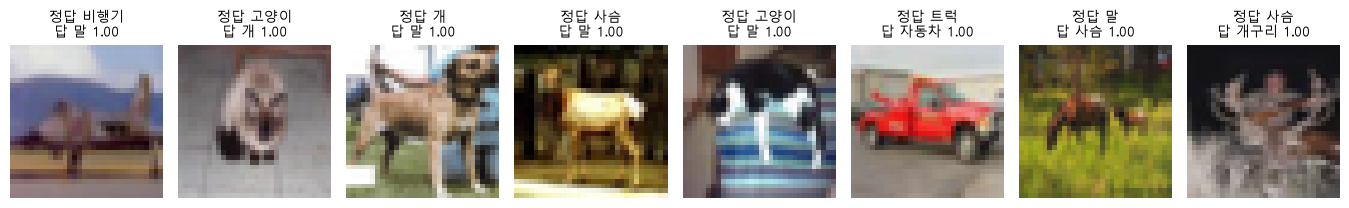

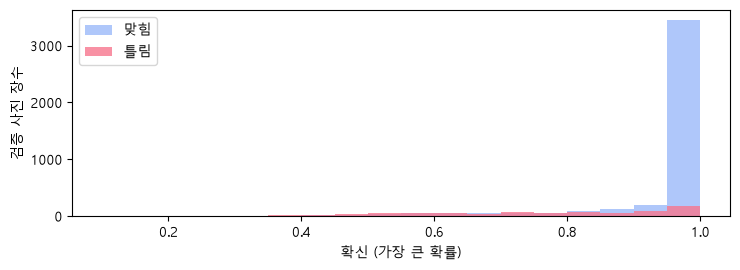

틀린 검증 사진 782장 · 그중 확신 0.9 이상 261장
맞힌 사진 4218장 · 틀린 사진 782장


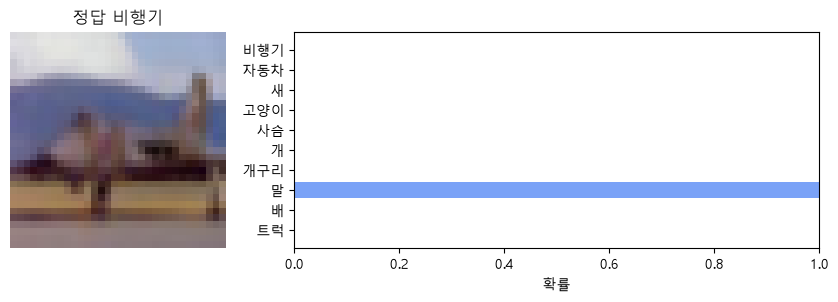

종류      점수(logit)    확률
말           11.73      1.000
비행기         -1.09      0.000
배           -1.31      0.000
점수 합 -80.83 · 확률 합 1.00
정답 비행기 쪽 확률 0.000


In [71]:
# ---------- 1-1 ----------
with torch.no_grad():                                               # 모양만 보므로 기울기 필요 없음
    # 왜 · 사진 한 장이 층을 지날 때 모양이 어떻게 바뀌는지 따라가 보기 위해
    t = to_input(x_val[:1])                                         # 사진 한 장 (묶음 크기 1)
    print(f"입력 사진 한 장 {tuple(t.shape)}")                      # (장수, 채널, 세로, 가로)
    for layer in model.features:                                    # 층을 하나씩 통과
        t = layer(t)                                                # 한 층 계산
        if isinstance(layer, nn.MaxPool2d):                         # 묶음 끝마다 찍음
            print(f"  합성곱 두 번 + MaxPool 뒤 {tuple(t.shape)}")  # 가로세로 절반 · 채널 늘림
    t = model.head[0](t)                                            # GAP (AdaptiveAvgPool2d)
    print(f"  GAP 뒤 {tuple(t.shape)} — 채널마다 값 하나")          # (1, 128, 1, 1)
    print(f"  Linear 뒤 {tuple(model(to_input(x_val[:1])).shape)} — 종류 10개의 점수")  # 점수
n_conv = sum(p.numel() for p in model.features.parameters())        # 합성곱 쪽 숫자
n_head = sum(p.numel() for p in model.head.parameters())            # 분류기 쪽 숫자
print(f"학습할 숫자 — 합성곱 쪽 {n_conv:,}개 · 분류기 쪽 {n_head:,}개")  # 대부분 합성곱


# ---------- 1-2 ----------
# 왜 · 틀린 사진 가운데 확신이 높은 것부터 찾아 위험한 오류를 먼저 보기 위해
wrong = (pred != y_val).nonzero().flatten()                             # 틀린 검증 사진 번호
top = wrong[conf[wrong].argsort(descending=True)][:8]                   # 확신이 큰 순서로 8장
show([x_val[i] for i in top],                                           # 가장 자신 있게 틀린 8장
     [f"정답 {KO[CLASSES[y_val[i]]]}\n답 {KO[CLASSES[pred[i]]]} {conf[i]:.2f}" for i in top],
     cols=8, size=1.7)
ok = pred == y_val                                                      # 맞힌 사진 표시
fig, ax = plt.subplots(figsize=(7.5, 2.8))                              # 확신 분포
bins = np.linspace(0.1, 1.0, 19)                                        # 0.05 폭 구간
ax.hist(conf[ok].cpu().numpy(), bins=bins, alpha=0.6, label="맞힘", color="#7aa2f7")  # 파랑
ax.hist(conf[~ok].cpu().numpy(), bins=bins, alpha=0.8, label="틀림", color="#f7768e")  # 빨강
ax.set_xlabel("확신 (가장 큰 확률)")                                    # 가로축
ax.set_ylabel("검증 사진 장수")                                         # 세로축
ax.legend()                                                             # 범례
fig.tight_layout()                                                      # 정리
plt.show()                                                              # 그리기
n_hi = int((conf[wrong] >= 0.9).sum())                                  # 0.9 이상 확신하고 틀린 수
print(f"틀린 검증 사진 {len(wrong)}장 · 그중 확신 0.9 이상 {n_hi}장")   # 결과
print(f"맞힌 사진 {int(ok.sum())}장 · 틀린 사진 {int((~ok).sum())}장")  # 두 묶음 크기


# ---------- 1-3 ----------
# 왜 · 가장 자신 있게 틀린 사진의 열 가지 확률을 그림으로 확인하기 위해
i0 = int(top[0])                                                    # 가장 자신 있게 틀린 사진
# 왼쪽 사진 · 오른쪽 확률
fig, ax = plt.subplots(1, 2, figsize=(8.5, 2.9), gridspec_kw={"width_ratios": [1, 2.4]})
# 사진 (칸이 보이게)
ax[0].imshow((x_val[i0].float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[0].set_title(f"정답 {KO[CLASSES[y_val[i0]]]}")                   # 사진 위 정답
ax[0].axis("off")                                                   # 눈금 끄기
ko_names = [KO[c] for c in CLASSES]                                 # 막대 이름
ax[1].barh(ko_names[::-1], p_val[i0].flip(0).cpu().numpy(), color="#7aa2f7")  # 열 가지 확률
ax[1].set_xlim(0, 1)                                                # 가로축 0~1 고정
ax[1].set_xlabel("확률")                                            # 축 이름
fig.tight_layout()                                                  # 정리
plt.show()                                                          # 그리기
with torch.no_grad():                                               # 점수(logit)만 다시 계산
    logit = model(to_input(x_val[i0:i0 + 1]))[0]                    # softmax 앞 점수 10개
prob = logit.softmax(0)                                             # 점수 → 확률
print("종류      점수(logit)    확률")                              # 표 머리줄
for k in prob.argsort(descending=True)[:3]:                         # 확률이 큰 세 종류
    print(f"{KO[CLASSES[k]]:6s} {logit[k]:10.2f} {prob[k]:10.3f}")  # 점수와 확률
print(f"점수 합 {logit.sum():.2f} · 확률 합 {prob.sum():.2f}")      # 확률만 합이 1
print(f"정답 {KO[CLASSES[y_val[i0]]]} 쪽 확률 {p_val[i0, y_val[i0]]:.3f}")  # 정답에 준 확률

**실행 흐름**

1. 1-4 점수 차이와 softmax

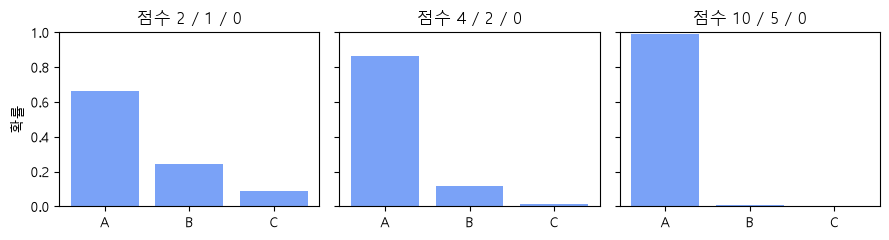

점수 2 · 1 · 0 → 가장 큰 확률 0.67
점수 4 · 2 · 0 → 가장 큰 확률 0.87
점수 10 · 5 · 0 → 가장 큰 확률 0.99
e^1 = 2.72 — 점수가 1 커질 때마다 몫이 약 2.7배


In [72]:
# ---------- 1-4 ----------
# 왜 · 점수 차이가 커질수록 softmax 확률이 한쪽으로 몰리는 것을 숫자로 보기 위해
scores = torch.tensor([[2.0, 1.0, 0.0], [4.0, 2.0, 0.0], [10.0, 5.0, 0.0]])  # 순위 같고 간격만 커짐
fig, ax = plt.subplots(1, 3, figsize=(9, 2.5), sharey=True)        # 세 경우 나란히
for a, s in zip(ax, scores):                                       # 경우마다
    a.bar(["A", "B", "C"], s.softmax(0).numpy(), color="#7aa2f7")  # 확률 막대
    a.set_ylim(0, 1)                                               # 세로축 0~1 고정
    a.set_title(f"점수 {s[0]:.0f} / {s[1]:.0f} / {s[2]:.0f}")      # 제목 = 점수
ax[0].set_ylabel("확률")                                           # 축 이름
fig.tight_layout()                                                 # 정리
plt.show()                                                         # 그리기
for s in scores:                                                   # 경우마다 가장 큰 확률
    print(f"점수 {s[0]:.0f} · {s[1]:.0f} · "                       # 간격이 클수록 1에 가까움
          f"{s[2]:.0f} → 가장 큰 확률 {s.softmax(0).max():.2f}")
print(f"e^1 = {np.e:.2f} — 점수가 1 커질 때마다 몫이 약 2.7배")    # 쏠림의 이유

**실행 흐름**

1. 2-1 종류별 장수
2. 2-2 입력 약속
3. 2-3 · 2-4 사진 보기 · 데이터 역할

종류         학습    검증   테스트
비행기      4507   493  1000
자동차      4512   488  1000
새        4521   479  1000
고양이      4481   519  1000
사슴       4525   475  1000


개        4471   529  1000
개구리      4512   488  1000
말        4515   485  1000
배        4468   532  1000
트럭       4488   512  1000
사진 모양 (3, 32, 32) · 값 범위 0~255 · 자료형 torch.uint8
가장 많은 종류 사슴만 답할 때 검증 정확도 9.5% (기준선)
사진 한 장 (3, 32, 32) · 왼쪽 위 한 칸 R, G, B = [202, 204, 199]
채널별 평균 — R 148 · G 149 · B 149
모델에 들어가는 값 -2.0 ~ 2.0 — (값 / 255 - 0.5) / 0.25


0~255 그대로  정확도  26.2%
255로만 나눔   정확도  29.8%
같은 약속      정확도  84.6%


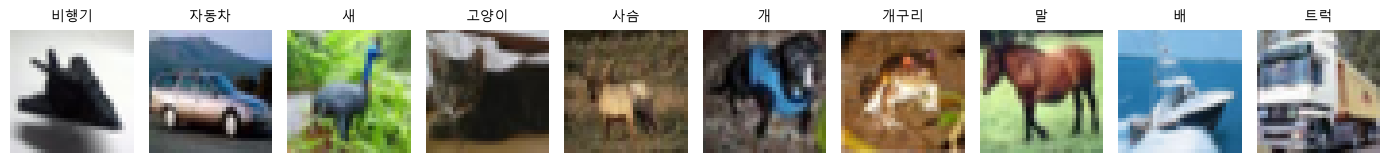

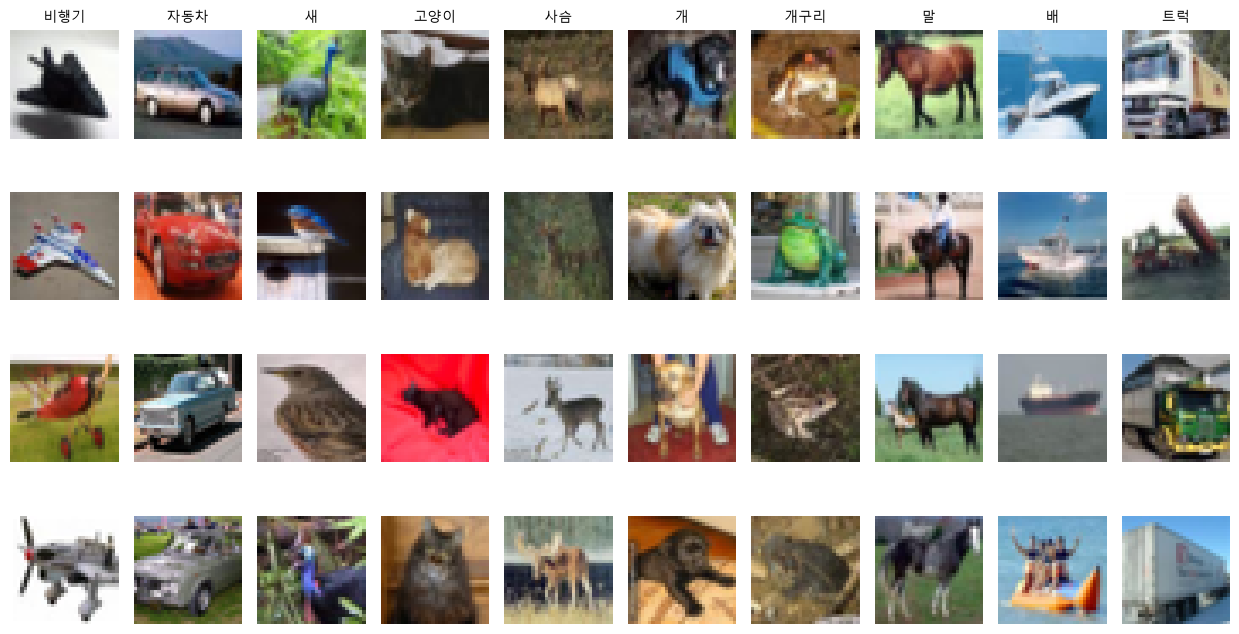

한 칸 민 사진   — 완전히 같은 칸  0.0% · 평균 차이 16.3
조금 잘라 키운 사진 — 완전히 같은 칸  0.3% · 평균 차이 12.9
픽셀 완전 일치 검사로는 '거의 같은 사진'을 못 찾음 → 분할 전에 따로 찾아 빼야 함


In [73]:
# ---------- 2-1 ----------
# 왜 · 종류별 장수를 먼저 확인해 정확도의 기준선을 정하기 위해
print(f"{'종류':6s} {'학습':>6s} {'검증':>5s} {'테스트':>5s}")       # 표 머리줄
for k, name in enumerate(CLASSES):                                   # 종류마다 장수
    n_tr, n_va = int((y_train == k).sum()), int((y_val == k).sum())  # 학습 · 검증
    print(f"{KO[name]:6s} {n_tr:6d} {n_va:5d} {int((y_test == k).sum()):5d}")  # 테스트까지
# 모양 · 범위 · 자료형
print(f"사진 모양 {tuple(x_train.shape[1:])} · 값 범위 {int(x_train.min())}~{int(x_train.max())}"
      f" · 자료형 {x_train.dtype}")
TOP = int(torch.bincount(y_train).argmax())                          # 학습에서 가장 많은 종류
base_acc = (y_val == TOP).float().mean().item() * 100                # 그 종류만 답할 때
print(f"가장 많은 종류 {KO[CLASSES[TOP]]}만 답할 때 검증 정확도 {base_acc:.1f}% (기준선)")  # 기준선
one = x_train[int((y_train == 0).nonzero()[0])]                      # 학습 사진 중 첫 번째 비행기
print(f"사진 한 장 {tuple(one.shape)} · "                            # 한 칸 = 숫자 세 개
      f"왼쪽 위 한 칸 R, G, B = {one[:, 0, 0].tolist()}")
r_, g_, b_ = (one[c].float().mean().item() for c in range(3))        # 채널별 평균
print(f"채널별 평균 — R {r_:.0f} · G {g_:.0f} · B {b_:.0f}")         # 어떤 색이 많은가
x_in = to_input(one)                                                 # 학습 때의 약속으로 변환
# 변환 뒤 범위
print(f"모델에 들어가는 값 {x_in.min():.1f} ~ {x_in.max():.1f} — (값 / 255 - 0.5) / 0.25")


# ---------- 2-2 ----------
model.eval()                                                            # 평가 모드
# 왜 · 입력 약속을 어겼을 때 정확도가 어떻게 무너지는지 같은 1000장으로 비교하기 위해
xv, yv = x_val[:1000], y_val[:1000]                                     # 같은 검증 사진 1000장
with torch.no_grad():                                                   # 넣는 값만 셋으로 다르게
    raw = model(xv.float()).argmax(1)                                   # 0~255 그대로
    only255 = model(xv.float() / 255).argmax(1)                         # 255로만 나눔
    right = model(to_input(xv)).argmax(1)                               # 학습 때와 같은 약속
# 세 가지 결과
for name, p in (("0~255 그대로", raw), ("255로만 나눔", only255), ("같은 약속", right)):
    print(f"{name:10s} 정확도 {(p == yv).float().mean() * 100:5.1f}%")  # 오류 메시지는 없음


# ---------- 2-3 ----------
# 왜 · 종류마다 실제 사진을 눈으로 보고 데이터의 생김새를 이해하기 위해
first_of = [int((y_train == k).nonzero()[0]) for k in range(len(CLASSES))]  # 종류마다 첫 장
show([x_train[i] for i in first_of], [KO[c] for c in CLASSES], cols=10, size=1.4)  # 한 장씩
cols = []                                                                   # 종류마다 앞 네 장
for k in range(len(CLASSES)):                                               # 종류마다
    cols += [int(i) for i in (y_train == k).nonzero().flatten()[:4]]        # 네 장 번호
order = [cols[k * 4 + r] for r in range(4) for k in range(len(CLASSES))]    # 줄마다 종류 순서대로
titles = [KO[CLASSES[y_train[i]]] if r == 0 else "" for r in range(4)       # 첫 줄에만 이름
          for i in order[r * 10:(r + 1) * 10]]
show([x_train[i] for i in order], titles, cols=10, size=1.25)               # 종류마다 네 장


# ---------- 2-4 ----------
# 왜 · 한 칸만 옮겨도 숫자가 크게 달라지는데 사람에겐 같은 사진이라는 점을 확인하기 위해
a = x_train[0].float()                                           # 학습 사진 한 장
moved = torch.roll(a, shifts=1, dims=2)  # 한 칸만 옆으로 민 복사본 (거의 같은 사진)
cropped = TF.resize(a[:, 1:31, 1:31], [32, 32], antialias=True)  # 가장자리 1칸 잘라 다시 키움
for name, b in (("한 칸 민 사진", moved), ("조금 잘라 키운 사진", cropped)):  # 두 복사본
    same = (a == b.round()).all(0).float().mean().item() * 100   # 픽셀이 완전히 같은 칸 비율
    diff = (a - b).abs().mean().item()                           # 평균 차이 (0~255)
    print(f"{name:10s} — 완전히 같은 칸 {same:4.1f}% · 평균 차이 {diff:4.1f}")  # 결과
print("픽셀 완전 일치 검사로는 '거의 같은 사진'을 못 찾음 → 분할 전에 따로 찾아 빼야 함")  # 결론

**실행 흐름**

1. 3-1 여섯 가지 변화로 한 장 흔들기

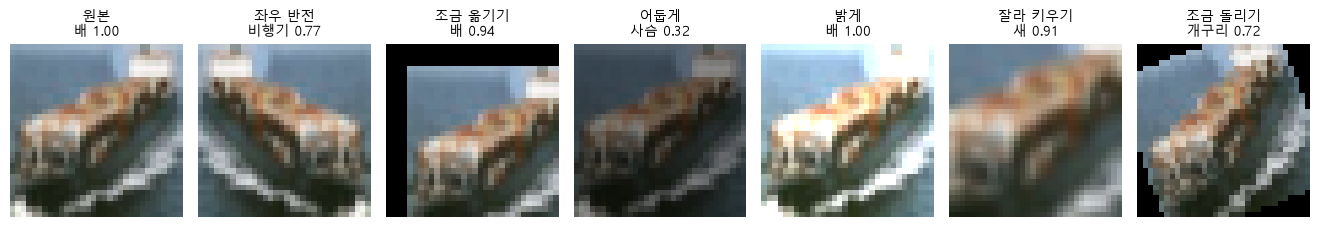

0.9 이상으로 맞힌 검증 사진 3642장 · 넷 이상 바뀐 사진 117장
고른 한 장 — 정답 배 · 원본 확신 1.00 · 여섯 중 4개에서 답이 바뀜


In [74]:
# ---------- 3-1 ----------
# 왜 · 흔들어 볼 변화 여섯 가지를 한곳에 정해 모든 실험에 같게 쓰기 위해
KINDS = ["hflip", "shift", "dark", "bright", "crop", "rotate"]            # 여섯 가지 변화
KIND_KO = dict(zip(KINDS, ["좌우 반전", "조금 옮기기", "어둡게", "밝게",  # 한글 이름
                           "잘라 키우기", "조금 돌리기"]))


# 왜 · 변화 종류만 바꾸면 같은 함수로 사진을 흔들 수 있게 하기 위해
def shake(x, kind):                      # 사진 묶음에 변화 하나 (정답은 그대로)
    x = x.float()                        # 계산용 실수
    if kind == "hflip":                  # 좌우 반전
        return x.flip(-1)                # 가로축 뒤집기
    if kind == "shift":                  # 4칸씩 옮기기 · 빈 자리는 검정
        # 아래 · 오른쪽으로 4칸
        return TF.affine(x, angle=0.0, translate=[4, 4], scale=1.0, shear=[0.0, 0.0])
    if kind == "dark":                   # 어둡게
        return (x * 0.55).clamp(0, 255)  # 값을 0.55배
    if kind == "bright":                 # 밝게
        return (x * 1.5).clamp(0, 255)   # 1.5배 · 255에서 자름
    if kind == "crop":                   # 가운데 22칸만 남겨 다시 32칸으로
        # 가운데 22칸 → 32칸
        return TF.resize(TF.center_crop(x, [22, 22]), [32, 32], antialias=True)
    if kind == "rotate":                 # 20도 돌리기 · 빈 자리는 검정
        return TF.rotate(x, 20.0)        # 반시계 20도
    raise ValueError(kind)               # 모르는 이름이면 오류


# 왜 · 확신 높게 맞힌 사진도 작은 변화에 답이 바뀌는지 확인하기 위해
ok_conf = ((pred == y_val) & (conf >= 0.9)).nonzero().flatten()  # 0.9 이상으로 맞힌 사진
flips = torch.zeros(len(ok_conf), dtype=torch.long, device=DEV)  # 사진마다 바뀐 횟수
for k in KINDS:                                                  # 변화마다
    # 바뀐 사진에 1씩
    flips += (predict(model, shake(x_val[ok_conf], k)).argmax(1) != pred[ok_conf]).long()
score = conf[ok_conf] + (flips >= 4).float() * 10                # 네 개 이상 바뀐 사진 중 확신 최고
ONE = int(ok_conf[score.argmax()])                               # 극단적인 한 장
imgs = [x_val[ONE].float()] + [shake(x_val[ONE:ONE + 1], k)[0] for k in KINDS]  # 원본 + 6
p_one = predict(model, torch.stack(imgs))                        # 일곱 장의 확률
show(imgs, [f"{n}\n{KO[CLASSES[p.argmax()]]} {p.max():.2f}"      # 칸 제목: 변화 · 답 · 확률
            for n, p in zip(["원본"] + [KIND_KO[k] for k in KINDS], p_one)])
print(f"0.9 이상으로 맞힌 검증 사진 {len(ok_conf)}장 · "         # 후보 수
      f"넷 이상 바뀐 사진 {int((flips >= 4).sum())}장")
print(f"고른 한 장 — 정답 {KO[CLASSES[y_val[ONE]]]} · 원본 확신 {conf[ONE]:.2f}"  # 고른 사진 요약
      f" · 여섯 중 {int(flips[score.argmax()])}개에서 답이 바뀜")

**실행 흐름**

1. 3-2 맞힌 사진 전체 흔들기
2. 3-3 종류별로 바뀐 비율

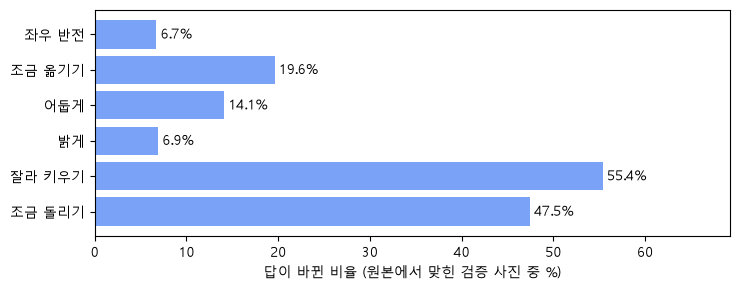

변화           분모     바뀜      비율
좌우 반전     4218    284    6.7%
조금 옮기기    4218    827   19.6%
어둡게       4218    595   14.1%
밝게        4218    292    6.9%
잘라 키우기    4218   2337   55.4%
조금 돌리기    4218   2002   47.5%
여섯 줄 바뀜 합 6337번(횟수) · 하나 이상 바뀐 사진 3267장 (77.5%)


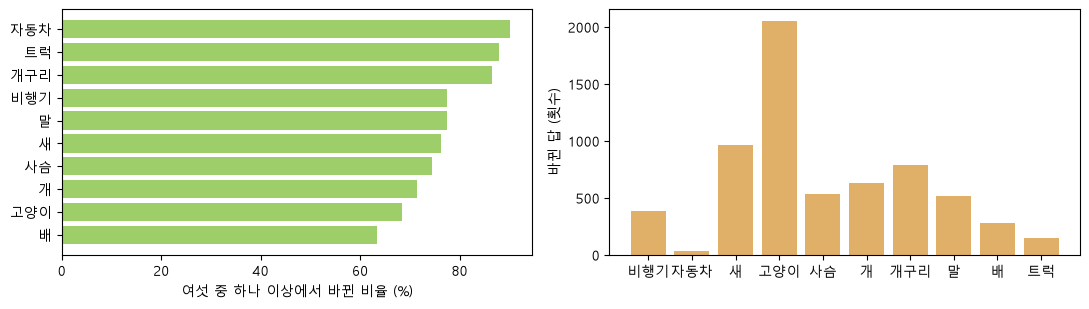

가장 잘 흔들린 종류 자동차 90.1% · 가장 덜 흔들린 종류 배 63.5%
바뀐 답으로 가장 많이 나온 종류 고양이 2056번
가장 많은 바뀜 짝 — 개 → 고양이 414번


In [75]:
# ---------- 3-2 ----------
# 왜 · 맞힌 사진만 분모로 삼아 변화 때문에 바뀐 비율을 정확히 재기 위해
correct = (pred == y_val).nonzero().flatten()                   # 분모: 원본에서 맞힌 검증 사진
# 변화마다 답이 바뀌었나
changed = {k: predict(model, shake(x_val[correct], k)).argmax(1) != pred[correct]
           for k in KINDS}
rates = {k: changed[k].float().mean().item() for k in KINDS}    # 변화별 바뀐 비율
fig, ax = plt.subplots(figsize=(7.5, 3.0))                      # 가로 막대
# 변화별 막대
bars = ax.barh([KIND_KO[k] for k in KINDS[::-1]], [rates[k] * 100 for k in KINDS[::-1]],
               color="#7aa2f7")
ax.bar_label(bars, fmt="%.1f%%", padding=3)                     # 막대 끝 숫자
ax.set_xlabel("답이 바뀐 비율 (원본에서 맞힌 검증 사진 중 %)")  # 축 이름
ax.set_xlim(0, max(rates.values()) * 125)                       # 숫자가 들어갈 여백
fig.tight_layout()                                              # 정리
plt.show()                                                      # 그리기
print(f"{'변화':8s} {'분모':>6s} {'바뀜':>6s} {'비율':>7s}")    # 막대 뒤의 표
for k in KINDS:                                                 # 변화마다 한 줄
    n_chg = int(changed[k].sum())                               # 바뀐 수
    # 분모 · 바뀜 · 비율
    print(f"{KIND_KO[k]:7s} {len(correct):6d} {n_chg:6d} {n_chg / len(correct) * 100:6.1f}%")
any_changed = torch.stack([changed[k] for k in KINDS]).any(0)   # 사진마다 하나라도 바뀌었나
total_n = sum(int(changed[k].sum()) for k in KINDS)             # 여섯 줄 바뀜 합 = 횟수
# 횟수 vs 사진 수
print(f"여섯 줄 바뀜 합 {total_n}번(횟수) · 하나 이상 바뀐 사진 {int(any_changed.sum())}장"
      f" ({any_changed.float().mean() * 100:.1f}%)")


# ---------- 3-3 ----------
# 왜 · 어떤 종류가 잘 흔들리고 어느 답으로 바뀌는지 종류별로 모으기 위해
by_class = {}                                                       # 종류별 하나 이상 바뀐 비율
for k, name in enumerate(CLASSES):                                  # 종류마다
    m = y_val[correct] == k                                         # 그 종류에서 원본을 맞힌 사진
    by_class[name] = any_changed[m].float().mean().item()           # 비율
order = sorted(CLASSES, key=by_class.get)                           # 덜 흔들린 → 잘 흔들린
dest = torch.zeros(len(CLASSES), dtype=torch.long)                  # 바뀐 답 횟수
pairs = {}                                                          # (원래 정답, 바뀐 답) 횟수
for k in KINDS:                                                     # 변화마다
    idx = correct[changed[k]]                                       # 그 변화에서 바뀐 사진
    newp = predict(model, shake(x_val[idx], k)).argmax(1)           # 바뀐 답
    for t, q in zip(y_val[idx].tolist(), newp.tolist()):            # 짝마다 셈
        dest[q] += 1                                                # 바뀐 답 쪽에 1
        pairs[(t, q)] = pairs.get((t, q), 0) + 1                    # 짝에 1
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))                     # 왼쪽 종류별 · 오른쪽 바뀐 답
# 종류별 막대
ax[0].barh([KO[c] for c in order], [by_class[c] * 100 for c in order], color="#9ece6a")
ax[0].set_xlabel("여섯 중 하나 이상에서 바뀐 비율 (%)")             # 축 이름
ax[1].bar([KO[c] for c in CLASSES], dest.numpy(), color="#e0af68")  # 바뀐 답 종류
ax[1].set_ylabel("바뀐 답 (횟수)")                                  # 사진 수가 아님
fig.tight_layout()                                                  # 정리
plt.show()                                                          # 그리기
print(f"가장 잘 흔들린 종류 {KO[order[-1]]} {by_class[order[-1]] * 100:.1f}%"  # 양 끝 종류
      f" · 가장 덜 흔들린 종류 {KO[order[0]]} {by_class[order[0]] * 100:.1f}%")
(t0, q0), n0 = max(pairs.items(), key=lambda kv: kv[1])             # 가장 많은 짝
# 몰리는 답
print(f"바뀐 답으로 가장 많이 나온 종류 {KO[CLASSES[int(dest.argmax())]]} {int(dest.max())}번")
print(f"가장 많은 바뀜 짝 — {KO[CLASSES[t0]]} → {KO[CLASSES[q0]]} {n0}번")  # 몰리는 곳

**실행 흐름**

1. 3-4 각도별로 답이 바뀐 비율

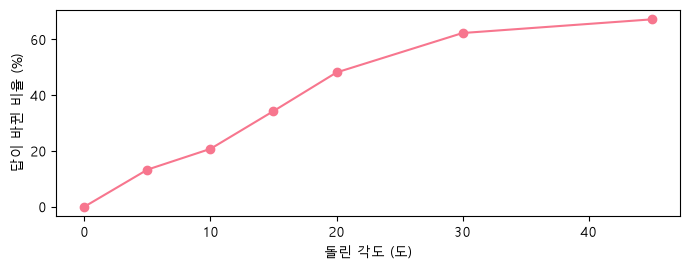

각도별 바뀐 비율 — 5도 13.3% · 20도 48.2% · 45도 67.2%


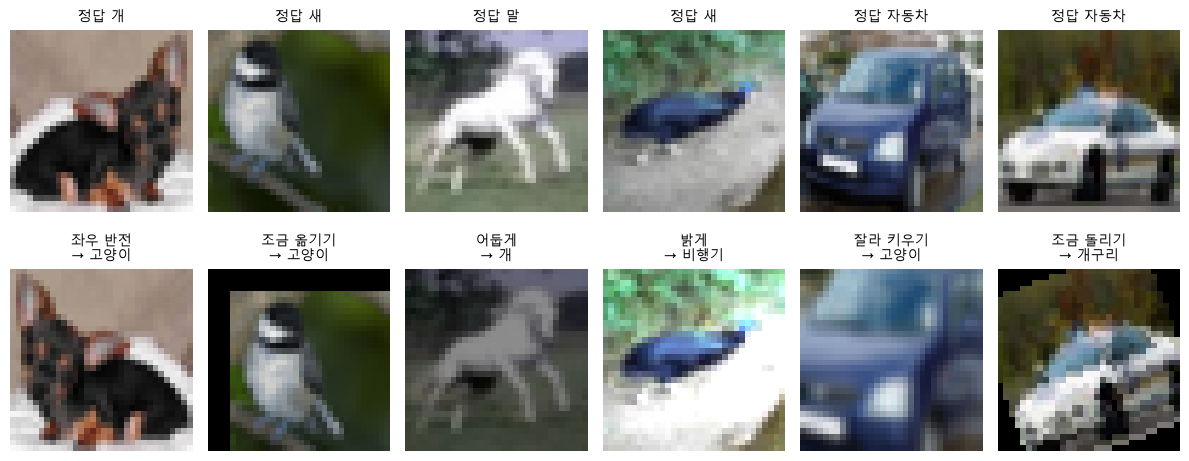

In [76]:
# ---------- 3-4 ----------
# 왜 · 각도를 늘려 가며 언제부터 답이 바뀌는지 같은 2000장으로 비교하기 위해
sub = correct[:2000]                                       # 맞힌 검증 사진 앞 2000장
angles = [0, 5, 10, 15, 20, 30, 45]                        # 돌리는 각도
rate = []                                                  # 각도별 바뀐 비율
for a in angles:                                           # 각도만 키움
    xs = TF.rotate(x_val[sub].float(), float(a))           # 돌린 사진
    # 각도별 바뀐 비율
    rate.append((predict(model, xs).argmax(1) != pred[sub]).float().mean().item() * 100)
fig, ax = plt.subplots(figsize=(7, 2.8))                   # 각도 곡선
ax.plot(angles, rate, "o-", color="#f7768e")               # 점과 선
ax.set_xlabel("돌린 각도 (도)")                            # 가로축
ax.set_ylabel("답이 바뀐 비율 (%)")                        # 세로축
fig.tight_layout()                                         # 정리
plt.show()                                                 # 그리기
print(f"각도별 바뀐 비율 — 5도 {rate[1]:.1f}% · "          # 세 각도
      f"20도 {rate[4]:.1f}% · 45도 {rate[6]:.1f}%")
tops, bottoms, t_top, t_bot, used = [], [], [], [], set()  # 변화마다 한 장
for k in KINDS:                                            # 변화마다 바뀐 사진 중 앞 번호 한 장
    i = next(int(correct[j]) for j in changed[k].nonzero().flatten()  # 바뀐 사진 중 앞 번호
             if int(correct[j]) not in used)
    used.add(i)                                            # 앞 칸과 겹치지 않게
    xi = shake(x_val[i:i + 1], k)                          # 바꾼 사진
    tops.append(x_val[i])                                  # 위: 원본
    t_top.append(f"정답 {KO[CLASSES[y_val[i]]]}")          # 원본 제목
    bottoms.append(xi[0])                                  # 아래: 바꾼 사진
    t_bot.append(f"{KIND_KO[k]}\n→ {KO[CLASSES[predict(model, xi).argmax()]]}")  # 바뀐 답
show(tops + bottoms, t_top + t_bot, cols=6, size=2.0)      # 위 원본 · 아래 바뀐 모습

**실행 흐름**

1. 4-1 한 에폭 학습 · 평가
2. 4-2 학습 모드 vs 평가 모드

In [77]:
# ---------- 4-1 ----------
torch.manual_seed(0)                                                              # 시작값 고정
demo = SmallCNN(len(CLASSES)).to(DEV)                                             # 처음부터 새 모델
opt = torch.optim.Adam(demo.parameters(), lr=2e-3)  # 한 걸음 크기 = 학습률
# 왜 · 학습 전 점수를 먼저 재어 한 에폭 학습의 효과를 비교할 출발점을 두기 위해
_, va0 = evaluate(demo, x_val, y_val)  # 학습 전 검증 정확도
tr_loss, tr_acc = train_one_epoch(demo, opt, x_train[:2000], y_train[:2000])      # 2000장 한 바퀴
va_loss, va_acc = evaluate(demo, x_val, y_val)                                    # 학습 없이 점수만
print(f"학습 전 검증 정확도 {va0 * 100:.1f}% (열 종류 중 아무거나 ≈ 10%)")        # 출발점
print(f"한 에폭 뒤 — 학습 손실 {tr_loss:.3f} · 학습 정확도 {tr_acc * 100:.1f}%")  # 에폭 평균
print(f"한 에폭 뒤 — 검증 손실 {va_loss:.3f} · 검증 정확도 {va_acc * 100:.1f}%")  # 끝난 모델 하나
print(f"묶음 128장 → 2000장은 {-(-2000 // 128)}걸음")                             # 걸음 수 (올림)


# ---------- 4-2 ----------
# 왜 · 학습 모드로 평가하면 결과가 흔들린다는 것을 원본을 건드리지 않고 보기 위해
m2 = copy.deepcopy(model)                                        # 복사본 — 원래 모델은 그대로
xx = to_input(x_val[:1])                                         # 같은 검증 사진 한 장
with torch.no_grad():                                            # 기울기 필요 없음
    m2.train()                                                   # 학습 모드
    tr3 = [m2(xx).softmax(1)[0].max().item() for _ in range(3)]  # 세 번 넣기
    m2.eval()                                                    # 평가 모드
    ev3 = [m2(xx).softmax(1)[0].max().item() for _ in range(3)]  # 세 번 넣기
print("같은 사진을 세 번 넣었을 때 가장 큰 확률")                # 머리줄
print("  학습 모드 — " + " · ".join(f"{v:.3f}" for v in tr3))    # dropout이 켜져 매번 다름
print("  평가 모드 — " + " · ".join(f"{v:.3f}" for v in ev3))    # 늘 같음


# 왜 · 모드만 다른 두 모델을 같은 사진으로 채점하기 위해
def acc_on(mdl, n=2000, bs=500):                          # 모드를 바꾸지 않고 그대로 잼
    with torch.no_grad():                                 # 기울기 없음
        # 500장씩 답
        p_ = torch.cat([mdl(to_input(x_val[k:k + bs])).argmax(1) for k in range(0, n, bs)])
    return (p_ == y_val[:n]).float().mean().item() * 100  # 정확도 %


# 왜 · 평가 모드에서는 같은 사진에 항상 같은 답이 나오는지 확인하기 위해
m3 = copy.deepcopy(model)                      # 또 다른 복사본
m3.eval()                                      # 평가 모드로 두 번
e1, e2 = acc_on(m3), acc_on(m3)                # 같은 값
m3.train()                                     # 평가 모드를 빼먹으면
t1, t2 = acc_on(m3), acc_on(m3)                # dropout · 묶음 평균 BN
print(f"검증 2000장 — 평가 모드 {e1:.1f}% · "  # 모드별 두 번씩
      f"{e2:.1f}% / 학습 모드 {t1:.1f}% · {t2:.1f}%")

학습 전 검증 정확도 10.2% (열 종류 중 아무거나 ≈ 10%)
한 에폭 뒤 — 학습 손실 2.011 · 학습 정확도 25.6%
한 에폭 뒤 — 검증 손실 2.308 · 검증 정확도 15.9%
묶음 128장 → 2000장은 16걸음
같은 사진을 세 번 넣었을 때 가장 큰 확률
  학습 모드 — 0.809 · 0.585 · 0.519
  평가 모드 — 1.000 · 1.000 · 1.000


검증 2000장 — 평가 모드 83.8% · 83.8% / 학습 모드 82.6% · 82.8%


**실행 흐름**

1. 4-3 과적합 재현
2. 4-4 기준 모델 학습 기록

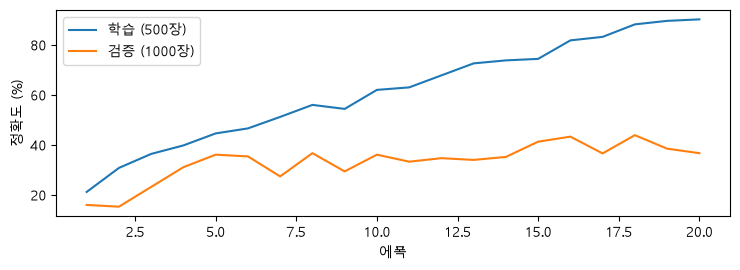

500장으로 20에폭 — 마지막 학습 정확도 90.2% · 검증 36.7%


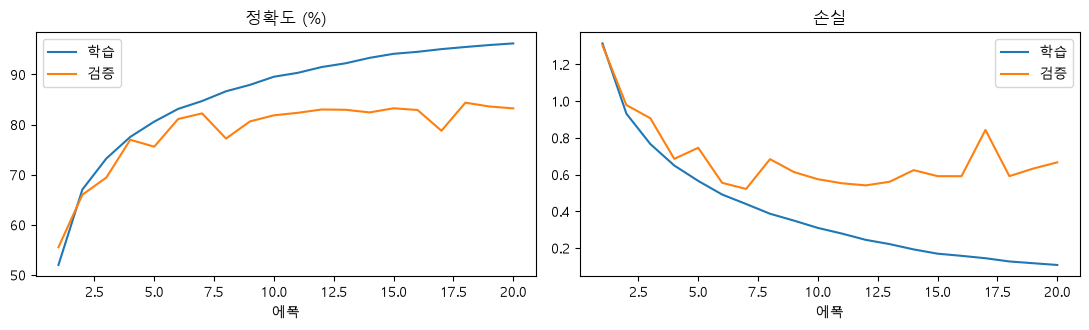

마지막 에폭 학습 정확도 96.2% · 검증 83.2%
검증 정확도 최고 에폭 18 (84.4%)
검증 손실 최저 에폭 7 (0.521) → 마지막 0.666
학습 설정 — 에폭 20 · 묶음 128 · Adam 학습률 0.002 · 시작값 0


In [78]:
# ---------- 4-3 ----------
torch.manual_seed(0)                                                            # 시작값 고정
# 왜 · 작은 데이터로 과적합이 생기는 과정을 눈앞에서 재현하기 위해
small = SmallCNN(len(CLASSES)).to(DEV)                                          # 새 모델
opt_s = torch.optim.Adam(small.parameters(), lr=2e-3)                           # 같은 학습률
hist_s = []  # (에폭, 학습 정확도, 검증 정확도)
for ep in range(1, 21):                                                         # 20에폭
    # 500장 한 바퀴
    _, ta = train_one_epoch(small, opt_s, x_train[:500], y_train[:500], bs=64, seed=ep)
    _, va = evaluate(small, x_val[:1000], y_val[:1000])                         # 검증 1000장
    hist_s.append((ep, ta * 100, va * 100))                                     # 기록
fig, ax = plt.subplots(figsize=(7.5, 2.8))                                      # 두 선
ax.plot([r[0] for r in hist_s], [r[1] for r in hist_s], label="학습 (500장)")   # 파랑
ax.plot([r[0] for r in hist_s], [r[2] for r in hist_s], label="검증 (1000장)")  # 주황
ax.set_xlabel("에폭")                                                           # 가로축
ax.set_ylabel("정확도 (%)")                                                     # 세로축
ax.legend()                                                                     # 범례
fig.tight_layout()                                                              # 정리
plt.show()                                                                      # 그리기
print(f"500장으로 20에폭 — 마지막 학습 정확도 {hist_s[-1][1]:.1f}% · "          # 간격 확인
      f"검증 {hist_s[-1][2]:.1f}%")


# ---------- 4-4 ----------
# 왜 · 기준 모델의 학습 기록에서 최고 시점과 손실 흐름을 읽기 위해
h = H["base"]                                                                  # 0장에서 학습한 기록
ep = [r["epoch"] for r in h]                                                   # 가로축
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))  # 왼쪽 정확도 · 오른쪽 손실
ax[0].plot(ep, [r["train_acc"] * 100 for r in h], label="학습")                # 파랑
ax[0].plot(ep, [r["val_acc"] * 100 for r in h], label="검증")                  # 주황
ax[0].set_title("정확도 (%)")                                                  # 제목
ax[1].plot(ep, [r["train_loss"] for r in h], label="학습")                     # 손실
ax[1].plot(ep, [r["val_loss"] for r in h], label="검증")                       # 손실
ax[1].set_title("손실")                                                        # 제목
for a in ax:                                                                   # 두 그림 공통
    a.set_xlabel("에폭")                                                       # 가로축
    a.legend()                                                                 # 범례
fig.tight_layout()                                                             # 정리
plt.show()                                                                     # 그리기
b_acc = max(h, key=lambda r: r["val_acc"])                                     # 검증 정확도 최고
b_loss = min(h, key=lambda r: r["val_loss"])                                   # 검증 손실 최저
print(f"마지막 에폭 학습 정확도 {h[-1]['train_acc'] * 100:.1f}% · "            # 간격
      f"검증 {h[-1]['val_acc'] * 100:.1f}%")
# checkpoint가 고른 곳
print(f"검증 정확도 최고 에폭 {b_acc['epoch']} ({b_acc['val_acc'] * 100:.1f}%)")
print(f"검증 손실 최저 에폭 {b_loss['epoch']} ({b_loss['val_loss']:.3f})"      # 그 뒤로 오름
      f" → 마지막 {h[-1]['val_loss']:.3f}")
print(f"학습 설정 — 에폭 {len(h)} · 묶음 128 · Adam 학습률 0.002 · 시작값 0")  # 같은 절차

**실행 흐름**

1. 4-5 손실과 확신

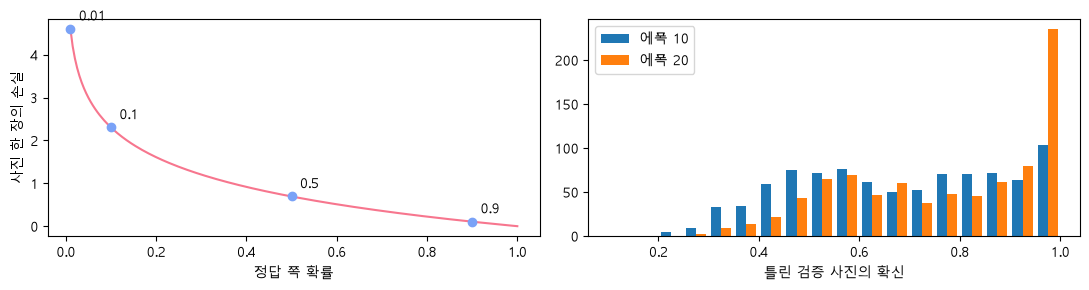

정답 쪽 확률 0.9 → 손실 0.11
정답 쪽 확률 0.5 → 손실 0.69
정답 쪽 확률 0.1 → 손실 2.30
정답 쪽 확률 0.01 → 손실 4.61
에폭 10 모델 — 틀린 사진 908장 · 그중 확신 0.9 이상 167장
에폭 20 모델 — 틀린 사진 839장 · 그중 확신 0.9 이상 315장


In [79]:
# ---------- 4-5 ----------
# 왜 · 손실은 맞힘 여부뿐 아니라 확신 정도까지 본다는 것을 곡선으로 확인하기 위해
p = np.linspace(0.01, 1.0, 200)                                  # 정답 쪽 확률
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0))                  # 왼쪽 -log p · 오른쪽 틀린 확신
ax[0].plot(p, -np.log(p), color="#f7768e")                       # 한 장의 손실
for q in (0.9, 0.5, 0.1, 0.01):                                  # 점 네 개
    ax[0].scatter([q], [-np.log(q)], color="#7aa2f7", zorder=3)  # 점
    ax[0].annotate(f"{q}", (q, -np.log(q)), textcoords="offset points", xytext=(6, 6))  # 점 옆 숫자
ax[0].set_xlabel("정답 쪽 확률")                                 # 가로축
ax[0].set_ylabel("사진 한 장의 손실")                            # 세로축
early, last = load_model(CK["base"]["ep10"]), load_model(CK["base"]["last"])  # 10 · 20에폭
confs = {}                                                       # 틀린 사진의 확신
for name, mdl in (("에폭 10", early), ("에폭 20", last)):        # 두 모델
    pp = predict(mdl, x_val)                                     # 확률
    confs[name] = pp.max(1).values[pp.argmax(1) != y_val].cpu()  # 틀린 사진만
ax[1].hist(list(confs.values()), bins=18, range=(0.1, 1.0), label=list(confs))  # 두 묶음
ax[1].set_xlabel("틀린 검증 사진의 확신")                        # 가로축
ax[1].legend()                                                   # 범례
fig.tight_layout()                                               # 정리
plt.show()                                                       # 그리기
for q in (0.9, 0.5, 0.1, 0.01):                                  # 손실 값
    print(f"정답 쪽 확률 {q} → 손실 {-np.log(q):.2f}")           # 0에 가까울수록 가파름
for name, c in confs.items():                                    # 모델마다
    print(f"{name} 모델 — 틀린 사진 {len(c)}장 · "               # 과신한 틀림 수
          f"그중 확신 0.9 이상 {int((c >= 0.9).sum())}장")

**실행 흐름**

1. 5-1 저장 · 불러오기
2. 5-2 모양이 다른 모델
3. 5-3 어디서 끝내느냐

에폭 1 · 검증 28.9% · 최고 → 저장


에폭 2 · 검증 32.2% · 최고 → 저장


에폭 3 · 검증 37.7% · 최고 → 저장


불러온 모델 검증 정확도 37.7%
숫자 묶음 44개 · 숫자 모두 290,096개
  features.0.weight            모양 (32, 3, 3, 3)
  features.0.bias              모양 (32,)
  features.1.weight            모양 (32,)
  features.1.bias              모양 (32,)
  features.1.running_mean      모양 (32,)
  features.1.running_var       모양 (32,)
불러오기 실패 — 파일의 숫자와 모델의 모양이 맞지 않음
  size mismatch · head.3.weight — 파일 (10, 128) · 지금 모델 (5, 128)
  size mismatch · head.3.bias — 파일 (10) · 지금 모델 (5)


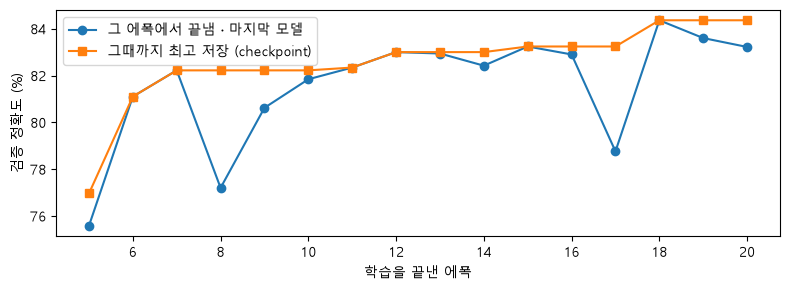

5~20에폭 중 어디서 끝내느냐에 따라 마지막 모델 75.6~84.4%
저장해 둔 최고 모델은 내려가지 않음 — 77.0% → 84.4%


테스트 한 번 — 마지막 모델 82.8% · 검증으로 고른 모델(에폭 18) 83.7%


In [80]:
# ---------- 5-1 ----------
# 왜 · 저장 · 불러오기 실습 파일을 따로 모아 다른 파일을 건드리지 않기 위해
os.makedirs("models_demo", exist_ok=True)                                   # 저장 폴더
torch.manual_seed(0)                                                        # 시작값 고정
demo = SmallCNN(len(CLASSES)).to(DEV)                                       # 새 모델
opt = torch.optim.Adam(demo.parameters(), lr=2e-3)                          # 학습률
best_val = -1.0  # 지금까지 최고 검증 정확도 (첫 에폭은 늘 저장)
for epoch in range(1, 4):                                                   # 세 에폭 시연
    train_one_epoch(demo, opt, x_train[:3000], y_train[:3000], seed=epoch)  # 3000장
    val_acc = evaluate(demo, x_val, y_val)[1]                               # 검증 정확도
    if val_acc > best_val:                                                  # 좋아졌을 때만
        best_val = val_acc                                                  # 최고 갱신
        torch.save(demo.state_dict(), "models_demo/best.pt")                # 같은 이름 → 덮어씀
        print(f"에폭 {epoch} · 검증 {val_acc * 100:.1f}% · 최고 → 저장")    # 저장함
    else:                                                                   # 최고가 아니면
        print(f"에폭 {epoch} · 검증 {val_acc * 100:.1f}% · 최고 아님 → 저장 안 함")  # 저장 안 함
back = SmallCNN(len(CLASSES)).to(DEV)                                       # 같은 모양의 새 모델
back.load_state_dict(torch.load("models_demo/best.pt"))                     # 숫자 채우기
print(f"불러온 모델 검증 정확도 {evaluate(back, x_val, y_val)[1] * 100:.1f}%")  # 최고와 같음
sd = torch.load("models_demo/best.pt")  # 파일 안 = 이름표 붙은 숫자 묶음
print(f"숫자 묶음 {len(sd)}개 · "                                           # 이름표 수 · 숫자 수
      f"숫자 모두 {sum(v.numel() for v in sd.values()):,}개")
for name in list(sd)[:6]:                                                   # 앞 여섯 이름표
    print(f"  {name:28s} 모양 {tuple(sd[name].shape)}")                     # 이름 · 모양


# ---------- 5-2 ----------
# 왜 · 모양이 다른 모델에 불러오면 어떤 에러가 나는지 미리 보기 위해
wrong_m = SmallCNN(5).to(DEV)  # 일부러 종류 수를 5로 — 마지막 층 모양이 다름
try:                                                                           # 불러오기 시도
    wrong_m.load_state_dict(sd)                                                # 같은 파일
except RuntimeError as e:  # 모양이 안 맞으면 통째로 거절
    print("불러오기 실패 — 파일의 숫자와 모델의 모양이 맞지 않음")             # 요약
    for ln in str(e).splitlines():                                             # 오류 문구 한 줄씩
        if "size mismatch" in ln:                                              # 어긋난 이름표 줄만
            name = ln.split("for ")[1].split(":")[0]                           # 이름표
            a, b = [s.split("])")[0] for s in ln.split("torch.Size([")[1:3]]   # 두 모양
            print(f"  size mismatch · {name} — 파일 ({a}) · 지금 모델 ({b})")  # 핵심만


# ---------- 5-3 ----------
# 왜 · 어디서 끝내느냐에 따라 고르는 모델이 달라진다는 것을 확인하기 위해
va = [r["val_acc"] * 100 for r in h]      # 에폭별 검증 정확도
ends = list(range(5, len(h) + 1))         # 몇 번째 에폭에서 끝냈다고 칠지
fig, ax = plt.subplots(figsize=(8, 3.0))  # 두 선
ax.plot(ends, [va[e - 1] for e in ends], "o-", label="그 에폭에서 끝냄 · 마지막 모델")  # 동그라미
ax.plot(ends, [max(va[:e]) for e in ends], "s-", label="그때까지 최고 저장 (checkpoint)")  # 네모
ax.set_xlabel("학습을 끝낸 에폭")         # 가로축
ax.set_ylabel("검증 정확도 (%)")          # 세로축
ax.legend()                               # 범례
fig.tight_layout()                        # 정리
plt.show()                                # 그리기
last_vals = [va[e - 1] for e in ends]     # 마지막 모델 점수들
lo, hi = min(last_vals), max(last_vals)   # 마지막 모델 점수의 범위
print(f"5~{len(h)}에폭 중 어디서 끝내느냐에 따라 마지막 모델 {lo:.1f}~{hi:.1f}%")  # 출렁임
print(f"저장해 둔 최고 모델은 내려가지 않음 — {max(va[:5]):.1f}% → {max(va):.1f}%")  # 늘 최고
last_m = load_model(CK["base"]["last"])   # 마지막 에폭 모델
# 고른 뒤 한 번만
print(f"테스트 한 번 — 마지막 모델 {evaluate(last_m, x_test, y_test)[1] * 100:.1f}%"
      f" · 검증으로 고른 모델(에폭 {CK['base']['best_epoch']})"
      f" {evaluate(model, x_test, y_test)[1] * 100:.1f}%")

**실행 흐름**

1. 5-4 early stopping

patience 2 → 에폭 9에서 멈춤
patience 3 → 에폭 10에서 멈춤
patience 5 → 20에폭 끝까지 감


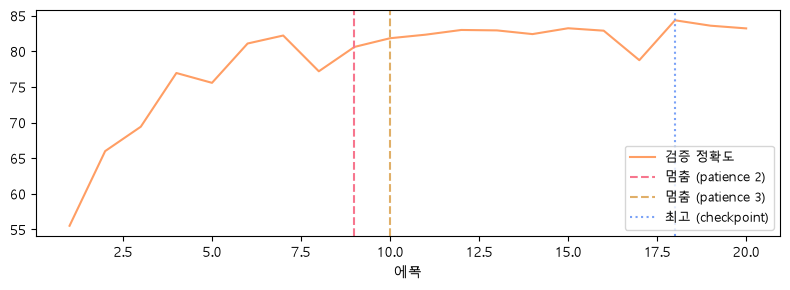

In [81]:
# ---------- 5-4 ----------
# 왜 · early stopping이 멈추는 곳을 규칙으로 계산하기 위해
def stop_epoch(h, patience):              # patience번 연속 안 좋아지면 멈추는 에폭 (끝까지면 None)
    best, wait = -1.0, 0                  # 최고 · 기다린 횟수
    for r in h:                           # 기록을 에폭 순서로
        if r["val_acc"] > best:           # 최고를 넘으면
            best, wait = r["val_acc"], 0  # 0으로
        else:                             # 못 넘으면
            wait += 1                     # 하나 늘림 (연속만 셈)
            if wait >= patience:          # 다 기다렸으면
                return r["epoch"]         # 멈춤
    return None                           # 끝까지 감


fig, ax = plt.subplots(figsize=(8, 3.0))                                 # 멈추는 곳 · 고르는 곳
ax.plot(ep, va, color="#ff9e64", label="검증 정확도")                    # 주황 선
for p_, c_ in ((2, "#f7768e"), (3, "#e0af68"), (5, "#9ece6a")):          # patience별 색
    s = stop_epoch(h, p_)                                                # 멈추는 에폭
    # 멈추는 에폭
    print(f"patience {p_} → " + (f"에폭 {s}에서 멈춤" if s else f"{len(h)}에폭 끝까지 감"))
    if s:                                                                # 멈추면 세로 점선
        ax.axvline(s, color=c_, ls="--", label=f"멈춤 (patience {p_})")  # 점선
ax.axvline(CK["base"]["best_epoch"], color="#7aa2f7", ls=":", label="최고 (checkpoint)")  # 파랑
ax.set_xlabel("에폭")                                                    # 가로축
ax.legend(fontsize=9)                                                    # 범례
fig.tight_layout()                                                       # 정리
plt.show()                                                               # 그리기

**실행 흐름**

1. 6-1 혼동행렬
2. 6-2 헷갈린 칸의 사진

여섯 장 — 대각선(맞힘) 4장 · 대각선 밖(틀림) 2장 · 칸 합 6


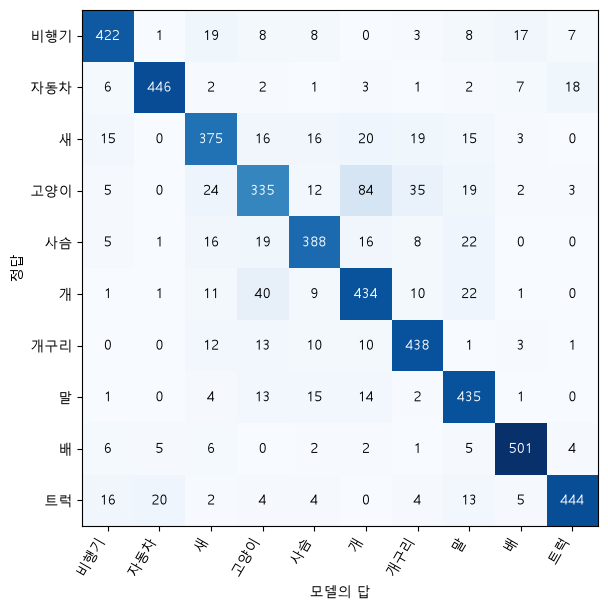

대각선 합 ÷ 전체 = 4218 ÷ 5000 = 84.4% (정확도)
가장 많이 헷갈린 칸 — 정답 고양이 → 답 개 84장
반대 방향 칸 — 정답 개 → 답 고양이 40장


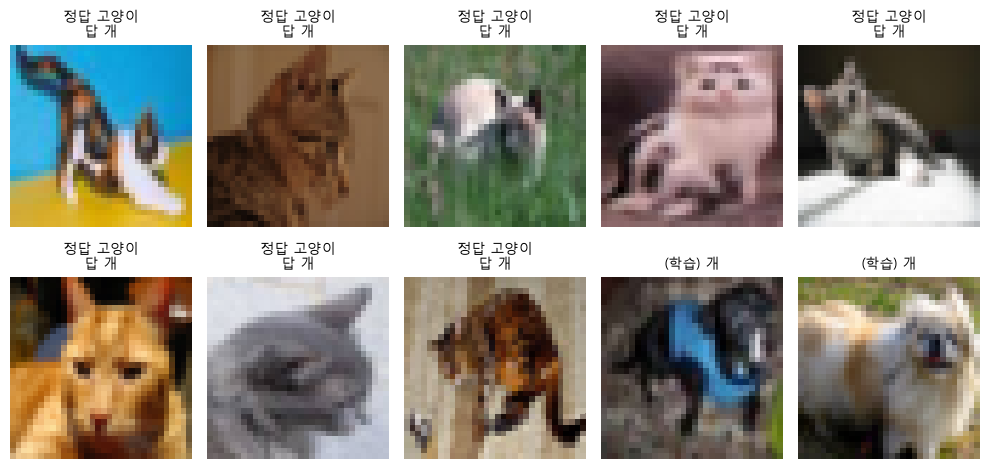

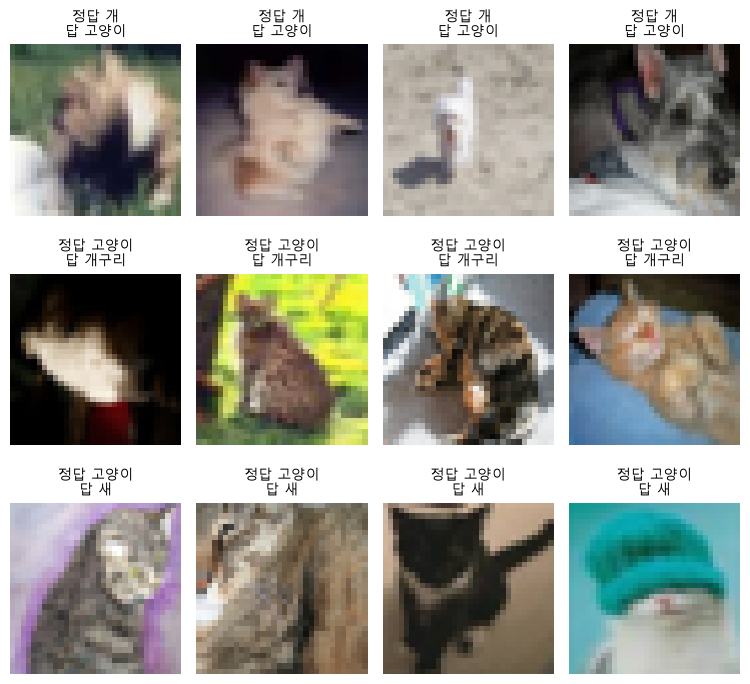

2번째로 많이 헷갈린 칸 — 개 → 고양이 40장
3번째로 많이 헷갈린 칸 — 고양이 → 개구리 35장
4번째로 많이 헷갈린 칸 — 고양이 → 새 24장


In [82]:
# ---------- 6-1 ----------
# 왜 · 혼동행렬을 직접 채워 칸의 뜻을 이해하기 위해
ok_i, ng_i = (pred == y_val).nonzero().flatten(), (pred != y_val).nonzero().flatten()  # 맞힘 · 틀림
few = torch.cat([ok_i[:4], ng_i[:2]])                                     # 맞힌 네 장 + 틀린 두 장
mini = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long)          # 10 × 10 빈 표
for i in few:                                                             # 사진 한 장마다
    mini[y_val[i], pred[i]] += 1                                          # 정답 줄 · 답 칸에 1
print(f"여섯 장 — 대각선(맞힘) {int(mini.diagonal().sum())}장"            # 작은 표 확인
      f" · 대각선 밖(틀림) {int(mini.sum() - mini.diagonal().sum())}장 · 칸 합 {int(mini.sum())}")
cm = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long)            # 검증 사진 전부로
for t, q in zip(y_val.tolist(), pred.tolist()):                           # 정답 · 답 짝
    cm[t, q] += 1                                                         # 그 칸에 1
fig, ax = plt.subplots(figsize=(7.2, 6.2))                                # 혼동행렬
ax.imshow(cm, cmap="Blues")                                               # 진할수록 많음
ko_names = [KO[c] for c in CLASSES]                                       # 축 이름
ax.set_xticks(range(10), ko_names, rotation=60, ha="right")               # 가로 = 모델의 답
ax.set_yticks(range(10), ko_names)                                        # 세로 = 정답
ax.set_xlabel("모델의 답")                                                # 축 이름
ax.set_ylabel("정답")                                                     # 축 이름
for i in range(10):                                                       # 칸마다 숫자
    for j in range(10):                                                   # 열마다
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",            # 칸 숫자
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.tight_layout()                                                        # 정리
plt.show()                                                                # 그리기
off = cm.clone()                                                          # 대각선 밖만 보려고 복사
off.fill_diagonal_(0)                                                     # 맞힌 칸 지우기
TI, PJ = divmod(int(off.argmax()), 10)                                    # 가장 많이 헷갈린 칸
print(f"대각선 합 ÷ 전체 = {int(cm.diagonal().sum())} ÷ {int(cm.sum())}"  # = 정확도
      f" = {cm.diagonal().sum() / cm.sum() * 100:.1f}% (정확도)")
# 가장 큰 대각선 밖 칸
print(f"가장 많이 헷갈린 칸 — 정답 {KO[CLASSES[TI]]} → 답 {KO[CLASSES[PJ]]} {int(off.max())}장")
# 같은 짝 반대쪽
print(f"반대 방향 칸 — 정답 {KO[CLASSES[PJ]]} → 답 {KO[CLASSES[TI]]} {int(off[PJ, TI])}장")


# ---------- 6-2 ----------
# 왜 · 가장 많이 헷갈린 칸의 실제 사진을 열어 원인을 짐작하기 위해
idx = ((y_val == TI) & (pred == PJ)).nonzero().flatten()[:8]    # 그 칸의 사진 여덟 장
ref = (y_train == PJ).nonzero().flatten()[:2]                   # 답 쪽 종류의 학습 사진 두 장
show([x_val[i] for i in idx] + [x_train[i] for i in ref],       # 칸 사진 + 참고 사진
     [f"정답 {KO[CLASSES[TI]]}\n답 {KO[CLASSES[PJ]]}" for _ in idx]
     + [f"(학습) {KO[CLASSES[PJ]]}" for _ in ref], cols=5, size=2.0)
# 칸을 큰 순서로 · 첫째 제외
ranked = sorted(((int(off[i, j]), i, j) for i in range(10) for j in range(10) if i != j),
                reverse=True)[1:4]
imgs, tts = [], []                                              # 다음으로 많은 세 칸
for n_, i, j in ranked:                                         # 칸마다 네 장
    sel = ((y_val == i) & (pred == j)).nonzero().flatten()[:4]  # 그 칸의 앞 네 장
    imgs += [x_val[k] for k in sel]                             # 사진
    tts += [f"정답 {KO[CLASSES[i]]}\n답 {KO[CLASSES[j]]}" for _ in sel]  # 제목
show(imgs, tts, cols=4, size=1.9)                               # 한 줄 = 한 칸
for r, (n_, i, j) in enumerate(ranked, start=2):                # 순위
    print(f"{r}번째로 많이 헷갈린 칸 — {KO[CLASSES[i]]} → {KO[CLASSES[j]]} {n_}장")  # 순위

**실행 흐름**

1. 6-3 종류별 비율
2. 6-4 둘째 · 셋째 답

종류      검증 장수   맞힌 비율 답한 것 중 맞음
비행기         493     85.6%       88.5%
자동차         488     91.4%       94.1%
새           479     78.3%       79.6%
고양이         519     64.5%       74.4%
사슴          475     81.7%       83.4%
개           529     82.0%       74.4%
개구리         488     89.8%       84.1%
말           485     89.7%       80.3%
배           532     94.2%       92.8%
트럭          512     86.7%       93.1%


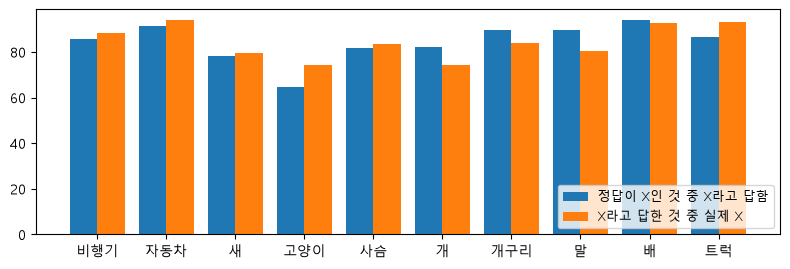

고양이 줄 합 519 · 대각선 335 → 맞힌 비율 64.5%
고양이 열 합 450 · 대각선 335 → 답한 것 중 맞음 74.4%
검증 전체 정확도 84.4% · 가장 낮은 종류 고양이 64.5%


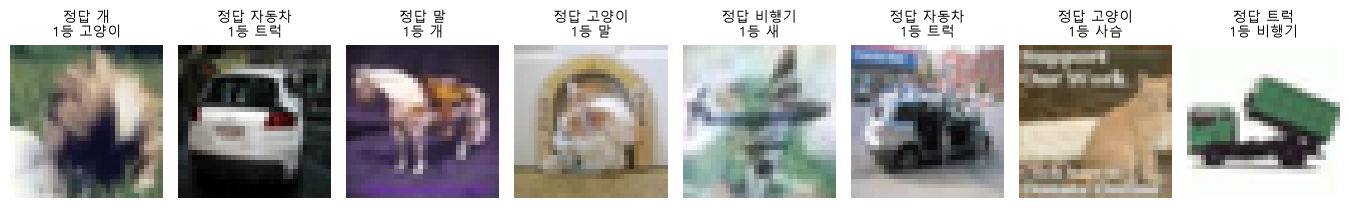

첫째 답 84.4% · 둘째까지 93.9% · 셋째까지 97.1%
틀린 782장 중 둘째 답이 정답 475장
순위  잘 흔들린 종류  자주 틀린 종류
  1   자동차        고양이       
  2   트럭         새         
  3   개구리        사슴        
상위 세 종류 중 겹치는 종류 0개


In [83]:
# ---------- 6-3 ----------
# 왜 · 종류별로 맞힌 비율을 가로(재현율) · 세로(정밀도)로 나눠 읽기 위해
rec, prec = {}, {}                                   # 가로로 읽기(재현율) · 세로로 읽기(정밀도)
print(f"{'종류':6s} {'검증 장수':>6s} {'맞힌 비율':>7s} {'답한 것 중 맞음':>9s}")  # 표 머리줄
for k, name in enumerate(CLASSES):                   # 종류마다
    rec[name] = (cm[k, k] / cm[k].sum()).item()      # 대각선 ÷ 줄 합
    prec[name] = (cm[k, k] / cm[:, k].sum()).item()  # 대각선 ÷ 열 합
    # 장수 · 재현율 · 정밀도
    print(f"{KO[name]:6s} {int(cm[k].sum()):8d} {rec[name] * 100:8.1f}% {prec[name] * 100:10.1f}%")
x_ = np.arange(10)                                   # 막대 위치
fig, ax = plt.subplots(figsize=(8, 2.8))             # 두 막대
# 가로로 읽기
ax.bar(x_ - 0.2, [rec[c] * 100 for c in CLASSES], 0.4, label="정답이 X인 것 중 X라고 답함")
# 세로로 읽기
ax.bar(x_ + 0.2, [prec[c] * 100 for c in CLASSES], 0.4, label="X라고 답한 것 중 실제 X")
ax.set_xticks(x_, [KO[c] for c in CLASSES])          # 종류 이름
ax.legend(fontsize=9, loc="lower right")             # 범례
fig.tight_layout()                                   # 정리
plt.show()                                           # 그리기
LOW = min(rec, key=rec.get)                          # 가로로 읽은 값이 가장 낮은 종류
k = CLASSES.index(LOW)                               # 그 번호
row, col, diag = int(cm[k].sum()), int(cm[:, k].sum()), int(cm[k, k])  # 줄 합 · 열 합 · 대각선
print(f"{KO[LOW]} 줄 합 {row} · 대각선 {diag} → 맞힌 비율 {diag / row * 100:.1f}%")  # 분모 = 줄
print(f"{KO[LOW]} 열 합 {col} · "                    # 분모 = 열
      f"대각선 {diag} → 답한 것 중 맞음 {diag / col * 100:.1f}%")
print(f"검증 전체 정확도 {acc:.1f}% · "              # 평균에 가려짐
      f"가장 낮은 종류 {KO[LOW]} {rec[LOW] * 100:.1f}%")


# ---------- 6-4 ----------
# 왜 · 첫째 답이 틀려도 둘째 · 셋째 답에 정답이 있는지 확인하기 위해
top3 = p_val.topk(3, dim=1).indices  # 사진마다 확률이 큰 세 종류
acc1 = (top3[:, 0] == y_val).float().mean().item() * 100                   # 첫째 답이 맞음
acc2 = (top3[:, :2] == y_val[:, None]).any(1).float().mean().item() * 100  # 둘째까지
acc3 = (top3 == y_val[:, None]).any(1).float().mean().item() * 100         # 셋째까지
sec_ok = ng_i[top3[ng_i, 1] == y_val[ng_i]]                                # 틀렸지만 둘째 답이 정답
show([x_val[i] for i in sec_ok[:8]],                                       # 망설인 틀림 여덟 장
     [f"정답 {KO[CLASSES[y_val[i]]]}\n1등 {KO[CLASSES[top3[i, 0]]]}" for i in sec_ok[:8]],
     cols=8, size=1.7)
print(f"첫째 답 {acc1:.1f}% · 둘째까지 {acc2:.1f}% · 셋째까지 {acc3:.1f}%")  # top-k 정확도
print(f"틀린 {len(ng_i)}장 중 둘째 답이 정답 {len(sec_ok)}장")             # 망설인 틀림
fr = sorted(CLASSES, key=by_class.get, reverse=True)                       # 잘 흔들린 순서 (3장)
rc = sorted(CLASSES, key=rec.get)                                          # 자주 틀린 순서 (6-3)
print("순위  잘 흔들린 종류  자주 틀린 종류")                              # 표 머리줄
for r in range(3):                                                         # 상위 셋
    print(f"{r + 1:3d}   {KO[fr[r]]:10s} {KO[rc[r]]:10s}")                 # 나란히
print(f"상위 세 종류 중 겹치는 종류 {len(set(fr[:3]) & set(rc[:3]))}개")   # 겹침

**실행 흐름**

1. 7-1 학습에 쓴 변화
2. 7-2 Dataset에 증강 넣기

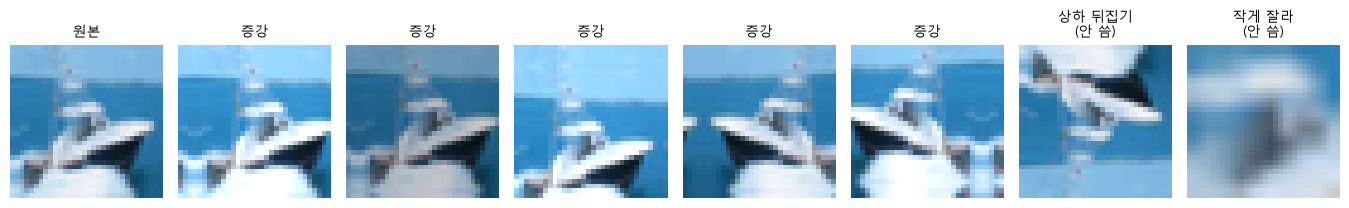

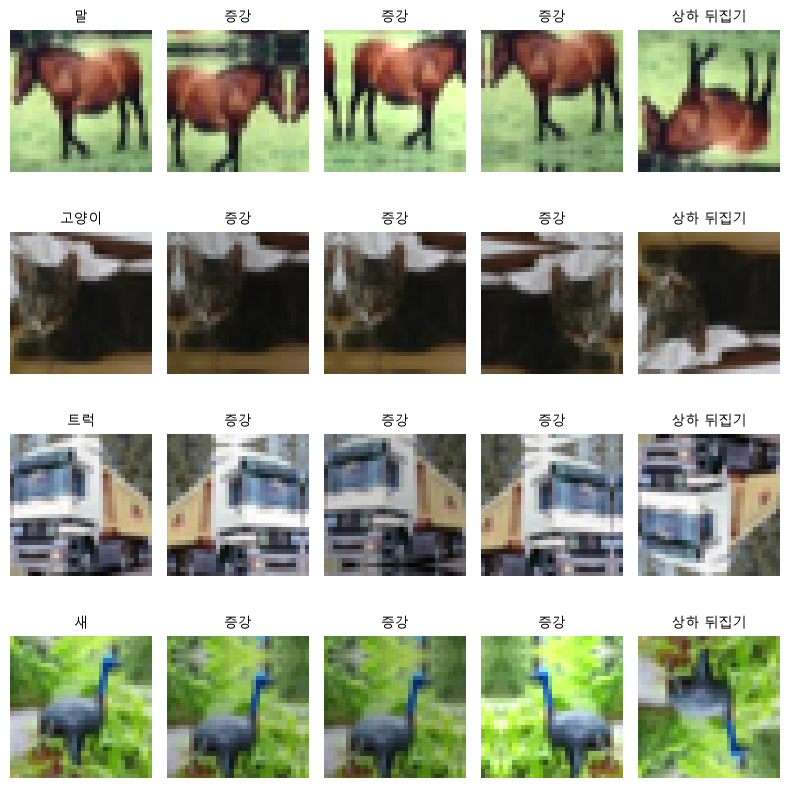

쓴 변화 — 조금 옮기기 · 좌우 반전 · 밝기 조금
안 쓴 변화 — 상하 뒤집기 · 아주 작게 잘라 키우기


In [84]:
# 왜 · 증강이 실제 학습 코드에서 어디에 들어가는지 표준 구조로 보이기 위해
from torch.utils.data import DataLoader, Dataset  # 한 장씩 꺼내는 틀 · 묶는 틀


# ---------- 7-1 ----------
# 왜 · 정답을 바꾸지 않는 변화만 골라 학습에 넣기 위해
def augment(x):  # 학습 때 쓸 증강: 조금 옮겨 자르기 · 좌우 반전(반반) · 밝기 조금
    n, _, hh, ww = x.shape                                      # 장수 · 세로 · 가로
    pad = max(2, hh // 8)                                       # 옮기는 폭 (32칸이면 4칸)
    xp = F.pad(x.float(), (pad,) * 4, mode="reflect")           # 가장자리를 거울처럼 늘림
    i = torch.randint(0, 2 * pad + 1, (n,))                     # 세로 자를 위치 (장마다 무작위)
    j = torch.randint(0, 2 * pad + 1, (n,))                     # 가로 자를 위치
    out = torch.stack([xp[k, :, i[k]:i[k] + hh, j[k]:j[k] + ww] for k in range(n)])  # 자르기
    flip = (torch.rand(n) < 0.5).to(x.device)                   # 반반 확률
    out[flip] = out[flip].flip(-1)                              # 좌우 반전
    gain = 0.8 + 0.4 * torch.rand(n, 1, 1, 1, device=x.device)  # 밝기 0.8 ~ 1.2배
    return (out * gain).clamp(0, 255)                           # 0~255 안으로


# 왜 · 증강 예시 그림이 같은 환경에서 매번 같게 나오도록 하기 위해
torch.manual_seed(1)                                               # 보여 주기용 난수 고정
S = int((y_train == CLASSES.index("ship")).nonzero()[0])           # 학습 사진 중 첫 번째 배
base_img = x_train[S]                                              # 원본
vflip = base_img.flip(-2)                                          # 상하 뒤집기 (쓰지 않음)
# 아주 작게 잘라 키우기 (안 씀)
tiny = TF.resize(TF.center_crop(base_img[None].float(), [10, 10]), [32, 32], antialias=True)[0]
# 원본 · 증강 5 · 안 쓴 2
names_ = ["원본"] + ["증강"] * 5 + ["상하 뒤집기\n(안 씀)", "작게 잘라\n(안 씀)"]  # 칸 제목
five = list(augment(base_img[None].repeat(5, 1, 1, 1)))            # 증강 다섯 번
show([base_img] + five + [vflip, tiny], names_, cols=8, size=1.7)  # 원본 · 증강 5 · 안 쓴 2
torch.manual_seed(2)                                               # 종류별 확인용
imgs, tts = [], []  # 종류마다 원본 · 증강 셋 · 상하 뒤집기
for c in ("horse", "cat", "truck", "bird"):                        # 네 종류
    i = int((y_train == CLASSES.index(c)).nonzero()[0])            # 그 종류 첫 장
    three = list(augment(x_train[i][None].repeat(3, 1, 1, 1)))     # 증강 세 번
    imgs += [x_train[i]] + three + [x_train[i].flip(-2)]           # 원본 · 증강 셋 · 상하 뒤집기
    tts += [KO[c], "증강", "증강", "증강", "상하 뒤집기"]          # 제목
show(imgs, tts, cols=5, size=1.6)                                  # 단서가 남는가
print("쓴 변화 — 조금 옮기기 · 좌우 반전 · 밝기 조금")             # 고른 것
print("안 쓴 변화 — 상하 뒤집기 · 아주 작게 잘라 키우기")          # 뺀 것


# ---------- 7-2 ----------


# 왜 · 사진을 꺼낼 때마다 증강을 적용하는 자리를 __getitem__에 두기 위해
class CifarSet(Dataset):                                  # 사진 · 정답 짝을 한 장씩 돌려줌
    def __init__(self, x, y, aug=None):                   # 증강 함수는 선택
        self.x, self.y, self.aug = x.cpu(), y.cpu(), aug  # 사진 · 정답 · 증강

    def __len__(self):      # 전체 장수
        return len(self.x)  # DataLoader가 씀

    def __getitem__(self, i):             # 번호 → 사진 한 장 · 정답
        img = self.x[i].float()           # 실수로
        if self.aug is not None:          # 증강이 있으면
            img = self.aug(img[None])[0]  # 꺼낼 때마다 새로
        return img, self.y[i]             # 짝으로 돌려줌

**실행 흐름**

1. 증강을 건 학습 Dataset · 원본 검증 Dataset 만들기
2. DataLoader로 한 묶음 꺼내 확인

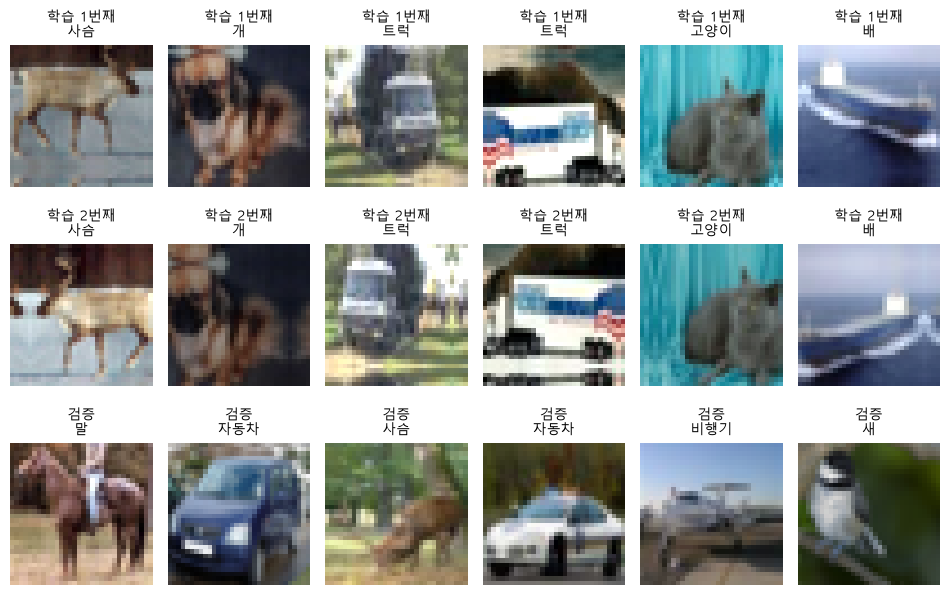

묶음 모양 (6, 3, 32, 32) · 정답 모양 (6,)
같은 순서로 두 번 — 정답 같음 True · 사진 같음 False


In [85]:
# 왜 · 학습 데이터에만 증강을 걸고 검증은 원본 그대로 두기 위해
train_ds = CifarSet(x_train, y_train, aug=augment)                         # 학습용 = 증강 있음
val_ds = CifarSet(x_val, y_val)                                            # 검증용 = 증강 없음
g1, g2 = torch.Generator().manual_seed(0), torch.Generator().manual_seed(0)  # 같은 순서 두 번
b1 = next(iter(DataLoader(train_ds, batch_size=6, shuffle=True, generator=g1)))  # 첫 번째
b2 = next(iter(DataLoader(train_ds, batch_size=6, shuffle=True, generator=g2)))  # 두 번째
v1 = next(iter(DataLoader(val_ds, batch_size=6)))                          # 검증 묶음
show(list(b1[0]) + list(b2[0]) + list(v1[0]),                              # 세 줄
     [f"학습 1번째\n{KO[CLASSES[t]]}" for t in b1[1]]
     + [f"학습 2번째\n{KO[CLASSES[t]]}" for t in b2[1]]
     + [f"검증\n{KO[CLASSES[t]]}" for t in v1[1]], cols=6, size=1.6)
print(f"묶음 모양 {tuple(b1[0].shape)} · 정답 모양 {tuple(b1[1].shape)}")  # 모델에 넣는 모양
print(f"같은 순서로 두 번 — 정답 같음 {torch.equal(b1[1], b2[1])}"         # 정답은 같고 사진은 다름
      f" · 사진 같음 {torch.equal(b1[0], b2[0])}")

**실행 흐름**

1. 8-1 증강 모델 학습
2. 8-2 두 모델 같은 시험

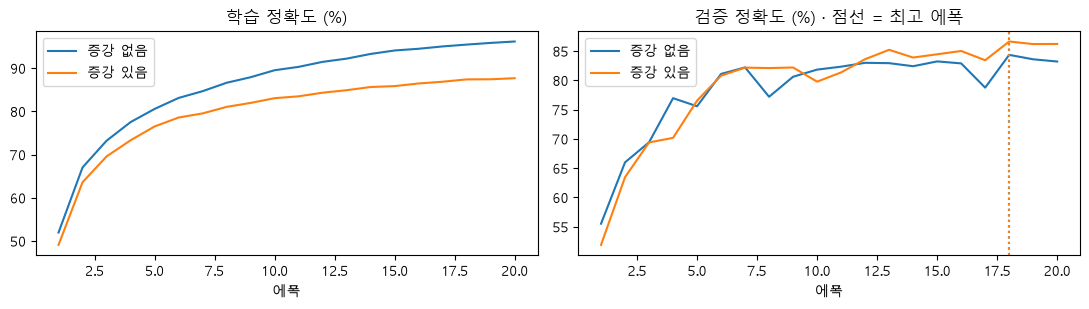

증강 없음 — 마지막 학습 96.2% · 최고 검증 84.4% (에폭 18)
증강 있음 — 마지막 학습 87.7% · 최고 검증 86.6% (에폭 18)


증강 없음 — 원래 테스트 83.7% · 흔든 테스트 66.4%


증강 있음 — 원래 테스트 85.9% · 흔든 테스트 69.2%
차이(있음 - 없음) — 원래 +2.1%p · 흔든 +2.8%p


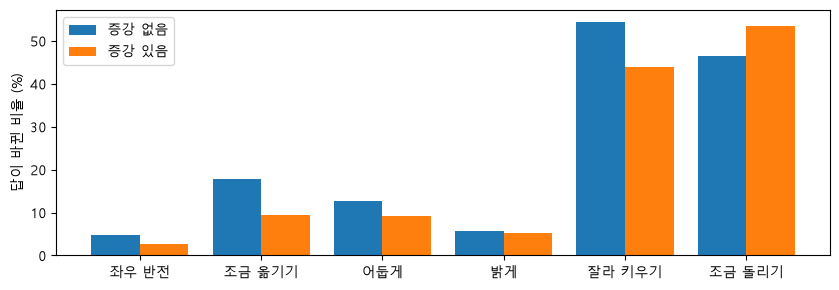

In [86]:
# ---------- 8-1 ----------
# 왜 · 증강만 바꾸고 나머지는 같은 조건으로 두 번째 모델을 학습하기 위해
H["aug"], CK["aug"] = fit(aug=augment)  # 바꾼 것 하나 = 증강 (나머지 조건 같음 · 약 1분 30초)
aug_m = load_model(CK["aug"]["best"])                  # 검증이 가장 좋았던 순간
ha = H["aug"]                                          # 증강 모델 기록
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))        # 왼쪽 학습 · 오른쪽 검증
for name, hh, key in (("증강 없음", h, "base"), ("증강 있음", ha, "aug")):  # 두 모델
    # 학습 정확도
    ax[0].plot([r["epoch"] for r in hh], [r["train_acc"] * 100 for r in hh], label=name)
    # 검증 정확도
    ax[1].plot([r["epoch"] for r in hh], [r["val_acc"] * 100 for r in hh], label=name)
    ax[1].axvline(CK[key]["best_epoch"], ls=":", color=ax[1].lines[-1].get_color())  # 최고 에폭
ax[0].set_title("학습 정확도 (%)")                     # 증강 쪽은 더 어려운 사진으로 잰 값
ax[1].set_title("검증 정확도 (%) · 점선 = 최고 에폭")  # 같은 시험
for a in ax:                                           # 공통
    a.set_xlabel("에폭")                               # 가로축
    a.legend()                                         # 범례
fig.tight_layout()                                     # 정리
plt.show()                                             # 그리기
for name, hh, key in (("증강 없음", h, "base"), ("증강 있음", ha, "aug")):  # 숫자로
    print(f"{name} — 마지막 학습 {hh[-1]['train_acc'] * 100:.1f}%"  # 두 모델 숫자
          f" · 최고 검증 {max(r['val_acc'] for r in hh) * 100:.1f}% (에폭 {CK[key]['best_epoch']})")


# ---------- 8-2 ----------
# 왜 · 두 모델이 똑같이 흔든 사진으로 시험을 보게 하기 위해
g123 = torch.Generator().manual_seed(123)                              # 흔든 테스트를 고정할 난수
pick = torch.randint(0, 6, (len(x_test),), generator=g123)             # 사진마다 변화 번호
x_shaken = torch.empty(x_test.shape, dtype=torch.float32, device=DEV)  # 흔든 테스트 (한 번만 만듦)
for i, k in enumerate(KINDS):                                          # 사진마다 미리 정한 변화
    m = (pick == i).to(DEV)                                            # 그 변화를 받을 사진
    x_shaken[m] = shake(x_test[m], k)                                  # 고정
rows = {}                                                              # 모델별 (원래, 흔든)
for name, mdl in (("증강 없음", model), ("증강 있음", aug_m)):         # 두 모델에 똑같은 시험
    # 원래 · 흔든 정확도
    rows[name] = (evaluate(mdl, x_test, y_test)[1], evaluate(mdl, x_shaken, y_test)[1])
    print(f"{name} — 원래 테스트 {rows[name][0] * 100:.1f}% · "        # 두 시험 점수
          f"흔든 테스트 {rows[name][1] * 100:.1f}%")
d_clean = (rows["증강 있음"][0] - rows["증강 없음"][0]) * 100          # 차이 (반올림 전)
d_shaken = (rows["증강 있음"][1] - rows["증강 없음"][1]) * 100         # 차이
print(f"차이(있음 - 없음) — 원래 {d_clean:+.1f}%p · 흔든 {d_shaken:+.1f}%p")  # 퍼센트포인트
p_aug = predict(aug_m, x_val).argmax(1)                                # 증강 모델의 검증 답
both_ok = ((pred == y_val) & (p_aug == y_val)).nonzero().flatten()     # 둘 다 맞힌 같은 사진
r_base, r_aug = {}, {}                                                 # 변화별 바뀐 비율
for k in KINDS:                                                        # 같은 사진 · 같은 변화
    xs = shake(x_val[both_ok], k)                                      # 흔든 사진
    # 증강 없음 바뀐 비율
    r_base[k] = (predict(model, xs).argmax(1) != y_val[both_ok]).float().mean().item()
    # 증강 있음 바뀐 비율
    r_aug[k] = (predict(aug_m, xs).argmax(1) != y_val[both_ok]).float().mean().item()
pos = np.arange(6)                                                     # 막대 위치
fig, ax = plt.subplots(figsize=(8.5, 3.0))                             # 두 막대
ax.bar(pos - 0.2, [r_base[k] * 100 for k in KINDS], 0.4, label="증강 없음")  # 파랑
ax.bar(pos + 0.2, [r_aug[k] * 100 for k in KINDS], 0.4, label="증강 있음")  # 주황
ax.set_xticks(pos, [KIND_KO[k] for k in KINDS])                        # 변화 이름
ax.set_ylabel("답이 바뀐 비율 (%)")                                    # 낮을수록 덜 흔들림
ax.legend()                                                            # 범례
fig.tight_layout()                                                     # 정리
plt.show()                                                             # 그리기
USED, UNUSED = ["hflip", "shift", "dark", "bright"], ["crop", "rotate"]  # 증강에 넣은 · 안 넣은

**실행 흐름**

1. 8-3 한 모델만 틀린 사진
2. 8-4 시작값 세 개로 다시 하기

둘 다 맞힌 검증 3955장 · 넣은 변화 10.3% → 6.7% · 안 넣은 변화 50.4% → 48.7%


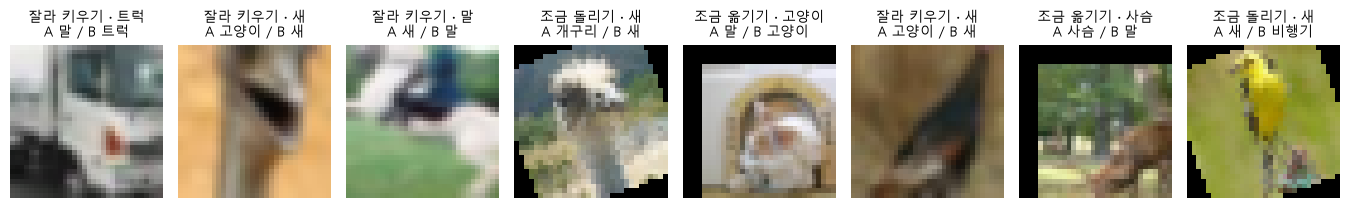

흔든 검증에서 A(증강 없음)만 틀림 539장 · B(증강 있음)만 틀림 444장


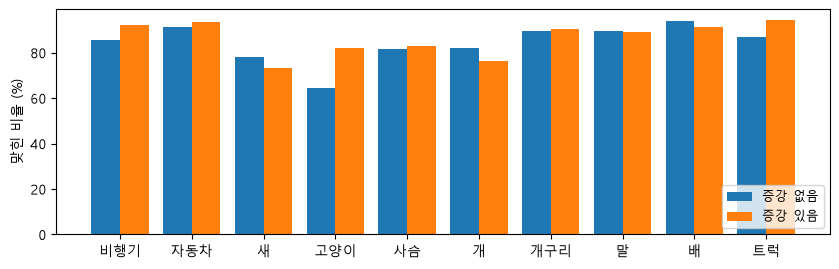

가장 많이 나아진 종류 고양이 +17.7%p · 가장 적게 나아진 종류 개 -5.9%p


In [87]:
# 왜 · 변화 종류별 결과를 묶어 평균으로 비교하기 위해
def mean(d, ks):                              # 변화 묶음의 평균 바뀐 비율 %
    return np.mean([d[k] for k in ks]) * 100  # 평균


print(f"둘 다 맞힌 검증 {len(both_ok)}장"  # 같은 사진만 분모
      f" · 넣은 변화 {mean(r_base, USED):.1f}% → {mean(r_aug, USED):.1f}%"
      f" · 안 넣은 변화 {mean(r_base, UNUSED):.1f}% → {mean(r_aug, UNUSED):.1f}%")


# ---------- 8-3 ----------
# 왜 · 한 모델만 틀린 흔든 사진을 같은 조건에서 찾기 위해
g7 = torch.Generator().manual_seed(7)                                      # 흔든 검증을 고정할 난수
pick_v = torch.randint(0, 6, (len(x_val),), generator=g7)                  # 사진마다 변화 번호
xv_shaken = torch.empty(x_val.shape, dtype=torch.float32, device=DEV)      # 흔든 검증 사진
for i, k in enumerate(KINDS):                                              # 사진마다 변화 하나
    m = (pick_v == i).to(DEV)                                              # 그 변화를 받을 사진
    xv_shaken[m] = shake(x_val[m], k)                                      # 고정
pb, pa = predict(model, xv_shaken).argmax(1), predict(aug_m, xv_shaken).argmax(1)  # 두 모델의 답
only_aug_ok = ((pb != y_val) & (pa == y_val)).nonzero().flatten()          # A만 틀림
only_base_ok = ((pb == y_val) & (pa != y_val)).nonzero().flatten()         # B만 틀림
sel = list(only_aug_ok[:6]) + list(only_base_ok[:2])                       # 앞 여섯 · 뒤 두 장
show([xv_shaken[i] for i in sel],  # 제목: 변화 · 정답 / A의 답 · B의 답
     [f"{KIND_KO[KINDS[pick_v[i]]]} · {KO[CLASSES[y_val[i]]]}\n"
      f"A {KO[CLASSES[pb[i]]]} / B {KO[CLASSES[pa[i]]]}" for i in sel], cols=8, size=1.7)
print(f"흔든 검증에서 A(증강 없음)만 틀림 {len(only_aug_ok)}장 · "         # 서로 바뀐 사진 수
      f"B(증강 있음)만 틀림 {len(only_base_ok)}장")
# 증강 모델 종류별 재현율
rec_aug = {c: (p_aug[y_val == k] == k).float().mean().item() for k, c in enumerate(CLASSES)}
gains = {c: rec_aug[c] - rec[c] for c in CLASSES}                          # 종류별 차이
fig, ax = plt.subplots(figsize=(8.5, 2.8))                                 # 종류별 두 모델
ax.bar(x_ - 0.2, [rec[c] * 100 for c in CLASSES], 0.4, label="증강 없음")  # 파랑
ax.bar(x_ + 0.2, [rec_aug[c] * 100 for c in CLASSES], 0.4, label="증강 있음")  # 주황
ax.set_xticks(x_, [KO[c] for c in CLASSES])                                # 종류 이름
ax.set_ylabel("맞힌 비율 (%)")                                             # 원래 검증 사진
ax.legend(fontsize=9, loc="lower right")                                   # 범례
fig.tight_layout()                                                         # 정리
plt.show()                                                                 # 그리기
g_hi, g_lo = max(gains, key=gains.get), min(gains, key=gains.get)          # 가장 많이 · 적게
print(f"가장 많이 나아진 종류 {KO[g_hi]} {gains[g_hi] * 100:+.1f}%p"       # 종류별 차이 양 끝
      f" · 가장 적게 나아진 종류 {KO[g_lo]} {gains[g_lo] * 100:+.1f}%p")


# ---------- 8-4 ----------
# 왜 · 작은 데이터로 시작값만 바꿔 증강 효과가 우연이 아닌지 확인하기 위해
def mini_run(seed, use_aug, n=1000, epochs=10):  # n장으로 처음부터 짧게 → 최고 검증 정확도
    torch.manual_seed(seed)                                              # 시작값만 바꿈
    m_ = SmallCNN(len(CLASSES)).to(DEV)                                  # 새 모델
    o_ = torch.optim.Adam(m_.parameters(), lr=2e-3)                      # 같은 학습률
    best_ = -1.0                                                         # 최고 검증
    for e in range(1, epochs + 1):                                       # 에폭
        train_one_epoch(m_, o_, x_train[:n], y_train[:n], bs=64,         # 증강 여부만 다르게
                        aug=augment if use_aug else None, seed=e + 100 * seed)
        best_ = max(best_, evaluate(m_, x_val[:1000], y_val[:1000])[1])  # 최고 갱신
    return best_ * 100                                                   # %

**실행 흐름**

1. 8-5 확신 구간별 정답률 · 다음 비교 설계

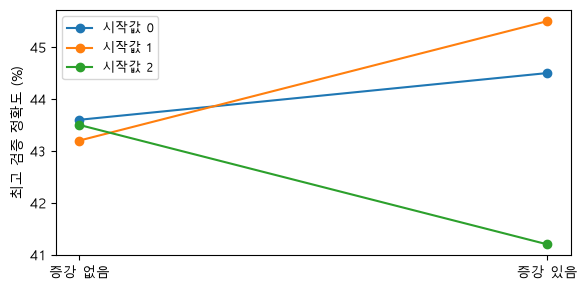

학습 1000장 · 10에폭 · 시작값 3개 — 증강 있음이 더 높은 경우 2개
범위 — 증강 없음 43.2~43.6% · 증강 있음 41.2~45.5%


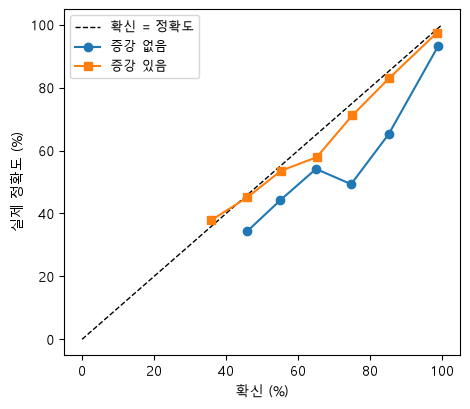

평균 확신 - 실제 정확도 — 증강 없음 +8.0%p · 증강 있음 +1.8%p


In [88]:
# 왜 · 시작값 세 개 × 증강 유무 결과를 한 표에 모으기 위해
res_mini = {(sd, a): mini_run(sd, a) for sd in (0, 1, 2) for a in (False, True)}  # 여섯 번 학습
fig, ax = plt.subplots(figsize=(6, 3.0))  # 시작값마다 선 하나
for sd in (0, 1, 2):                                                              # 시작값
    # 시작값마다 선
    ax.plot([0, 1], [res_mini[(sd, False)], res_mini[(sd, True)]], "o-", label=f"시작값 {sd}")
ax.set_xticks([0, 1], ["증강 없음", "증강 있음"])                                 # 왼쪽 · 오른쪽
ax.set_ylabel("최고 검증 정확도 (%)")                                             # 세로축
ax.legend(fontsize=9)                                                             # 범례
fig.tight_layout()                                                                # 정리
plt.show()                                                                        # 그리기
up_n = sum(res_mini[(sd, True)] > res_mini[(sd, False)] for sd in (0, 1, 2))      # 증강이 높은 수
nb_ = [res_mini[(sd, False)] for sd in (0, 1, 2)]                                 # 증강 없음 세 값
na_ = [res_mini[(sd, True)] for sd in (0, 1, 2)]                                  # 증강 있음 세 값
print(f"학습 1000장 · 10에폭 · 시작값 3개 — 증강 있음이 더 높은 경우 {up_n}개")   # 방향
print(f"범위 — 증강 없음 {min(nb_):.1f}~{max(nb_):.1f}% · "                       # 두 범위가 겹치나
      f"증강 있음 {min(na_):.1f}~{max(na_):.1f}%")


# ---------- 8-5 ----------
# 왜 · 확신 구간별 실제 정답률을 계산해 확신을 믿어도 되는지 판단하기 위해
def reliability(p, y, bins=10):                                       # 확신 구간별 실제 정확도
    c_, pr_ = p.max(1).values, p.argmax(1)                            # 확신 · 답
    xs_, ac_ = [], []                                                 # 구간 평균 확신 · 실제 정확도
    for b in range(bins):                                             # 0.1 폭 구간
        m = (c_ > b / bins) & (c_ <= (b + 1) / bins)                  # 이 구간의 사진
        if m.sum() >= 30:                                             # 30장보다 적은 구간은 뺌
            xs_.append(c_[m].mean().item() * 100)                     # 평균 확신
            ac_.append((pr_[m] == y[m]).float().mean().item() * 100)  # 실제 정확도
    return xs_, ac_, (c_.mean() - (pr_ == y).float().mean()).item() * 100  # + 과신 정도


xb_, yb_, gb = reliability(p_val, y_val)                                           # 증강 없음
xa_, ya_, ga = reliability(predict(aug_m, x_val), y_val)                           # 증강 있음
fig, ax = plt.subplots(figsize=(4.8, 4.2))                                         # 신뢰도 그림
ax.plot([0, 100], [0, 100], "k--", lw=1, label="확신 = 정확도")                    # 대각선
ax.plot(xb_, yb_, "o-", label="증강 없음")                                         # 파랑
ax.plot(xa_, ya_, "s-", label="증강 있음")                                         # 주황
ax.set_xlabel("확신 (%)")                                                          # 가로축
ax.set_ylabel("실제 정확도 (%)")                                                   # 세로축
ax.legend(fontsize=9)                                                              # 범례
fig.tight_layout()                                                                 # 정리
plt.show()                                                                         # 그리기
print(f"평균 확신 - 실제 정확도 — 증강 없음 {gb:+.1f}%p · 증강 있음 {ga:+.1f}%p")  # 양수 = 과신


# 왜 · 다음 실험에서 바꿀 조건을 함수로 먼저 설계해 두기 위해
def augment_next(x):  # 다음 비교 후보: 지금 증강 + 조금 돌리기 + 가끔 잘라 키우기
    out = augment(x)                                    # 지금 증강
    ang = (torch.rand(len(out)) * 40 - 20).tolist()     # ±20도
    out = torch.stack([TF.rotate(out[k:k + 1], ang[k])[0] for k in range(len(out))])  # 돌리기
    crop = (torch.rand(len(out)) < 0.5).to(out.device)  # 절반만
    if crop.any():                                      # 고른 사진이 있으면
        # 가운데 24칸 → 32칸
        out[crop] = TF.resize(TF.center_crop(out[crop], [24, 24]), [32, 32], antialias=True)
    return out                                          # 학습은 하지 않고 모양만 봄

**실행 흐름**

1. 다음 실험용 증강의 결과 모양만 확인

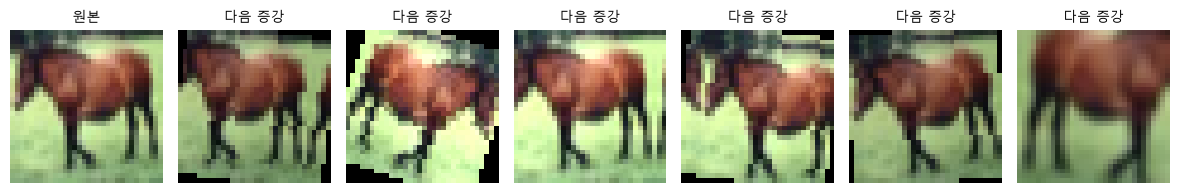

In [89]:
torch.manual_seed(4)                                                    # 보여 주기용
horse = x_train[int((y_train == CLASSES.index("horse")).nonzero()[0])]  # 첫 번째 말
# 모양만 확인
show([horse] + list(augment_next(horse[None].repeat(6, 1, 1, 1))), ["원본"] + ["다음 증강"] * 6,
     cols=7, size=1.7)

**실행 흐름**

1. 9-1 두 모델이 모두 틀린 사진
2. 9-2 해상도 낮추기

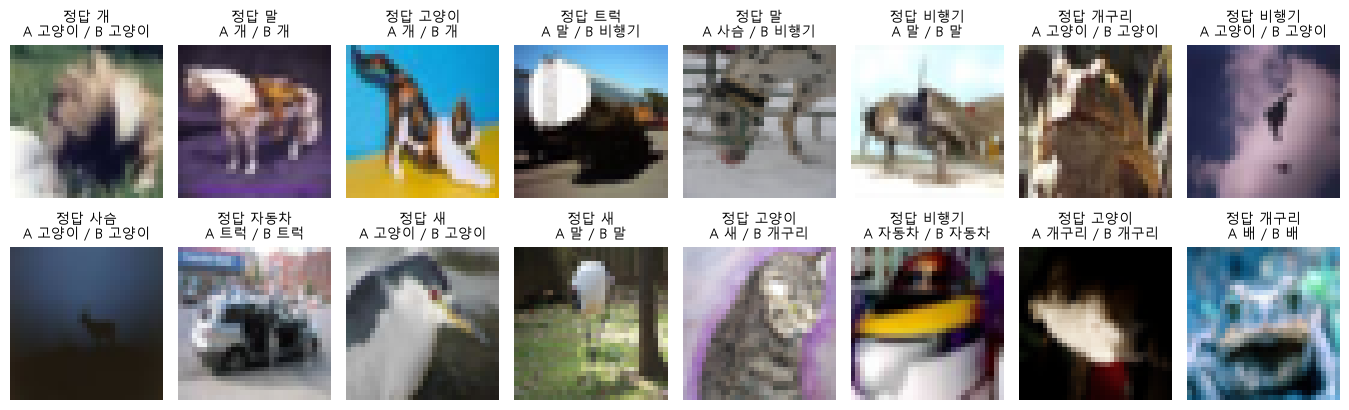

두 모델이 모두 틀린 검증 사진 405장
같은 답으로 틀림 273장 · 서로 다른 답으로 틀림 132장
같은 답으로 틀린 짝 — 개 → 고양이 31장 · 고양이 → 개 26장 · 새 → 비행기 13장


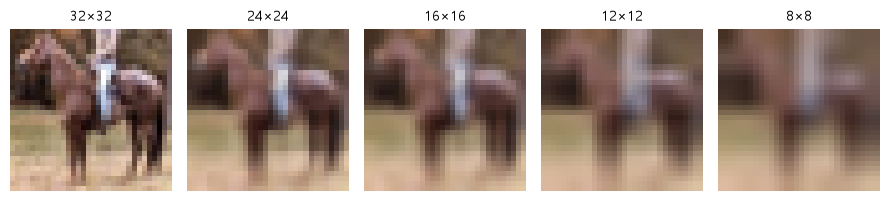

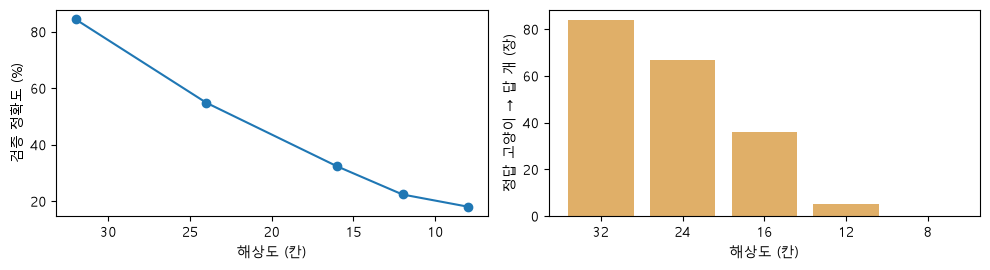

해상도별 정확도 — 32칸 84.4% · 16칸 32.3% · 8칸 18.0%
고양이 → 개 — 32칸 84장 · 16칸 36장 · 8칸 0장


In [90]:
from collections import Counter  # 짝 세기


# ---------- 9-1 ----------

# 왜 · 두 모델이 모두 틀린 사진에서 같은 실수를 하는지 확인하기 위해
both = ((pred != y_val) & (p_aug != y_val)).nonzero().flatten()               # 두 모델이 모두 틀림
show([x_val[i] for i in both[:16]],                                           # 앞 열여섯 장
     [f"정답 {KO[CLASSES[y_val[i]]]}\nA {KO[CLASSES[pred[i]]]} / B {KO[CLASSES[p_aug[i]]]}"
      for i in both[:16]], cols=8, size=1.7)
rm_s = [int(i) for i in both if pred[i] == p_aug[i]]                          # 같은 답으로 틀림
rm_d = [int(i) for i in both if pred[i] != p_aug[i]]                          # 다른 답으로 틀림
print(f"두 모델이 모두 틀린 검증 사진 {len(both)}장")                         # 남는 오류
print(f"같은 답으로 틀림 {len(rm_s)}장 · 서로 다른 답으로 틀림 {len(rm_d)}장")  # 둘로 나눔
rm_pairs = Counter((CLASSES[y_val[i]], CLASSES[pred[i]]) for i in rm_s).most_common(3)  # 많은 짝
txt = " · ".join(f"{KO[t_]} → {KO[p_]} {n_}장" for (t_, p_), n_ in rm_pairs)  # 짝 글자
print("같은 답으로 틀린 짝 — " + txt)                                         # 많은 짝 셋


# ---------- 9-2 ----------
# 왜 · 해상도를 낮추면 어느 크기에서 답이 바뀌는지 한 장으로 확인하기 위해
LOOK = int((y_val == CLASSES.index("horse")).nonzero()[0])    # 검증 사진 중 첫 번째 말
sizes = [32, 24, 16, 12, 8]                                   # 줄일 칸 수
ci, di = CLASSES.index("cat"), CLASSES.index("dog")           # 고양이 · 개
accs_r, cd_r, look_r = [], [], []                             # 정확도 · 고양이→개 · 보여 줄 사진
for sz in sizes:                                              # 해상도마다 (같은 모델 · 같은 사진)
    xs = x_val.float()                                        # 원본
    if sz < 32:  # 줄였다가 다시 32칸으로 키움 (칸 수는 같고 정보만 줄어듦)
        xs = F.interpolate(F.interpolate(xs, size=sz, mode="area"), size=32,  # 줄였다가 32로
                           mode="bilinear", align_corners=False)
    pp = predict(model, xs).argmax(1)                         # 답
    accs_r.append((pp == y_val).float().mean().item() * 100)  # 정확도
    cd_r.append(int(((y_val == ci) & (pp == di)).sum()))      # 고양이 → 개
    look_r.append(xs[LOOK])                                   # 말 사진
show(look_r, [f"{s}×{s}" for s in sizes], cols=5, size=1.8)   # 해상도별 모습
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))               # 정확도 · 헷갈림
ax[0].plot(sizes, accs_r, "o-")                               # 정확도
ax[0].invert_xaxis()                                          # 왼쪽이 원래 해상도
ax[0].set_xlabel("해상도 (칸)")                               # 가로축
ax[0].set_ylabel("검증 정확도 (%)")                           # 세로축
ax[1].bar([str(z) for z in sizes], cd_r, color="#e0af68")     # 고양이 → 개
ax[1].set_xlabel("해상도 (칸)")                               # 가로축
ax[1].set_ylabel("정답 고양이 → 답 개 (장)")                  # 세로축
fig.tight_layout()                                            # 정리
plt.show()                                                    # 그리기
print(f"해상도별 정확도 — 32칸 {accs_r[0]:.1f}% · "           # 세 해상도
      f"16칸 {accs_r[2]:.1f}% · 8칸 {accs_r[4]:.1f}%")
print(f"고양이 → 개 — 32칸 {cd_r[0]}장 · 16칸 {cd_r[2]}장 · 8칸 {cd_r[4]}장")  # 잣대가 맞나

**실행 흐름**

1. 9-3 가려 보기 지도

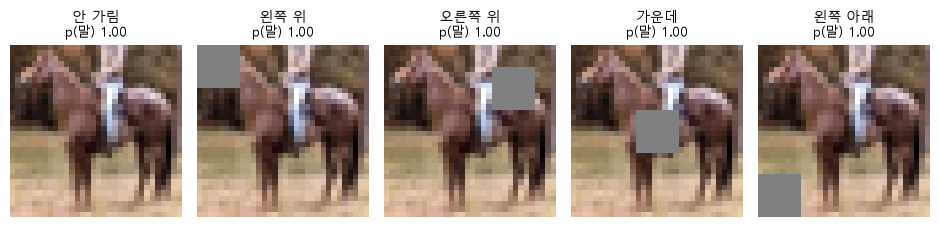

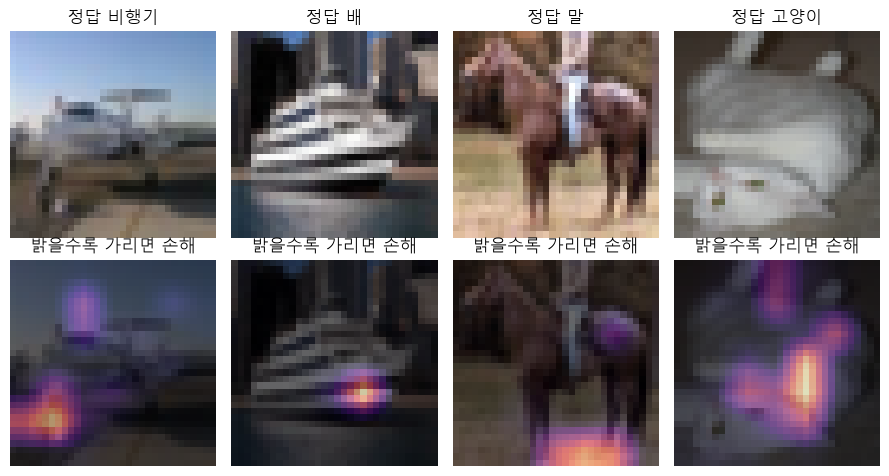

자리 7×7 = 49번 다시 계산 · 사진마다 밝기를 따로 맞춤


In [91]:
# ---------- 9-3 ----------
# 왜 · 가려 보기 실험에 쓸 사진을 정해 두기 위해
H_I = CLASSES.index("horse")                                                 # 말 번호
h_occ = int(((y_val == H_I) & (pred == y_val) & (conf > 0.9)).nonzero()[0])  # 확신 높게 맞힌 말
# 가릴 자리 (세로, 가로)
spots = {"안 가림": None, "왼쪽 위": (0, 0), "오른쪽 위": (4, 20), "가운데": (12, 12),
         "왼쪽 아래": (24, 0)}
imgs_o, titles_o = [], []                                                    # 가린 사진 · 제목
for name, pos in spots.items():                                              # 네 자리 + 안 가림
    x_o = x_val[h_occ].float().clone()                                       # 원본 복사
    if pos is not None:                                                      # 가릴 자리
        x_o[:, pos[0]:pos[0] + 8, pos[1]:pos[1] + 8] = 128.0                 # 8칸 회색 네모
    p_o = predict(model, x_o[None])[0, H_I].item()                           # 말일 확률
    imgs_o.append(x_o)                                                       # 사진
    titles_o.append(f"{name}\np(말) {p_o:.2f}")                              # 제목
show(imgs_o, titles_o, cols=5, size=1.9)                                     # 원리 한 장


# 왜 · 어느 자리를 가리면 확신이 떨어지는지 지도로 만들어 모델이 본 곳을 짐작하기 위해
def occlusion(img, label, patch=8, stride=4):          # 자리마다 가렸을 때 정답 확률이 떨어진 폭
    base = predict(model, img[None])[0, label].item()  # 안 가렸을 때
    n_ = (32 - patch) // stride + 1                    # 한 변 자리 수 (7)
    batch = []                                         # 가린 사진들
    for i in range(n_):                                # 세로 자리
        for j in range(n_):                            # 가로 자리
            x = img.float().clone()                    # 복사
            x[:, i * stride:i * stride + patch, j * stride:j * stride + patch] = 128.0  # 가림
            batch.append(x)                            # 모음
    return (base - predict(model, torch.stack(batch))[:, label]).view(n_, n_)  # 7 × 7 지도


# 왜 · 종류마다 모델이 기대는 자리가 다른지 비교하기 위해
names_o = ["airplane", "ship", "horse", "cat"]                                 # 네 종류
# 종류마다 확신 높게 맞힌 첫 장
picks_o = [int(((y_val == CLASSES.index(c)) & (pred == y_val) & (conf > 0.9)).nonzero()[0])
           for c in names_o]
fig, ax = plt.subplots(2, 4, figsize=(9, 4.8))                                 # 위 원본 · 아래 겹침
for k, i in enumerate(picks_o):                                                # 사진마다
    img = (x_val[i].float() / 255).permute(1, 2, 0).cpu().numpy()              # 그릴 사진
    heat = occlusion(x_val[i], int(y_val[i]))                                  # 7 × 7
    # 7 → 32칸으로 키움
    up = F.interpolate(heat[None, None], size=(32, 32), mode="bilinear")[0, 0].cpu().numpy()
    ax[0, k].imshow(img, interpolation="nearest")                              # 원본
    ax[0, k].set_title(f"정답 {KO[CLASSES[y_val[i]]]}")                        # 제목
    ax[1, k].imshow(img, interpolation="nearest")                              # 바탕
    # 지도 겹치기
    ax[1, k].imshow(up.clip(0), cmap="magma", alpha=0.6, vmin=0, vmax=max(float(heat.max()), 1e-3))
    ax[1, k].set_title("밝을수록 가리면 손해")                                 # 제목
    for a in ax[:, k]:                                                         # 두 칸
        a.axis("off")                                                          # 눈금 끄기
fig.tight_layout()                                                             # 정리
plt.show()                                                                     # 그리기
print(f"자리 {heat.shape[0]}×{heat.shape[1]} = {heat.numel()}번 다시 계산 · "  # 계산 횟수
      f"사진마다 밝기를 따로 맞춤")

**실행 흐름**

1. 9-4 첫 층 필터

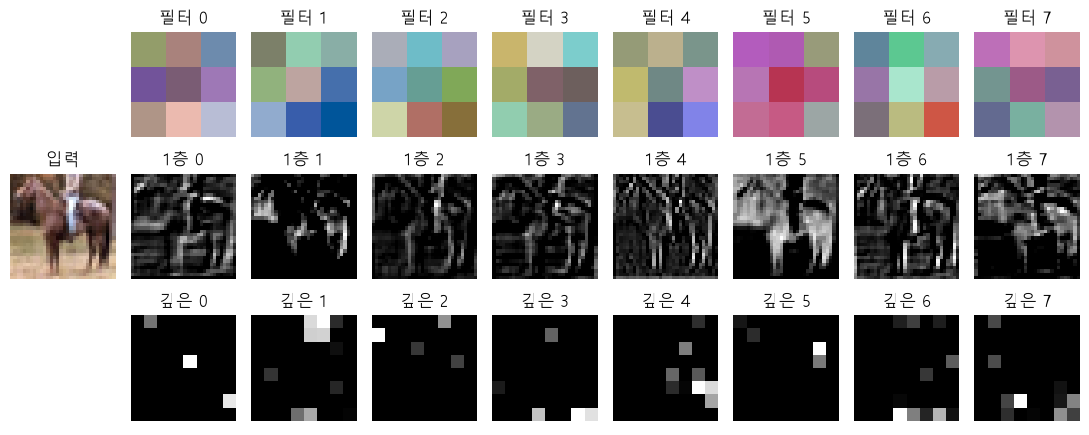

첫 층 필터 (32, 3, 3, 3) · 첫 층 특징 지도 (32, 32, 32) · 깊은 층 (128, 8, 8)


In [92]:
# ---------- 9-4 ----------
# 왜 · 첫 합성곱 층이 배운 필터 모양을 직접 보기 위해
w1 = model.features[0].weight.detach()           # 첫 층 필터 (32, 3, 3, 3)
wn = (w1 - w1.min()) / (w1.max() - w1.min())     # 0~1로 맞춰 색으로 그림
with torch.no_grad():                            # 특징 지도만 계산
    t_ = to_input(x_val[LOOK:LOOK + 1])          # 말 사진
    a1 = model.features[:3](t_)[0]               # 첫 합성곱 + BN + ReLU 뒤
    a3 = model.features[:17](t_)[0]              # 셋째 묶음 첫 합성곱 뒤
fig, ax = plt.subplots(3, 9, figsize=(11, 4.4))  # 세 줄
for a in ax.flat:                                # 모든 칸
    a.axis("off")                                # 눈금 끄기
# 입력 사진
ax[1, 0].imshow((x_val[LOOK].float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[1, 0].set_title("입력")                       # 사진
for k in range(8):                               # 여덟 개씩
    ax[0, k + 1].imshow(wn[k].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")  # 필터
    ax[0, k + 1].set_title(f"필터 {k}")          # 제목
    ax[1, k + 1].imshow(a1[k].cpu().numpy(), cmap="gray", interpolation="nearest")  # 첫 층 지도
    ax[1, k + 1].set_title(f"1층 {k}")           # 제목
    ax[2, k + 1].imshow(a3[k].cpu().numpy(), cmap="gray", interpolation="nearest")  # 깊은 층 지도
    ax[2, k + 1].set_title(f"깊은 {k}")          # 제목
fig.tight_layout()                               # 정리
plt.show()                                       # 그리기
print(f"첫 층 필터 {tuple(w1.shape)} · 첫 층 특징 지도 {tuple(a1.shape)} · "  # 세 가지 모양
      f"깊은 층 {tuple(a3.shape)}")

**실행 흐름**

1. 10-1 구조별 가중치 · 층 수

In [93]:
# 왜 · 유명한 구조들을 직접 만들어 크기를 비교하기 위해
from torchvision import models  # 유명한 구조 (가중치 없이 모양만)


# ---------- 10-1 ----------


def n_params(m):                                   # 학습할 숫자 개수
    return sum(p.numel() for p in m.parameters())  # 가중치 · 편향 전부


def n_layers(m, kinds=(nn.Conv2d, nn.Linear)):             # 합성곱 · 선형 모듈 개수
    return sum(isinstance(x, kinds) for x in m.modules())  # 안쪽까지 셈


# 왜 · 구조마다 가중치 수 · 층 수를 같은 방법으로 세기 위해
nets = {"AlexNet (2012)": models.alexnet(weights=None),       # 모양만 · 숫자는 무작위
        "VGG16 (2014)": models.vgg16(weights=None),
        "GoogLeNet (2014)": models.googlenet(weights=None, aux_logits=False, init_weights=False)}
print(f"{'모델':16s} {'합성곱·선형':>8s} {'파라미터':>13s}")  # 표 머리줄
for name, m in nets.items():                                  # 세 구조
    print(f"{name:16s} {n_layers(m):8d} {n_params(m):13,d}")  # 모듈 수 · 숫자 수
print(f"{'우리 작은 CNN':14s} {n_layers(model):8d} {n_params(model):13,d}")  # 비교
conv1 = model.features[0]                                     # 첫 합성곱
w_ = conv1.weight                                             # (32, 3, 3, 3)
# 직접 센 숫자
print(f"첫 합성곱 가중치 {w_.shape[1]}×{w_.shape[2]}×{w_.shape[3]}×{w_.shape[0]} = {w_.numel():,}"
      f" + 편향 {conv1.bias.numel()} = {n_params(conv1):,}개")
for i in (3, 7, 17):                                          # 다른 합성곱들
    c_ = model.features[i]                                    # 그 층
    print(f"  features[{i:2d}] Conv2d({c_.in_channels}→{c_.out_channels}) — "  # 층별 숫자
          f"{c_.in_channels}×3×3×{c_.out_channels} + {c_.out_channels} = {n_params(c_):,}개")
lin = model.head[3]                                           # 마지막 Linear
print(f"마지막 Linear({lin.in_features}→{lin.out_features}) = {n_params(lin):,}개")  # 128×10+10
print(model.features[:7])  # 첫 묶음 (Conv · BN · ReLU 두 번 + MaxPool)
print(nets["VGG16 (2014)"].features[:5])                      # VGG16 첫 묶음 (BN 없음 · 채널 64)

모델                 합성곱·선형          파라미터
AlexNet (2012)          8    61,100,840
VGG16 (2014)           16   138,357,544
GoogLeNet (2014)       58     6,624,904
우리 작은 CNN             7       289,194
첫 합성곱 가중치 3×3×3×32 = 864 + 편향 32 = 896개
  features[ 3] Conv2d(32→32) — 32×3×3×32 + 32 = 9,248개
  features[ 7] Conv2d(32→64) — 32×3×3×64 + 64 = 18,496개
  features[17] Conv2d(128→128) — 128×3×3×128 + 128 = 147,584개
마지막 Linear(128→10) = 1,290개
Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): C

**실행 흐름**

1. 10-2 sigmoid vs ReLU
2. 10-3 VGG 블록

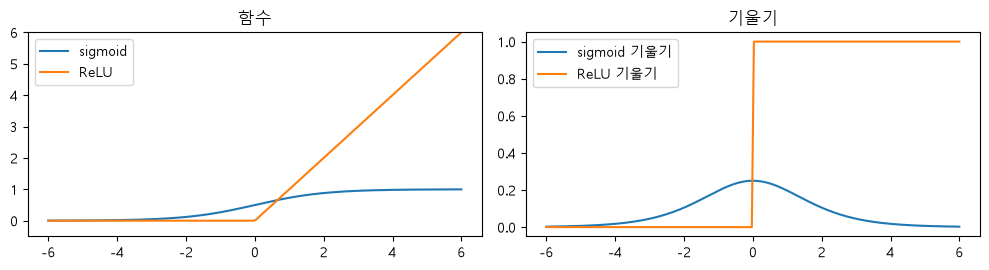

sigmoid 기울기 최댓값 0.25 · ReLU 양수 쪽 1
기울기를 10번 곱하면 — sigmoid 가장 좋은 경우 9.5e-07 · ReLU 1
입력 (1, 3, 224, 224)
  Conv2d    필터 11×11 · 보폭 4 → (1, 64, 55, 55)
  MaxPool2d 필터 3×3 · 보폭 2 → (1, 64, 27, 27)
  Conv2d    필터 5×5 · 보폭 1 → (1, 192, 27, 27)
  MaxPool2d 필터 3×3 · 보폭 2 → (1, 192, 13, 13)
  Conv2d    필터 3×3 · 보폭 1 → (1, 384, 13, 13)
  Conv2d    필터 3×3 · 보폭 1 → (1, 256, 13, 13)
  Conv2d    필터 3×3 · 보폭 1 → (1, 256, 13, 13)
  MaxPool2d 필터 3×3 · 보폭 2 → (1, 256, 6, 6)
끝 (256, 6, 6) → 펼치면 256×6×6 = 9,216개 값
  Linear(9,216→4,096) — 37,752,832개
  Linear(4,096→4,096) — 16,781,312개
  Linear(4,096→1,000) — 4,097,000개
AlexNet 합성곱 부분 2,469,696개 · 전체 61,100,840개
  1번째 묶음 — 3×3 2번 + 줄이기 → (1, 64, 112, 112) · 38,720개
  2번째 묶음 — 3×3 2번 + 줄이기 → (1, 128, 56, 56) · 221,440개
  3번째 묶음 — 3×3 3번 + 줄이기 → (1, 256, 28, 28) · 1,475,328개


  4번째 묶음 — 3×3 3번 + 줄이기 → (1, 512, 14, 14) · 5,899,776개
  5번째 묶음 — 3×3 3번 + 줄이기 → (1, 512, 7, 7) · 7,079,424개
합성곱 부분 14,714,688개 · VGG16 전체 138,357,544개


In [94]:
# ---------- 10-2 ----------
# 왜 · sigmoid와 ReLU의 기울기 차이를 곡선으로 비교하기 위해
z = torch.linspace(-6, 6, 200)                                      # 들어가는 값
sig = torch.sigmoid(z)                                              # sigmoid
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))                     # 왼쪽 함수 · 오른쪽 기울기
ax[0].plot(z, sig, label="sigmoid")                                 # 0~1로 누름
ax[0].plot(z, torch.relu(z), label="ReLU")                          # 음수 0 · 양수 그대로
ax[0].set_ylim(-0.5, 6)                                             # 세로 범위
ax[0].set_title("함수")                                             # 제목
ax[0].legend()                                                      # 범례
ax[1].plot(z, sig * (1 - sig), label="sigmoid 기울기")              # 최대 0.25
ax[1].plot(z, (z > 0).float(), label="ReLU 기울기")                 # 양수 쪽 1
ax[1].set_title("기울기")                                           # 제목
ax[1].legend()                                                      # 범례
fig.tight_layout()                                                  # 정리
plt.show()                                                          # 그리기
print(f"sigmoid 기울기 최댓값 {(sig * (1 - sig)).max():.2f} · ReLU 양수 쪽 1")  # 비교
print(f"기울기를 10번 곱하면 — sigmoid 가장 좋은 경우 {0.25 ** 10:.1e} · ReLU 1")  # 층마다 곱해짐
alex = nets["AlexNet (2012)"]                                       # AlexNet
with torch.no_grad():                                               # 모양만
    t = torch.zeros(1, 3, 224, 224)                                 # 224 × 224 빈 사진
    print(f"입력 {tuple(t.shape)}")                                 # 시작
    for layer in alex.features:                                     # 층마다
        t = layer(t)                                                # 통과
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):            # 합성곱 · 풀링만 찍음
            # 필터 크기 숫자 하나
            k_ = layer.kernel_size if isinstance(layer.kernel_size, int) else layer.kernel_size[0]
            # 보폭 숫자 하나
            s_ = layer.stride if isinstance(layer.stride, int) else layer.stride[0]
            print(f"  {type(layer).__name__:9s} 필터 {k_}×{k_} · "  # 층 · 필터 · 보폭 · 모양
                  f"보폭 {s_} → {tuple(t.shape)}")
print(f"끝 (256, 6, 6) → 펼치면 256×6×6 = {256 * 6 * 6:,}개 값")    # Linear 입력
for m in alex.classifier:                                           # Linear 층마다
    if isinstance(m, nn.Linear):                                    # 학습할 숫자가 몰린 곳
        print(f"  Linear({m.in_features:,}→{m.out_features:,}) — {n_params(m):,}개")  # Linear 숫자
print(f"AlexNet 합성곱 부분 {n_params(alex.features):,}개 · 전체 {n_params(alex):,}개")  # 비율


# ---------- 10-3 ----------
# 왜 · VGG의 반복 구조를 함수 하나로 만들기 위해
def vgg_block(c_in, c_out, n_conv):                 # 3×3 합성곱 + ReLU를 n번, 끝에 MaxPool
    layers = []                                     # 층 목록
    for i in range(n_conv):                         # n번 반복
        # 3×3 + ReLU
        layers += [nn.Conv2d(c_in if i == 0 else c_out, c_out, 3, padding=1), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2))  # 가로세로 절반


cfg = [(3, 64, 2), (64, 128, 2), (128, 256, 3), (256, 512, 3), (512, 512, 3)]  # VGG16 묶음 다섯
total = 0                                                                      # 합성곱 부분 합계
with torch.no_grad():                                                          # 모양만
    t = torch.zeros(1, 3, 224, 224)                                            # 빈 사진
    for k, (ci_, co_, n_) in enumerate(cfg, 1):                                # 묶음마다
        blk = vgg_block(ci_, co_, n_)                                          # 묶음 만들기
        t = blk(t)                                                             # 통과
        total += n_params(blk)                                                 # 숫자 합
        print(f"  {k}번째 묶음 — 3×3 {n_}번 + 줄이기 → {tuple(t.shape)} · "    # 모양 · 숫자
              f"{n_params(blk):,}개")
print(f"합성곱 부분 {total:,}개 · "                                            # 나머지는 Linear
      f"VGG16 전체 {n_params(nets['VGG16 (2014)']):,}개")

**실행 흐름**

1. 10-4 인셉션 블록 · 보는 범위

In [95]:
# 왜 · 여러 크기의 필터를 나란히 쓰는 인셉션 블록을 직접 만들어 보기 위해
class MiniInception(nn.Module):           # GoogLeNet 첫 인셉션 블록(3a) 모양
    def __init__(self, c_in):             # 네 갈래
        super().__init__()                # 준비
        self.b1 = nn.Conv2d(c_in, 64, 1)  # 1×1
        # 1×1로 줄인 뒤 3×3
        self.b2 = nn.Sequential(nn.Conv2d(c_in, 96, 1), nn.ReLU(), nn.Conv2d(96, 128, 3, padding=1))
        # 1×1로 줄인 뒤 5×5
        self.b3 = nn.Sequential(nn.Conv2d(c_in, 16, 1), nn.ReLU(), nn.Conv2d(16, 32, 5, padding=2))
        # 풀링 → 1×1
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), nn.Conv2d(c_in, 32, 1))

    def forward(self, x):                    # 나란히 계산 → 채널 방향으로 이어 붙임
        outs = [self.b1(x), self.b2(x), self.b3(x), self.b4(x)]  # 네 결과
        return torch.cat(outs, dim=1), outs  # 가로세로가 같아야 붙음


blk = MiniInception(192)                                                     # 입력 채널 192
with torch.no_grad():                                                        # 모양만
    y_, parts = blk(torch.zeros(1, 192, 28, 28))                             # (1, 192, 28, 28)
for name, o in zip(["1×1", "1×1 → 3×3", "1×1 → 5×5", "풀링 → 1×1"], parts):  # 갈래마다
    print(f"  갈래 {name:10s} → {tuple(o.shape)}")                           # 가로세로 그대로
print(f"이어 붙인 결과 {tuple(y_.shape)} — 채널 64 + 128 + 32 + 32")         # 256
direct = nn.Conv2d(192, 32, 5, padding=2)                                    # 줄이지 않고 바로 5×5
print(f"5×5 갈래 숫자 — 1×1로 먼저 줄이면 {n_params(blk.b3):,}개 · "         # 줄이기 효과
      f"바로 5×5면 {n_params(direct):,}개")


# ---------- 10-4 ----------
# 왜 · 층을 지날 때마다 한 칸이 보는 범위가 얼마나 넓어지는지 계산하기 위해
rf, jump = 1, 1  # 보는 범위 · 옆 칸 간격 (원래 사진 기준)
for i, layer in enumerate(model.features):                               # 층 설정만으로 계산
    if isinstance(layer, nn.Conv2d):                                     # 3×3 합성곱
        rf += (layer.kernel_size[0] - 1) * jump                          # (3 - 1) × jump만큼 넓어짐
        print(f"  features[{i:2d}] 3×3 합성곱 뒤 — 보는 범위 {rf}×{rf}")  # 결과
    elif isinstance(layer, nn.MaxPool2d):                                # 줄이기
        rf += (layer.kernel_size - 1) * jump                             # 2칸 창도 넓힘
        jump *= layer.stride                                             # 옆 칸 간격 두 배
        print(f"  features[{i:2d}] MaxPool 뒤 — 보는 범위 {rf}×{rf} · "  # 범위 · 간격
              f"옆 칸 = 원래 {jump}칸")
c = 64                                                                   # 채널
one_7 = nn.Conv2d(c, c, 7, padding=3, bias=False)                        # 7×7 한 층
three_3 = nn.Sequential(*[nn.Conv2d(c, c, 3, padding=1, bias=False) for _ in range(3)])  # 3×3 세 층
print(f"7×7 한 층 {n_params(one_7):,} · "                                # 같은 범위 · 다른 숫자
      f"3×3 세 층 {n_params(three_3):,} · 둘 다 보는 범위 7×7")
one_1 = nn.Conv2d(256, 64, 1, bias=False)                                # 1×1 합성곱
print(f"1×1 256→64 가중치 {n_params(one_1):,} · "                        # 채널만 줄임
      f"모양 {tuple(one_1(torch.zeros(1, 256, 16, 16)).shape)}")
HW = 28 * 28                                                             # 자리 수
m_direct = 192 * 32 * 25 * HW                                            # 바로 5×5: 가중치 × 자리
m_red = (192 * 16 + 16 * 32 * 25) * HW                                   # 1×1로 줄인 뒤 5×5
print(f"곱셈 수 — 바로 5×5 {m_direct:,}번 · 1×1 뒤 5×5 {m_red:,}번 · "   # 계산량 비교
      f"약 {m_direct / m_red:.0f}분의 1")

  갈래 1×1        → (1, 64, 28, 28)
  갈래 1×1 → 3×3  → (1, 128, 28, 28)
  갈래 1×1 → 5×5  → (1, 32, 28, 28)
  갈래 풀링 → 1×1   → (1, 32, 28, 28)
이어 붙인 결과 (1, 256, 28, 28) — 채널 64 + 128 + 32 + 32
5×5 갈래 숫자 — 1×1로 먼저 줄이면 15,920개 · 바로 5×5면 153,632개
  features[ 0] 3×3 합성곱 뒤 — 보는 범위 3×3
  features[ 3] 3×3 합성곱 뒤 — 보는 범위 5×5
  features[ 6] MaxPool 뒤 — 보는 범위 6×6 · 옆 칸 = 원래 2칸
  features[ 7] 3×3 합성곱 뒤 — 보는 범위 10×10
  features[10] 3×3 합성곱 뒤 — 보는 범위 14×14
  features[13] MaxPool 뒤 — 보는 범위 16×16 · 옆 칸 = 원래 4칸
  features[14] 3×3 합성곱 뒤 — 보는 범위 24×24
  features[17] 3×3 합성곱 뒤 — 보는 범위 32×32
  features[20] MaxPool 뒤 — 보는 범위 36×36 · 옆 칸 = 원래 8칸
7×7 한 층 200,704 · 3×3 세 층 110,592 · 둘 다 보는 범위 7×7
1×1 256→64 가중치 16,384 · 모양 (1, 64, 16, 16)
곱셈 수 — 바로 5×5 120,422,400번 · 1×1 뒤 5×5 12,443,648번 · 약 10분의 1


**실행 흐름**

1. 10-5 깊이와 기울기

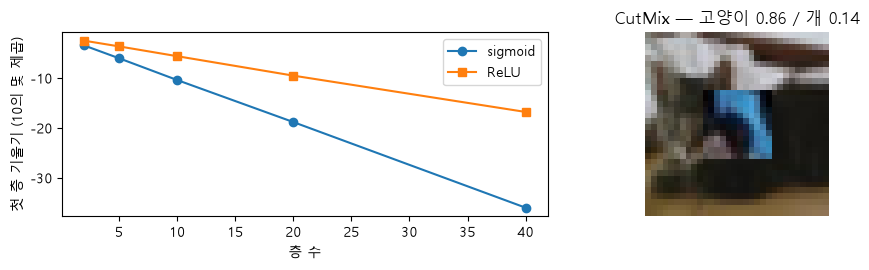

층 2개 — sigmoid 3.4e-04 · ReLU 3.1e-03 / 층 40개 — sigmoid 1.0e-36 · ReLU 1.6e-17
섞은 사진의 정답 비율 — 고양이 0.86 · 개 0.14 / 모델의 답 — 말 0.95 · 트럭 0.02


In [96]:
# ---------- 10-5 ----------
# 왜 · 깊이와 활성화 함수에 따라 첫 층 기울기가 얼마나 줄어드는지 재기 위해
def first_grad(depth, act):  # 층 depth개 · 한 번 backward 뒤 첫 층 기울기 크기
    torch.manual_seed(0)                             # 같은 시작값
    layers = []                                      # 층 목록
    for _ in range(depth):                           # 층 수만큼
        layers += [nn.Linear(64, 64), act()]         # Linear + 활성화
    net = nn.Sequential(*layers, nn.Linear(64, 10))  # 끝에 점수 10개
    loss = F.cross_entropy(net(torch.randn(32, 64)), torch.randint(0, 10, (32,)))  # 무작위 입력
    loss.backward()                                  # 기울기 (학습은 안 함)
    return net[0].weight.grad.abs().mean().item()    # 첫 층 신호 크기


# 왜 · 깊이를 늘려 가며 기울기 소실을 숫자로 비교하기 위해
depths = [2, 5, 10, 20, 40]                                           # 층 수
g_sig = [first_grad(d, nn.Sigmoid) for d in depths]                   # sigmoid
g_relu = [first_grad(d, nn.ReLU) for d in depths]                     # ReLU
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))                       # 왼쪽 기울기 · 오른쪽 CutMix
ax[0].plot(depths, np.log10(g_sig), "o-", label="sigmoid")            # 빠르게 작아짐
ax[0].plot(depths, np.log10(g_relu), "s-", label="ReLU")              # 천천히
ax[0].set_xlabel("층 수")                                             # 가로축
ax[0].set_ylabel("첫 층 기울기 (10의 몇 제곱)")                       # -10이면 100억분의 1
ax[0].legend()                                                        # 범례
a = int((y_train == CLASSES.index("cat")).nonzero()[0])               # 고양이 한 장
b = int((y_train == CLASSES.index("dog")).nonzero()[0])               # 개 한 장
mixed = x_train[a].clone()                                            # 고양이 복사
mixed[:, 10:22, 10:22] = x_train[b][:, 10:22, 10:22]                  # 12칸 네모를 개 조각으로
share = 12 * 12 / (32 * 32)                                           # 개 조각 넓이 비율
# 섞은 사진
ax[1].imshow((mixed.float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[1].set_title(f"CutMix — 고양이 {1 - share:.2f} / 개 {share:.2f}")  # 정답도 섞음
ax[1].axis("off")                                                     # 눈금 끄기
fig.tight_layout()                                                    # 정리
plt.show()                                                            # 그리기
print(f"층 2개 — sigmoid {g_sig[0]:.1e} · ReLU {g_relu[0]:.1e}"       # 얕을 때 · 깊을 때
      f" / 층 40개 — sigmoid {g_sig[-1]:.1e} · ReLU {g_relu[-1]:.1e}")
pm = predict(model, mixed[None])[0]                                   # 섞은 사진에 낸 답
t2 = pm.argsort(descending=True)[:2]                                  # 가장 큰 두 확률
print(f"섞은 사진의 정답 비율 — 고양이 {1 - share:.2f} · 개 {share:.2f}"  # 정답 비율 · 모델의 답
      f" / 모델의 답 — {KO[CLASSES[t2[0]]]} {pm[t2[0]]:.2f} · {KO[CLASSES[t2[1]]]} {pm[t2[1]]:.2f}")

**실행 흐름**

1. 11-1 깊이 · residual 학습 비교

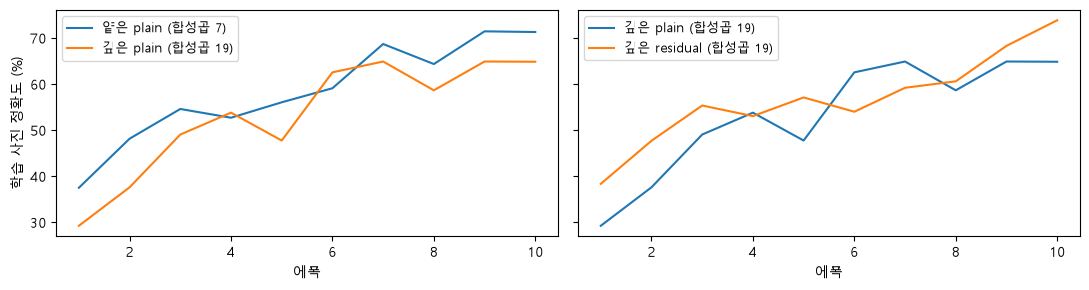

얕은 plain (합성곱 7) — 마지막 학습 71.3% · 검증 63.0%
깊은 plain (합성곱 19) — 마지막 학습 64.9% · 검증 58.3%
깊은 residual (합성곱 19) — 마지막 학습 73.9% · 검증 64.3%


In [97]:
from torchvision.models import ResNet18_Weights, resnet18  # 빌려 올 ResNet18


# ---------- 11-1 ----------
# 왜 · 같은 깊이에서 지름길 유무만 다른 모델을 만들어 공정하게 비교하기 위해
class DepthNet(nn.Module):  # 3×3 합성곱 두 층짜리 묶음을 n개 쌓은 망 (지름길은 선택)
    def __init__(self, n_blocks, residual):                      # 묶음 수 · 지름길 여부
        super().__init__()                                       # 준비
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False),  # 첫 합성곱
                                  nn.BatchNorm2d(32), nn.ReLU())
        self.blocks = nn.ModuleList([nn.Sequential(              # 두 층짜리 묶음 n개
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32))
            for _ in range(n_blocks)])
        self.pools = {n_blocks // 3 - 1, 2 * n_blocks // 3 - 1}  # 1/3 · 2/3 지점에서 줄이기
        self.residual = residual                                 # 지름길 여부
        # 평균 → 점수
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32, 10))

    def forward(self, x):                                            # 묶음을 차례로 통과
        x = self.stem(x)                                             # 첫 합성곱
        for k, b in enumerate(self.blocks):                          # 묶음마다
            x = F.relu(b(x) + x) if self.residual else F.relu(b(x))  # 지름길이면 x를 더함
            if k in self.pools:                                      # 줄이는 자리
                x = F.max_pool2d(x, 2)                               # 가로세로 절반
        return self.head(x)                                          # 점수


# 왜 · 깊이 · residual만 바꾸고 나머지는 같은 조건으로 학습하기 위해
def depth_run(n_blocks, residual, epochs=10):  # 같은 조건으로 학습 → 에폭별 학습 · 검증 정확도
    torch.manual_seed(0)                                                 # 시작값 하나
    m = DepthNet(n_blocks, residual).to(DEV)                             # 새 모델
    o = torch.optim.Adam(m.parameters(), lr=1e-3)                        # 같은 학습률
    rows = []                                                            # 기록
    for e in range(1, epochs + 1):                                       # 에폭
        train_one_epoch(m, o, x_train[:10000], y_train[:10000], seed=e)  # 1만 장
        tra = evaluate(m, x_train[:2000], y_train[:2000])[1] * 100       # 평가 모드로 다시 잰 학습
        rows.append((tra, evaluate(m, x_val, y_val)[1] * 100))           # 검증
    return rows                                                          # [(학습, 검증), ...]


# 왜 · 깊이 · residual 조합별 결과를 한 표에 모으기 위해
D = {}                                                        # 세 모델 기록 (GPU 약 2분)
D["얕은 plain (합성곱 7)"] = depth_run(3, False)              # 기준
D["깊은 plain (합성곱 19)"] = depth_run(9, False)             # 깊이만 바꿈
D["깊은 residual (합성곱 19)"] = depth_run(9, True)           # 지름길만 더함
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)  # 왼쪽 깊이 · 오른쪽 지름길
for a, keys in zip(ax, (list(D)[:2], list(D)[1:])):           # 두 비교
    for k in keys:                                            # 모델마다
        a.plot(range(1, 11), [r[0] for r in D[k]], label=k)   # 학습 정확도
    a.set_xlabel("에폭")                                      # 가로축
    a.legend(fontsize=9)                                      # 범례
ax[0].set_ylabel("학습 사진 정확도 (%)")                      # 세로축
fig.tight_layout()                                            # 정리
plt.show()                                                    # 그리기
for k, rows in D.items():                                     # 숫자로
    print(f"{k} — 마지막 학습 {rows[-1][0]:.1f}% · 검증 {rows[-1][1]:.1f}%")  # 학습 · 검증

**실행 흐름**

1. 11-2 BN · residual block

In [98]:
# ---------- 11-2 ----------

# 왜 · 미리 학습된 가중치와 그 입력 약속(평균 · 표준편차)을 함께 가져오기 위해
W = ResNet18_Weights.IMAGENET1K_V1  # ImageNet으로 미리 학습한 숫자 (13장)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)  # 그 모델의 약속
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)   # 채널별 표준편차


# 왜 · 빌려 온 모델이 배운 것과 같은 크기 · 정규화로 사진을 맞추기 위해
def norm(x):  # 빌려 온 모델의 입력 약속: 224로 키움 · 0~1 · 평균 빼고 표준편차로 나눔
    x = F.interpolate(x.float(), size=224, mode="bilinear", align_corners=False)  # 32 → 224
    return (x / 255 - MEAN) / STD                                                 # 채널마다


net = resnet18(weights=W).to(DEV).eval()  # pretrained ResNet18
with torch.no_grad():                     # 첫 stage 앞까지만 통과 → 블록에 들어갈 특징 지도
    # stem 통과 = (1, 64, 56, 56)
    x = net.maxpool(net.relu(net.bn1(net.conv1(norm(x_val[LOOK:LOOK + 1])))))
print(f"말 사진 → 첫 stage 입력 x {tuple(x.shape)} · 가장 작은 값 {x.min().item():.1f}")  # 0 이상
bn = nn.BatchNorm2d(64).train()           # BN (학습 모드 = 묶음 평균)
t = torch.randn(8, 64, 56, 56) * 5 + 3    # 평균 3 · 표준편차 5로 흩어진 값
o = bn(t)                                 # 채널마다 고르게
print(f"BN 전 채널 평균 {t.mean((0, 2, 3)).mean():.2f} · "  # 흩어진 값
      f"표준편차 {t.std((0, 2, 3)).mean():.2f}")
# 평균 0 · 표준편차 1
print(f"BN 뒤 채널 평균 {o.mean((0, 2, 3)).mean():.2f} · 표준편차 {o.std((0, 2, 3)).mean():.2f}"
      f" · 모양 {tuple(o.shape)} 그대로")


# 왜 · ResNet의 핵심 블록을 직접 만들어 F(x) + x의 뜻을 확인하기 위해
class ResidualBlock(nn.Module):                                 # 출력 = ReLU(F(x) + x)
    def __init__(self, c):                                      # 채널 수 (들어오고 나가는 수 같음)
        super().__init__()                                      # 준비
        self.conv1 = nn.Conv2d(c, c, 3, padding=1, bias=False)  # 편향은 BN이 지움
        self.bn1 = nn.BatchNorm2d(c)                            # 값 고르게
        self.conv2 = nn.Conv2d(c, c, 3, padding=1, bias=False)  # 둘째 합성곱
        self.bn2 = nn.BatchNorm2d(c)                            # 값 고르게

    def forward(self, x):                                          # F(x)를 계산하고 x를 더함
        f = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))  # F(x)
        return F.relu(f + x)                                       # 지름길로 온 x를 더함


# 왜 · 지름길만 뺀 블록과 비교해 residual의 효과를 보기 위해
class PlainBlock(ResidualBlock):  # 같은 두 층 · 지름길 없음
    def forward(self, x):         # 출력 = ReLU(F(x))
        return F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x))))))  # x를 안 더함


block, plain = ResidualBlock(64).to(DEV).eval(), PlainBlock(64).to(DEV).eval()    # 두 블록
print(f"residual block 출력 {tuple(block(x).shape)} · "                           # 모양 그대로
      f"학습할 숫자 {n_params(block):,}개")
with torch.no_grad():  # 마지막 BN을 0으로 → F(x) = 0
    for b in (block, plain):                                                      # 두 블록 모두
        b.bn2.weight.zero_()                                                      # 배율 0
        b.bn2.bias.zero_()                                                        # 이동 0
print("residual block — 출력이 입력 x와 똑같은가:", torch.allclose(block(x), x))  # ReLU(0 + x) = x
print("지름길 없는 두 층 — 출력이 전부 0인가:", bool((plain(x) == 0).all()))      # ReLU(0) = 0

말 사진 → 첫 stage 입력 x (1, 64, 56, 56) · 가장 작은 값 0.0
BN 전 채널 평균 3.00 · 표준편차 5.00
BN 뒤 채널 평균 -0.00 · 표준편차 1.00 · 모양 (8, 64, 56, 56) 그대로
residual block 출력 (1, 64, 56, 56) · 학습할 숫자 73,984개
residual block — 출력이 입력 x와 똑같은가: True
지름길 없는 두 층 — 출력이 전부 0인가: True


**실행 흐름**

1. 11-3 실제 블록과 비교 · 모양이 바뀌는 블록

In [99]:
# ---------- 11-3 ----------
# 왜 · 직접 만든 블록이 실제 ResNet18 블록과 같은 계산인지 숫자로 검증하기 위해
real = net.layer1[0]                     # ResNet18 첫 stage의 첫 블록
mine = ResidualBlock(64).to(DEV).eval()  # 우리가 만든 블록
print(f"학습할 숫자 — 우리 블록 {n_params(mine):,}개 · "  # 같은 숫자 개수
      f"ResNet18 layer1[0] {n_params(real):,}개")
mine.load_state_dict(real.state_dict())  # 실제 블록의 숫자를 그대로 채움 (이름표 · 모양 같음)
with torch.no_grad():                    # 같은 입력
    # 같은 출력
    print("같은 입력에 두 블록 출력이 똑같은가:", torch.allclose(mine(x), real(x), atol=1e-5))
bad = ResidualBlock(64).to(DEV)          # 가로세로 절반 · 채널 두 배로 바꾼 블록
bad.conv1 = nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False).to(DEV)  # F(x) 쪽만 바뀜
bad.bn1 = nn.BatchNorm2d(128).to(DEV)    # 128채널
bad.conv2 = nn.Conv2d(128, 128, 3, padding=1, bias=False).to(DEV)  # 128 → 128
bad.bn2 = nn.BatchNorm2d(128).to(DEV)    # 128채널
try:                                     # 더하기 시도
    bad(x)                               # F(x) (1, 128, 28, 28) + x (1, 64, 56, 56)
except RuntimeError as e:                # 모양이 달라 실패
    print("더하기 실패 —", str(e).split("\n")[0])  # 어느 차원이 다른지


# 왜 · 모양이 바뀌는 블록에서는 지름길도 모양을 맞춰야 한다는 것을 확인하기 위해
class DownBlock(nn.Module):               # 가로세로 절반 · 채널 두 배 · 지름길도 모양을 맞춤
    def __init__(self, c_in, c_out):      # 들어오는 · 나가는 채널
        super().__init__()                # 준비
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=2, padding=1, bias=False)  # 절반 · 두 배
        self.bn1 = nn.BatchNorm2d(c_out)  # 값 고르게
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)  # 크기 유지
        self.bn2 = nn.BatchNorm2d(c_out)  # 값 고르게
        # 지름길 1×1 stride 2 + BN
        self.short = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=2, bias=False),
                                   nn.BatchNorm2d(c_out))

    def forward(self, x):                                          # F(x) + 모양 맞춘 x
        f = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))  # F(x)
        return F.relu(f + self.short(x))                           # 지름길도 (128, 28, 28)


down = DownBlock(64, 128).to(DEV).eval()                                              # 64 → 128
print(f"모양을 맞춘 블록 출력 {tuple(down(x).shape)}")                                # 성공
print(f"지름길 쪽 숫자 {n_params(down.short):,}개 · 블록 전체 {n_params(down):,}개")  # 1×1 + BN
print("실제 ResNet18 layer2[0].downsample:", net.layer2[0].downsample)                # 같은 구성

학습할 숫자 — 우리 블록 73,984개 · ResNet18 layer1[0] 73,984개
같은 입력에 두 블록 출력이 똑같은가: True
더하기 실패 — The size of tensor a (28) must match the size of tensor b (56) at non-singleton dimension 3
모양을 맞춘 블록 출력 (1, 128, 28, 28)
지름길 쪽 숫자 8,448개 · 블록 전체 230,144개
실제 ResNet18 layer2[0].downsample: Sequential(
  (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
  (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


**실행 흐름**

1. 11-4 ResNet18 전체 읽기

In [100]:
# ---------- 11-4 ----------
for name, m in net.named_children():                                            # 맨 위 이름표
    # stage면 안쪽 블록 수
    # 왜 · ResNet18의 큰 덩어리와 안쪽 블록 수를 차례로 읽기 위해
    inner = f" · 안에 {type(m[0]).__name__} {len(m)}개" if name.startswith("layer") else ""
    print(f"{name:8s} {type(m).__name__}{inner}")                               # stem · stage · 끝
x_ = norm(x_val[LOOK:LOOK + 1])  # 사진 한 장 (1, 3, 224, 224)
print(f"{'입력':8s} {tuple(x_.shape)}")                                         # 시작
with torch.no_grad():                                                           # 큰 층마다 모양
    for name, m in net.named_children():                                        # 층 차례로
        if name == "fc":                                                        # fc 앞에서 한 줄로
            x_ = torch.flatten(x_, 1)                                           # (1, 512)
        x_ = m(x_)                                                              # 통과
        print(f"{name:8s} {str(tuple(x_.shape)):18s} 학습할 숫자 {n_params(m):,}")  # 모양 · 숫자
# 합성곱 모으기
convs = [m for n, m in net.named_modules() if isinstance(m, nn.Conv2d) and "downsample" not in n]
print(f"합성곱(downsample 제외) {len(convs)}개 + fc 1개 = {len(convs) + 1}")    # 18의 뜻
total = n_params(net)                                                           # 전체
parts = {"stem": ["conv1", "bn1"], "layer1": ["layer1"], "layer2": ["layer2"],  # 부분별 이름
         "layer3": ["layer3"], "layer4": ["layer4"], "fc": ["fc"]}
for k, names in parts.items():                                                  # 부분별
    n = sum(n_params(getattr(net, nm)) for nm in names)                         # 그 부분의 숫자
    print(f"{k:7s} {n:>10,}  {n / total * 100:5.1f}%")                          # 비율
print(f"전체 {total:,}")                                                        # 합

conv1    Conv2d
bn1      BatchNorm2d
relu     ReLU
maxpool  MaxPool2d
layer1   Sequential · 안에 BasicBlock 2개
layer2   Sequential · 안에 BasicBlock 2개
layer3   Sequential · 안에 BasicBlock 2개
layer4   Sequential · 안에 BasicBlock 2개
avgpool  AdaptiveAvgPool2d
fc       Linear
입력       (1, 3, 224, 224)
conv1    (1, 64, 112, 112)  학습할 숫자 9,408
bn1      (1, 64, 112, 112)  학습할 숫자 128
relu     (1, 64, 112, 112)  학습할 숫자 0
maxpool  (1, 64, 56, 56)    학습할 숫자 0
layer1   (1, 64, 56, 56)    학습할 숫자 147,968
layer2   (1, 128, 28, 28)   학습할 숫자 525,568
layer3   (1, 256, 14, 14)   학습할 숫자 2,099,712
layer4   (1, 512, 7, 7)     학습할 숫자 8,393,728
avgpool  (1, 512, 1, 1)     학습할 숫자 0
fc       (1, 1000)          학습할 숫자 513,000
합성곱(downsample 제외) 17개 + fc 1개 = 18
stem         9,536    0.1%
layer1     147,968    1.3%
layer2     525,568    4.5%
layer3   2,099,712   18.0%
layer4   8,393,728   71.8%
fc         513,000    4.4%
전체 11,689,512


**실행 흐름**

1. 12-1 구조별 비용 재기

모델                    학습할 숫자    입력    너비    깊이
EfficientNet-B0    5,288,548   224   1.0   1.0


EfficientNet-B1    7,794,184   240   1.0   1.1


EfficientNet-B2    9,109,994   288   1.1   1.2


EfficientNet-B3   12,233,232   300   1.2   1.4


ResNet18         학습할 숫자 11,689,512개 · 파일 46.8MB · 입력 224
EfficientNet-B0  학습할 숫자 5,288,548개 · 파일 21.4MB · 입력 224


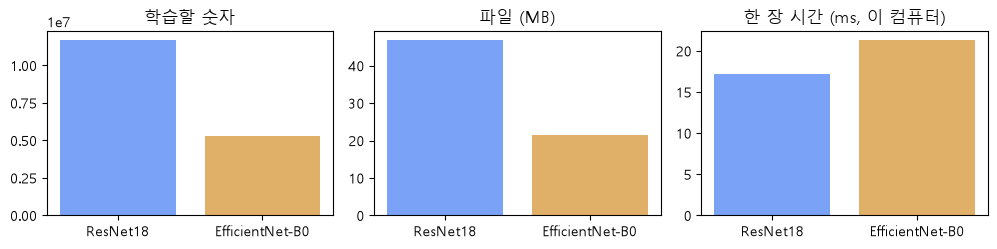

In [101]:
# 왜 · 모델 크기를 파일로 저장하지 않고 메모리에서 재기 위해
import io  # 파일 크기를 메모리에서 잼
import time                                                                      # 시간 재기
from torchvision.models import EfficientNet_B0_Weights, EfficientNet_B1_Weights  # 입력 크기 정보
from torchvision.models import EfficientNet_B2_Weights, EfficientNet_B3_Weights  # B2 · B3 정보
from torchvision.models import efficientnet_b0, efficientnet_b1                  # 모양 만들기
from torchvision.models import efficientnet_b2, efficientnet_b3                  # 모양 만들기


# ---------- 12-1 ----------


# (이름, 만들기, 가중치, 너비 배율, 깊이 배율) · 배율은 torchvision 설정값
EFF = [("B0", efficientnet_b0, EfficientNet_B0_Weights, 1.0, 1.0),  # 기준 모델
       ("B1", efficientnet_b1, EfficientNet_B1_Weights, 1.0, 1.1),
       ("B2", efficientnet_b2, EfficientNet_B2_Weights, 1.1, 1.2),
       ("B3", efficientnet_b3, EfficientNet_B3_Weights, 1.2, 1.4)]
print(f"{'모델':16s} {'학습할 숫자':>11s} {'입력':>5s} {'너비':>5s} {'깊이':>5s}")  # 표 머리줄
for name, make, wts, wm, dm in EFF:                     # 모양만 만들어 셈 (가중치 받지 않음)
    crop = wts.IMAGENET1K_V1.transforms().crop_size[0]  # 그 가중치의 기본 입력 크기
    # 숫자 · 입력 · 배율
    print(f"EfficientNet-{name:3s} {n_params(make(weights=None)):>11,} {crop:>5} {wm:>5} {dm:>5}")


# 왜 · 정확도 말고도 구조를 고를 때 보는 비용(가중치 · 크기 · 시간)을 같은 방법으로 재기 위해
def cost(make, size=224):  # 학습할 숫자 · 파일 크기(MB) · 한 장 시간(ms, CPU · 10번 중 가운데)
    m = make(weights=None).eval()                                        # 모양만
    buf = io.BytesIO()                                                   # 메모리 파일
    torch.save(m.state_dict(), buf)                                      # 저장해 보기
    x = torch.randn(1, 3, size, size)                                    # 사진 한 장
    with torch.no_grad():                                                # 추론만
        for _ in range(3):                                               # 몸풀기
            m(x)                                                         # 첫 실행은 느림
        ts = []                                                          # 시간 기록
        for _ in range(10):                                              # 10번
            t0 = time.perf_counter()                                     # 시작
            m(x)                                                         # 한 장
            ts.append(time.perf_counter() - t0)                          # 걸린 시간
    return n_params(m), len(buf.getvalue()) / 1e6, sorted(ts)[5] * 1000  # 가운데 값


C = {"ResNet18": cost(resnet18), "EfficientNet-B0": cost(efficientnet_b0)}    # 두 모델 비용
for name, (n, mb, _) in C.items():  # 숫자 · 파일 (실행마다 같음)
    print(f"{name:16s} 학습할 숫자 {n:,}개 · 파일 {mb:.1f}MB · 입력 224")     # 비교
fig, ax = plt.subplots(1, 3, figsize=(10, 2.6))                               # 숫자 · 파일 · 시간
# 그림 세 칸
for a, j, title in zip(ax, range(3), ["학습할 숫자", "파일 (MB)", "한 장 시간 (ms, 이 컴퓨터)"]):
    a.bar(list(C), [v[j] for v in C.values()], color=["#7aa2f7", "#e0af68"])  # 두 막대
    a.set_title(title)                                                        # 제목
fig.tight_layout()                                                            # 정리
plt.show()  # 시간은 실행마다 달라지므로 그림으로만

**실행 흐름**

1. 13-1 빌려 온 특징 · 가까운 사진
2. 13-2 head 바꾸기

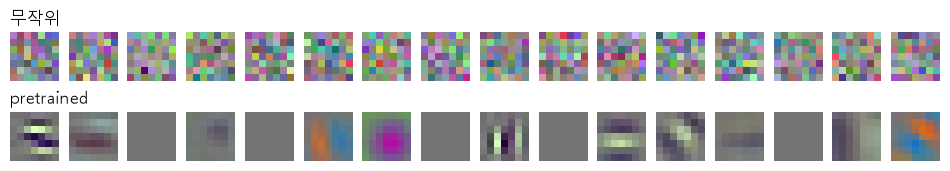

첫 층 필터 모양 (64, 3, 7, 7)
가장 가까운 사진이 같은 종류인 비율 — 무작위 23.9% · pretrained 66.1%
바꾸기 전 점수 모양 (1, 1000) · fc Linear(in_features=512, out_features=1000, bias=True)
바꾼 뒤 점수 모양 (1, 10) · fc Linear(in_features=512, out_features=10, bias=True)
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [102]:
# ---------- 13-1 ----------
# 왜 · 종류마다 같은 장수를 골라 비교가 한쪽 종류에 치우치지 않게 하기 위해
def take(x, y, per):       # 종류마다 per장씩 (종류 구성을 고르게)
    idx = torch.cat([(y == c).nonzero().flatten()[:per] for c in range(10)])  # 번호 모음
    return x[idx], y[idx]  # 사진 · 정답


xtr, ytr = take(x_train, y_train, 108)            # 학습 1,080장 (강의의 꽃 사진 수와 같게)
xva, yva = take(x_val, y_val, 36)                 # 검증 360장
xte, yte = take(x_test, y_test, 36)               # 테스트 360장
torch.manual_seed(0)                              # 무작위 가중치 고정
rand = resnet18(weights=None).to(DEV).eval()      # 무작위로 시작한 ResNet18
pre = net                                         # pretrained ResNet18 (11장에서 불러옴)
fig, ax = plt.subplots(2, 16, figsize=(12, 1.9))  # 위 무작위 · 아래 pretrained
for row, m in ((0, rand), (1, pre)):              # 두 모델
    f = m.conv1.weight[:16].detach().cpu()        # 첫 층 필터 16개 (7×7 × RGB)
    g = (f - f.min()) / (f.max() - f.min())       # 같은 방식으로 색 범위 맞춤
    for i in range(16):                           # 필터마다
        ax[row, i].imshow(g[i].permute(1, 2, 0))  # 작은 컬러 조각
        ax[row, i].axis("off")                    # 눈금 끄기
    ax[row, 0].set_title(["무작위", "pretrained"][row], loc="left")  # 줄 이름
plt.show()                                        # 그리기


# 왜 · 모델이 사진을 어떤 숫자로 바꾸는지 마지막 층 직전 특징을 꺼내기 위해
def features(m, x, bs=60):                          # fc 앞(avgpool 뒤)까지 통과시킨 512개 숫자
    out = []                                        # 묶음별 결과
    with torch.no_grad():                           # 계산만
        for i in range(0, len(x), bs):              # 묶음마다
            h = norm(x[i:i + bs])                   # 약속대로
            for name, layer in m.named_children():  # 층 차례로
                if name == "fc":                    # fc 앞에서 멈춤
                    break                           # 특징만
                h = layer(h)                        # 통과
            out.append(torch.flatten(h, 1))         # (묶음, 512)
    return F.normalize(torch.cat(out), dim=1)       # 길이 1로 → 내적 = 코사인 유사도


# 왜 · 가장 비슷한 사진이 같은 종류인 비율로 특징의 질을 재기 위해
def nearest_rate(f, y):   # 가장 비슷한 다른 사진이 같은 종류인 비율
    s = f @ f.T           # 모든 짝의 유사도
    s.fill_diagonal_(-1)  # 자기 자신은 빼고
    return (y[s.argmax(1)] == y).float().mean().item() * 100  # %


r_rand = nearest_rate(features(rand, xva), yva)                         # 무작위 특징
r_pre = nearest_rate(features(pre, xva), yva)                           # pretrained 특징
print(f"첫 층 필터 모양 {tuple(pre.conv1.weight.shape)}")               # (64, 3, 7, 7)
print(f"가장 가까운 사진이 같은 종류인 비율 — 무작위 {r_rand:.1f}% · "  # 무작위 vs pretrained
      f"pretrained {r_pre:.1f}%")


# ---------- 13-2 ----------
# 왜 · 빌려 온 모델의 head를 우리 문제에 맞게 바꾸기 전 원래 출력을 확인하기 위해
m_ = resnet18(weights=W).to(DEV).eval()                               # pretrained 그대로
x1 = norm(xva[:1])                                                    # 사진 한 장
with torch.no_grad():                                                 # 모양 확인
    print("바꾸기 전 점수 모양", tuple(m_(x1).shape), "· fc", m_.fc)  # 1000종
m_.fc = nn.Linear(512, 10).to(DEV)                                    # 우리 10종으로 (= 한 줄)
with torch.no_grad():                                                 # 다시 확인
    print("바꾼 뒤 점수 모양", tuple(m_(x1).shape), "· fc", m_.fc)    # 10종
print(W.transforms())  # 이 가중치가 학습 때 쓴 입력 약속

**실행 흐름**

1. 13-3 처음부터 vs 빌려 온 모델 학습

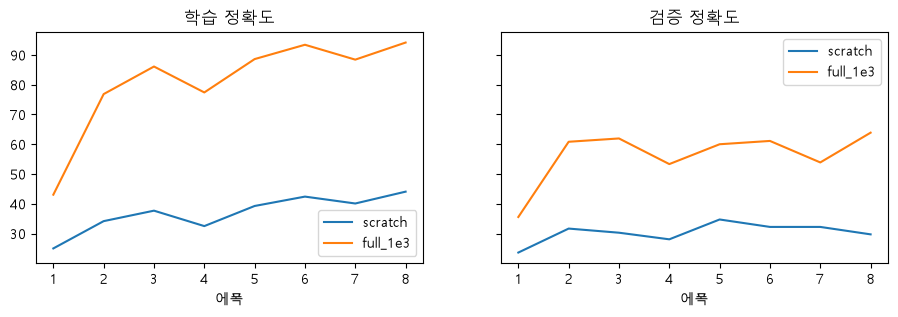

In [103]:
# 왜 · fc만 10종으로 바꾼 같은 구조에 저장한 숫자를 넣어 다시 쓰기 위해
def tl_model(state):            # 저장본 → ResNet18(10종)
    m = resnet18(weights=None)  # 같은 모양
    m.fc = nn.Linear(512, 10)   # 10종
    m.load_state_dict(state)    # 숫자 채우기
    return m.to(DEV).eval()     # 평가 모드


# ---------- 13-3 ----------
@torch.no_grad()
def eval_tl(m, x, y):                                         # 손실 · 정확도 · 확률
    m.eval()                                                  # 평가 모드
    p = torch.cat([m(norm(x[i:i + 60])).softmax(1) for i in range(0, len(x), 60)])  # 확률
    loss = F.nll_loss(p.clamp_min(1e-9).log(), y).item()      # 정답 확률의 -log 평균
    return loss, (p.argmax(1) == y).float().mean().item(), p  # 손실 · 정확도 · 확률


# 왜 · 처음부터 · 얼림 · 전부 학습을 같은 절차로 돌려 한 조건만 바꾼 비교를 하기 위해
def run_tl(mode, lr, epochs=8):  # mode: scratch(무작위 전부) · frozen(fc만) · full(전부)
    torch.manual_seed(0)                                          # 같은 시작값 · 같은 섞기
    m = resnet18(weights=None if mode == "scratch" else W)        # 시작 숫자만 다름
    m.fc = nn.Linear(512, 10)                                     # 10종
    m = m.to(DEV)                                                 # 장치로
    for n, p in m.named_parameters():                             # 얼릴 곳
        p.requires_grad = mode != "frozen" or n.startswith("fc")  # frozen이면 fc만 학습
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=lr)  # 학습할 숫자만
    R_ = {"hist": [], "best_acc": -1.0}                           # 기록
    for e in range(1, epochs + 1):                                # 에폭
        m.eval() if mode == "frozen" else m.train()               # 얼렸으면 BN 평균도 지킴 (고장 6)
        # 에폭마다 섞기
        perm = torch.randperm(len(xtr), generator=torch.Generator().manual_seed(e)).to(DEV)
        for k in range(0, len(xtr), 32):                          # 묶음 32
            i = perm[k:k + 32]                                    # 번호
            loss = F.cross_entropy(m(norm(xtr[i])), ytr[i])       # 손실
            opt.zero_grad()                                       # 지우기
            loss.backward()                                       # 기울기
            opt.step()                                            # 한 걸음
        tra = eval_tl(m, xtr, ytr)[1]                             # 평가 모드 학습 정확도
        vl, va, _ = eval_tl(m, xva, yva)                          # 검증
        R_["hist"].append(dict(train_acc=tra, val_acc=va, val_loss=vl))  # 기록
        if va > R_["best_acc"]:                                   # checkpoint
            R_.update(best_acc=va, best_epoch=e, best=copy.deepcopy(m.state_dict()))  # 저장
    R_["last"] = copy.deepcopy(m.state_dict())                    # 마지막
    return R_                                                     # 기록 · 저장본


# 왜 · 비교할 학습 방식과 학습률을 한곳에 정해 두기 위해
RUNS = {"scratch": ("scratch", 1e-3), "frozen": ("frozen", 1e-3),  # 이름: (방식, 학습률)
        "full_1e3": ("full", 1e-3), "full_1e4": ("full", 1e-4)}
R = {k: run_tl(*v) for k, v in RUNS.items()}                       # 네 번 학습 (GPU 약 2분)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)       # 학습 · 검증
# 학습 · 검증 그림
for a, key, title in ((ax[0], "train_acc", "학습 정확도"), (ax[1], "val_acc", "검증 정확도")):
    for k in ("scratch", "full_1e3"):  # 바꾼 것 = 시작 숫자 (같은 학습률 1e-3)
        a.plot(range(1, 9), [e[key] * 100 for e in R[k]["hist"]], label=k)  # 곡선
    a.set_title(title)                                             # 제목
    a.set_xlabel("에폭")                                           # 가로축
    a.legend()                                                     # 범례

**실행 흐름**

1. 13-4 입력 약속 어기기
2. 13-5 층마다 특징

scratch   — 최고 검증 34.7% (에폭 5) · 테스트 31.9%
frozen    — 최고 검증 82.2% (에폭 6) · 테스트 79.4%
full_1e3  — 최고 검증 63.9% (에폭 8) · 테스트 56.7%
full_1e4  — 최고 검증 82.5% (에폭 6) · 테스트 79.2%


약속대로 82.2% · 255로만 나눔 40.3% · 0~255 그대로 8.1%
처음부터만 틀림 132장 · 빌려 온 모델만 틀림 43장


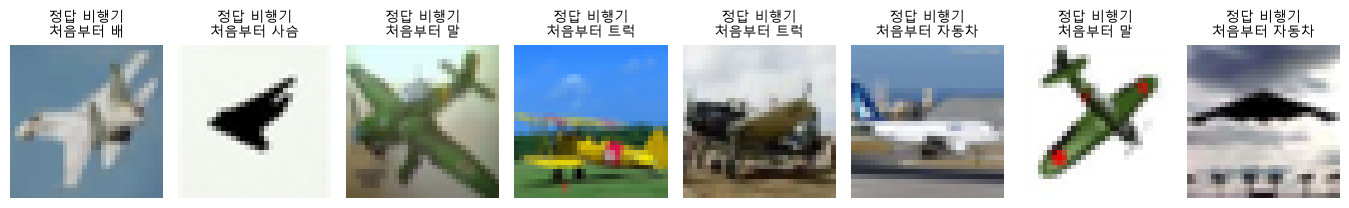

층별 가까운 사진 같은 종류 — pretrained layer1 24.4% · layer2 33.9% · layer3 42.5% · layer4 66.1%
층별 가까운 사진 같은 종류 — 무작위 layer1 18.9% · layer2 21.1% · layer3 23.1% · layer4 23.9%
층별 가까운 사진 같은 종류 — 전부 풀어 학습(1e-4) layer1 26.7% · layer2 30.6% · layer3 46.1% · layer4 80.6%


In [104]:
fig.tight_layout()                                                # 정리
plt.show()                                                        # 그리기
TEST = {k: eval_tl(tl_model(R[k]["best"]), xte, yte) for k in R}  # 검증으로 고른 모델의 테스트
for k in R:                                                       # 네 방식
    # 방식별 결과
    print(f"{k:9s} — 최고 검증 {R[k]['best_acc'] * 100:.1f}% (에폭 {R[k]['best_epoch']})"
          f" · 테스트 {TEST[k][1] * 100:.1f}%")


# ---------- 13-4 ----------
frozen = tl_model(R["frozen"]["best"])  # backbone은 그대로 · fc만 학습한 모델


# 왜 · 입력 약속만 바꿔 같은 모델의 정확도를 비교하기 위해
def val_acc(make):                                 # 같은 모델 · 넣는 값만 다르게
    with torch.no_grad():                          # 계산만
        # 넣는 값만 다르게
        p = torch.cat([frozen(make(xva[i:i + 60])).argmax(1) for i in range(0, len(xva), 60)])
    return (p == yva).float().mean().item() * 100  # 정확도


def up(x):  # 224로 키우기만 (약속의 나머지는 빼고)
    return F.interpolate(x.float(), size=224, mode="bilinear", align_corners=False)  # 32 → 224


a_ok, a_255 = val_acc(norm), val_acc(lambda x: up(x) / 255)    # 약속대로 · 255로만
# 세 결과
print(f"약속대로 {a_ok:.1f}% · 255로만 나눔 {a_255:.1f}% · 0~255 그대로 {val_acc(up):.1f}%")
p_sc, p_pf = TEST["scratch"][2].argmax(1), TEST["full_1e3"][2].argmax(1)  # 두 모델의 테스트 답
only_sc = ((p_sc != yte) & (p_pf == yte)).nonzero().flatten()  # 처음부터만 틀림
only_pf = ((p_pf != yte) & (p_sc == yte)).nonzero().flatten()  # 빌려 온 모델만 틀림
print(f"처음부터만 틀림 {len(only_sc)}장 · 빌려 온 모델만 틀림 {len(only_pf)}장")  # 고친 사진 수
show([xte[i] for i in only_sc[:8]],                            # 빌려 온 모델이 고친 여덟 장
     [f"정답 {KO[CLASSES[yte[i]]]}\n처음부터 {KO[CLASSES[p_sc[i]]]}" for i in only_sc[:8]],
     cols=8, size=1.7)


# ---------- 13-5 ----------
# 왜 · 층마다 특징이 얼마나 쓸모 있는지 같은 기준으로 비교하기 위해
def layer_feats(m, x, bs=60):  # layer1 ~ layer4 출력을 칸마다 평균 → 층마다 사진 요약
    out = {k: [] for k in ("layer1", "layer2", "layer3", "layer4")}       # 층별 결과
    with torch.no_grad():                                                 # 계산만
        for i in range(0, len(x), bs):                                    # 묶음마다
            h = norm(x[i:i + bs])                                         # 약속대로
            for name, layer in m.named_children():                        # 층 차례로
                if name == "avgpool":                                     # 그 앞까지
                    break                                                 # 멈춤
                h = layer(h)                                              # 통과
                if name in out:                                           # stage 출력이면
                    out[name].append(h.mean((2, 3)))                      # 칸마다 평균
    return {k: F.normalize(torch.cat(v), dim=1) for k, v in out.items()}  # 길이 1


r_pre = {k: nearest_rate(v, yva) for k, v in layer_feats(pre, xva).items()}   # pretrained
r_rnd = {k: nearest_rate(v, yva) for k, v in layer_feats(rand, xva).items()}  # 무작위
full4 = tl_model(R["full_1e4"]["best"])  # 전부 풀어 학습(1e-4)한 모델
r_ft = {k: nearest_rate(v, yva) for k, v in layer_feats(full4, xva).items()}  # 학습 뒤
# 세 경우
for name, d in (("pretrained", r_pre), ("무작위", r_rnd), ("전부 풀어 학습(1e-4)", r_ft)):
    txt = " · ".join(f"{k} {v:.1f}%" for k, v in d.items())                   # 층별 비율
    print(f"층별 가까운 사진 같은 종류 — {name} {txt}")                       # 한 줄씩
P0 = pre.state_dict()                                                         # 빌려 온 값

**실행 흐름**

1. 13-6 어디까지 다시 배우게 할까

가중치 변화(학습률 1e-4) — conv1 0.5% · layer1 1.9% · layer2 3.1% · layer3 4.8% · layer4 8.3%


가중치 변화(학습률 1e-3) — conv1 5.1% · layer1 20.1% · layer2 29.8% · layer3 46.6% · layer4 60.6%


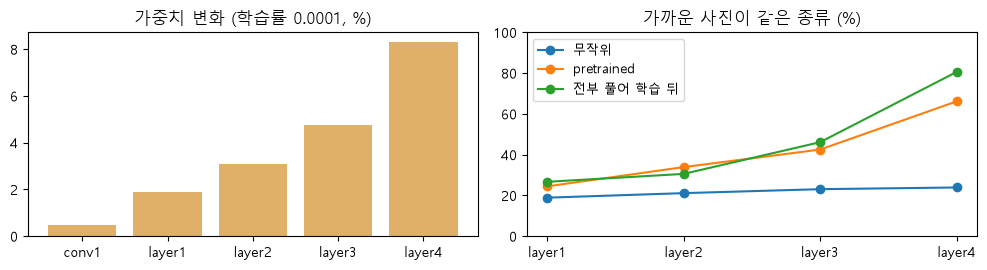

학습할 숫자 — Frozen 5,130 · Partial 8,398,858 · Full 11,181,642
1단계 — 학습할 숫자 5,130개 · 학습률 0.001
2단계 — 학습할 숫자 11,181,642개 · 학습률 backbone 1e-05 · fc 0.0001


In [105]:
# 왜 · 전부 학습한 뒤 어느 층이 가장 많이 바뀌었는지 재기 위해
def change(model, stage):  # 그 stage 합성곱 가중치가 빌려 온 값에서 바뀐 정도(%)
    S_ = model.state_dict()                                                     # 학습 뒤 값
    keys = [k for k in P0 if k.startswith(stage + ".") and P0[k].dim() == 4]    # 합성곱 가중치만
    moved = sum(((S_[k] - P0[k]) ** 2).sum() for k in keys)                     # 바뀐 양
    return (moved / sum((P0[k] ** 2).sum() for k in keys)).sqrt().item() * 100  # 원래 크기 대비


STAGES = ("conv1", "layer1", "layer2", "layer3", "layer4")              # 앞 → 뒤
full3 = tl_model(R["full_1e3"]["best"])                                 # 같은 학습 · 학습률 1e-3
for name, mm in (("1e-4", full4), ("1e-3", full3)):                     # 두 학습률
    txt = " · ".join(f"{s} {change(mm, s):.1f}%" for s in STAGES)       # stage별 변화
    print(f"가중치 변화(학습률 {name}) — " + txt)                       # 뒤 층일수록 큼
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))                         # 변화량 · 층별 비율
ax[0].bar(STAGES, [change(full4, s) for s in STAGES], color="#e0af68")  # 뒤 층일수록
ax[0].set_title("가중치 변화 (학습률 0.0001, %)")                       # 제목
for d, lab in ((r_rnd, "무작위"), (r_pre, "pretrained"), (r_ft, "전부 풀어 학습 뒤")):  # 세 선
    ax[1].plot(list(d), list(d.values()), "o-", label=lab)              # 층별
ax[1].set_ylim(0, 100)                                                  # 0~100
ax[1].set_title("가까운 사진이 같은 종류 (%)")                          # 제목
ax[1].legend(fontsize=9)                                                # 범례
fig.tight_layout()                                                      # 정리
plt.show()                                                              # 그리기


# ---------- 13-6 ----------
# 왜 · 방식마다 실제로 학습하는 숫자의 수를 세어 비용 차이를 보기 위해
def trainable(mode):                                                  # 얼리는 방식별 학습할 숫자
    m = resnet18(weights=None)                                        # 모양만 (숫자는 세기만)
    m.fc = nn.Linear(512, 10)                                         # 10종
    for name, p in m.named_parameters():                              # 이름표마다
        if mode == "frozen":                                          # fc만
            p.requires_grad = name.startswith("fc")                   # 나머지 얼림
        elif mode == "partial":                                       # layer4 + fc
            p.requires_grad = name.startswith(("layer4", "fc"))       # 뒤쪽만
        else:                                                         # full
            p.requires_grad = True                                    # 전부
    return sum(p.numel() for p in m.parameters() if p.requires_grad)  # 학습할 숫자


print(f"학습할 숫자 — Frozen {trainable('frozen'):,}"                         # 세 방식 숫자
      f" · Partial {trainable('partial'):,}"
      f" · Full {trainable('full'):,}")
m = resnet18(weights=W)                                                       # 두 단계로 시작하기
m.fc = nn.Linear(512, 10)                                                     # 새 fc
for p in m.parameters():                                                      # 1단계 — 전부 얼림
    p.requires_grad = False                                                   # 기울기 끔
for p in m.fc.parameters():                                                   # fc만 다시 켬
    p.requires_grad = True                                                    # 학습
opt1 = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3)  # 크게
n1 = sum(p.numel() for p in m.parameters() if p.requires_grad)                # 1단계 숫자
print(f"1단계 — 학습할 숫자 {n1:,}개 · 학습률 {opt1.param_groups[0]['lr']}")  # fc만
for p in m.parameters():                                                      # 2단계 — 전부 풂
    p.requires_grad = True                                                    # 기울기 켬
backbone = [p for n, p in m.named_parameters() if not n.startswith("fc")]     # fc 말고 전부
opt2 = torch.optim.Adam([{"params": backbone, "lr": 1e-5},                    # 작게 다듬기
                         {"params": m.fc.parameters(), "lr": 1e-4}])
print(f"2단계 — 학습할 숫자 {sum(p.numel() for p in m.parameters()):,}개"     # 2단계 설정
      f" · 학습률 backbone {opt2.param_groups[0]['lr']} · fc {opt2.param_groups[1]['lr']}")

**실행 흐름**

1. 14-1 곡선 · checkpoint · 학습률
2. 14-2 고장 1 ~ 3

학습률 0.001 · 3에폭 이후 검증 — 가장 낮음 53.3% · 가장 높음 63.9%
학습률 0.0001 · 3에폭 이후 검증 — 가장 낮음 81.1% · 가장 높음 82.5%


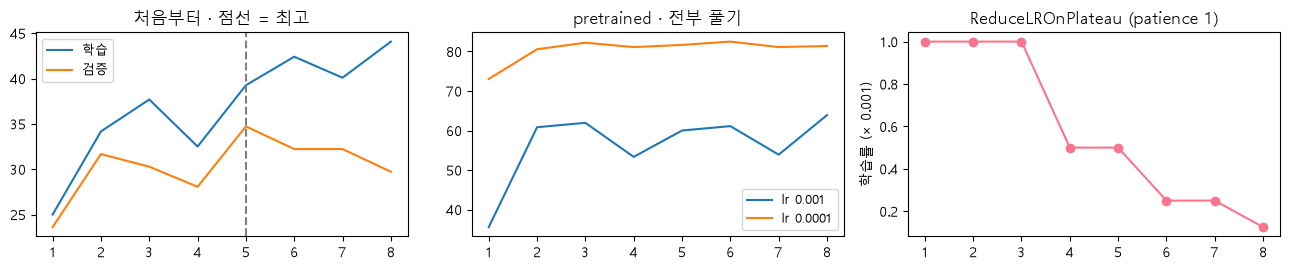

처음부터 — 최고 에폭 5 검증 34.7% · 테스트: 최고 순간 31.9% · 마지막 28.6%
학습률이 줄어든 에폭 [4, 6, 8] · 마지막 학습률 0.000125


고장 1 — == 로 쓰면 점수 1000 개
        제대로 바꾸면 점수 10 개


In [106]:
# 왜 · 평가 때 증강을 켜는 고장을 재현하기 위해
from torchvision.transforms import v2  # 무작위 변환 묶음 (고장 2)


# ---------- 14-1 ----------
# 왜 · 학습 곡선 · checkpoint · 학습률 신호로 고장 여부를 진단하기 위해
sc = R["scratch"]                                                     # 처음부터 배운 모델의 기록
b = sc["best_epoch"]                                                  # 검증 최고 에폭
fig, ax = plt.subplots(1, 3, figsize=(13, 2.8))                       # 곡선 · 학습률 · 줄이는 규칙
ax[0].plot(range(1, 9), [e["train_acc"] * 100 for e in sc["hist"]], label="학습")  # 계속 오름
ax[0].plot(range(1, 9), [e["val_acc"] * 100 for e in sc["hist"]], label="검증")  # 출렁임
ax[0].axvline(b, color="gray", ls="--")                               # 최고 에폭
ax[0].set_title("처음부터 · 점선 = 최고")                             # 제목
ax[0].legend(fontsize=9)                                              # 범례
for k, lab in (("full_1e3", "lr 0.001"), ("full_1e4", "lr 0.0001")):  # 학습률만 다름
    v = [e["val_acc"] * 100 for e in R[k]["hist"]]                    # 검증 곡선
    ax[1].plot(range(1, 9), v, label=lab)                             # 선
    print(f"학습률 {lab[3:]} · 3에폭 이후 검증 — 가장 낮음 {min(v[2:]):.1f}% · "  # 출렁임 범위
          f"가장 높음 {max(v[2:]):.1f}%")
ax[1].set_title("pretrained · 전부 풀기")                             # 제목
ax[1].legend(fontsize=9)                                              # 범례
dummy = torch.zeros(1, requires_grad=True)                            # 학습 없이 규칙만 돌려 봄
opt = torch.optim.SGD([dummy], lr=1e-3)                               # 시작 학습률
# 1번 안 좋아지면 절반
sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=1)
lrs = []                                                              # 에폭별 학습률
for e in R["full_1e3"]["hist"]:                                       # 기록된 검증 손실을 그대로
    sch.step(e["val_loss"])                                           # 규칙 적용
    lrs.append(opt.param_groups[0]["lr"])                             # 기록
ax[2].plot(range(1, 9), [v * 1000 for v in lrs], "o-", color="#f7768e")  # 학습률 (× 0.001)
ax[2].set_ylabel("학습률 (× 0.001)")                                  # 1 → 0.5 → 0.25 …
ax[2].set_title("ReduceLROnPlateau (patience 1)")                     # 제목
fig.tight_layout()                                                    # 정리
plt.show()                                                            # 그리기
last_t = eval_tl(tl_model(sc["last"]), xte, yte)[1] * 100             # 마지막 모델 테스트
print(f"처음부터 — 최고 에폭 {b} 검증 {sc['hist'][b - 1]['val_acc'] * 100:.1f}%"  # best vs last
      f" · 테스트: 최고 순간 {TEST['scratch'][1] * 100:.1f}% · 마지막 {last_t:.1f}%")
drops = [i + 1 for i in range(1, len(lrs)) if lrs[i] < lrs[i - 1]]    # 줄어든 에폭
print(f"학습률이 줄어든 에폭 {drops} · 마지막 학습률 {lrs[-1]:.6f}")  # 규칙 결과


# ---------- 14-2 ----------

torch.manual_seed(0)                                                           # 무작위 변환 고정
m = resnet18(weights=W).to(DEV).eval()                                         # 고장 1
m.fc == nn.Linear(512, 10)  # = 가 아니라 == · 비교만 하고 버림 (오류 없음)
with torch.no_grad():                                                          # 점수 모양 확인
    print("고장 1 — == 로 쓰면 점수", m(norm(xte[:1])).shape[1], "개")         # 여전히 1000
m.fc = nn.Linear(512, 10).to(DEV)                                              # 제대로 바꾸면
with torch.no_grad():                                                          # 다시 확인
    print("        제대로 바꾸면 점수", m(norm(xte[:1])).shape[1], "개")       # 10
aug = v2.Compose([v2.RandomResizedCrop(32, scale=(0.5, 1.0), antialias=True),  # 고장 2
                  v2.RandomHorizontalFlip()])
xx, yy = xte[:96], yte[:96]                                                    # 같은 사진 96장


# 왜 · 같은 사진에 대한 정확도를 여러 번 재서 흔들림을 확인하기 위해
def acc(t):                                                                   # frozen 모델 정확도
    with torch.no_grad():                                                     # 계산만
        return (frozen(norm(t)).argmax(1) == yy).float().mean().item() * 100  # %

**실행 흐름**

1. 14-3 고장 4 ~ 6 앞부분

고장 2 — 증강을 넣고 잼 66.7% · 61.5% · 증강 없이 77.1% · 77.1%


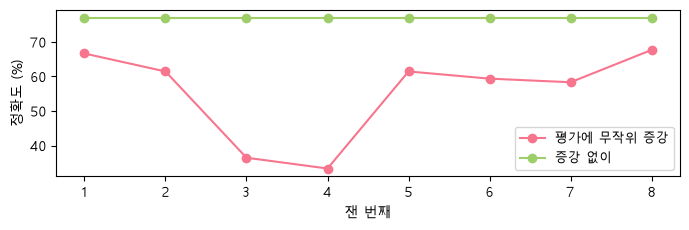

고장 3 — 섞인 순서 1번 틀림 · 답 고양이 · 원본 1번 정답 비행기(잘못) · 순서표 거친 정답 사슴


In [107]:
with_aug = [acc(aug(xx)) for _ in range(8)]  # 평가에 증강을 넣고 여덟 번
without = [acc(xx) for _ in range(8)]                                     # 증강 없이 여덟 번
print(f"고장 2 — 증강을 넣고 잼 {with_aug[0]:.1f}% · {with_aug[1]:.1f}%"  # 흔들림
      f" · 증강 없이 {without[0]:.1f}% · {without[1]:.1f}%")              # 같은 값
fig, ax = plt.subplots(figsize=(7, 2.4))                                  # 여덟 번 잰 값
ax.plot(range(1, 9), with_aug, "o-", color="#f7768e", label="평가에 무작위 증강")  # 흩어짐
ax.plot(range(1, 9), without, "o-", color="#9ece6a", label="증강 없이")   # 한 값
ax.set_xlabel("잰 번째")                                                  # 가로축
ax.set_ylabel("정확도 (%)")                                               # 세로축
ax.legend(fontsize=9)                                                     # 범례
fig.tight_layout()                                                        # 정리
plt.show()                                                                # 그리기
order = torch.randperm(len(xte), generator=torch.Generator().manual_seed(0)).to(DEV)  # 고장 3
xs, ys = xte[order], yte[order]                                           # 섞어서 평가
with torch.no_grad():                                                     # 답
    # 섞인 순서의 답
    p3 = torch.cat([frozen(norm(xs[i:i + 60])).argmax(1) for i in range(0, len(xs), 60)])
j = int((p3 != ys).nonzero()[0])                                          # 섞인 순서에서 틀린 자리
print(f"고장 3 — 섞인 순서 {j}번 틀림 · 답 {KO[CLASSES[p3[j]]]}"          # 잘못 꺼냄 vs 제대로
      f" · 원본 {j}번 정답 {KO[CLASSES[yte[j]]]}(잘못) · 순서표 거친 정답 {KO[CLASSES[ys[j]]]}")


# ---------- 14-3 ----------
scratch = tl_model(R["scratch"]["best"])  # 고장 4 — 처음부터 배운 모델


# 왜 · 종류마다 같은 장수로 학습 · 테스트 사진을 골라 비교하기 위해
def pick(y, k=20):  # 종류마다 k장씩 — 두 묶음의 종류 구성을 같게
    return torch.cat([(y == c).nonzero().flatten()[:k] for c in range(10)])  # 번호


# 왜 · 고장 사례마다 같은 방법으로 정확도를 재기 위해
def acc_of(x, y, idx):                                # 그 묶음에서 정확도
    with torch.no_grad():                             # 계산만
        # 60장씩 답
        p = torch.cat([scratch(norm(x[idx][i:i + 60])).argmax(1) for i in range(0, len(idx), 60)])
    return (p == y[idx]).float().mean().item() * 100  # %

**실행 흐름**

1. 고장 4 ~ 6 정확도 비교 출력

In [108]:
# 왜 · 학습에 쓴 사진으로 평가하면 점수가 부풀려지는 고장을 처음 보는 사진과 비교해 드러내기 위해
a_tr, a_te = acc_of(xtr, ytr, pick(ytr)), acc_of(xte, yte, pick(yte))   # 학습 사진 · 처음 보는 사진
print(f"고장 4 — 같은 모델 · 학습에 쓴 사진 200장 {a_tr:.1f}% · "       # 외운 정도
      f"처음 보는 사진 200장 {a_te:.1f}%")
m = resnet18(weights=W)                                                 # 고장 5
m.fc = nn.Linear(512, 10)                                               # 새 fc
m = m.to(DEV).train()                                                   # 학습 모드
opt = torch.optim.Adam(m.fc.parameters(), lr=1e-3)  # fc만 넘김 · requires_grad는 전부 켜짐
c0, f0 = m.conv1.weight.detach().clone(), m.fc.weight.detach().clone()  # 걸음 전 값
loss = F.cross_entropy(m(norm(xtr[:16])), ytr[:16])                     # 손실
opt.zero_grad()                                                         # 지우기
loss.backward()  # 기울기 (backbone까지 전부 계산됨)
opt.step()                                                              # 한 걸음 (fc만 고침)
print(f"고장 5 — conv1 변화 {(m.conv1.weight - c0).abs().max().item():.4f}"  # conv1 그대로 · fc만
      f" · fc 변화 {(m.fc.weight - f0).abs().max().item():.4f}")
n_grad = sum(p.numel() for p in m.parameters() if p.grad is not None)   # 기울기가 계산된 숫자
print(f"        기울기 계산 {n_grad:,}개 · "                            # 계산 낭비
      f"그중 optimizer가 고친 것 fc {n_params(m.fc):,}개")
m2 = resnet18(weights=W).to(DEV)                                        # 고장 6
for p in m2.parameters():                                               # 전부 얼림
    p.requires_grad = False                                             # 기울기 끔
rm0 = m2.bn1.running_mean.clone()                                       # 모아 둔 평균
m2.train()                                                              # 학습 모드로
with torch.no_grad():                                                   # 학습 없이 한 묶음 통과
    m2(norm(xtr[:16]))  # BN이 묶음 평균으로 모아 둔 평균을 고침
moved = (m2.bn1.running_mean - rm0).abs().max().item()                  # 가장 크게 바뀐 값
print(f"고장 6 — 얼렸는데도 BN running_mean 변화 {moved:.4f}")          # 얼려도 평균이 바뀜

고장 4 — 같은 모델 · 학습에 쓴 사진 200장 41.5% · 처음 보는 사진 200장 33.0%


고장 5 — conv1 변화 0.0000 · fc 변화 0.0010
        기울기 계산 11,181,642개 · 그중 optimizer가 고친 것 fc 5,130개


고장 6 — 얼렸는데도 BN running_mean 변화 0.1379


**실행 흐름**

1. 15-1 틀린 사진 모아 보기
2. 15-2 Grad-CAM

모아 볼 테스트 사진 360장
scratch   — 틀림 245장 · 0.9 이상 확신하고 틀림 1장
frozen    — 틀림 74장 · 0.9 이상 확신하고 틀림 1장
full_1e3  — 틀림 156장 · 0.9 이상 확신하고 틀림 50장
full_1e4  — 틀림 75장 · 0.9 이상 확신하고 틀림 6장


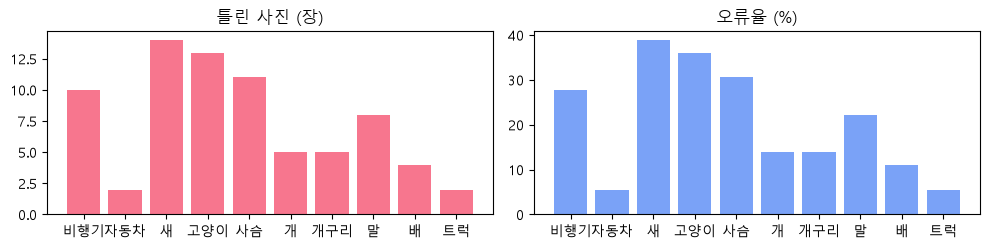

frozen 오류율이 가장 높은 종류 새 — 36장 중 14장 (38.9%)
헷갈린 짝 상위 셋 — 고양이 → 개 9장 · 새 → 개구리 6장 · 사슴 → 고양이 6장


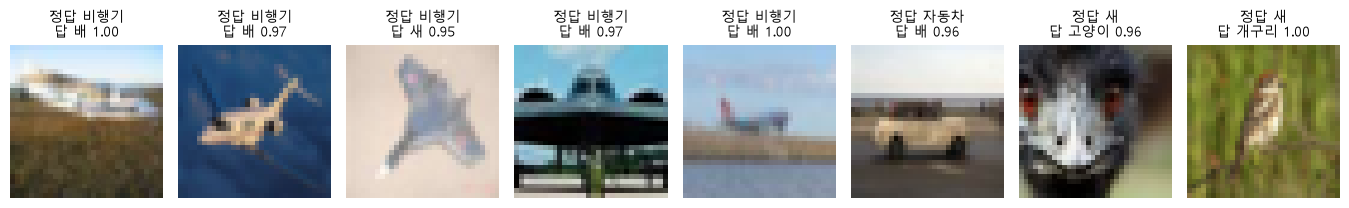

In [109]:
from collections import Counter  # 짝 세기


# ---------- 15-1 ----------

# 왜 · 높은 점수 뒤에 남은 오류를 종류 · 짝 · 확신별로 모아 보기 위해
print(f"모아 볼 테스트 사진 {len(yte)}장")                               # 같은 360장
for k in R:                                                              # 네 방식
    cf, pr = TEST[k][2].max(1)                                           # 확신 · 답
    w = pr != yte                                                        # 틀린 사진
    print(f"{k:9s} — 틀림 {int(w.sum())}장 · "                           # 틀림 · 과신
          f"0.9 이상 확신하고 틀림 {int((w & (cf >= 0.9)).sum())}장")
fz = TEST["frozen"][2].argmax(1)                                         # frozen 모델의 답
rows = []  # 종류별 (이름, 장수, 틀림, 오류율)
for c in range(10):                                                      # 종류마다
    n, w = int((yte == c).sum()), int(((yte == c) & (fz != yte)).sum())  # 장수 · 틀림
    rows.append((KO[CLASSES[c]], n, w, w / n * 100))                     # 한 줄
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6))                          # 개수 · 비율
ax[0].bar([r[0] for r in rows], [r[2] for r in rows], color="#f7768e")   # 틀린 개수
ax[0].set_title("틀린 사진 (장)")                                        # 제목
ax[1].bar([r[0] for r in rows], [r[3] for r in rows], color="#7aa2f7")   # 오류율
ax[1].set_title("오류율 (%)")                                            # 제목
fig.tight_layout()                                                       # 정리
plt.show()                                                               # 그리기
top_r = max(rows, key=lambda r: r[3])                                    # 오류율 최고
# 가장 약한 종류
print(f"frozen 오류율이 가장 높은 종류 {top_r[0]} — {top_r[1]}장 중 {top_r[2]}장 ({top_r[3]:.1f}%)")
pairs = Counter((int(yte[i]), int(fz[i])) for i in (fz != yte).nonzero().flatten().tolist())  # 짝
# 상위 셋
pair_txt = [f"{KO[CLASSES[t]]} → {KO[CLASSES[q]]} {n}장" for (t, q), n in pairs.most_common(3)]
print("헷갈린 짝 상위 셋 — " + " · ".join(pair_txt))                     # 많은 짝  # 많은 짝
cf, pr = TEST["full_1e3"][2].max(1)  # 확신하며 틀린 사진 (전부 풀기 1e-3)
wr = ((pr != yte) & (cf >= 0.9)).nonzero().flatten()[:8]                 # 0.9 이상 틀림 앞 여덟 장
show([xte[i] for i in wr],                                               # 정답 / 답 확률
     [f"정답 {KO[CLASSES[yte[i]]]}\n답 {KO[CLASSES[pr[i]]]} {cf[i]:.2f}" for i in wr],
     cols=8, size=1.7)


# ---------- 15-2 ----------
# 왜 · Grad-CAM에 필요한 특징 · 기울기를 hook으로 받아 두기 위해
feats, grads = {}, {}  # layer4 특징 지도 · 기울기 저장소
frozen.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))  # 앞으로 갈 때 저장
frozen.layer4.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))  # 뒤로


# 왜 · 빌려 온 모델이 답을 낼 때 기댄 자리를 지도로 만들기 위해
def gradcam(x, cls=None):                                # 사진 한 장 → (답, 224 × 224 지도 0~1)
    for p in frozen.parameters():                        # 기울기가 layer4까지 오도록
        p.requires_grad = True                           # 켬
    out = frozen(norm(x[None]))                          # 점수
    c = int(out.argmax()) if cls is None else cls        # 기준 종류 (기본 = 모델의 답)
    frozen.zero_grad()                                   # 지우기
    out[0, c].backward()                                 # 그 종류 점수의 기울기
    w = grads["g"].mean((2, 3), keepdim=True)            # 지도 512장마다 중요도
    cam = F.relu((w * feats["a"]).sum(1, keepdim=True))  # 가중합 · 음수는 0
    cam = F.interpolate(cam, size=224, mode="bilinear", align_corners=False)[0, 0]  # 7 → 224
    return c, (cam / (cam.max() + 1e-8)).detach().cpu()  # 0~1

**실행 흐름**

1. 15-3 지도를 사진에 겹치기 · 두 대상이 한 사진에

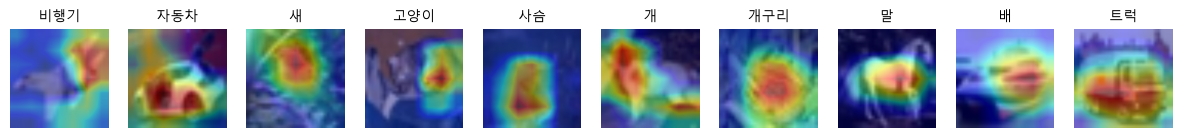

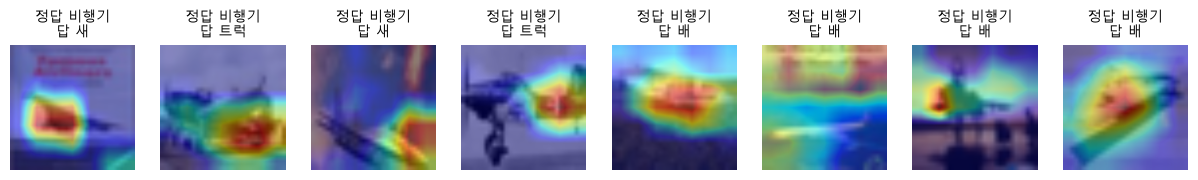

맞힌 사진 10장 · 틀린 사진 8장 · 지도는 7×7을 224로 키운 것


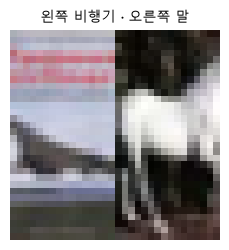

가장 큰 두 확률 — 고양이 0.34 · 말 0.22
모델의 답은 하나 — 고양이
  가로  0~32 → 새 0.37
  가로 16~48 → 고양이 0.39
  가로 32~64 → 말 0.71
창문 3개 → 촘촘히(4칸씩) · 크기 두 가지면 20개 · 계산은 약 7배 · 사진 1,000장이면 20,000번 분류


In [110]:
# 왜 · 지도를 사진 위에 겹쳐 사람이 읽기 쉽게 보여 주기 위해
def overlay(ax, x, cam, title):                        # 사진 위에 지도를 겹침
    img = F.interpolate(x[None].float(), size=224, mode="bilinear")[0] / 255  # 224로 키운 사진
    ax.imshow(img.permute(1, 2, 0).cpu().clamp(0, 1))  # 바탕
    ax.imshow(cam, cmap="jet", alpha=0.45)             # 겹침
    ax.set_title(title, fontsize=10)                   # 제목
    ax.axis("off")                                     # 눈금 끄기


picks = [int(((yte == k) & (fz == yte)).nonzero()[0]) for k in range(10)]  # 종류마다 처음 맞힌 사진
fig, ax = plt.subplots(1, 10, figsize=(15, 1.9))                     # 한 줄
for a, i in zip(ax, picks):                                          # 사진마다
    overlay(a, xte[i], gradcam(xte[i])[1], KO[CLASSES[yte[i]]])      # 맞힌 사진
plt.show()                                                           # 그리기
wrong_cam = (fz != yte).nonzero().flatten()[:8].tolist()             # 틀린 사진 앞 여덟 장
fig, ax = plt.subplots(1, len(wrong_cam), figsize=(1.9 * len(wrong_cam), 2.2))  # 한 줄
for a, i in zip(np.atleast_1d(ax), wrong_cam):                       # 사진마다
    c, cam = gradcam(xte[i])                                         # 모델이 고른(틀린) 답 기준
    overlay(a, xte[i], cam, f"정답 {KO[CLASSES[yte[i]]]}\n답 {KO[CLASSES[c]]}")  # 겹침
plt.show()                                                           # 그리기
print(f"맞힌 사진 {len(picks)}장 · 틀린 사진 {len(wrong_cam)}장 · "  # 그린 장수
      f"지도는 7×7을 224로 키운 것")


# ---------- 15-3 ----------
# 왜 · 한 사진에 두 대상이 있을 때 분류 모델의 한계를 확인하기 위해
a_i = int((yte == CLASSES.index("airplane")).nonzero()[0])               # 비행기 한 장
b_i = int((yte == CLASSES.index("horse")).nonzero()[0])                  # 말 한 장
two = torch.cat([xte[a_i][:, :, 8:24], xte[b_i][:, :, 8:24]], dim=2)     # 가운데 반씩 이어 붙임
with torch.no_grad():                                                    # 답
    prob = frozen(norm(two[None])).softmax(1)[0]                         # 열 가지 확률
t2 = prob.topk(2)                                                        # 가장 큰 두 확률
show([two], ["왼쪽 비행기 · 오른쪽 말"], cols=1, size=2.4)               # 한 사진에 두 대상
two_p = " · ".join(f"{KO[CLASSES[int(k)]]} {float(v):.2f}"               # 이름 확률 두 개
                   for v, k in zip(t2.values, t2.indices))
print("가장 큰 두 확률 — " + two_p)                                      # 두 종류로 나뉨
print("모델의 답은 하나 —", KO[CLASSES[int(t2.indices[0])]])             # '둘 다' 칸이 없음
wide = torch.cat([xte[a_i], xte[b_i]], dim=2)  # 가로로 이어 붙임 (3, 32, 64)
res = []                                                                 # 창문마다 (시작, 답, 확률)
with torch.no_grad():                                                    # 32칸 창문을 16칸씩 옮김
    for x0 in range(0, 33, 16):                                          # 시작 0 · 16 · 32
        pr_ = frozen(norm(wide[:, :, x0:x0 + 32][None])).softmax(1)[0]   # 그 창문만 분류
        res.append((x0, KO[CLASSES[int(pr_.argmax())]], float(pr_.max())))  # 기록
for x0, name, p in res:                                                  # 창문마다
    print(f"  가로 {x0:2d}~{x0 + 32:2d} → {name} {p:.2f}")               # 어디에 무엇이 있는지 대략
wins = [(x0, sz) for sz in (32, 24) for x0 in range(0, 64 - sz + 1, 4)]  # 촘촘히 · 크기 두 가지
print(f"창문 {len(res)}개 → 촘촘히(4칸씩) · 크기 두 가지면 {len(wins)}개"  # 비용이 창문 수만큼
      f" · 계산은 약 {len(wins) / len(res):.0f}배 · 사진 1,000장이면 {len(wins) * 1000:,}번 분류")

**실행 흐름**

1. 실습 1 ~ 4 다시 실행

밝기 ×1.0  → 답이 바뀐 비율   0.0%
밝기 ×0.9  → 답이 바뀐 비율   1.4%
밝기 ×0.7  → 답이 바뀐 비율   6.2%
밝기 ×0.55 → 답이 바뀐 비율  14.0%
밝기 ×0.4  → 답이 바뀐 비율  36.6%
밝기 ×0.25 → 답이 바뀐 비율  78.8%


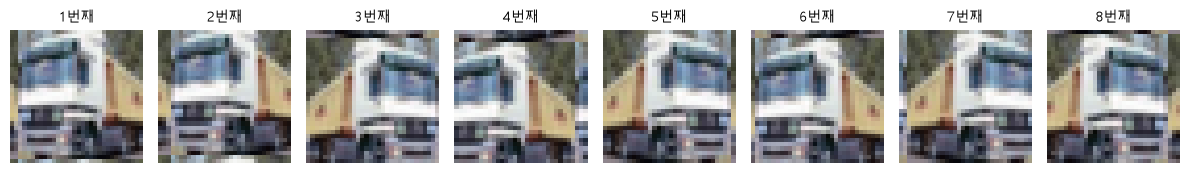

서로 다른 그림 8가지 / 8번


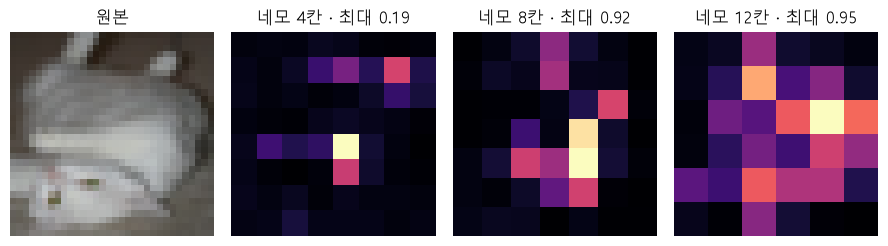

고양이 — 분모 335장 (전체 4218장)
  좌우 반전   16.7% (전체   6.7%)
  조금 옮기기  15.2% (전체  19.6%)
  어둡게      6.9% (전체  14.1%)
  밝게      17.6% (전체   6.9%)
  잘라 키우기   8.7% (전체  55.4%)
  조금 돌리기  53.7% (전체  47.5%)
① 바꾼 것 · 그대로 둔 것 — 종류 하나만 골라 봄 · 모델 · 사진 · 변화는 그대로
② 예상 · 실제 — 위 숫자와 전체를 견줘 적음
③ 아직 모르는 것 · 다음 비교 — 분모가 작아 몇 장 차이로도 크게 움직임 → 시작값을 바꿔 다시


In [111]:
# ---------- 16. 종합 실습 ----------
# 실습 1 — 변화 하나의 세기를 바꿔 보기 (◆ 두 줄을 같은 변화에 맞게 함께 바꿈)
# 왜 · 변화의 세기에 따라 답이 바뀌는 비율이 어떻게 달라지는지 직접 확인하기 위해
def change(x, s):                         # ◆ 밝기: 값을 s배
    return (x.float() * s).clamp(0, 255)  # 0~255 안으로


strengths = [1.0, 0.9, 0.7, 0.55, 0.4, 0.25]           # ◆ 세기 목록 (1.0 = 원본)
sub2 = correct[:2000]                                  # 원본에서 맞힌 검증 사진 앞 2000장
# 세기별 바뀐 비율
rates_s = [(predict(model, change(x_val[sub2], s)).argmax(1) != pred[sub2]).float().mean().item()
           * 100 for s in strengths]
for s, r in zip(strengths, rates_s):                   # 세기마다
    print(f"밝기 ×{s:<4} → 답이 바뀐 비율 {r:5.1f}%")  # 어디서 가파른가


# 실습 2 — 내가 쓸 증강을 직접 만들어 보기 (같은 사진에 여덟 번)
# 왜 · 직접 만든 증강이 정답 단서를 남기는지 같은 사진으로 확인하기 위해
def my_augment(x):                                        # 좌우 반전(반반) + 조금 옮기기(±3칸)
    n = len(x)                                            # 장수
    out = x.float().clone()                               # 복사
    flip = (torch.rand(n) < 0.5).to(x.device)             # 반반
    out[flip] = out[flip].flip(-1)                        # 좌우 반전
    dx, dy = torch.randint(-3, 4, (2,)).tolist()          # 옮길 칸 (묶음 공통)
    return torch.roll(out, shifts=(dy, dx), dims=(2, 3))  # 옮기기


torch.manual_seed(5)                                                      # 보여 주기용
one_img = x_train[int((y_train == CLASSES.index("truck")).nonzero()[0])]  # 트럭 한 장
eight = [my_augment(one_img[None])[0] for _ in range(8)]                  # 넣을 때마다 다름
show(eight, [f"{k + 1}번째" for k in range(8)], cols=8, size=1.5)         # 단서가 남는가
print(f"서로 다른 그림 {len({e.cpu().numpy().tobytes() for e in eight})}가지 / 8번")  # 무작위인가


# 실습 3 — 가려서 확인하기: 가리는 네모 크기를 바꿔도 밝은 곳이 같은가
# 왜 · 가리는 크기를 바꿔도 같은 자리가 중요하게 나오는지 확인하기 위해
i_cat = picks_o[3]                                                            # 9장의 고양이 사진
fig, ax = plt.subplots(1, 4, figsize=(9, 2.4))                                # 원본 + 크기 셋
# 원본 사진
ax[0].imshow((x_val[i_cat].float() / 255).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
ax[0].set_title("원본")                                                       # 제목
for a, patch in zip(ax[1:], (4, 8, 12)):                                      # ◆ 네모 크기
    heat = occlusion(x_val[i_cat], int(y_val[i_cat]), patch=patch, stride=4)  # 지도
    a.imshow(heat.cpu().numpy(), cmap="magma")                                # 밝을수록 가리면 손해
    a.set_title(f"네모 {patch}칸 · 최대 {heat.max():.2f}")                    # 제목
for a in ax:                                                                  # 공통
    a.axis("off")                                                             # 눈금 끄기
fig.tight_layout()                                                            # 정리
plt.show()                                                                    # 그리기


# 실습 4 — 한 종류만 골라 흔들고, 세 줄로 적기
# 왜 · 한 종류만 골라 결과를 기록하는 실험 습관을 연습하기 위해
kind = "cat"                                                                  # ◆ 종류 하나
k_id = CLASSES.index(kind)                                                    # 번호
mask = y_val[correct] == k_id  # 그 종류에서 원본을 맞힌 사진
print(f"{KO[kind]} — 분모 {int(mask.sum())}장 (전체 {len(correct)}장)")       # 분모가 작음
for k in KINDS:                                                               # 여섯 변화
    print(f"  {KIND_KO[k]:6s} {changed[k][mask].float().mean() * 100:5.1f}%"  # 그 종류 · 전체
          f" (전체 {changed[k].float().mean() * 100:5.1f}%)")
print("① 바꾼 것 · 그대로 둔 것 — 종류 하나만 골라 봄 · 모델 · 사진 · 변화는 그대로")  # 세 줄 기록
print("② 예상 · 실제 — 위 숫자와 전체를 견줘 적음")                           # 예상과 실제
# 한계
print("③ 아직 모르는 것 · 다음 비교 — 분모가 작아 몇 장 차이로도 크게 움직임 → 시작값을 바꿔 다시")